In [1]:

from pathlib import Path
from datetime import datetime
import pandas as pd
import georinex as gr
import numpy as np

# ============================================================
# AUDIT DATA GNSS BAKO - HALLOWEEN STORM 2003
# Periode target: DOY 300-307 (27 Oktober-3 November 2003)
# Sumber data: CDDIS
# ============================================================

ROOT = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily"
) / "HALLOWEEN STORM 2003"

DOY_INFO = {
    300: "2003-10-27",
    301: "2003-10-28",
    302: "2003-10-29",
    303: "2003-10-30",
    304: "2003-10-31",
    305: "2003-11-01",
    306: "2003-11-02",
    307: "2003-11-03",
}

OUTPUT = ROOT / "hasil_audit_bako"
OUTPUT.mkdir(exist_ok=True)

print("=" * 70)
print("AUDIT AWAL DATA GNSS BAKO")
print("Periode: 27 Oktober - 3 November 2003")
print("=" * 70)

# ------------------------------------------------------------
# 1. INVENTARISASI FILE RINEX BAKO
# ------------------------------------------------------------

inventaris = []

for doy, tanggal_target in DOY_INFO.items():
    nama_file = f"bako{doy}0.03o"

    kandidat = list(ROOT.rglob(nama_file))

    if kandidat:
        for file_rinex in kandidat:
            inventaris.append({
                "DOY_target": doy,
                "tanggal_target": tanggal_target,
                "nama_file": file_rinex.name,
                "ukuran_MB": round(
                    file_rinex.stat().st_size / (1024 ** 2), 3
                ),
                "lokasi_file": str(file_rinex.relative_to(ROOT)),
                "status": "Ditemukan",
            })
    else:
        inventaris.append({
            "DOY_target": doy,
            "tanggal_target": tanggal_target,
            "nama_file": nama_file,
            "ukuran_MB": np.nan,
            "lokasi_file": "",
            "status": "Tidak ditemukan",
        })

df_inventaris = pd.DataFrame(inventaris)

print("\n[1] INVENTARISASI FILE")
print(df_inventaris.to_string(index=False))

# Simpan hasil inventarisasi
df_inventaris.to_csv(
    OUTPUT / "01_inventaris_bako.csv",
    index=False
)

print("\nHasil inventarisasi disimpan di:")
print(OUTPUT / "01_inventaris_bako.csv")


AUDIT AWAL DATA GNSS BAKO
Periode: 27 Oktober - 3 November 2003

[1] INVENTARISASI FILE
 DOY_target tanggal_target    nama_file  ukuran_MB                           lokasi_file    status
        300     2003-10-27 bako3000.03o      2.006 DOY 300_27 OCT 2003\BAKO\bako3000.03o Ditemukan
        301     2003-10-28 bako3010.03o      2.007      DOY 301_28 OCT 2003\bako3010.03o Ditemukan
        302     2003-10-29 bako3020.03o      2.008      DOY 302_29 OCT 2003\bako3020.03o Ditemukan
        303     2003-10-30 bako3030.03o      2.007      DOY 303_30 OCT 2003\bako3030.03o Ditemukan
        304     2003-10-31 bako3040.03o      1.999      DOY 304_31 OCT 2003\bako3040.03o Ditemukan
        305     2003-11-01 bako3050.03o      2.008      DOY 305_01 NOV 2003\bako3050.03o Ditemukan
        306     2003-11-02 bako3060.03o      2.007      DOY 306_02 NOV 2003\bako3060.03o Ditemukan
        307     2003-11-03 bako3070.03o      2.008      DOY 307_03 NOV 2003\bako3070.03o Ditemukan

Hasil inventarisasi 

In [2]:

# ------------------------------------------------------------
# 2. PEMERIKSAAN METADATA DAN WAKTU OBSERVASI
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("[2] PEMERIKSAAN METADATA RINEX")
print("=" * 70)

metadata = []

for doy, tanggal_target in DOY_INFO.items():
    nama_file = f"bako{doy}0.03o"
    kandidat = list(ROOT.rglob(nama_file))

    if not kandidat:
        metadata.append({
            "DOY_target": doy,
            "tanggal_target": tanggal_target,
            "tanggal_observasi": None,
            "waktu_awal_UTC": None,
            "waktu_akhir_UTC": None,
            "status_tanggal": "FILE TIDAK DITEMUKAN",
        })
        continue

    file_rinex = kandidat[0]

    try:
        # Baca header dan data observasi dengan GeoRinex
        ds = gr.load(str(file_rinex), use="G")

        waktu = pd.DatetimeIndex(
            pd.to_datetime(ds.time.values)
        )

        waktu_awal = waktu.min()
        waktu_akhir = waktu.max()
        tanggal_observasi = waktu_awal.strftime("%Y-%m-%d")

        status_tanggal = (
            "SESUAI"
            if tanggal_observasi == tanggal_target
            else "PERLU DIVERIFIKASI"
        )

        metadata.append({
            "DOY_target": doy,
            "tanggal_target": tanggal_target,
            "tanggal_observasi": tanggal_observasi,
            "waktu_awal_UTC": waktu_awal.strftime("%H:%M:%S"),
            "waktu_akhir_UTC": waktu_akhir.strftime("%H:%M:%S"),
            "status_tanggal": status_tanggal,
        })

        print(f"\nDOY {doy} | {file_rinex.name}")
        print("Tanggal target     :", tanggal_target)
        print("Tanggal observasi  :", tanggal_observasi)
        print("Waktu awal UTC     :", waktu_awal)
        print("Waktu akhir UTC    :", waktu_akhir)
        print("Jumlah epoch       :", len(waktu))
        print("Jumlah satelit     :", len(ds.sv))
        print("Status tanggal     :", status_tanggal)

    except Exception as e:
        metadata.append({
            "DOY_target": doy,
            "tanggal_target": tanggal_target,
            "tanggal_observasi": None,
            "waktu_awal_UTC": None,
            "waktu_akhir_UTC": None,
            "status_tanggal": f"GAGAL DIBACA: {type(e).__name__}",
        })

        print(f"\nDOY {doy}: gagal membaca {file_rinex.name}")
        print(type(e).__name__, str(e))

df_metadata = pd.DataFrame(metadata)

df_metadata.to_csv(
    OUTPUT / "02_metadata_bako.csv",
    index=False
)

print("\nRingkasan metadata:")
print(df_metadata.to_string(index=False))

print("\nHasil metadata disimpan di:")
print(OUTPUT / "02_metadata_bako.csv")



[2] PEMERIKSAAN METADATA RINEX


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))



DOY 300 | bako3000.03o
Tanggal target     : 2003-10-27
Tanggal observasi  : 2003-10-27
Waktu awal UTC     : 2003-10-27 00:00:30
Waktu akhir UTC    : 2003-10-27 23:59:00.128000
Jumlah epoch       : 2878
Jumlah satelit     : 28
Status tanggal     : SESUAI


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))



DOY 301 | bako3010.03o
Tanggal target     : 2003-10-28
Tanggal observasi  : 2003-10-28
Waktu awal UTC     : 2003-10-28 00:00:30
Waktu akhir UTC    : 2003-10-28 23:59:00.127000
Jumlah epoch       : 2878
Jumlah satelit     : 28
Status tanggal     : SESUAI


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


... (6 outputs left out)


DOY 305 | bako3050.03o
Tanggal target     : 2003-11-01
Tanggal observasi  : 2003-11-08
Waktu awal UTC     : 2003-11-08 00:00:30
Waktu akhir UTC    : 2003-11-08 23:59:00.127000
Jumlah epoch       : 2878
Jumlah satelit     : 28
Status tanggal     : PERLU DIVERIFIKASI


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))



DOY 306 | bako3060.03o
Tanggal target     : 2003-11-02
Tanggal observasi  : 2003-11-02
Waktu awal UTC     : 2003-11-02 00:00:30
Waktu akhir UTC    : 2003-11-02 23:59:00.129000
Jumlah epoch       : 2878
Jumlah satelit     : 28
Status tanggal     : SESUAI

DOY 307 | bako3070.03o
Tanggal target     : 2003-11-03
Tanggal observasi  : 2003-11-03
Waktu awal UTC     : 2003-11-03 00:00:30
Waktu akhir UTC    : 2003-11-03 23:59:00.128000
Jumlah epoch       : 2878
Jumlah satelit     : 28
Status tanggal     : SESUAI

Ringkasan metadata:
 DOY_target tanggal_target tanggal_observasi waktu_awal_UTC waktu_akhir_UTC     status_tanggal
        300     2003-10-27        2003-10-27       00:00:30        23:59:00             SESUAI
        301     2003-10-28        2003-10-28       00:00:30        23:59:00             SESUAI
        302     2003-10-29        2003-10-29       00:00:30        23:59:00             SESUAI
        303     2003-10-30        2003-10-30       00:00:30        23:59:00             S

c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [3]:

"""
AUDIT DATA GNSS BAKO - HALLOWEEN STORM 2003

Periode target : 27 Oktober - 3 November 2003 (DOY 300-307)
Sumber data    : CDDIS
Format         : RINEX 2 observation (.03o)
Tujuan         : Audit awal metadata, kontinuitas, dan kualitas observasi.

Catatan:
- File sumber tidak diubah.
- File yang tanggal observasinya tidak sesuai tetap ditandai untuk verifikasi.
- Kandidat lonjakan fase adalah indikasi awal QC, bukan otomatis kesalahan data.
"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import georinex as gr


# ============================================================
# 1. KONFIGURASI
# ============================================================

ROOT = (
    Path(r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily")
    / "HALLOWEEN STORM 2003"
)

OUTPUT = ROOT / "hasil_audit_bako"
OUTPUT.mkdir(parents=True, exist_ok=True)

DOY_INFO = {
    300: "2003-10-27",
    301: "2003-10-28",
    302: "2003-10-29",
    303: "2003-10-30",
    304: "2003-10-31",
    305: "2003-11-01",
    306: "2003-11-02",
    307: "2003-11-03",
}

INTERVAL_NOMINAL = 30.0
BATAS_GAP = 30.5

print("=" * 72)
print("AUDIT DATA GNSS BAKO - HALLOWEEN STORM 2003")
print("=" * 72)
print(f"Folder data : {ROOT}")
print(f"Folder hasil: {OUTPUT}")


# ============================================================
# 2. FUNGSI BANTU
# ============================================================

def cari_file_bako(doy):
    """Cari file RINEX BAKO untuk DOY target secara rekursif."""
    nama_file = f"bako{doy}0.03o"
    kandidat = sorted(ROOT.rglob(nama_file))

    if not kandidat:
        return None

    if len(kandidat) > 1:
        print(
            f"PERINGATAN: ditemukan {len(kandidat)} salinan "
            f"untuk {nama_file}. Menggunakan: {kandidat[0]}"
        )

    return kandidat[0]


def baca_rinex(file_rinex):
    """Baca observasi GPS dari file RINEX."""
    # FutureWarning tertentu berasal dari proses merge GeoRinex/xarray.
    # Peringatan disaring hanya selama pembacaan file.
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            category=FutureWarning,
            module=r"georinex\.obs2",
        )
        ds = gr.load(str(file_rinex), use="G")

    return ds


def hitung_persen(valid, total):
    """Hitung persentase data valid."""
    if total == 0:
        return np.nan
    return 100.0 * valid / total


# ============================================================
# 3. INVENTARISASI FILE
# ============================================================

inventaris = []
file_tersedia = {}

for doy, tanggal_target in DOY_INFO.items():
    file_rinex = cari_file_bako(doy)

    if file_rinex is None:
        inventaris.append({
            "DOY_target": doy,
            "tanggal_target": tanggal_target,
            "nama_file": f"bako{doy}0.03o",
            "ukuran_MB": np.nan,
            "lokasi_file": "",
            "status": "TIDAK DITEMUKAN",
        })
        continue

    file_tersedia[doy] = file_rinex

    inventaris.append({
        "DOY_target": doy,
        "tanggal_target": tanggal_target,
        "nama_file": file_rinex.name,
        "ukuran_MB": round(
            file_rinex.stat().st_size / (1024 ** 2), 3
        ),
        "lokasi_file": str(file_rinex.relative_to(ROOT)),
        "status": "DITEMUKAN",
    })

df_inventaris = pd.DataFrame(inventaris)
df_inventaris.to_csv(
    OUTPUT / "01_inventaris_bako.csv",
    index=False,
)

print("\n[1] INVENTARISASI FILE")
print(df_inventaris.to_string(index=False))


# ============================================================
# 4. METADATA, INTERVAL, DAN KONTINUITAS
# ============================================================

metadata = []
kontinuitas = []
cache_data = {}

for doy, tanggal_target in DOY_INFO.items():
    file_rinex = file_tersedia.get(doy)

    if file_rinex is None:
        continue

    print(f"\nMemproses DOY {doy}: {file_rinex.name}")

    try:
        ds = baca_rinex(file_rinex)
        cache_data[doy] = ds

        waktu = pd.DatetimeIndex(
            pd.to_datetime(ds.time.values)
        ).sort_values().unique()

        if len(waktu) == 0:
            raise ValueError("Tidak ada epoch observasi.")

        waktu_awal = waktu[0]
        waktu_akhir = waktu[-1]
        tanggal_observasi = waktu_awal.strftime("%Y-%m-%d")

        status_tanggal = (
            "SESUAI"
            if tanggal_observasi == tanggal_target
            else "PERLU DIVERIFIKASI"
        )

        metadata.append({
            "DOY_target": doy,
            "tanggal_target": tanggal_target,
            "tanggal_observasi": tanggal_observasi,
            "waktu_awal": waktu_awal.strftime("%Y-%m-%d %H:%M:%S"),
            "waktu_akhir": waktu_akhir.strftime("%Y-%m-%d %H:%M:%S"),
            "jumlah_epoch": len(waktu),
            "jumlah_satelit": len(ds.sv),
            "variabel_observasi": ", ".join(map(str, ds.data_vars)),
            "status_tanggal": status_tanggal,
        })

        if len(waktu) >= 2:
            selisih = (
                pd.Series(waktu)
                .diff()
                .dt.total_seconds()
                .dropna()
            )

            durasi_jam = (
                waktu_akhir - waktu_awal
            ).total_seconds() / 3600

            jumlah_gap = int((selisih > BATAS_GAP).sum())

            kontinuitas.append({
                "DOY_target": doy,
                "tanggal_observasi": tanggal_observasi,
                "jumlah_epoch": len(waktu),
                "durasi_jam": round(durasi_jam, 4),
                "interval_median_detik": round(
                    float(selisih.median()), 4
                ),
                "interval_min_detik": round(
                    float(selisih.min()), 4
                ),
                "interval_maks_detik": round(
                    float(selisih.max()), 4
                ),
                "jumlah_gap_di_atas_30_5_detik": jumlah_gap,
                "status_tanggal": status_tanggal,
            })

        print(f"  Tanggal observasi : {tanggal_observasi}")
        print(f"  Epoch             : {len(waktu)}")
        print(f"  Satelit            : {len(ds.sv)}")
        print(f"  Status tanggal     : {status_tanggal}")

    except Exception as exc:
        print(f"  GAGAL MEMBACA: {type(exc).__name__}: {exc}")

df_metadata = pd.DataFrame(metadata)
df_kontinuitas = pd.DataFrame(kontinuitas)

df_metadata.to_csv(
    OUTPUT / "02_metadata_bako.csv",
    index=False,
)
df_kontinuitas.to_csv(
    OUTPUT / "03_kontinuitas_bako.csv",
    index=False,
)

print("\n[2] RINGKASAN METADATA")
print(df_metadata.to_string(index=False))

print("\n[3] RINGKASAN KONTINUITAS")
print(df_kontinuitas.to_string(index=False))


# ============================================================
# 5. KETERSEDIAAN OBSERVASI DAN PASANGAN L1/L2
# ============================================================

ringkasan_observasi = []
ringkasan_pasangan = []

for doy, ds in cache_data.items():
    tanggal_target = DOY_INFO[doy]
    tanggal_observasi = pd.Timestamp(ds.time.values[0]).strftime("%Y-%m-%d")

    for variabel in ds.data_vars:
        nilai = ds[variabel].values
        total = nilai.size
        valid = int(np.isfinite(nilai).sum())

        ringkasan_observasi.append({
            "DOY_target": doy,
            "tanggal_target": tanggal_target,
            "tanggal_observasi": tanggal_observasi,
            "variabel": str(variabel),
            "jumlah_sel": total,
            "jumlah_valid": valid,
            "jumlah_kosong": total - valid,
            "persen_valid": round(hitung_persen(valid, total), 3),
        })

    # Analisis pasangan fase hanya jika L1 dan L2 tersedia.
    if "L1" in ds.data_vars and "L2" in ds.data_vars:
        l1 = ds["L1"].values
        l2 = ds["L2"].values

        if l1.shape == l2.shape:
            valid_l1 = np.isfinite(l1)
            valid_l2 = np.isfinite(l2)

            pasangan = valid_l1 & valid_l2

            ringkasan_pasangan.append({
                "DOY_target": doy,
                "tanggal_observasi": tanggal_observasi,
                "jumlah_pasangan_L1_L2": int(pasangan.sum()),
                "L1_valid_L2_kosong": int(
                    (valid_l1 & ~valid_l2).sum()
                ),
                "L2_valid_L1_kosong": int(
                    (~valid_l1 & valid_l2).sum()
                ),
            })

df_observasi = pd.DataFrame(ringkasan_observasi)
df_pasangan = pd.DataFrame(ringkasan_pasangan)

df_observasi.to_csv(
    OUTPUT / "04_ketersediaan_observasi_bako.csv",
    index=False,
)
df_pasangan.to_csv(
    OUTPUT / "05_pasangan_L1_L2_bako.csv",
    index=False,
)

print("\n[4] KETERSEDIAAN OBSERVASI")
if not df_observasi.empty:
    print(df_observasi.to_string(index=False))

print("\n[5] KETERSEDIAAN PASANGAN L1/L2")
if not df_pasangan.empty:
    print(df_pasangan.to_string(index=False))


# ============================================================
# 6. KANDIDAT LONJAKAN FASE L1/L2
# ============================================================

kandidat_lonjakan = []

for doy, ds in cache_data.items():
    tanggal_observasi = pd.Timestamp(ds.time.values[0]).strftime("%Y-%m-%d")
    waktu = pd.DatetimeIndex(pd.to_datetime(ds.time.values))

    for variabel in ["L1", "L2"]:
        if variabel not in ds.data_vars:
            continue

        data = ds[variabel]

        # Selisih fase dihitung per satelit pada epoch berurutan.
        beda = data.diff("time")
        nilai_beda = beda.values

        # Ambang robust untuk penyaringan kandidat:
        # persentil ke-99 dari |selisih| pada variabel dan hari tersebut.
        abs_beda = np.abs(nilai_beda[np.isfinite(nilai_beda)])

        if abs_beda.size == 0:
            continue

        ambang = float(np.nanpercentile(abs_beda, 99))

        indeks_time = data.get_index("time")
        satelit = [str(sv) for sv in data.sv.values]

        for i_time in range(nilai_beda.shape[0]):
            for i_sv in range(nilai_beda.shape[1]):
                delta = nilai_beda[i_time, i_sv]

                if not np.isfinite(delta) or abs(delta) < ambang:
                    continue

                kandidat_lonjakan.append({
                    "DOY_target": doy,
                    "tanggal_observasi": tanggal_observasi,
                    "variabel": variabel,
                    "satelit": satelit[i_sv],
                    "waktu_epoch_akhir": str(indeks_time[i_time + 1]),
                    "selisih_fase": float(delta),
                    "nilai_absolut": float(abs(delta)),
                    "ambang_persentil_99": ambang,
                    "status": "KANDIDAT QC - PERLU PEMERIKSAAN",
                })

df_lonjakan = pd.DataFrame(kandidat_lonjakan)

if not df_lonjakan.empty:
    df_lonjakan = df_lonjakan.sort_values(
        "nilai_absolut", ascending=False
    )

df_lonjakan.to_csv(
    OUTPUT / "06_kandidat_lonjakan_fase_bako.csv",
    index=False,
)

print("\n[6] KANDIDAT LONJAKAN FASE")
if df_lonjakan.empty:
    print("Tidak ditemukan kandidat berdasarkan ambang yang digunakan.")
else:
    print("Jumlah kandidat:", len(df_lonjakan))
    print(df_lonjakan.head(30).to_string(index=False))


# ============================================================
# 7. RINGKASAN AKHIR
# ============================================================

print("\n" + "=" * 72)
print("AUDIT AWAL SELESAI")
print("=" * 72)
print("Jumlah file RINEX ditemukan :", len(file_tersedia), "dari", len(DOY_INFO))
print("Jumlah file berhasil dibaca :", len(cache_data))
print("Folder hasil                :", OUTPUT)
print("\nFile keluaran:")
for file_hasil in sorted(OUTPUT.glob("*.csv")):
    print(" -", file_hasil.name)

print(
    "\nPENTING: hasil ini merupakan audit awal. "
    "Kandidat lonjakan bukan otomatis cycle slip, dan "
    "tanggal yang tidak sesuai harus diverifikasi sebelum analisis."
)


AUDIT DATA GNSS BAKO - HALLOWEEN STORM 2003
Folder data : C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003
Folder hasil: C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\hasil_audit_bako

[1] INVENTARISASI FILE
 DOY_target tanggal_target    nama_file  ukuran_MB                           lokasi_file    status
        300     2003-10-27 bako3000.03o      2.006 DOY 300_27 OCT 2003\BAKO\bako3000.03o DITEMUKAN
        301     2003-10-28 bako3010.03o      2.007      DOY 301_28 OCT 2003\bako3010.03o DITEMUKAN
        302     2003-10-29 bako3020.03o      2.008      DOY 302_29 OCT 2003\bako3020.03o DITEMUKAN
        303     2003-10-30 bako3030.03o      2.007      DOY 303_30 OCT 2003\bako3030.03o DITEMUKAN
        304     2003-10-31 bako3040.03o      1.999      DOY 304_31 OCT 2003\bako3040.03o DITEMUKAN
        305     2003-11-01 bako3050.03o      2.008      DOY 305_01 NOV 2003\bako3050.03o DITEMUKAN
        306     2003-11-02 bako3060.03o      2

In [4]:
from pathlib import Path

root_dir = Path(
    r"C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003"
)

print("PENCARIAN FOLDER HASIL AUDIT")
print("=" * 70)

audit_folders = list(root_dir.rglob("hasil_audit_bako"))

if audit_folders:
    for folder in audit_folders:
        print("\nDitemukan:", folder)
        print("Isi folder:")
        for file in sorted(folder.iterdir()):
            if file.is_file():
                print(f"  {file.name:<45} {file.stat().st_size:>12,} bytes")
else:
    print("Folder hasil_audit_bako belum ditemukan.")

PENCARIAN FOLDER HASIL AUDIT

Ditemukan: C:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\hasil_audit_bako
Isi folder:
  01_inventaris_bako.csv                                 695 bytes
  02_metadata_bako.csv                                   998 bytes
  03_kontinuitas_bako.csv                                621 bytes
  04_ketersediaan_observasi_bako.csv                   2,685 bytes
  05_pasangan_L1_L2_bako.csv                             314 bytes
  06_kandidat_lonjakan_fase_bako.csv                 530,039 bytes


In [5]:
import pandas as pd

audit_files = {
    "inventaris": "01_inventaris_bako.csv",
    "metadata": "02_metadata_bako.csv",
    "kontinuitas": "03_kontinuitas_bako.csv",
    "observasi": "04_ketersediaan_observasi_bako.csv",
    "pasangan": "05_pasangan_L1_L2_bako.csv",
    "lonjakan_fase": "06_kandidat_lonjakan_fase_bako.csv"
}

audit_data = {}

for key, filename in audit_files.items():
    path = audit_folders[0] / filename
    audit_data[key] = pd.read_csv(path)

    print(f"\n{'=' * 65}")
    print(f"{key.upper()}")
    print("=" * 65)
    print("Dimensi:", audit_data[key].shape)
    print("Kolom  :", list(audit_data[key].columns))

    if key != "lonjakan_fase":
        print(audit_data[key].to_string(index=False))
    else:
        print(audit_data[key].head(10).to_string(index=False))
        print("\nJumlah seluruh kandidat:", len(audit_data[key]))


INVENTARIS
Dimensi: (8, 6)
Kolom  : ['DOY_target', 'tanggal_target', 'nama_file', 'ukuran_MB', 'lokasi_file', 'status']
 DOY_target tanggal_target    nama_file  ukuran_MB                           lokasi_file    status
        300     2003-10-27 bako3000.03o      2.006 DOY 300_27 OCT 2003\BAKO\bako3000.03o DITEMUKAN
        301     2003-10-28 bako3010.03o      2.007      DOY 301_28 OCT 2003\bako3010.03o DITEMUKAN
        302     2003-10-29 bako3020.03o      2.008      DOY 302_29 OCT 2003\bako3020.03o DITEMUKAN
        303     2003-10-30 bako3030.03o      2.007      DOY 303_30 OCT 2003\bako3030.03o DITEMUKAN
        304     2003-10-31 bako3040.03o      1.999      DOY 304_31 OCT 2003\bako3040.03o DITEMUKAN
        305     2003-11-01 bako3050.03o      2.008      DOY 305_01 NOV 2003\bako3050.03o DITEMUKAN
        306     2003-11-02 bako3060.03o      2.007      DOY 306_02 NOV 2003\bako3060.03o DITEMUKAN
        307     2003-11-03 bako3070.03o      2.008      DOY 307_03 NOV 2003\bako3070.03

In [6]:
from pathlib import Path

DATA_DIR = Path.cwd()

print("LOKASI NOTEBOOK:")
print(DATA_DIR)

print("\nPENCARIAN FILE BAKO DOY 300")
print("=" * 65)

hasil_pencarian = list(DATA_DIR.rglob("bako3000.03o"))

if hasil_pencarian:
    for i, file in enumerate(hasil_pencarian, start=1):
        print(f"{i}. {file}")
        print("   Ukuran:", file.stat().st_size, "bytes")
else:
    print("File bako3000.03o tidak ditemukan.")

LOKASI NOTEBOOK:
c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO

PENCARIAN FILE BAKO DOY 300
1. c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o
   Ukuran: 2103424 bytes


In [7]:
from pathlib import Path

DATA_DIR = Path.cwd()
rinex_file = DATA_DIR / "bako3000.03o"

print("VERIFIKASI FINAL FILE RINEX")
print("=" * 65)
print("Path:", rinex_file)
print("File tersedia:", rinex_file.exists())
print("Ukuran:", rinex_file.stat().st_size, "bytes")

VERIFIKASI FINAL FILE RINEX
Path: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o
File tersedia: True
Ukuran: 2103424 bytes


In [8]:
from collections import Counter

with open(rinex_file, "r", errors="ignore") as f:
    lines = f.readlines()

# Lewati bagian header
header_end = next(
    i for i, line in enumerate(lines)
    if "END OF HEADER" in line
)

data_lines = lines[header_end + 1:]

epoch_flags = Counter()
epoch_records = []

for line in data_lines:
    if len(line) >= 32:
        try:
            year = int(line[1:3])
            month = int(line[4:6])
            day = int(line[7:9])
            hour = int(line[10:12])
            minute = int(line[13:15])
            second = float(line[15:26])
            flag = int(line[28])
            num_sv = int(line[29:32])

            if 0 <= flag <= 6:
                epoch_flags[flag] += 1
                epoch_records.append({
                    "line": line.rstrip(),
                    "flag": flag,
                    "num_sv": num_sv
                })
        except (ValueError, IndexError):
            continue

print("HASIL PEMERIKSAAN EPOCH FLAG BAKO DOY 300")
print("=" * 65)

for flag in sorted(epoch_flags):
    print(f"Flag {flag}: {epoch_flags[flag]} records")

print("\nTOTAL RECORD TERDETEKSI:", sum(epoch_flags.values()))

HASIL PEMERIKSAAN EPOCH FLAG BAKO DOY 300
Flag 0: 2878 records

TOTAL RECORD TERDETEKSI: 2878


In [9]:
import pandas as pd

jumlah_sat = pd.Series(
    [record["num_sv"] for record in epoch_records],
    name="Jumlah_Satelit"
)

print("DISTRIBUSI JUMLAH SATELIT PER EPOCH")
print("=" * 65)

print(jumlah_sat.value_counts().sort_index())

print("\nSTATISTIK JUMLAH SATELIT")
print("=" * 65)

print(jumlah_sat.describe())

print("\nEPOCH DENGAN SATELIT PALING SEDIKIT:")
print(jumlah_sat.min())

print("\nEPOCH DENGAN SATELIT PALING BANYAK:")
print(jumlah_sat.max())

DISTRIBUSI JUMLAH SATELIT PER EPOCH
Jumlah_Satelit
7     177
8    1294
9    1407
Name: count, dtype: int64

STATISTIK JUMLAH SATELIT
count    2878.000000
mean        8.427380
std         0.606512
min         7.000000
25%         8.000000
50%         8.000000
75%         9.000000
max         9.000000
Name: Jumlah_Satelit, dtype: float64

EPOCH DENGAN SATELIT PALING SEDIKIT:
7

EPOCH DENGAN SATELIT PALING BANYAK:
9


In [10]:
import numpy as np
import pandas as pd

# Ambil waktu dari record epoch
waktu_epoch = []

for record in epoch_records:
    line = record["line"]

    year = int(line[1:3])
    year = 2000 + year if year < 80 else 1900 + year

    month = int(line[4:6])
    day = int(line[7:9])
    hour = int(line[10:12])
    minute = int(line[13:15])
    second = float(line[15:26])

    waktu = (
        pd.Timestamp(year, month, day, hour, minute)
        + pd.to_timedelta(second, unit="s")
    )

    waktu_epoch.append(waktu)

waktu_epoch = pd.Series(waktu_epoch)

interval = waktu_epoch.diff().dt.total_seconds().dropna()

print("PEMERIKSAAN INTERVAL EPOCH")
print("=" * 65)
print("Jumlah epoch:", len(waktu_epoch))
print("Interval median:", interval.median(), "detik")
print("Interval minimum:", interval.min(), "detik")
print("Interval maksimum:", interval.max(), "detik")
print("Jumlah interval > 30.5 detik:", (interval > 30.5).sum())
print("Jumlah interval < 29.5 detik:", (interval < 29.5).sum())

print("\nINTERVAL YANG TIDAK NORMAL:")
print(interval[(interval < 29.5) | (interval > 30.5)])

PEMERIKSAAN INTERVAL EPOCH
Jumlah epoch: 2878
Interval median: 30.0 detik
Interval minimum: 30.0 detik
Interval maksimum: 30.001 detik
Jumlah interval > 30.5 detik: 0
Jumlah interval < 29.5 detik: 0

INTERVAL YANG TIDAK NORMAL:
Series([], dtype: float64)


In [11]:
import georinex as gr
import pandas as pd

# Membaca file RINEX
obs = gr.load(rinex_file)

# Memeriksa variabel observasi
print("VARIABEL OBSERVASI:")
print(list(obs.data_vars))

# Mengambil observasi fase L1 dan L2
L1 = obs["L1"]
L2 = obs["L2"]

print("\nDIMENSI L1:", L1.shape)
print("DIMENSI L2:", L2.shape)

print("\nDAFTAR SATELIT:")
print(obs.sv.values)

VARIABEL OBSERVASI:
['L1', 'L2', 'C1', 'P2', 'P1', 'D1']

DIMENSI L1: (2878, 28)
DIMENSI L2: (2878, 28)

DAFTAR SATELIT:
['G01' 'G02' 'G03' 'G04' 'G05' 'G06' 'G07' 'G08' 'G09' 'G10' 'G11' 'G13'
 'G14' 'G15' 'G16' 'G17' 'G18' 'G20' 'G21' 'G23' 'G24' 'G25' 'G26' 'G27'
 'G28' 'G29' 'G30' 'G31']


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [12]:
import numpy as np
import pandas as pd

hasil_sat = []

for sv in obs.sv.values:

    l1 = obs["L1"].sel(sv=sv).values
    l2 = obs["L2"].sel(sv=sv).values

    valid_l1 = np.isfinite(l1)
    valid_l2 = np.isfinite(l2)

    pasangan = valid_l1 & valid_l2

    hasil_sat.append({
        "Satelit": str(sv),
        "L1_valid": int(valid_l1.sum()),
        "L2_valid": int(valid_l2.sum()),
        "Pasangan_L1_L2": int(pasangan.sum()),
        "L1_saja": int((valid_l1 & ~valid_l2).sum()),
        "L2_saja": int((~valid_l1 & valid_l2).sum())
    })

df_sat = pd.DataFrame(hasil_sat)

print("KETERSEDIAAN OBSERVASI L1 DAN L2 PER SATELIT")
print("=" * 85)

display(df_sat)

print("\nTOTAL KESELURUHAN")
print("=" * 85)

display(df_sat.select_dtypes(include="number").sum())

KETERSEDIAAN OBSERVASI L1 DAN L2 PER SATELIT


,Satelit,L1_valid,L2_valid,Pasangan_L1_L2,L1_saja,L2_saja
0,G01,702,691,691,11,0
1,G02,1083,1068,1068,15,0
2,G03,726,724,724,2,0
3,G04,1001,939,939,62,0
4,G05,1084,1064,1064,20,0
5,G06,1029,998,998,31,0
6,G07,1173,1161,1161,12,0
7,G08,725,715,715,10,0
8,G09,836,827,827,9,0
9,G10,662,660,660,2,0



TOTAL KESELURUHAN


L1_valid          24237
L2_valid          23880
Pasangan_L1_L2    23880
L1_saja             357
L2_saja               0
dtype: int64

In [13]:
import numpy as np
import pandas as pd

hasil_kontinuitas_sat = []

for sv in obs.sv.values:

    l1 = obs["L1"].sel(sv=sv).values
    l2 = obs["L2"].sel(sv=sv).values

    valid = np.isfinite(l1) & np.isfinite(l2)

    waktu = pd.DatetimeIndex(obs.time.values)

    waktu_valid = waktu[valid]

    if len(waktu_valid) > 1:

        interval = np.diff(waktu_valid).astype(
            "timedelta64[s]"
        ).astype(float)

        jeda = interval[interval > 30.5]

        hasil_kontinuitas_sat.append({
            "Satelit": str(sv),
            "Jumlah_Pasangan": int(valid.sum()),
            "Waktu_Mulai": waktu_valid[0],
            "Waktu_Akhir": waktu_valid[-1],
            "Interval_Maksimum": interval.max(),
            "Jumlah_Jeda": len(jeda),
            "Jeda_Terpanjang": jeda.max() if len(jeda) > 0 else 0
        })

df_kontinuitas_sat = pd.DataFrame(
    hasil_kontinuitas_sat
)

print("KONTINUITAS OBSERVASI DUAL-FREQUENCY PER SATELIT")
print("=" * 100)

display(df_kontinuitas_sat)

print("\nRINGKASAN")
print("=" * 100)

print(
    "Satelit dengan jeda:",
    (df_kontinuitas_sat["Jumlah_Jeda"] > 0).sum()
)

print(
    "Satelit tanpa jeda:",
    (df_kontinuitas_sat["Jumlah_Jeda"] == 0).sum()
)

print(
    "Jeda terpanjang keseluruhan:",
    df_kontinuitas_sat["Jeda_Terpanjang"].max(),
    "detik"
)

KONTINUITAS OBSERVASI DUAL-FREQUENCY PER SATELIT


,Satelit,Jumlah_Pasangan,Waktu_Mulai,Waktu_Akhir,Interval_Maksimum,Jumlah_Jeda,Jeda_Terpanjang
0,G01,691,2003-10-27 05:35:30.030,2003-10-27 11:21:00.061,60.0,1,60.0
1,G02,1068,2003-10-27 01:39:30.009,2003-10-27 10:56:00.058,1260.0,3,1260.0
2,G03,724,2003-10-27 02:22:00.013,2003-10-27 08:23:30.045,30.0,0,0.0
3,G04,939,2003-10-27 09:57:00.053,2003-10-27 19:39:00.105,4110.0,13,4110.0
4,G05,1064,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128,53910.0,7,53910.0
5,G06,998,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128,55890.0,8,55890.0
6,G07,1161,2003-10-27 08:31:30.045,2003-10-27 18:14:30.097,120.0,2,120.0
7,G08,715,2003-10-27 09:34:00.051,2003-10-27 15:34:00.083,210.0,1,210.0
8,G09,827,2003-10-27 16:04:00.086,2003-10-27 23:00:30.123,120.0,3,120.0
9,G10,660,2003-10-27 13:12:30.071,2003-10-27 18:42:00.100,30.0,0,0.0



RINGKASAN
Satelit dengan jeda: 20
Satelit tanpa jeda: 8
Jeda terpanjang keseluruhan: 66960.0 detik


In [14]:
sv = "G23"

l1 = obs["L1"].sel(sv=sv)
l2 = obs["L2"].sel(sv=sv)

valid = np.isfinite(l1.values) & np.isfinite(l2.values)

df_g23 = pd.DataFrame({
    "Waktu": pd.to_datetime(obs.time.values),
    "L1": l1.values,
    "L2": l2.values,
    "Valid": valid
})

# Mengambil waktu ketika pasangan L1/L2 tersedia
waktu_valid = df_g23.loc[df_g23["Valid"], "Waktu"]

print("PEMERIKSAAN SATELIT G23")
print("=" * 65)

print("Jumlah pasangan valid:", len(waktu_valid))
print("Waktu pengamatan pertama:", waktu_valid.iloc[0])
print("Waktu pengamatan terakhir:", waktu_valid.iloc[-1])

print("\n10 WAKTU OBSERVASI PERTAMA:")
print(waktu_valid.head(10).to_string(index=False))

print("\n10 WAKTU OBSERVASI TERAKHIR:")
print(waktu_valid.tail(10).to_string(index=False))

print("\n10 INTERVAL TERBESAR:")
interval_g23 = waktu_valid.diff().dt.total_seconds()

print(
    interval_g23.sort_values(ascending=False).head(10).to_string()
)

PEMERIKSAAN SATELIT G23
Jumlah pasangan valid: 647
Waktu pengamatan pertama: 2003-10-27 00:00:30
Waktu pengamatan terakhir: 2003-10-27 23:59:00.128000

10 WAKTU OBSERVASI PERTAMA:
2003-10-27 00:00:30.000
2003-10-27 00:01:00.000
2003-10-27 00:01:30.000
2003-10-27 00:02:00.001
2003-10-27 00:02:30.001
2003-10-27 00:03:00.001
2003-10-27 00:03:30.001
2003-10-27 00:04:00.001
2003-10-27 00:04:30.001
2003-10-27 00:05:00.001

10 WAKTU OBSERVASI TERAKHIR:
2003-10-27 23:54:30.126
2003-10-27 23:55:00.128
2003-10-27 23:55:30.128
2003-10-27 23:56:00.128
2003-10-27 23:56:30.128
2003-10-27 23:57:00.128
2003-10-27 23:57:30.128
2003-10-27 23:58:00.128
2003-10-27 23:58:30.128
2003-10-27 23:59:00.128

10 INTERVAL TERBESAR:
2858    66960.099
49         30.002
503        30.002
571        30.002
117        30.002
2869       30.002
623        30.001
621        30.001
593        30.001
591        30.001


In [15]:
import numpy as np
import pandas as pd

sv = "G23"

l1 = obs["L1"].sel(sv=sv).values
l2 = obs["L2"].sel(sv=sv).values

waktu = pd.DatetimeIndex(obs.time.values)

# Pasangan L1 dan L2 yang valid
valid = np.isfinite(l1) & np.isfinite(l2)

# Identifikasi awal dan akhir setiap segmen valid
perubahan = np.diff(
    np.r_[False, valid, False].astype(int)
)

awal_segmen = np.where(perubahan == 1)[0]
akhir_segmen = np.where(perubahan == -1)[0]

hasil_segmen = []

for nomor, (awal, akhir) in enumerate(
    zip(awal_segmen, akhir_segmen), start=1
):
    hasil_segmen.append({
        "Segmen": nomor,
        "Waktu_Mulai": waktu[awal],
        "Waktu_Akhir": waktu[akhir - 1],
        "Jumlah_Epoch": akhir - awal,
        "Durasi_Menit": (
            waktu[akhir - 1] - waktu[awal]
        ).total_seconds() / 60
    })

df_segmen_g23 = pd.DataFrame(hasil_segmen)

print("SEGMEN OBSERVASI DUAL-FREQUENCY G23")
print("=" * 85)

display(df_segmen_g23)

print("\nJUMLAH SEGMEN:", len(df_segmen_g23))
print("TOTAL EPOCH VALID:", df_segmen_g23["Jumlah_Epoch"].sum())
print("TOTAL EPOCH TIDAK VALID:", (~valid).sum())

SEGMEN OBSERVASI DUAL-FREQUENCY G23


,Segmen,Waktu_Mulai,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit
0,1,2003-10-27 00:00:30.000,2003-10-27 05:13:30.027,627,313.000450
1,2,2003-10-27 23:49:30.126,2003-10-27 23:59:00.128,20,9.500033



JUMLAH SEGMEN: 2
TOTAL EPOCH VALID: 647
TOTAL EPOCH TIDAK VALID: 2231


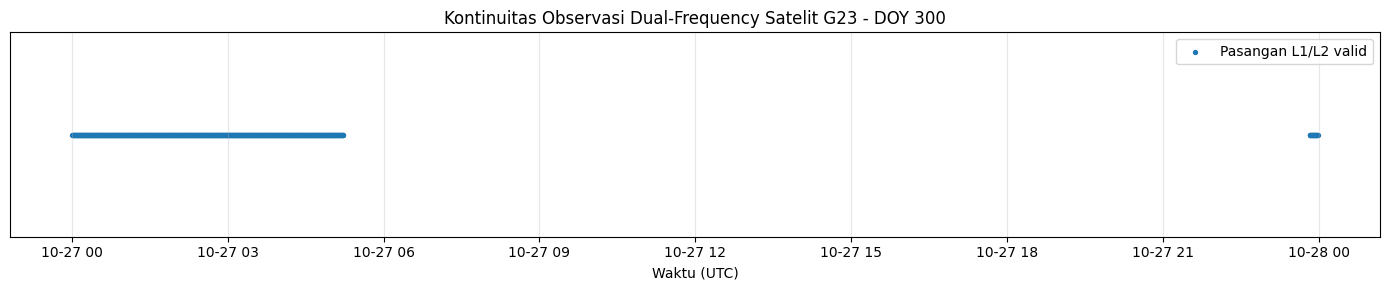

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 3))

plt.scatter(
    waktu[valid],
    np.ones(valid.sum()),
    s=8,
    label="Pasangan L1/L2 valid"
)

plt.yticks([])
plt.xlabel("Waktu (UTC)")
plt.title("Kontinuitas Observasi Dual-Frequency Satelit G23 - DOY 300")
plt.grid(axis="x", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

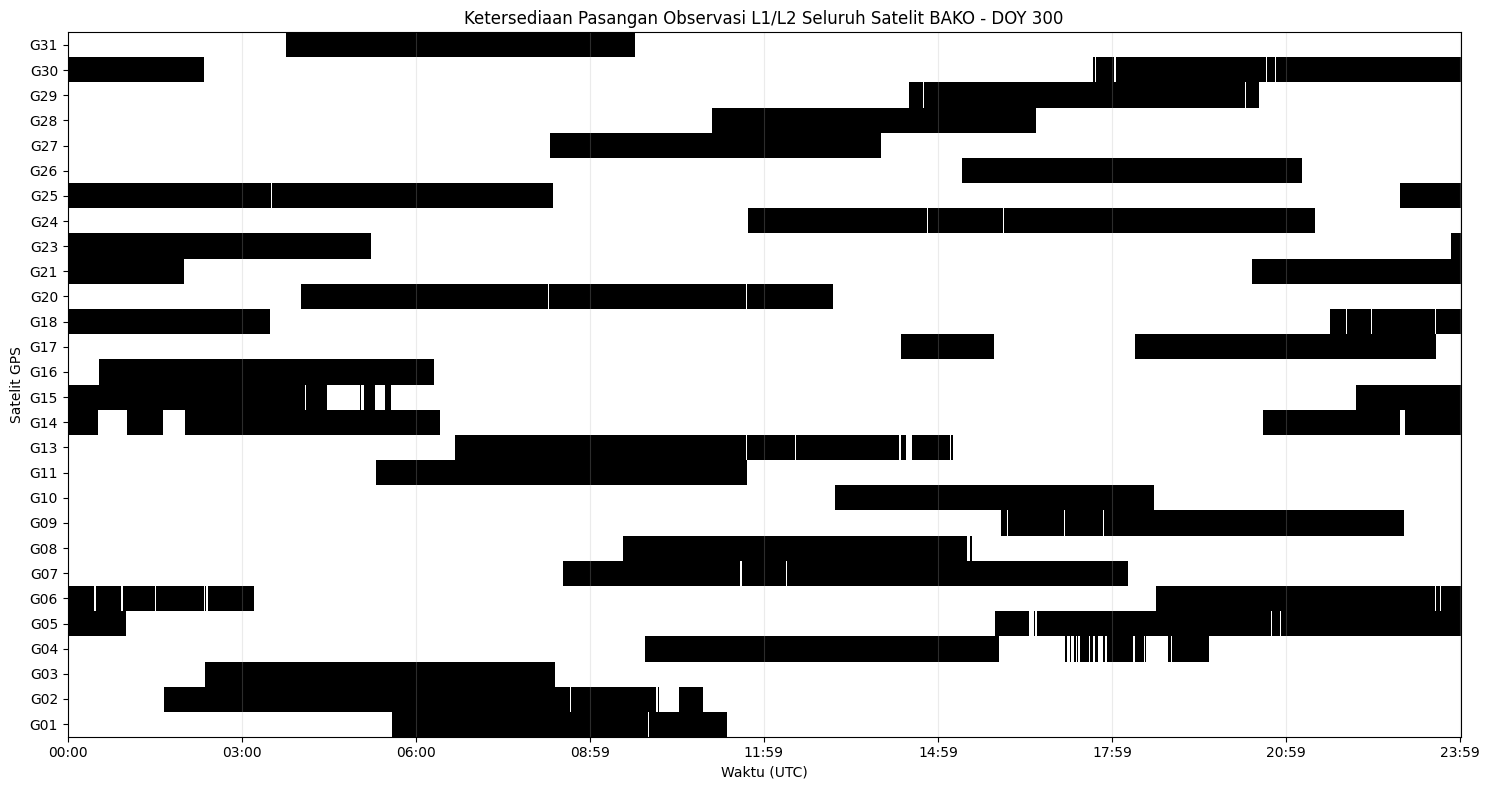

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Matriks ketersediaan pasangan L1/L2
l1_all = obs["L1"].values
l2_all = obs["L2"].values

valid_all = np.isfinite(l1_all) & np.isfinite(l2_all)

# Waktu dan identitas satelit
waktu = pd.DatetimeIndex(obs.time.values)
satelit = obs.sv.values

# Visualisasi
fig, ax = plt.subplots(figsize=(15, 8))

ax.imshow(
    valid_all.T,
    aspect="auto",
    interpolation="nearest",
    origin="lower",
    extent=[
        0,
        len(waktu),
        -0.5,
        len(satelit) - 0.5
    ],
    cmap="Greys"
)

# Sumbu waktu dalam UTC
posisi_tick = np.linspace(0, len(waktu) - 1, 9)

ax.set_xticks(posisi_tick)
ax.set_xticklabels([
    waktu[int(i)].strftime("%H:%M")
    for i in posisi_tick
])

ax.set_yticks(range(len(satelit)))
ax.set_yticklabels(satelit)

ax.set_xlabel("Waktu (UTC)")
ax.set_ylabel("Satelit GPS")
ax.set_title(
    "Ketersediaan Pasangan Observasi L1/L2 "
    "Seluruh Satelit BAKO - DOY 300"
)

ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [18]:
import numpy as np
import pandas as pd

l1_all = obs["L1"].values
l2_all = obs["L2"].values

waktu = pd.DatetimeIndex(obs.time.values)
satelit = obs.sv.values

hasil_semua_segmen = []

for kolom, sv in enumerate(satelit):

    # Pasangan L1/L2 valid untuk satelit terkait
    valid = (
        np.isfinite(l1_all[:, kolom]) &
        np.isfinite(l2_all[:, kolom])
    )

    # Mendeteksi awal dan akhir segmen
    perubahan = np.diff(
        np.r_[False, valid, False].astype(int)
    )

    awal_segmen = np.where(perubahan == 1)[0]
    akhir_segmen = np.where(perubahan == -1)[0]

    for nomor, (awal, akhir) in enumerate(
        zip(awal_segmen, akhir_segmen), start=1
    ):

        hasil_semua_segmen.append({
            "Satelit": sv,
            "Segmen": nomor,
            "Waktu_Mulai": waktu[awal],
            "Waktu_Akhir": waktu[akhir - 1],
            "Jumlah_Epoch": akhir - awal,
            "Durasi_Menit": (
                waktu[akhir - 1] - waktu[awal]
            ).total_seconds() / 60
        })

df_semua_segmen = pd.DataFrame(hasil_semua_segmen)

print("HASIL SEGMENTASI SELURUH SATELIT BAKO DOY 300")
print("=" * 90)

display(df_semua_segmen)

HASIL SEGMENTASI SELURUH SATELIT BAKO DOY 300


,Satelit,Segmen,Waktu_Mulai,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit
0,G01,1,2003-10-27 05:35:30.030,2003-10-27 09:59:30.053,529,264.000383
1,G01,2,2003-10-27 10:00:30.053,2003-10-27 11:21:00.061,162,80.500133
2,G02,1,2003-10-27 01:39:30.009,2003-10-27 08:39:00.046,840,419.500617
3,G02,2,2003-10-27 08:40:00.046,2003-10-27 10:07:30.053,176,87.500117
4,G02,3,2003-10-27 10:10:00.054,2003-10-27 10:10:30.053,2,0.499983
...,...,...,...,...,...,...
103,G30,4,2003-10-27 18:03:00.096,2003-10-27 20:37:30.109,310,154.500217
104,G30,5,2003-10-27 20:39:30.109,2003-10-27 20:46:30.111,15,7.000033
105,G30,6,2003-10-27 20:48:00.111,2003-10-27 21:06:30.112,38,18.500017
106,G30,7,2003-10-27 21:07:30.112,2003-10-27 23:59:00.128,344,171.500267


In [19]:
ringkasan_segmen = (
    df_semua_segmen
    .groupby("Satelit")
    .agg(
        Jumlah_Segmen=("Segmen", "count"),
        Total_Epoch_Valid=("Jumlah_Epoch", "sum"),
        Segmen_Terlama_Menit=("Durasi_Menit", "max"),
        Segmen_Tersingkat_Menit=("Durasi_Menit", "min")
    )
    .reset_index()
)

print("RINGKASAN KONTINUITAS SETIAP SATELIT")
print("=" * 90)

display(ringkasan_segmen)

RINGKASAN KONTINUITAS SETIAP SATELIT


,Satelit,Jumlah_Segmen,Total_Epoch_Valid,Segmen_Terlama_Menit,Segmen_Tersingkat_Menit
0,G01,2,691,264.000383,80.500133
1,G02,4,1068,419.500617,0.499983
2,G03,1,724,361.500533,361.500533
3,G04,14,939,365.000550,0.000000
4,G05,8,1064,185.000267,0.000000
5,G06,9,998,288.000433,0.500000
6,G07,3,1161,351.000533,45.000050
7,G08,2,715,354.500517,2.000000
8,G09,4,827,309.500467,5.499983
9,G10,1,660,329.500483,329.500483


In [20]:
# Menghitung jumlah epoch pada setiap segmen
print("DISTRIBUSI PANJANG SEGMEN")
print("=" * 65)

display(
    df_semua_segmen["Jumlah_Epoch"]
    .value_counts()
    .sort_index()
    .rename_axis("Jumlah_Epoch")
    .reset_index(name="Jumlah_Segmen")
)

# Menampilkan segmen dengan maksimal 3 epoch
segmen_pendek = (
    df_semua_segmen[
        df_semua_segmen["Jumlah_Epoch"] <= 3
    ]
    .sort_values(["Satelit", "Waktu_Mulai"])
    .reset_index(drop=True)
)

print("\nSEGMEN DENGAN MAKSIMAL 3 EPOCH")
print("=" * 85)

display(segmen_pendek)

DISTRIBUSI PANJANG SEGMEN


,Jumlah_Epoch,Jumlah_Segmen
0,1,5
1,2,4
2,3,3
3,4,1
4,5,3
...,...,...
84,720,1
85,724,1
86,731,1
87,767,1



SEGMEN DENGAN MAKSIMAL 3 EPOCH


,Satelit,Segmen,Waktu_Mulai,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit
0,G02,3,2003-10-27 10:10:00.054,2003-10-27 10:10:30.053,2,0.499983
1,G04,3,2003-10-27 17:16:00.092,2003-10-27 17:16:30.091,2,0.499983
2,G04,4,2003-10-27 17:20:00.093,2003-10-27 17:21:00.093,3,1.000000
3,G04,5,2003-10-27 17:22:30.092,2003-10-27 17:23:30.092,3,1.000000
4,G04,12,2003-10-27 18:33:30.099,2003-10-27 18:33:30.099,1,0.000000
5,G05,3,2003-10-27 16:38:00.089,2003-10-27 16:38:30.088,2,0.499983
6,G05,4,2003-10-27 16:40:00.089,2003-10-27 16:40:00.089,1,0.000000
7,G06,5,2003-10-27 02:22:30.013,2003-10-27 02:23:00.013,2,0.500000
8,G13,7,2003-10-27 15:17:30.082,2003-10-27 15:17:30.082,1,0.000000
9,G15,3,2003-10-27 05:02:30.027,2003-10-27 05:02:30.027,1,0.000000


In [21]:
# Satelit yang memiliki segmen dengan maksimal 3 epoch
sat_pendek = (
    segmen_pendek["Satelit"]
    .unique()
)

# Ambil seluruh segmen dari satelit tersebut
df_konteks_segmen = (
    df_semua_segmen[
        df_semua_segmen["Satelit"].isin(sat_pendek)
    ]
    .sort_values(["Satelit", "Waktu_Mulai"])
    .copy()
)

# Hitung jeda dari segmen sebelumnya
df_konteks_segmen["Jeda_Sebelumnya_Menit"] = (
    df_konteks_segmen
    .groupby("Satelit")["Waktu_Mulai"]
    .diff()
    .dt.total_seconds() / 60
    -
    df_konteks_segmen
    .groupby("Satelit")["Durasi_Menit"]
    .shift(1)
)

print("KONTEKS SEGMEN SATELIT DENGAN SEGMEN PENDEK")
print("=" * 100)

display(df_konteks_segmen[
    [
        "Satelit",
        "Segmen",
        "Waktu_Mulai",
        "Waktu_Akhir",
        "Jumlah_Epoch",
        "Durasi_Menit",
        "Jeda_Sebelumnya_Menit"
    ]
])

KONTEKS SEGMEN SATELIT DENGAN SEGMEN PENDEK


,Satelit,Segmen,Waktu_Mulai,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit,Jeda_Sebelumnya_Menit
2,G02,1,2003-10-27 01:39:30.009,2003-10-27 08:39:00.046,840,419.500617,NaN
3,G02,2,2003-10-27 08:40:00.046,2003-10-27 10:07:30.053,176,87.500117,1.000000
4,G02,3,2003-10-27 10:10:00.054,2003-10-27 10:10:30.053,2,0.499983,2.500017
5,G02,4,2003-10-27 10:31:30.056,2003-10-27 10:56:00.058,50,24.500033,21.000050
7,G04,1,2003-10-27 09:57:00.053,2003-10-27 16:02:00.086,731,365.000550,NaN
8,G04,2,2003-10-27 17:10:30.091,2003-10-27 17:12:30.091,5,2.000000,68.500083
9,G04,3,2003-10-27 17:16:00.092,2003-10-27 17:16:30.091,2,0.499983,3.500017
10,G04,4,2003-10-27 17:20:00.093,2003-10-27 17:21:00.093,3,1.000000,3.500033
11,G04,5,2003-10-27 17:22:30.092,2003-10-27 17:23:30.092,3,1.000000,1.499983
12,G04,6,2003-10-27 17:25:30.092,2003-10-27 17:35:00.094,20,9.500033,2.000000


In [22]:
# Pastikan seluruh segmen diurutkan berdasarkan waktu
df_gap = (
    df_semua_segmen
    .sort_values(["Satelit", "Waktu_Mulai"])
    .copy()
)

# Waktu akhir segmen sebelumnya
df_gap["Akhir_Sebelumnya"] = (
    df_gap.groupby("Satelit")["Waktu_Akhir"].shift(1)
)

# Selisih waktu dari akhir segmen sebelumnya
# ke awal segmen berikutnya
df_gap["Selisih_Detik"] = (
    df_gap["Waktu_Mulai"] -
    df_gap["Akhir_Sebelumnya"]
).dt.total_seconds()

# Jumlah epoch kosong di antara dua segmen
df_gap["Epoch_Kosong"] = (
    np.round(df_gap["Selisih_Detik"] / 30) - 1
)

# Hapus baris segmen pertama setiap satelit
df_gap = df_gap.dropna(
    subset=["Akhir_Sebelumnya"]
).copy()

# Konversi ke integer
df_gap["Epoch_Kosong"] = (
    df_gap["Epoch_Kosong"].astype(int)
)

df_gap["Jeda_Menit"] = (
    df_gap["Selisih_Detik"] / 60
)

hasil_gap = df_gap[
    [
        "Satelit",
        "Akhir_Sebelumnya",
        "Waktu_Mulai",
        "Jeda_Menit",
        "Epoch_Kosong"
    ]
].reset_index(drop=True)

print("ANALISIS JEDA ANTARSEGMEN SELURUH SATELIT")
print("=" * 90)

display(hasil_gap)

ANALISIS JEDA ANTARSEGMEN SELURUH SATELIT


,Satelit,Akhir_Sebelumnya,Waktu_Mulai,Jeda_Menit,Epoch_Kosong
0,G01,2003-10-27 09:59:30.053,2003-10-27 10:00:30.053,1.000000,1
1,G02,2003-10-27 08:39:00.046,2003-10-27 08:40:00.046,1.000000,1
2,G02,2003-10-27 10:07:30.053,2003-10-27 10:10:00.054,2.500017,4
3,G02,2003-10-27 10:10:30.053,2003-10-27 10:31:30.056,21.000050,41
4,G04,2003-10-27 16:02:00.086,2003-10-27 17:10:30.091,68.500083,136
...,...,...,...,...,...
75,G30,2003-10-27 17:40:30.094,2003-10-27 17:42:30.094,2.000000,3
76,G30,2003-10-27 18:01:00.096,2003-10-27 18:03:00.096,2.000000,3
77,G30,2003-10-27 20:37:30.109,2003-10-27 20:39:30.109,2.000000,3
78,G30,2003-10-27 20:46:30.111,2003-10-27 20:48:00.111,1.500000,2


In [23]:
ringkasan_gap = (
    hasil_gap
    .groupby("Satelit")
    .agg(
        Jumlah_Jeda=("Epoch_Kosong", "count"),
        Total_Epoch_Kosong=("Epoch_Kosong", "sum"),
        Jeda_Maksimum_Menit=("Jeda_Menit", "max"),
        Epoch_Kosong_Maksimum=("Epoch_Kosong", "max")
    )
    .reset_index()
)

display(ringkasan_gap)

,Satelit,Jumlah_Jeda,Total_Epoch_Kosong,Jeda_Maksimum_Menit,Epoch_Kosong_Maksimum
0,G01,1,1,1.000000,1
1,G02,3,46,21.000050,41
2,G04,13,226,68.500083,136
3,G05,7,1814,898.501317,1796
4,G06,8,1880,931.501400,1862
5,G07,2,6,2.000000,3
6,G08,1,6,3.500017,6
7,G09,3,7,2.000017,3
8,G13,6,30,6.500017,12
9,G14,5,1820,851.001267,1701


In [24]:
# Matriks observasi
l1_all = obs["L1"].values
l2_all = obs["L2"].values

waktu = pd.DatetimeIndex(obs.time.values)
satelit = obs.sv.values

hasil_status_gap = []

for _, row in df_gap.iterrows():

    sv = row["Satelit"]
    kolom = list(satelit).index(sv)

    # Epoch di antara dua segmen valid
    mask_gap = (
        (waktu > row["Akhir_Sebelumnya"]) &
        (waktu < row["Waktu_Mulai"])
    )

    l1_gap = l1_all[mask_gap, kolom]
    l2_gap = l2_all[mask_gap, kolom]

    valid_l1 = np.isfinite(l1_gap)
    valid_l2 = np.isfinite(l2_gap)

    hasil_status_gap.append({
        "Satelit": sv,
        "Epoch_Gap": len(l1_gap),
        "L1_Saja": int((valid_l1 & ~valid_l2).sum()),
        "L2_Saja": int((~valid_l1 & valid_l2).sum()),
        "Keduanya_Tidak_Ada": int((~valid_l1 & ~valid_l2).sum())
    })

df_status_gap = pd.DataFrame(hasil_status_gap)

print("STATUS OBSERVASI PADA EPOCH GAP")
print("=" * 85)

display(df_status_gap)

STATUS OBSERVASI PADA EPOCH GAP


,Satelit,Epoch_Gap,L1_Saja,L2_Saja,Keduanya_Tidak_Ada
0,G01,1,1,0,0
1,G02,1,1,0,0
2,G02,4,4,0,0
3,G02,41,9,0,32
4,G04,136,5,0,131
...,...,...,...,...,...
75,G30,3,2,0,1
76,G30,3,3,0,0
77,G30,3,3,0,0
78,G30,2,2,0,0


In [25]:
ringkasan_status_gap = (
    df_status_gap
    .groupby("Satelit")
    .agg(
        Total_Epoch_Gap=("Epoch_Gap", "sum"),
        Total_L1_Saja=("L1_Saja", "sum"),
        Total_L2_Saja=("L2_Saja", "sum"),
        Total_Keduanya_Tidak_Ada=(
            "Keduanya_Tidak_Ada", "sum"
        )
    )
    .reset_index()
)

display(ringkasan_status_gap)

,Satelit,Total_Epoch_Gap,Total_L1_Saja,Total_L2_Saja,Total_Keduanya_Tidak_Ada
0,G01,1,1,0,0
1,G02,46,14,0,32
2,G04,226,60,0,166
3,G05,1814,20,0,1794
4,G06,1880,31,0,1849
5,G07,6,6,0,0
6,G08,6,6,0,0
7,G09,7,6,0,1
8,G13,30,28,0,2
9,G14,1820,11,0,1809


In [26]:
# Hitung jumlah satelit dengan observasi valid per epoch
jumlah_l1 = np.isfinite(obs["L1"].values).sum(axis=1)
jumlah_l2 = np.isfinite(obs["L2"].values).sum(axis=1)

# Jumlah satelit yang memiliki pasangan L1/L2
jumlah_pasangan = (
    np.isfinite(obs["L1"].values) &
    np.isfinite(obs["L2"].values)
).sum(axis=1)

df_ketersediaan_epoch = pd.DataFrame({
    "Waktu": pd.DatetimeIndex(obs.time.values),
    "Jumlah_L1": jumlah_l1,
    "Jumlah_L2": jumlah_l2,
    "Jumlah_Pasangan": jumlah_pasangan
})

print("STATISTIK KETERSEDIAAN OBSERVASI PER EPOCH")
print("=" * 75)

display(
    df_ketersediaan_epoch[
        ["Jumlah_L1", "Jumlah_L2", "Jumlah_Pasangan"]
    ].describe()
)

STATISTIK KETERSEDIAAN OBSERVASI PER EPOCH


,Jumlah_L1,Jumlah_L2,Jumlah_Pasangan
count,2878.000000,2878.000000,2878.000000
mean,8.421473,8.297429,8.297429
std,0.608637,0.659521,0.659521
min,7.000000,6.000000,6.000000
25%,8.000000,8.000000,8.000000
50%,8.000000,8.000000,8.000000
75%,9.000000,9.000000,9.000000
max,9.000000,9.000000,9.000000


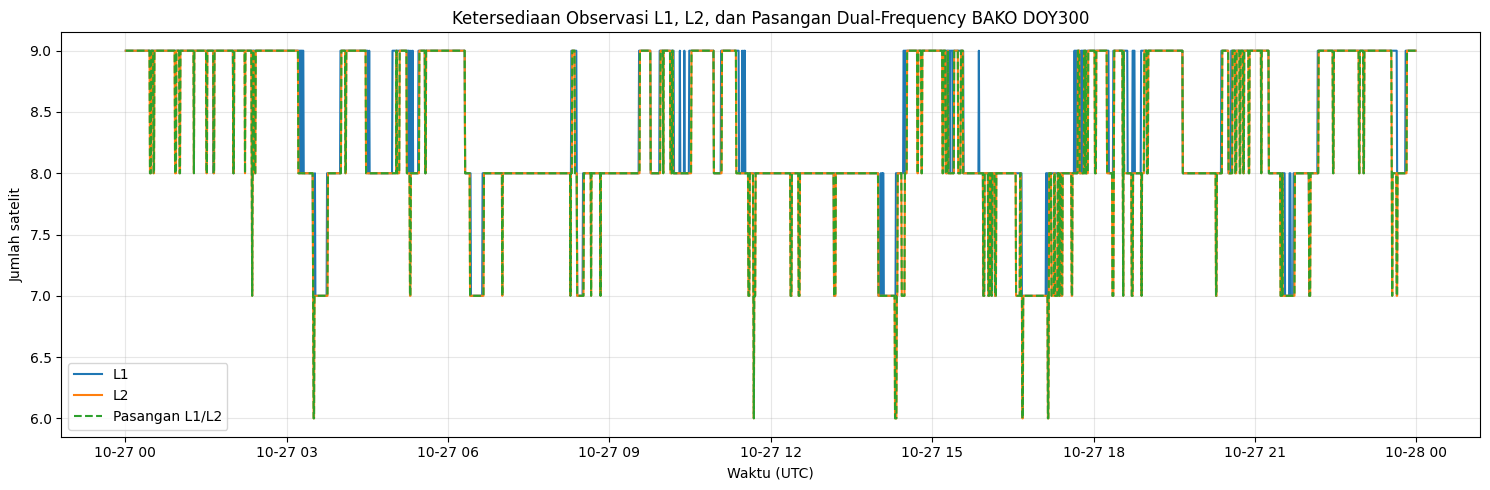

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    df_ketersediaan_epoch["Waktu"],
    df_ketersediaan_epoch["Jumlah_L1"],
    label="L1"
)

plt.plot(
    df_ketersediaan_epoch["Waktu"],
    df_ketersediaan_epoch["Jumlah_L2"],
    label="L2"
)

plt.plot(
    df_ketersediaan_epoch["Waktu"],
    df_ketersediaan_epoch["Jumlah_Pasangan"],
    label="Pasangan L1/L2",
    linestyle="--"
)

plt.xlabel("Waktu (UTC)")
plt.ylabel("Jumlah satelit")
plt.title(
    "Ketersediaan Observasi L1, L2, dan Pasangan Dual-Frequency "
    "BAKO DOY300"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
print("DISTRIBUSI JUMLAH PASANGAN L1/L2 PER EPOCH")
print("=" * 60)

distribusi_pasangan = (
    df_ketersediaan_epoch["Jumlah_Pasangan"]
    .value_counts()
    .sort_index()
    .rename_axis("Jumlah_Pasangan")
    .reset_index(name="Jumlah_Epoch")
)

distribusi_pasangan["Persentase"] = (
    distribusi_pasangan["Jumlah_Epoch"] /
    len(df_ketersediaan_epoch) * 100
)

display(distribusi_pasangan)

print(
    "\nTotal persentase:",
    distribusi_pasangan["Persentase"].sum()
)

DISTRIBUSI JUMLAH PASANGAN L1/L2 PER EPOCH


,Jumlah_Pasangan,Jumlah_Epoch,Persentase
0,6,11,0.382210
1,7,292,10.145935
2,8,1405,48.818624
3,9,1170,40.653231



Total persentase: 100.0


In [29]:
print("KOLOM DATA KETERSEDIAAN PER EPOCH")
print("=" * 60)

print(df_ketersediaan_epoch.columns.tolist())

display(df_ketersediaan_epoch.head())

KOLOM DATA KETERSEDIAAN PER EPOCH
['Waktu', 'Jumlah_L1', 'Jumlah_L2', 'Jumlah_Pasangan']


,Waktu,Jumlah_L1,Jumlah_L2,Jumlah_Pasangan
0,2003-10-27 00:00:30.000,9,9,9
1,2003-10-27 00:01:00.000,9,9,9
2,2003-10-27 00:01:30.000,9,9,9
3,2003-10-27 00:02:00.001,9,9,9
4,2003-10-27 00:02:30.001,9,9,9


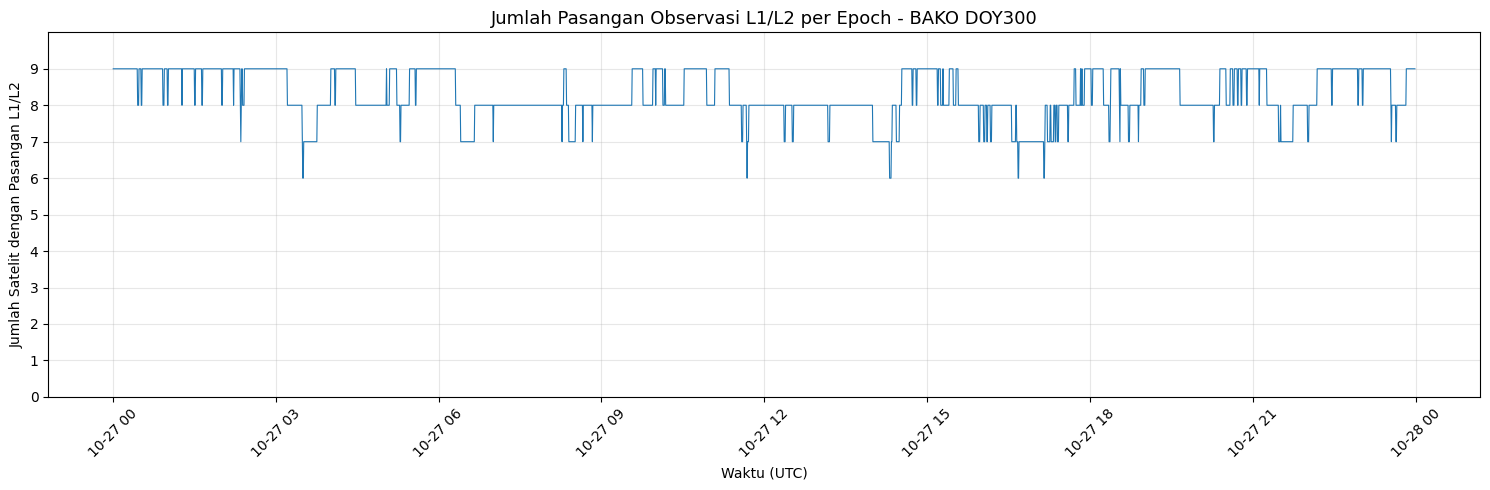

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(
    df_ketersediaan_epoch["Waktu"],
    df_ketersediaan_epoch["Jumlah_Pasangan"],
    linewidth=0.8
)

plt.title(
    "Jumlah Pasangan Observasi L1/L2 per Epoch - BAKO DOY300",
    fontsize=13
)

plt.xlabel("Waktu (UTC)")
plt.ylabel("Jumlah Satelit dengan Pasangan L1/L2")

plt.ylim(0, 10)
plt.yticks(range(0, 10))

plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [31]:
print("RINGKASAN JUMLAH PASANGAN L1/L2")
print("=" * 60)

print(
    df_ketersediaan_epoch["Jumlah_Pasangan"]
    .describe()
)

print("\nDISTRIBUSI JUMLAH PASANGAN")
print("=" * 60)

print(
    df_ketersediaan_epoch["Jumlah_Pasangan"]
    .value_counts()
    .sort_index()
)

print("\nWAKTU DENGAN PASANGAN PALING SEDIKIT")
print("=" * 60)

display(
    df_ketersediaan_epoch[
        df_ketersediaan_epoch["Jumlah_Pasangan"]
        == df_ketersediaan_epoch["Jumlah_Pasangan"].min()
    ].head(10)
)

print("\nWAKTU DENGAN PASANGAN PALING BANYAK")
print("=" * 60)

display(
    df_ketersediaan_epoch[
        df_ketersediaan_epoch["Jumlah_Pasangan"]
        == df_ketersediaan_epoch["Jumlah_Pasangan"].max()
    ].head(10)
)

RINGKASAN JUMLAH PASANGAN L1/L2
count    2878.000000
mean        8.297429
std         0.659521
min         6.000000
25%         8.000000
50%         8.000000
75%         9.000000
max         9.000000
Name: Jumlah_Pasangan, dtype: float64

DISTRIBUSI JUMLAH PASANGAN
Jumlah_Pasangan
6      11
7     292
8    1405
9    1170
Name: count, dtype: int64

WAKTU DENGAN PASANGAN PALING SEDIKIT


,Waktu,Jumlah_L1,Jumlah_L2,Jumlah_Pasangan
419,2003-10-27 03:30:00.019,7,6,6
420,2003-10-27 03:30:30.018,7,6,6
1401,2003-10-27 11:41:00.062,8,6,6
1716,2003-10-27 14:18:30.077,7,6,6
1717,2003-10-27 14:19:00.077,7,6,6
1718,2003-10-27 14:19:30.077,8,6,6
1719,2003-10-27 14:20:00.077,8,6,6
2000,2003-10-27 16:40:30.088,7,6,6
2001,2003-10-27 16:41:00.089,7,6,6
2057,2003-10-27 17:09:00.092,8,6,6



WAKTU DENGAN PASANGAN PALING BANYAK


,Waktu,Jumlah_L1,Jumlah_L2,Jumlah_Pasangan
0,2003-10-27 00:00:30.000,9,9,9
1,2003-10-27 00:01:00.000,9,9,9
2,2003-10-27 00:01:30.000,9,9,9
3,2003-10-27 00:02:00.001,9,9,9
4,2003-10-27 00:02:30.001,9,9,9
5,2003-10-27 00:03:00.001,9,9,9
6,2003-10-27 00:03:30.001,9,9,9
7,2003-10-27 00:04:00.001,9,9,9
8,2003-10-27 00:04:30.001,9,9,9
9,2003-10-27 00:05:00.001,9,9,9


In [32]:
print("STRUKTUR VARIABEL")
print("=" * 50)

print("l1:")
print("Tipe  :", type(l1))
print("Shape :", np.shape(l1))

print("\nl2:")
print("Tipe  :", type(l2))
print("Shape :", np.shape(l2))

print("\nobs:")
print("Tipe  :", type(obs))

print("\nVariabel data observasi:")
print(list(obs.data_vars))

print("\nDimensi observasi:")
print(obs.dims)

STRUKTUR VARIABEL
l1:
Tipe  : <class 'numpy.ndarray'>
Shape : (2878,)

l2:
Tipe  : <class 'numpy.ndarray'>
Shape : (2878,)

obs:
Tipe  : <class 'xarray.core.dataset.Dataset'>

Variabel data observasi:
['L1', 'L2', 'C1', 'P2', 'P1', 'D1']

Dimensi observasi:
FrozenMappingWarningOnValuesAccess({'time': 2878, 'sv': 28})


In [33]:
print("IDENTIFIKASI SATELIT TANPA PASANGAN L1/L2")
print("=" * 70)

# Ambil data L1 dan L2 langsung dari dataset GeoRinex
data_l1 = obs["L1"].values
data_l2 = obs["L2"].values

# Nama satelit
daftar_sv = obs.sv.values

# Epoch dengan jumlah pasangan minimum (6)
indeks_minimum = df_ketersediaan_epoch[
    df_ketersediaan_epoch["Jumlah_Pasangan"] == 6
].index

daftar_hasil = []

for idx in indeks_minimum:

    nilai_l1 = data_l1[idx, :]
    nilai_l2 = data_l2[idx, :]

    for i, sv in enumerate(daftar_sv):

        valid_l1 = np.isfinite(nilai_l1[i])
        valid_l2 = np.isfinite(nilai_l2[i])

        if not (valid_l1 and valid_l2):

            daftar_hasil.append({
                "Waktu": df_ketersediaan_epoch.loc[idx, "Waktu"],
                "SV": str(sv),
                "L1": valid_l1,
                "L2": valid_l2,
                "Status": (
                    "L1 saja" if valid_l1
                    else "L2 saja" if valid_l2
                    else "L1 dan L2 tidak tersedia"
                )
            })

df_satelit_tidak_berpasangan = pd.DataFrame(daftar_hasil)

display(df_satelit_tidak_berpasangan)

print("\nJumlah baris pemeriksaan:",
      len(df_satelit_tidak_berpasangan))

IDENTIFIKASI SATELIT TANPA PASANGAN L1/L2


,Waktu,SV,L1,L2,Status
0,2003-10-27 03:30:00.019,G01,False,False,L1 dan L2 tidak tersedia
1,2003-10-27 03:30:00.019,G04,False,False,L1 dan L2 tidak tersedia
2,2003-10-27 03:30:00.019,G05,False,False,L1 dan L2 tidak tersedia
3,2003-10-27 03:30:00.019,G06,False,False,L1 dan L2 tidak tersedia
4,2003-10-27 03:30:00.019,G07,False,False,L1 dan L2 tidak tersedia
...,...,...,...,...,...
237,2003-10-27 17:09:30.091,G25,False,False,L1 dan L2 tidak tersedia
238,2003-10-27 17:09:30.091,G27,False,False,L1 dan L2 tidak tersedia
239,2003-10-27 17:09:30.091,G28,False,False,L1 dan L2 tidak tersedia
240,2003-10-27 17:09:30.091,G30,False,False,L1 dan L2 tidak tersedia



Jumlah baris pemeriksaan: 242


In [34]:
print("FREKUENSI KETIDAKTERSEDIAAN L1/L2 PER SATELIT")
print("=" * 65)

rekap_tidak_tersedia = (
    df_satelit_tidak_berpasangan
    .groupby(["SV", "Status"])
    .size()
    .reset_index(name="Jumlah_Epoch")
    .sort_values("Jumlah_Epoch", ascending=False)
)

display(rekap_tidak_tersedia)

print("\nJUMLAH SATELIT YANG DIPERIKSA:",
      len(daftar_sv))

print("TOTAL KETIDAKTERSEDIAAN:",
      len(df_satelit_tidak_berpasangan))

FREKUENSI KETIDAKTERSEDIAAN L1/L2 PER SATELIT


,SV,Status,Jumlah_Epoch
0,G01,L1 dan L2 tidak tersedia,11
34,G31,L1 dan L2 tidak tersedia,11
7,G06,L1 dan L2 tidak tersedia,11
33,G30,L1 dan L2 tidak tersedia,11
21,G18,L1 dan L2 tidak tersedia,11
24,G21,L1 dan L2 tidak tersedia,11
13,G11,L1 dan L2 tidak tersedia,10
30,G27,L1 dan L2 tidak tersedia,10
22,G20,L1 dan L2 tidak tersedia,10
2,G03,L1 dan L2 tidak tersedia,9



JUMLAH SATELIT YANG DIPERIKSA: 28
TOTAL KETIDAKTERSEDIAAN: 242


In [35]:
print("PEMERIKSAAN OBSERVASI PADA EPOCH 03:30:00 UTC")
print("=" * 70)

idx = indeks_minimum[0]

hasil_epoch = pd.DataFrame({
    "SV": obs.sv.values,
    "L1": np.isfinite(data_l1[idx, :]),
    "L2": np.isfinite(data_l2[idx, :])
})

hasil_epoch["Pasangan_L1_L2"] = (
    hasil_epoch["L1"] & hasil_epoch["L2"]
)

hasil_epoch["Status"] = np.select(
    [
        hasil_epoch["Pasangan_L1_L2"],
        hasil_epoch["L1"] & ~hasil_epoch["L2"],
        ~hasil_epoch["L1"] & hasil_epoch["L2"]
    ],
    [
        "L1 dan L2 tersedia",
        "L1 saja",
        "L2 saja"
    ],
    default="L1 dan L2 tidak tersedia"
)

display(hasil_epoch)

print("\nJumlah pasangan:",
      hasil_epoch["Pasangan_L1_L2"].sum())

print("Jumlah L1:",
      hasil_epoch["L1"].sum())

print("Jumlah L2:",
      hasil_epoch["L2"].sum())

PEMERIKSAAN OBSERVASI PADA EPOCH 03:30:00 UTC


,SV,L1,L2,Pasangan_L1_L2,Status
0,G01,False,False,False,L1 dan L2 tidak tersedia
1,G02,True,True,True,L1 dan L2 tersedia
2,G03,True,True,True,L1 dan L2 tersedia
3,G04,False,False,False,L1 dan L2 tidak tersedia
4,G05,False,False,False,L1 dan L2 tidak tersedia
5,G06,False,False,False,L1 dan L2 tidak tersedia
6,G07,False,False,False,L1 dan L2 tidak tersedia
7,G08,False,False,False,L1 dan L2 tidak tersedia
8,G09,False,False,False,L1 dan L2 tidak tersedia
9,G10,False,False,False,L1 dan L2 tidak tersedia



Jumlah pasangan: 6
Jumlah L1: 7
Jumlah L2: 6


In [36]:
# PEMERIKSAAN KETERSEDIAAN OBSERVASI FASE DAN PSEUDORANGE

data_l1 = obs["L1"].values
data_l2 = obs["L2"].values
data_c1 = obs["C1"].values
data_p2 = obs["P2"].values

# Ketersediaan setiap observasi
valid_l1 = np.isfinite(data_l1)
valid_l2 = np.isfinite(data_l2)
valid_c1 = np.isfinite(data_c1)
valid_p2 = np.isfinite(data_p2)

# Pasangan fase dan pseudorange
pasangan_fase = valid_l1 & valid_l2
pasangan_kode = valid_c1 & valid_p2

# Keempat observasi tersedia pada epoch dan satelit yang sama
lengkap_empat = (
    valid_l1 & valid_l2 &
    valid_c1 & valid_p2
)

# Ringkasan jumlah per epoch
df_ketersediaan = pd.DataFrame({
    "Waktu": pd.DatetimeIndex(obs.time.values),
    "Pasangan_L1_L2": pasangan_fase.sum(axis=1),
    "Pasangan_C1_P2": pasangan_kode.sum(axis=1),
    "Lengkap_empat_observasi": lengkap_empat.sum(axis=1)
})

print("RINGKASAN KETERSEDIAAN OBSERVASI")
print("=" * 65)

display(
    df_ketersediaan[
        [
            "Pasangan_L1_L2",
            "Pasangan_C1_P2",
            "Lengkap_empat_observasi"
        ]
    ].describe()
)

print("\nDISTRIBUSI JUMLAH OBSERVASI LENGKAP")
display(
    df_ketersediaan[
        "Lengkap_empat_observasi"
    ].value_counts().sort_index()
)

RINGKASAN KETERSEDIAAN OBSERVASI


,Pasangan_L1_L2,Pasangan_C1_P2,Lengkap_empat_observasi
count,2878.000000,2878.000000,2878.000000
mean,8.297429,8.297429,8.297429
std,0.659521,0.659521,0.659521
min,6.000000,6.000000,6.000000
25%,8.000000,8.000000,8.000000
50%,8.000000,8.000000,8.000000
75%,9.000000,9.000000,9.000000
max,9.000000,9.000000,9.000000



DISTRIBUSI JUMLAH OBSERVASI LENGKAP


Lengkap_empat_observasi
6      11
7     292
8    1405
9    1170
Name: count, dtype: int64

In [37]:
# VERIFIKASI KESESUAIAN OBSERVASI PER SATELIT DAN EPOCH

# Apakah pasangan fase dan pasangan pseudorange tersedia
# pada satelit dan epoch yang sama?
beda_fase_kode = pasangan_fase != pasangan_kode

# Apakah keempat observasi benar-benar tersedia
# setiap kali pasangan L1-L2 tersedia?
beda_fase_lengkap = pasangan_fase != lengkap_empat

print("VERIFIKASI KESESUAIAN OBSERVASI")
print("=" * 65)

print(
    "Jumlah ketidaksesuaian L1-L2 vs C1-P2:",
    beda_fase_kode.sum()
)

print(
    "Jumlah ketidaksesuaian L1-L2 vs kombinasi lengkap:",
    beda_fase_lengkap.sum()
)

print(
    "Jumlah kombinasi L1-L2 yang tersedia:",
    pasangan_fase.sum()
)

print(
    "Jumlah kombinasi lengkap:",
    lengkap_empat.sum()
)

if beda_fase_kode.sum() == 0 and beda_fase_lengkap.sum() == 0:
    print("\nKESIMPULAN: Seluruh pasangan observasi tersedia pada")
    print("satelit dan epoch yang sama.")
else:
    print("\nKESIMPULAN: Ditemukan ketidaksesuaian observasi.")

VERIFIKASI KESESUAIAN OBSERVASI
Jumlah ketidaksesuaian L1-L2 vs C1-P2: 0
Jumlah ketidaksesuaian L1-L2 vs kombinasi lengkap: 0
Jumlah kombinasi L1-L2 yang tersedia: 23880
Jumlah kombinasi lengkap: 23880

KESIMPULAN: Seluruh pasangan observasi tersedia pada
satelit dan epoch yang sama.


In [38]:
# PEMERIKSAAN AWAL CYCLE SLIP: GEOMETRY-FREE PHASE

import numpy as np
import pandas as pd

# 1. Konstanta GPS
c = 299792458  # m/s

f1 = 1575.42e6  # Hz
f2 = 1227.60e6  # Hz

lambda1 = c / f1
lambda2 = c / f2

print("PANJANG GELOMBANG GPS")
print("=" * 60)
print(f"L1: {lambda1:.6f} m")
print(f"L2: {lambda2:.6f} m")

# 2. Ambil data fase
data_l1 = obs["L1"].values
data_l2 = obs["L2"].values

waktu = pd.DatetimeIndex(obs.time.values)
daftar_sv = obs.sv.values

# 3. Hitung Geometry-Free phase dalam meter
gf = lambda1 * data_l1 - lambda2 * data_l2

# 4. Hitung perubahan GF hanya pada epoch berurutan
hasil_gf = []

for j, sv in enumerate(daftar_sv):

    valid = (
        np.isfinite(data_l1[:, j]) &
        np.isfinite(data_l2[:, j])
    )

    indeks = np.where(valid)[0]

    if len(indeks) < 2:
        continue

    waktu_sv = waktu[indeks]
    gf_sv = gf[indeks, j]

    for k in range(1, len(indeks)):

        delta_t = (
            waktu_sv[k] - waktu_sv[k-1]
        ).total_seconds()

        # Hanya gunakan interval sekitar 30 detik
        if 29.5 <= delta_t <= 30.5:

            delta_gf = gf_sv[k] - gf_sv[k-1]

            hasil_gf.append({
                "SV": sv,
                "Waktu": waktu_sv[k],
                "Interval_detik": delta_t,
                "GF_sebelumnya_m": gf_sv[k-1],
                "GF_sekarang_m": gf_sv[k],
                "Delta_GF_m": delta_gf,
                "Abs_Delta_GF_m": abs(delta_gf)
            })

df_gf = pd.DataFrame(hasil_gf)

# 5. Statistik perubahan GF
print("\nSTATISTIK PERUBAHAN GEOMETRY-FREE")
print("=" * 60)

print("Jumlah perubahan GF:", len(df_gf))
print("Jumlah satelit:", df_gf["SV"].nunique())

display(
    df_gf["Delta_GF_m"].describe()
)

# 6. Perubahan GF terbesar
print("\n20 PERUBAHAN GF TERBESAR")
print("=" * 60)

display(
    df_gf.sort_values(
        "Abs_Delta_GF_m",
        ascending=False
    ).head(20)
)

PANJANG GELOMBANG GPS
L1: 0.190294 m
L2: 0.244210 m

STATISTIK PERUBAHAN GEOMETRY-FREE
Jumlah perubahan GF: 23772
Jumlah satelit: 28


count     23772.000000
mean        -19.726406
std        3041.615111
min     -468961.420871
25%          -0.010239
50%          -0.000201
75%           0.012829
max           0.113983
Name: Delta_GF_m, dtype: float64


20 PERUBAHAN GF TERBESAR


,SV,Waktu,Interval_detik,GF_sebelumnya_m,GF_sekarang_m,Delta_GF_m,Abs_Delta_GF_m
10670,G14,2003-10-27 01:24:30.007,29.999,2.165625e+04,-4.473052e+05,-468961.420871,468961.420871
3523,G05,2003-10-27 16:00:30.085,29.999,-5.242205e+03,-5.242338e+03,-0.133028,0.133028
3528,G05,2003-10-27 16:03:00.086,30.001,-5.242810e+03,-5.242941e+03,-0.131350,0.131350
3525,G05,2003-10-27 16:01:30.085,29.999,-5.242449e+03,-5.242575e+03,-0.126482,0.126482
3531,G05,2003-10-27 16:04:30.085,29.999,-5.243170e+03,-5.243293e+03,-0.122673,0.122673
3520,G05,2003-10-27 15:59:00.085,30.000,-5.241852e+03,-5.241974e+03,-0.121106,0.121106
3526,G05,2003-10-27 16:02:00.086,30.001,-5.242575e+03,-5.242696e+03,-0.120827,0.120827
3530,G05,2003-10-27 16:04:00.086,30.001,-5.243050e+03,-5.243170e+03,-0.120136,0.120136
3537,G05,2003-10-27 16:07:30.085,29.999,-5.243845e+03,-5.243963e+03,-0.118772,0.118772
3522,G05,2003-10-27 16:00:00.086,30.001,-5.242089e+03,-5.242205e+03,-0.116346,0.116346


In [39]:
# PEMERIKSAAN NILAI FASE MENTAH DI SEKITAR ANOMALI GF

lokasi_pemeriksaan = [
    ("G14", "2003-10-27 01:24:30"),
    ("G30", "2003-10-27 02:17:00"),
    ("G05", "2003-10-27 16:00:00")
]

hasil_pemeriksaan = []

for sv, waktu_target in lokasi_pemeriksaan:

    j = list(daftar_sv).index(sv)

    target = pd.Timestamp(waktu_target)

    idx_tengah = int(
        np.argmin(np.abs(waktu - target))
    )

    # Ambil 3 epoch sebelum dan sesudah titik pemeriksaan
    for idx in range(
        max(0, idx_tengah - 3),
        min(len(waktu), idx_tengah + 4)
    ):

        l1_val = data_l1[idx, j]
        l2_val = data_l2[idx, j]

        gf_val = (
            lambda1 * l1_val - lambda2 * l2_val
            if np.isfinite(l1_val) and np.isfinite(l2_val)
            else np.nan
        )

        hasil_pemeriksaan.append({
            "SV": sv,
            "Waktu": waktu[idx],
            "L1_cycles": l1_val,
            "L2_cycles": l2_val,
            "GF_meter": gf_val
        })

df_pemeriksaan_anomali = pd.DataFrame(
    hasil_pemeriksaan
)

display(
    df_pemeriksaan_anomali.round(4)
)

C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\1258416951.py:49: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_pemeriksaan_anomali.round(4)


,SV,Waktu,L1_cycles,L2_cycles,GF_meter
0,G14,2003-10-27 01:23:00.008,2.351288e+06,1.743494e+06,2.165622e+04
1,G14,2003-10-27 01:23:30.007,2.396736e+06,1.778908e+06,2.165624e+04
2,G14,2003-10-27 01:24:00.008,2.441916e+06,1.814113e+06,2.165625e+04
3,G14,2003-10-27 01:24:30.007,2.241972e+04,1.849110e+06,-4.473052e+05
4,G14,2003-10-27 01:25:00.008,6.706309e+04,1.883897e+06,-4.473051e+05
5,G14,2003-10-27 01:25:30.007,1.114386e+05,1.918475e+06,-4.473051e+05
6,G14,2003-10-27 01:26:00.008,1.555491e+05,1.952847e+06,-4.473051e+05
7,G30,2003-10-27 02:15:30.012,6.764472e+07,3.096575e+07,5.310211e+06
8,G30,2003-10-27 02:16:00.012,6.781511e+07,3.109851e+07,5.310211e+06
9,G30,2003-10-27 02:16:30.012,6.798566e+07,3.123141e+07,5.310211e+06


In [40]:
# PEMERIKSAAN HEADER DAN REKAMAN MENTAH RINEX

from pathlib import Path

rinex_path = DATA_DIR / "bako3000.03o"

with open(rinex_path, "r") as f:
    lines = f.readlines()

print("HEADER RINEX")
print("=" * 75)

for line in lines:
    if (
        "RINEX VERSION / TYPE" in line
        or "# / TYPES OF OBSERV" in line
        or "END OF HEADER" in line
    ):
        print(line.rstrip())

# Cari rekaman epoch sekitar anomali G14
print("\nREKAMAN MENTAH DI SEKITAR G14")
print("=" * 75)

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[0:2])
        month = int(line[3:5])
        day = int(line[6:8])
        hour = int(line[9:11])
        minute = int(line[12:14])
        second = float(line[15:26])

    except ValueError:
        continue

    if (
        yy == 3
        and month == 10
        and day == 27
        and hour == 1
        and minute in [23, 24, 25]
    ):
        print(f"\nNomor baris: {i}")
        print(line.rstrip())

        # Tampilkan beberapa baris setelah epoch
        for j in range(i + 1, min(i + 8, len(lines))):
            print(lines[j].rstrip())

HEADER RINEX
     2.10           OBSERVATION DATA    G (GPS)             RINEX VERSION / TYPE
     6    L1    L2    C1    P2    P1    D1                  # / TYPES OF OBSERV
                                                            END OF HEADER

REKAMAN MENTAH DI SEKITAR G14


In [41]:
# PEMERIKSAAN EPOCH RINEX 2.10 DI SEKITAR ANOMALI G14

print("EPOCH RAW DI SEKITAR ANOMALI G14")
print("=" * 75)

jumlah_ditemukan = 0

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        # Posisi kolom sesuai format RINEX 2
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

    except ValueError:
        continue

    if (
        yy == 3
        and month == 10
        and day == 27
        and hour == 1
        and minute in [23, 24, 25]
    ):
        jumlah_ditemukan += 1

        print(f"\nNomor baris: {i}")
        print("Epoch:", line.rstrip())

        # Tampilkan beberapa baris setelah epoch
        for j in range(i + 1, min(i + 5, len(lines))):
            print(lines[j].rstrip())

print("\nJumlah epoch ditemukan:", jumlah_ditemukan)

EPOCH RAW DI SEKITAR ANOMALI G14

Nomor baris: 3153
Epoch:  03 10 27  1 23  0.0080000  0  9G21G 6G14G25G15G18G30G16G23
  30926713.16346  24151287.55745  25161225.6644   25161229.0624
     -5201.6874
  49681956.33045   3377019.70145  25923729.0084   25923734.4344
     -2734.7664

Nomor baris: 3172
Epoch:  03 10 27  1 23 30.0080000  0  9G21G 6G14G25G15G18G30G16G23
  31082766.25146  24272887.24945  25190921.2894   25190925.0274
     -5201.7504
  49764007.51645   3440955.59745  25939343.5474   25939349.2544
     -2735.2504

Nomor baris: 3191
Epoch:  03 10 27  1 24  0.0080000  0  9G21G 6G14G25G15G18G30G16G23
  31238821.71246  24394488.80745  25220617.9144   25220622.1444
     -5201.9224
  49846075.75145   3504904.78545  25954958.7274   25954965.7734
     -2735.9844

Nomor baris: 3210
Epoch:  03 10 27  1 24 30.0080000  0  9G21G 6G14G25G15G18G30G16G23
  31394879.57246  24516092.23145  25250315.1094   25250319.3524
     -5201.7034
  49928165.09145   3568870.36245  25970580.4144   25970586.3094

In [42]:
# EKSTRAK OBSERVASI MENTAH G14 DARI RINEX

import numpy as np
import pandas as pd

hasil_g14 = []

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

    except ValueError:
        continue

    if (
        yy == 3 and month == 10 and day == 27
        and hour == 1 and minute in [23, 24, 25]
    ):

        # Daftar satelit pada epoch
        sat_text = line[32:68]

        satelit = [
            sat_text[j:j+3].strip()
            for j in range(0, len(sat_text), 3)
            if sat_text[j:j+3].strip()
        ]

        if "G14" not in satelit:
            continue

        posisi_g14 = satelit.index("G14")

        # Setiap satelit memiliki dua baris observasi
        awal = i + 1 + posisi_g14 * 2

        baris_obs = lines[awal:awal+2]

        # Gabungkan enam field observasi
        teks_obs = "".join(baris_obs)

        nilai = []

        for k in range(6):
            field = teks_obs[k*16:(k+1)*16]
            nilai.append(field[:14].strip())

        waktu = pd.Timestamp(
            year=2000 + yy,
            month=month,
            day=day,
            hour=hour,
            minute=minute
        ) + pd.Timedelta(seconds=second)

        hasil_g14.append({
            "Waktu": waktu,
            "L1_raw": nilai[0],
            "L2_raw": nilai[1],
            "C1_raw": nilai[2],
            "P2_raw": nilai[3],
            "P1_raw": nilai[4],
            "D1_raw": nilai[5]
        })

df_raw_g14 = pd.DataFrame(hasil_g14)

display(df_raw_g14)

,Waktu,L1_raw,L2_raw,C1_raw,P2_raw,P1_raw,D1_raw
0,2003-10-27 01:23:00.008,2351287.560,1743493.535,26750722.156,26750728.109,-1519.406,
1,2003-10-27 01:23:30.008,2396736.399,1778908.131,26759369.328,26759377.723,-1510.391,
2,2003-10-27 01:24:00.008,2441915.785,1814112.792,26767967.430,26767975.930,-1501.547,
3,2003-10-27 01:24:30.008,22419.717,1849109.804,26776514.320,26776520.215,-1492.406,
4,2003-10-27 01:25:00.008,67063.087,1883896.761,26785009.094,26785018.437,-1483.766,
5,2003-10-27 01:25:30.008,111438.628,1918475.056,26793454.547,26793462.742,-1474.875,


In [43]:
# PEMERIKSAAN LLI DAN SSI G14

hasil_lli = []

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])
    except ValueError:
        continue

    if (
        yy == 3 and month == 10 and day == 27
        and hour == 1 and minute in [23, 24, 25]
    ):

        sat_text = line[32:68]

        satelit = [
            sat_text[j:j+3].strip()
            for j in range(0, len(sat_text), 3)
            if sat_text[j:j+3].strip()
        ]

        if "G14" not in satelit:
            continue

        posisi_g14 = satelit.index("G14")
        awal = i + 1 + posisi_g14 * 2

        # Baris pertama berisi observasi L1 dan L2
        obs_line = lines[awal].rstrip("\r\n").ljust(80)

        field_l1 = obs_line[0:16]
        field_l2 = obs_line[16:32]

        hasil_lli.append({
            "Waktu": pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            ) + pd.Timedelta(seconds=second),

            "L1": field_l1[:14].strip(),
            "LLI_L1": repr(field_l1[14]),
            "SSI_L1": repr(field_l1[15]),

            "L2": field_l2[:14].strip(),
            "LLI_L2": repr(field_l2[14]),
            "SSI_L2": repr(field_l2[15])
        })

df_lli = pd.DataFrame(hasil_lli)

display(df_lli)

,Waktu,L1,LLI_L1,SSI_L1,L2,LLI_L2,SSI_L2
0,2003-10-27 01:23:00.008,2351287.560,'4','3',1743493.535,'4','2'
1,2003-10-27 01:23:30.008,2396736.399,'4','3',1778908.131,'4','2'
2,2003-10-27 01:24:00.008,2441915.785,'4','3',1814112.792,'4','3'
3,2003-10-27 01:24:30.008,22419.717,'5','2',1849109.804,'4','3'
4,2003-10-27 01:25:00.008,67063.087,'4','3',1883896.761,'4','3'
5,2003-10-27 01:25:30.008,111438.628,'4','3',1918475.056,'4','3'


In [44]:
# KUANTIFIKASI DISKONTINUITAS FASE G14

df_cek = df_raw_g14.copy()

df_cek["L1"] = pd.to_numeric(df_cek["L1_raw"])
df_cek["L2"] = pd.to_numeric(df_cek["L2_raw"])

df_cek["Delta_L1_cycle"] = df_cek["L1"].diff()
df_cek["Delta_L2_cycle"] = df_cek["L2"].diff()

c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

df_cek["GF_m"] = (
    lambda1 * df_cek["L1"]
    - lambda2 * df_cek["L2"]
)

df_cek["Delta_GF_m"] = df_cek["GF_m"].diff()

display(
    df_cek[
        [
            "Waktu",
            "Delta_L1_cycle",
            "Delta_L2_cycle",
            "GF_m",
            "Delta_GF_m"
        ]
    ].round(4)
)

C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\1668613546.py:34: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,Waktu,Delta_L1_cycle,Delta_L2_cycle,GF_m,Delta_GF_m
0,2003-10-27 01:23:00.008,NaN,NaN,21656.2173,NaN
1,2003-10-27 01:23:30.008,45448.839,35414.596,21656.2378,0.0205
2,2003-10-27 01:24:00.008,45179.386,35204.661,21656.2513,0.0135
3,2003-10-27 01:24:30.008,-2419496.068,34997.012,-447305.1696,-468961.4209
4,2003-10-27 01:25:00.008,44643.370,34786.957,-447305.1489,0.0207
5,2003-10-27 01:25:30.008,44375.541,34578.295,-447305.1371,0.0119


In [45]:
# PEMERIKSAAN LLI SELURUH SATELIT PADA EPOCH ANOMALI

target_time = pd.Timestamp("2003-10-27 01:24:30.008")

hasil_semua_sv = []

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

        # Validasi komponen tanggal dan waktu
        if not (
            1 <= month <= 12
            and 1 <= day <= 31
            and 0 <= hour <= 23
            and 0 <= minute <= 59
            and 0 <= second < 61
        ):
            continue

        waktu = pd.Timestamp(
            year=2000 + yy,
            month=month,
            day=day,
            hour=hour,
            minute=minute
        ) + pd.Timedelta(seconds=second)

    except (ValueError, TypeError):
        continue

    if abs((waktu - target_time).total_seconds()) > 0.001:
        continue

    sat_text = line[32:68]

    satelit = [
        sat_text[j:j+3].strip()
        for j in range(0, len(sat_text), 3)
        if sat_text[j:j+3].strip()
    ]

    print("Epoch ditemukan:", waktu)
    print("Jumlah satelit:", len(satelit))
    print("Daftar satelit:", satelit)

    for posisi, sv in enumerate(satelit):

        awal = i + 1 + posisi * 2
        obs_line = lines[awal].rstrip("\r\n").ljust(80)

        field_l1 = obs_line[0:16]
        field_l2 = obs_line[16:32]

        hasil_semua_sv.append({
            "SV": sv,
            "L1": field_l1[:14].strip(),
            "LLI_L1": field_l1[14],
            "SSI_L1": field_l1[15],
            "L2": field_l2[:14].strip(),
            "LLI_L2": field_l2[14],
            "SSI_L2": field_l2[15]
        })

df_semua_sv = pd.DataFrame(hasil_semua_sv)

display(df_semua_sv)

Epoch ditemukan: 2003-10-27 01:24:30.008000
Jumlah satelit: 9
Daftar satelit: ['G21', 'G 6', 'G14', 'G25', 'G15', 'G18', 'G30', 'G16', 'G23']


,SV,L1,LLI_L1,SSI_L1,L2,LLI_L2,SSI_L2
0,G21,31394879.572,4,6,24516092.231,4,5
1,G 6,49928165.091,4,5,3568870.362,4,5
2,G14,22419.717,5,2,1849109.804,4,3
3,G25,13616748.201,4,6,1217151.698,4,6
4,G15,8138417.145,4,6,6422360.061,4,6
5,G18,9651911.709,4,7,6526592.514,4,7
6,G30,51621245.061,4,6,18479948.036,4,6
7,G16,-2806351.885,4,6,-2145900.810,4,5
8,G23,-3869679.283,4,6,-2996342.935,4,6


In [46]:
# PEMERIKSAAN LLI G14 PADA RENTANG WAKTU LEBIH LUAS

hasil_lli_g14 = []

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

        if not (
            1 <= month <= 12
            and 1 <= day <= 31
            and 0 <= hour <= 23
            and 0 <= minute <= 59
            and 0 <= second < 61
        ):
            continue

        waktu = pd.Timestamp(
            year=2000 + yy,
            month=month,
            day=day,
            hour=hour,
            minute=minute
        ) + pd.Timedelta(seconds=second)

    except (ValueError, TypeError):
        continue

    if not (
        pd.Timestamp("2003-10-27 01:20:00")
        <= waktu
        <= pd.Timestamp("2003-10-27 01:30:00")
    ):
        continue

    sat_text = line[32:68]

    satelit = [
        sat_text[j:j+3].strip().replace(" ", "0")
        for j in range(0, len(sat_text), 3)
        if sat_text[j:j+3].strip()
    ]

    if "G14" not in satelit:
        continue

    posisi = satelit.index("G14")
    awal = i + 1 + posisi * 2

    obs_line = lines[awal].rstrip("\r\n").ljust(80)

    field_l1 = obs_line[0:16]
    field_l2 = obs_line[16:32]

    hasil_lli_g14.append({
        "Waktu": waktu,
        "L1": field_l1[:14].strip(),
        "LLI_L1": field_l1[14],
        "SSI_L1": field_l1[15],
        "L2": field_l2[:14].strip(),
        "LLI_L2": field_l2[14],
        "SSI_L2": field_l2[15]
    })

df_lli_g14 = pd.DataFrame(hasil_lli_g14)

display(df_lli_g14)

,Waktu,L1,LLI_L1,SSI_L1,L2,LLI_L2,SSI_L2
0,2003-10-27 01:20:00.007,2072898.494,4,4,1526567.353,4,4
1,2003-10-27 01:20:30.007,2119979.170,4,4,1563253.534,4,4
2,2003-10-27 01:21:00.007,2166788.848,4,4,1599728.556,4,3
3,2003-10-27 01:21:30.007,2213324.940,4,3,1635990.380,4,3
4,2003-10-27 01:22:00.008,2259586.162,4,4,1672038.008,4,3
5,2003-10-27 01:22:30.008,2305572.315,4,3,1707871.348,4,2
6,2003-10-27 01:23:00.008,2351287.560,4,3,1743493.535,4,2
7,2003-10-27 01:23:30.008,2396736.399,4,3,1778908.131,4,2
8,2003-10-27 01:24:00.008,2441915.785,4,3,1814112.792,4,3
9,2003-10-27 01:24:30.008,22419.717,5,2,1849109.804,4,3


In [47]:
# GEOMETRY-FREE CODE G14

df_code = df_raw_g14.copy()

df_code["C1"] = pd.to_numeric(df_code["C1_raw"])
df_code["P2"] = pd.to_numeric(df_code["P2_raw"])

df_code["GF_code_m"] = df_code["C1"] - df_code["P2"]

df_code["Delta_GF_code_m"] = df_code["GF_code_m"].diff()

display(
    df_code[
        [
            "Waktu",
            "C1",
            "P2",
            "GF_code_m",
            "Delta_GF_code_m"
        ]
    ].round(4)
)

C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\2560360255.py:21: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,Waktu,C1,P2,GF_code_m,Delta_GF_code_m
0,2003-10-27 01:23:00.008,2.675072e+07,2.675073e+07,-5.953,NaN
1,2003-10-27 01:23:30.008,2.675937e+07,2.675938e+07,-8.395,-2.442
2,2003-10-27 01:24:00.008,2.676797e+07,2.676798e+07,-8.500,-0.105
3,2003-10-27 01:24:30.008,2.677651e+07,2.677652e+07,-5.895,2.605
4,2003-10-27 01:25:00.008,2.678501e+07,2.678502e+07,-9.343,-3.448
5,2003-10-27 01:25:30.008,2.679345e+07,2.679346e+07,-8.195,1.148


In [48]:
# ANALISIS GEOMETRY-FREE CODE DAN PHASE G14
# SELURUH EPOCH DOY300

df_g14_full = pd.DataFrame({
    "Waktu": waktu,
    "L1": obs["L1"].sel(sv="G14").values,
    "L2": obs["L2"].sel(sv="G14").values,
    "C1": obs["C1"].sel(sv="G14").values,
    "P2": obs["P2"].sel(sv="G14").values
})

# Pastikan semua observasi numerik
kolom_obs = ["L1", "L2", "C1", "P2"]

for kolom in kolom_obs:
    df_g14_full[kolom] = pd.to_numeric(
        df_g14_full[kolom],
        errors="coerce"
    )

# Geometry-free phase
c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

df_g14_full["GF_phase_m"] = (
    lambda1 * df_g14_full["L1"]
    - lambda2 * df_g14_full["L2"]
)

# Geometry-free code
df_g14_full["GF_code_m"] = (
    df_g14_full["C1"] - df_g14_full["P2"]
)

# Perubahan antar-epoch
df_g14_full["Delta_GF_phase_m"] = (
    df_g14_full["GF_phase_m"].diff()
)

df_g14_full["Delta_GF_code_m"] = (
    df_g14_full["GF_code_m"].diff()
)

# Ringkasan statistik
display(
    df_g14_full[
        [
            "GF_phase_m",
            "Delta_GF_phase_m",
            "GF_code_m",
            "Delta_GF_code_m"
        ]
    ].describe().round(4)
)

,GF_phase_m,Delta_GF_phase_m,GF_code_m,Delta_GF_code_m
count,1.058000e+03,1052.0000,1058.0000,1052.0000
mean,1.227584e+05,-445.7716,-5.9755,0.0002
std,2.832554e+05,14458.7003,4.1613,1.2884
min,-4.473052e+05,-468961.4209,-15.6010,-7.1360
25%,6.999217e+02,-0.0018,-8.9423,-0.5280
50%,1.267628e+05,0.0082,-7.6915,0.0120
75%,1.267638e+05,0.0198,-1.6170,0.5620
max,1.184113e+06,0.0620,3.3510,11.3600


In [49]:
# IDENTIFIKASI PERUBAHAN TERBESAR GF PHASE DAN GF CODE G14

df_g14_check = df_g14_full.copy()

# Hitung interval antarbaris
df_g14_check["Interval_detik"] = (
    df_g14_check["Waktu"].diff().dt.total_seconds()
)

# Ambil perubahan fase yang tersedia
df_phase_extreme = (
    df_g14_check[
        df_g14_check["Delta_GF_phase_m"].notna()
    ]
    .assign(
        Abs_Delta=lambda x: x["Delta_GF_phase_m"].abs()
    )
    .sort_values("Abs_Delta", ascending=False)
)

print("15 PERUBAHAN GF PHASE TERBESAR")
display(
    df_phase_extreme[
        [
            "Waktu",
            "Interval_detik",
            "GF_phase_m",
            "Delta_GF_phase_m",
            "Abs_Delta"
        ]
    ].head(15).round(4)
)

# Ambil perubahan kode terbesar
df_code_extreme = (
    df_g14_check[
        df_g14_check["Delta_GF_code_m"].notna()
    ]
    .assign(
        Abs_Delta=lambda x: x["Delta_GF_code_m"].abs()
    )
    .sort_values("Abs_Delta", ascending=False)
)

print("15 PERUBAHAN GF CODE TERBESAR")
display(
    df_code_extreme[
        [
            "Waktu",
            "Interval_detik",
            "GF_code_m",
            "Delta_GF_code_m",
            "Abs_Delta"
        ]
    ].head(15).round(4)
)

15 PERUBAHAN GF PHASE TERBESAR


C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\3636925812.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(4)


,Waktu,Interval_detik,GF_phase_m,Delta_GF_phase_m,Abs_Delta
168,2003-10-27 23:59:00.128,0.0,-4.473052e+05,-468961.4209,468961.4209
2825,2003-10-27 23:59:00.128,0.0,3.512530e+04,0.0620,0.0620
36,2003-10-27 23:59:00.128,0.0,1.184112e+06,0.0545,0.0545
2868,2003-10-27 23:59:00.128,0.0,3.512683e+04,0.0525,0.0525
2873,2003-10-27 23:59:00.128,0.0,3.512702e+04,0.0489,0.0489
2865,2003-10-27 23:59:00.128,0.0,3.512671e+04,0.0478,0.0478
2837,2003-10-27 23:59:00.128,0.0,3.512571e+04,0.0474,0.0474
17,2003-10-27 23:59:00.128,0.0,1.184112e+06,0.0461,0.0461
2857,2003-10-27 23:59:00.128,0.0,3.512643e+04,0.0450,0.0450
2856,2003-10-27 23:59:00.128,0.0,3.512639e+04,0.0446,0.0446


15 PERUBAHAN GF CODE TERBESAR


C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\3636925812.py:55: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(4)


,Waktu,Interval_detik,GF_code_m,Delta_GF_code_m,Abs_Delta
2483,2003-10-27 23:59:00.128,0.0,2.485,11.360,11.360
2490,2003-10-27 23:59:00.128,0.0,-3.785,-7.136,7.136
2482,2003-10-27 23:59:00.128,0.0,-8.875,-6.848,6.848
327,2003-10-27 23:59:00.128,0.0,-7.422,5.625,5.625
2825,2003-10-27 23:59:00.128,0.0,-3.785,-5.567,5.567
2484,2003-10-27 23:59:00.128,0.0,-3.011,-5.496,5.496
2477,2003-10-27 23:59:00.128,0.0,-5.004,-4.957,4.957
766,2003-10-27 23:59:00.128,0.0,-10.070,4.852,4.852
2531,2003-10-27 23:59:00.128,0.0,0.410,4.734,4.734
326,2003-10-27 23:59:00.128,0.0,-13.047,-4.617,4.617


In [50]:
# MEMBANGUN ULANG DATAFRAME G14 DENGAN TIMESTAMP YANG BENAR

df_g14_full = pd.DataFrame({
    "Waktu": pd.DatetimeIndex(obs.time.values),
    "L1": obs["L1"].sel(sv="G14").values,
    "L2": obs["L2"].sel(sv="G14").values,
    "C1": obs["C1"].sel(sv="G14").values,
    "P2": obs["P2"].sel(sv="G14").values
})

# Konversi observasi menjadi numerik
for kolom in ["L1", "L2", "C1", "P2"]:
    df_g14_full[kolom] = pd.to_numeric(
        df_g14_full[kolom],
        errors="coerce"
    )

# Geometry-free phase
c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

df_g14_full["GF_phase_m"] = (
    lambda1 * df_g14_full["L1"]
    - lambda2 * df_g14_full["L2"]
)

# Geometry-free code
df_g14_full["GF_code_m"] = (
    df_g14_full["C1"] - df_g14_full["P2"]
)

# Interval waktu aktual
df_g14_full["Interval_detik"] = (
    df_g14_full["Waktu"].diff().dt.total_seconds()
)

# Perubahan GF
df_g14_full["Delta_GF_phase_m"] = (
    df_g14_full["GF_phase_m"].diff()
)

df_g14_full["Delta_GF_code_m"] = (
    df_g14_full["GF_code_m"].diff()
)

print("PEMERIKSAAN TIMESTAMP")
print("Jumlah baris:", len(df_g14_full))
print("Waktu pertama:", df_g14_full["Waktu"].iloc[0])
print("Waktu terakhir:", df_g14_full["Waktu"].iloc[-1])

print("\nDistribusi interval:")
display(df_g14_full["Interval_detik"].value_counts(dropna=False).head(10))

print("\nContoh data:")
display(df_g14_full.head(10))

PEMERIKSAAN TIMESTAMP
Jumlah baris: 2878
Waktu pertama: 2003-10-27 00:00:30
Waktu terakhir: 2003-10-27 23:59:00.128000

Distribusi interval:


Interval_detik
30.000    1420
30.001     743
29.999     681
30.002      33
NaN          1
Name: count, dtype: int64


Contoh data:


,Waktu,L1,L2,C1,P2,GF_phase_m,GF_code_m,Interval_detik,Delta_GF_phase_m,Delta_GF_code_m
0,2003-10-27 00:00:30.000,1.035021e+07,3216363.323,2.462857e+07,2.462858e+07,1.184111e+06,-4.945,NaN,NaN,NaN
1,2003-10-27 00:01:00.000,1.043695e+07,3283949.353,2.464508e+07,2.464508e+07,1.184111e+06,-4.418,30.000,0.042213,0.527
2,2003-10-27 00:01:30.000,1.052351e+07,3351402.291,2.466155e+07,2.466156e+07,1.184111e+06,-5.520,30.000,0.029540,-1.102
3,2003-10-27 00:02:00.001,1.060991e+07,3418722.344,2.467799e+07,2.467800e+07,1.184111e+06,-6.703,30.001,0.037675,-1.183
4,2003-10-27 00:02:30.001,1.069612e+07,3485903.374,2.469440e+07,2.469440e+07,1.184111e+06,-4.606,30.000,0.037646,2.097
5,2003-10-27 00:03:00.001,1.078216e+07,3552947.823,2.471077e+07,2.471078e+07,1.184111e+06,-5.848,30.000,0.040111,-1.242
6,2003-10-27 00:03:30.001,1.086802e+07,3619852.153,2.472711e+07,2.472712e+07,1.184111e+06,-5.063,30.000,0.029527,0.785
7,2003-10-27 00:04:00.001,1.095370e+07,3686614.592,2.474342e+07,2.474342e+07,1.184111e+06,-5.765,30.000,0.029042,-0.702
8,2003-10-27 00:04:30.001,1.103920e+07,3753232.369,2.475969e+07,2.475969e+07,1.184112e+06,-5.262,30.000,0.031243,0.503
9,2003-10-27 00:05:00.001,1.112450e+07,3819705.416,2.477592e+07,2.477593e+07,1.184112e+06,-5.531,30.000,0.023409,-0.269


In [51]:
# PEMERIKSAAN PERUBAHAN GF PADA EPOCH VALID G14

# Ambil epoch dengan empat observasi lengkap
df_g14_valid = (
    df_g14_full
    .dropna(subset=["L1", "L2", "C1", "P2"])
    .copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# Hitung interval antar-pengamatan valid G14
df_g14_valid["Interval_detik"] = (
    df_g14_valid["Waktu"].diff().dt.total_seconds()
)

# Hitung perubahan GF phase dan GF code
df_g14_valid["Delta_GF_phase_m"] = (
    df_g14_valid["GF_phase_m"].diff()
)

df_g14_valid["Delta_GF_code_m"] = (
    df_g14_valid["GF_code_m"].diff()
)

print("JUMLAH EPOCH VALID G14:", len(df_g14_valid))

print("\nDISTRIBUSI INTERVAL PENGAMATAN G14:")
display(
    df_g14_valid["Interval_detik"]
    .value_counts(dropna=False)
    .sort_index()
)

# Urutkan perubahan GF phase terbesar
df_phase_extreme = (
    df_g14_valid
    .dropna(subset=["Delta_GF_phase_m"])
    .assign(
        Abs_Delta=lambda x: x["Delta_GF_phase_m"].abs()
    )
    .sort_values("Abs_Delta", ascending=False)
)

print("\n15 PERUBAHAN GF PHASE TERBESAR:")
display(
    df_phase_extreme[
        [
            "Waktu",
            "Interval_detik",
            "GF_phase_m",
            "Delta_GF_phase_m",
            "Abs_Delta"
        ]
    ].head(15).round(4)
)

# Urutkan perubahan GF code terbesar
df_code_extreme = (
    df_g14_valid
    .dropna(subset=["Delta_GF_code_m"])
    .assign(
        Abs_Delta=lambda x: x["Delta_GF_code_m"].abs()
    )
    .sort_values("Abs_Delta", ascending=False)
)

print("\n15 PERUBAHAN GF CODE TERBESAR:")
display(
    df_code_extreme[
        [
            "Waktu",
            "Interval_detik",
            "GF_code_m",
            "Delta_GF_code_m",
            "Abs_Delta"
        ]
    ].head(15).round(4)
)

JUMLAH EPOCH VALID G14: 1058

DISTRIBUSI INTERVAL PENGAMATAN G14:


Interval_detik
29.999       278
30.000       461
30.001       302
30.002        11
60.000         1
390.002        1
1410.001       1
1830.003       1
51060.076      1
NaN            1
Name: count, dtype: int64

C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\1466632974.py:55: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(4)



15 PERUBAHAN GF PHASE TERBESAR:


,Waktu,Interval_detik,GF_phase_m,Delta_GF_phase_m,Abs_Delta
62,2003-10-27 01:01:30.006,1830.003,2.165543e+04,-1.162458e+06,1.162458e+06
108,2003-10-27 01:24:30.007,29.999,-4.473052e+05,-4.689614e+05,4.689614e+05
136,2003-10-27 02:01:30.010,1410.001,1.026714e+04,4.575720e+05,4.575720e+05
661,2003-10-27 20:35:00.110,51060.076,7.004628e+02,-1.260667e+05,1.260667e+05
160,2003-10-27 02:14:00.012,60.000,1.267631e+05,1.164961e+05,1.164961e+05
943,2003-10-27 23:02:00.123,390.002,3.512347e+04,3.442389e+04,3.442389e+04
1005,2003-10-27 23:33:00.126,30.000,3.512530e+04,6.200000e-02,6.200000e-02
36,2003-10-27 00:18:30.001,29.999,1.184112e+06,5.450000e-02,5.450000e-02
1048,2003-10-27 23:54:30.126,29.999,3.512683e+04,5.250000e-02,5.250000e-02
1053,2003-10-27 23:57:00.128,30.000,3.512702e+04,4.890000e-02,4.890000e-02



15 PERUBAHAN GF CODE TERBESAR:


C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\1466632974.py:78: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(15).round(4)


,Waktu,Interval_detik,GF_code_m,Delta_GF_code_m,Abs_Delta
675,2003-10-27 20:42:00.111,30.002,2.485,11.360,11.360
682,2003-10-27 20:45:30.111,30.000,-3.785,-7.136,7.136
674,2003-10-27 20:41:30.109,29.999,-8.875,-6.848,6.848
661,2003-10-27 20:35:00.110,51060.076,-1.348,6.308,6.308
220,2003-10-27 02:44:00.015,30.000,-7.422,5.625,5.625
1005,2003-10-27 23:33:00.126,30.000,-3.785,-5.567,5.567
676,2003-10-27 20:42:30.111,30.000,-3.011,-5.496,5.496
669,2003-10-27 20:39:00.110,30.001,-5.004,-4.957,4.957
659,2003-10-27 06:23:30.033,29.999,-10.070,4.852,4.852
723,2003-10-27 21:06:00.113,30.001,0.410,4.734,4.734


In [52]:
# PEMERIKSAAN BATAS JEDA PENGAMATAN G14

df_gap_g14 = df_g14_valid.copy()

# Cari interval lebih dari 30.5 detik
indeks_gap = df_gap_g14.index[
    df_gap_g14["Interval_detik"] > 30.5
].tolist()

hasil_gap = []

for idx in indeks_gap:

    sebelumnya = df_gap_g14.iloc[idx - 1]
    sekarang = df_gap_g14.iloc[idx]

    hasil_gap.append({
        "Waktu_sebelumnya": sebelumnya["Waktu"],
        "Waktu_sekarang": sekarang["Waktu"],
        "Interval_detik": sekarang["Interval_detik"],

        "GF_phase_sebelumnya": sebelumnya["GF_phase_m"],
        "GF_phase_sekarang": sekarang["GF_phase_m"],
        "Delta_GF_phase": sekarang["GF_phase_m"] - sebelumnya["GF_phase_m"],

        "GF_code_sebelumnya": sebelumnya["GF_code_m"],
        "GF_code_sekarang": sekarang["GF_code_m"],
        "Delta_GF_code": sekarang["GF_code_m"] - sebelumnya["GF_code_m"]
    })

df_hasil_gap = pd.DataFrame(hasil_gap)

print("JUMLAH BATAS JEDA PENGAMATAN:", len(df_hasil_gap))

display(df_hasil_gap.round(4))

JUMLAH BATAS JEDA PENGAMATAN: 5


C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\1041579909.py:35: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_hasil_gap.round(4))


,Waktu_sebelumnya,Waktu_sekarang,Interval_detik,GF_phase_sebelumnya,GF_phase_sekarang,Delta_GF_phase,GF_code_sebelumnya,GF_code_sekarang,Delta_GF_code
0,2003-10-27 00:31:00.003,2003-10-27 01:01:30.006,1830.003,1.184113e+06,21655.4330,-1.162458e+06,-5.121,-8.535,-3.414
1,2003-10-27 01:38:00.009,2003-10-27 02:01:30.010,1410.001,-4.473049e+05,10267.1429,4.575720e+05,-7.270,-10.680,-3.410
2,2003-10-27 02:13:00.012,2003-10-27 02:14:00.012,60.000,1.026704e+04,126763.1094,1.164961e+05,-7.317,-8.465,-1.148
3,2003-10-27 06:24:00.034,2003-10-27 20:35:00.110,51060.076,1.267671e+05,700.4628,-1.260667e+05,-7.656,-1.348,6.308
4,2003-10-27 22:55:30.121,2003-10-27 23:02:00.123,390.002,6.995745e+02,35123.4665,3.442389e+04,-1.500,-0.059,1.441


In [53]:
# ANOMALI GF PHASE PADA INTERVAL NORMAL

df_interval_normal = df_g14_valid[
    df_g14_valid["Interval_detik"].between(29.5, 30.5)
].copy()

df_interval_normal["Abs_Delta_GF_phase"] = (
    df_interval_normal["Delta_GF_phase_m"].abs()
)

print("JUMLAH TRANSISI INTERVAL NORMAL:",
      len(df_interval_normal))

print("\n10 PERUBAHAN GF PHASE TERBESAR PADA INTERVAL NORMAL:")

display(
    df_interval_normal.sort_values(
        "Abs_Delta_GF_phase",
        ascending=False
    )[
        [
            "Waktu",
            "Interval_detik",
            "GF_phase_m",
            "Delta_GF_phase_m",
            "GF_code_m",
            "Delta_GF_code_m",
            "Abs_Delta_GF_phase"
        ]
    ].head(10).round(4)
)

JUMLAH TRANSISI INTERVAL NORMAL: 1052

10 PERUBAHAN GF PHASE TERBESAR PADA INTERVAL NORMAL:


C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\4188310607.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(10).round(4)


,Waktu,Interval_detik,GF_phase_m,Delta_GF_phase_m,GF_code_m,Delta_GF_code_m,Abs_Delta_GF_phase
108,2003-10-27 01:24:30.007,29.999,-4.473052e+05,-468961.4209,-5.895,2.605,468961.4209
1005,2003-10-27 23:33:00.126,30.000,3.512530e+04,0.0620,-3.785,-5.567,0.0620
36,2003-10-27 00:18:30.001,29.999,1.184112e+06,0.0545,-3.797,1.980,0.0545
1048,2003-10-27 23:54:30.126,29.999,3.512683e+04,0.0525,-4.746,2.301,0.0525
1053,2003-10-27 23:57:00.128,30.000,3.512702e+04,0.0489,-6.832,-1.090,0.0489
1045,2003-10-27 23:53:00.127,30.001,3.512671e+04,0.0478,-3.809,1.206,0.0478
1017,2003-10-27 23:39:00.126,30.000,3.512571e+04,0.0474,-4.125,0.598,0.0474
17,2003-10-27 00:09:00.001,30.000,1.184112e+06,0.0461,-4.395,1.125,0.0461
1037,2003-10-27 23:49:00.127,30.001,3.512643e+04,0.0450,-4.418,-0.610,0.0450
1036,2003-10-27 23:48:30.126,29.999,3.512639e+04,0.0446,-3.808,0.821,0.0446


In [54]:
# Salin data G14 yang sudah memiliki observasi lengkap
df_g14_arc = df_g14_valid.copy()

# Pastikan urutan waktu benar
df_g14_arc = df_g14_arc.sort_values("Waktu").reset_index(drop=True)

# Tandai interval pengamatan yang terputus
df_g14_arc["Gap"] = (
    df_g14_arc["Interval_detik"] > 30.5
)

# Tandai anomali fase G14 pada 01:24:30 UTC
waktu_anomali = pd.Timestamp("2003-10-27 01:24:30.007")

df_g14_arc["Anomali_fase"] = (
    df_g14_arc["Waktu"] == waktu_anomali
)

# Tandai observasi yang tidak digunakan
df_g14_arc["Exclude"] = (
    df_g14_arc["Gap"] |
    df_g14_arc["Anomali_fase"]
)

# Buat nomor arc
df_g14_arc["Arc_ID"] = (
    df_g14_arc["Gap"] |
    df_g14_arc["Anomali_fase"]
).cumsum() + 1

# Tampilkan bagian sekitar anomali
display(
    df_g14_arc.loc[
        (df_g14_arc["Waktu"] >= "2003-10-27 01:20:00") &
        (df_g14_arc["Waktu"] <= "2003-10-27 01:30:00"),
        [
            "Waktu",
            "Interval_detik",
            "GF_phase_m",
            "Delta_GF_phase_m",
            "Gap",
            "Anomali_fase",
            "Exclude",
            "Arc_ID"
        ]
    ]
)

,Waktu,Interval_detik,GF_phase_m,Delta_GF_phase_m,Gap,Anomali_fase,Exclude,Arc_ID
99,2003-10-27 01:20:00.007,30.000,21656.128678,0.026045,False,False,False,2
100,2003-10-27 01:20:30.007,30.000,21656.143340,0.014662,False,False,False,2
101,2003-10-27 01:21:00.007,30.000,21656.155982,0.012642,False,False,False,2
102,2003-10-27 01:21:30.007,30.000,21656.172068,0.016086,False,False,False,2
103,2003-10-27 01:22:00.008,30.001,21656.190984,0.018915,False,False,False,2
104,2003-10-27 01:22:30.007,29.999,21656.197327,0.006343,False,False,False,2
105,2003-10-27 01:23:00.008,30.001,21656.217311,0.019984,False,False,False,2
106,2003-10-27 01:23:30.007,29.999,21656.237761,0.020450,False,False,False,2
107,2003-10-27 01:24:00.008,30.001,21656.251281,0.013520,False,False,False,2
108,2003-10-27 01:24:30.007,29.999,-447305.169589,-468961.420871,False,True,True,3


In [55]:
# Salin kembali data G14
df_g14_arc = df_g14_valid.copy()

df_g14_arc = (
    df_g14_arc
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# Identifikasi anomali fase
waktu_anomali = pd.Timestamp("2003-10-27 01:24:30.007")

df_g14_arc["Anomali_fase"] = (
    df_g14_arc["Waktu"] == waktu_anomali
)

# Identifikasi gap pengamatan
df_g14_arc["Gap"] = (
    df_g14_arc["Interval_detik"] > 30.5
)

# Tandai data yang dikeluarkan
df_g14_arc["Exclude"] = (
    df_g14_arc["Anomali_fase"]
)

# Buat batas arc:
# 1. Setelah gap pengamatan
# 2. Setelah epoch anomali
df_g14_arc["Batas_arc"] = (
    df_g14_arc["Gap"] |
    df_g14_arc["Anomali_fase"]
)

# Nomor arc baru dimulai setelah batas sebelumnya
df_g14_arc["Arc_ID"] = (
    df_g14_arc["Batas_arc"].shift(1, fill_value=False).cumsum() + 1
)

# Epoch anomali tidak dimasukkan ke arc valid
df_g14_arc.loc[
    df_g14_arc["Exclude"],
    "Arc_ID"
] = pd.NA

# Tampilkan hasil sekitar anomali
display(
    df_g14_arc.loc[
        (df_g14_arc["Waktu"] >= "2003-10-27 01:20:00") &
        (df_g14_arc["Waktu"] <= "2003-10-27 01:30:00"),
        [
            "Waktu",
            "Interval_detik",
            "GF_phase_m",
            "Delta_GF_phase_m",
            "Gap",
            "Anomali_fase",
            "Exclude",
            "Arc_ID"
        ]
    ]
)

,Waktu,Interval_detik,GF_phase_m,Delta_GF_phase_m,Gap,Anomali_fase,Exclude,Arc_ID
99,2003-10-27 01:20:00.007,30.000,21656.128678,0.026045,False,False,False,2.0
100,2003-10-27 01:20:30.007,30.000,21656.143340,0.014662,False,False,False,2.0
101,2003-10-27 01:21:00.007,30.000,21656.155982,0.012642,False,False,False,2.0
102,2003-10-27 01:21:30.007,30.000,21656.172068,0.016086,False,False,False,2.0
103,2003-10-27 01:22:00.008,30.001,21656.190984,0.018915,False,False,False,2.0
104,2003-10-27 01:22:30.007,29.999,21656.197327,0.006343,False,False,False,2.0
105,2003-10-27 01:23:00.008,30.001,21656.217311,0.019984,False,False,False,2.0
106,2003-10-27 01:23:30.007,29.999,21656.237761,0.020450,False,False,False,2.0
107,2003-10-27 01:24:00.008,30.001,21656.251281,0.013520,False,False,False,2.0
108,2003-10-27 01:24:30.007,29.999,-447305.169589,-468961.420871,False,True,True,NaN


In [56]:
from pathlib import Path

rinex_path = Path("bako3000.03o")

with open(rinex_path, "r", encoding="ascii", errors="replace") as f:
    lines = f.readlines()

print("File:", rinex_path.name)
print("Jumlah baris:", len(lines))
print("Baris pertama:", lines[0].strip())

File: bako3000.03o
Jumlah baris: 51404
Baris pertama: 2.10           OBSERVATION DATA    G (GPS)             RINEX VERSION / TYPE


In [57]:
hasil_lli_g14 = []

for i, line in enumerate(lines):

    if len(line) < 68:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

        waktu = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            )
            + pd.Timedelta(seconds=second)
        )

    except (ValueError, TypeError):
        continue

    if not (
        pd.Timestamp("2003-10-27 01:20:00")
        <= waktu
        <= pd.Timestamp("2003-10-27 01:30:00")
    ):
        continue

    sat_text = line[32:68]

    satelit = [
        sat_text[j:j+3].strip().replace(" ", "0")
        for j in range(0, len(sat_text), 3)
        if sat_text[j:j+3].strip()
    ]

    if "G14" not in satelit:
        continue

    posisi = satelit.index("G14")
    awal = i + 1 + posisi * 2

    obs_line = lines[awal].rstrip("\r\n").ljust(80)

    field_l1 = obs_line[0:16]
    field_l2 = obs_line[16:32]

    hasil_lli_g14.append({
        "Waktu": waktu,
        "L1": field_l1[:14].strip(),
        "LLI_L1": field_l1[14],
        "SSI_L1": field_l1[15],
        "L2": field_l2[:14].strip(),
        "LLI_L2": field_l2[14],
        "SSI_L2": field_l2[15]
    })

df_lli_g14 = pd.DataFrame(hasil_lli_g14)

display(df_lli_g14)

""


In [58]:
# Cari akhir bagian header RINEX
for i, line in enumerate(lines):
    if "END OF HEADER" in line:
        indeks_awal_data = i + 1
        break

print("Indeks awal data:", indeks_awal_data)
print("\nLima baris pertama setelah header:\n")

for j in range(indeks_awal_data, indeks_awal_data + 5):
    print(f"Indeks {j}: {repr(lines[j])}")

Indeks awal data: 18

Lima baris pertama setelah header:

Indeks 18: ' 03 10 27  0  0 30.0000000  0  9G21G 6G 5G25G15G18G30G14G23\n'
Indeks 19: '   7272414.07557   5719375.47357  20659955.1484   20659955.7704\n'
Indeks 20: '     -3921.0944\n'
Indeks 21: '  35449963.44555   2632699.29255  23215464.2584   23215469.9774\n'
Indeks 22: '     -3146.2974\n'


In [59]:
baris_epoch = lines[18]

print("Baris asli:")
print(repr(baris_epoch))

print("\nHasil pemotongan kolom:")
print("Tahun       :", repr(baris_epoch[1:3]))
print("Bulan       :", repr(baris_epoch[4:6]))
print("Tanggal     :", repr(baris_epoch[7:9]))
print("Jam         :", repr(baris_epoch[10:12]))
print("Menit       :", repr(baris_epoch[13:15]))
print("Detik       :", repr(baris_epoch[15:26]))
print("Flag        :", repr(baris_epoch[28:29]))
print("Jumlah SV   :", repr(baris_epoch[29:32]))
print("Daftar SV   :", repr(baris_epoch[32:68]))

Baris asli:
' 03 10 27  0  0 30.0000000  0  9G21G 6G 5G25G15G18G30G14G23\n'

Hasil pemotongan kolom:
Tahun       : '03'
Bulan       : '10'
Tanggal     : '27'
Jam         : ' 0'
Menit       : ' 0'
Detik       : ' 30.0000000'
Flag        : '0'
Jumlah SV   : '  9'
Daftar SV   : 'G21G 6G 5G25G15G18G30G14G23\n'


In [60]:
import pandas as pd

hasil_lli_g14 = []

for i, line in enumerate(lines):

    # Identifikasi baris epoch berdasarkan format RINEX 2
    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])
        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

    except (ValueError, IndexError):
        continue

    # Hanya epoch observasi normal
    if flag != 0:
        continue

    # Membentuk timestamp
    waktu = (
        pd.Timestamp(
            year=2000 + yy,
            month=month,
            day=day,
            hour=hour,
            minute=minute
        )
        + pd.Timedelta(seconds=second)
    )

    # Membatasi waktu pemeriksaan
    if not (
        pd.Timestamp("2003-10-27 01:20:00")
        <= waktu
        <= pd.Timestamp("2003-10-27 01:30:00")
    ):
        continue

    # Membaca daftar satelit sesuai jumlah SV
    sat_text = line[32:32 + 3 * jumlah_sv]

    satelit = [
        sat_text[j:j+3].strip().replace(" ", "0")
        for j in range(0, len(sat_text), 3)
    ]

    if "G14" not in satelit:
        continue

    # Posisi G14 dalam daftar satelit
    posisi = satelit.index("G14")

    # Setiap satelit menggunakan dua baris observasi
    awal = i + 1 + posisi * 2

    obs_line1 = lines[awal].rstrip("\r\n").ljust(80)
    obs_line2 = lines[awal + 1].rstrip("\r\n").ljust(80)

    # Observasi L1 dan L2
    field_l1 = obs_line1[0:16]
    field_l2 = obs_line1[16:32]

    hasil_lli_g14.append({
        "Waktu": waktu,
        "L1": field_l1[:14].strip(),
        "LLI_L1": field_l1[14],
        "SSI_L1": field_l1[15],
        "L2": field_l2[:14].strip(),
        "LLI_L2": field_l2[14],
        "SSI_L2": field_l2[15]
    })

df_lli_g14 = pd.DataFrame(hasil_lli_g14)

print("Jumlah epoch G14:", len(df_lli_g14))
display(df_lli_g14)

Jumlah epoch G14: 20


,Waktu,L1,LLI_L1,SSI_L1,L2,LLI_L2,SSI_L2
0,2003-10-27 01:20:00.007,2072898.494,4,4,1526567.353,4,4
1,2003-10-27 01:20:30.007,2119979.170,4,4,1563253.534,4,4
2,2003-10-27 01:21:00.007,2166788.848,4,4,1599728.556,4,3
3,2003-10-27 01:21:30.007,2213324.940,4,3,1635990.380,4,3
4,2003-10-27 01:22:00.008,2259586.162,4,4,1672038.008,4,3
5,2003-10-27 01:22:30.008,2305572.315,4,3,1707871.348,4,2
6,2003-10-27 01:23:00.008,2351287.560,4,3,1743493.535,4,2
7,2003-10-27 01:23:30.008,2396736.399,4,3,1778908.131,4,2
8,2003-10-27 01:24:00.008,2441915.785,4,3,1814112.792,4,3
9,2003-10-27 01:24:30.008,22419.717,5,2,1849109.804,4,3


In [61]:
import pandas as pd

hasil_lli_semua = []

# Mulai setelah header RINEX
for i in range(indeks_awal_data, len(lines)):

    line = lines[i]

    # Identifikasi baris epoch
    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])
        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

        if not (
            1 <= month <= 12
            and 1 <= day <= 31
            and 0 <= hour <= 23
            and 0 <= minute <= 59
            and 0 <= second < 61
            and jumlah_sv > 0
        ):
            continue

    except (ValueError, IndexError):
        continue

    # Hanya epoch observasi normal
    if flag != 0:
        continue

    waktu = (
        pd.Timestamp(
            year=2000 + yy,
            month=month,
            day=day,
            hour=hour,
            minute=minute
        )
        + pd.Timedelta(seconds=second)
    )

    # Daftar satelit pada baris epoch
    sat_text = line[32:32 + 3 * jumlah_sv]

    satelit = [
        sat_text[j:j+3].strip().replace(" ", "0")
        for j in range(0, len(sat_text), 3)
        if sat_text[j:j+3].strip()
    ]

    # Membaca observasi setiap satelit
    for posisi, sv in enumerate(satelit):

        awal = i + 1 + posisi * 2

        if awal + 1 >= len(lines):
            continue

        obs_line = lines[awal].rstrip("\r\n").ljust(80)

        field_l1 = obs_line[0:16]
        field_l2 = obs_line[16:32]

        try:
            lli_l1 = int(field_l1[14].strip()) if field_l1[14].strip() else 0
            lli_l2 = int(field_l2[14].strip()) if field_l2[14].strip() else 0

            ssi_l1 = int(field_l1[15].strip()) if field_l1[15].strip() else None
            ssi_l2 = int(field_l2[15].strip()) if field_l2[15].strip() else None

        except ValueError:
            continue

        hasil_lli_semua.append({
            "Waktu": waktu,
            "SV": sv,
            "LLI_L1": lli_l1,
            "LLI_L2": lli_l2,
            "SSI_L1": ssi_l1,
            "SSI_L2": ssi_l2
        })

df_lli_semua = pd.DataFrame(hasil_lli_semua)

print("Jumlah baris observasi:", len(df_lli_semua))
print("Jumlah satelit:", df_lli_semua["SV"].nunique())
print("Jumlah epoch:", df_lli_semua["Waktu"].nunique())

# Skrining bit 0 LLI
df_lli_flag = df_lli_semua[
    ((df_lli_semua["LLI_L1"] & 1) != 0) |
    ((df_lli_semua["LLI_L2"] & 1) != 0)
].copy()

print("\nJumlah observasi dengan bit 0 LLI aktif:", len(df_lli_flag))

display(df_lli_flag)

Jumlah baris observasi: 24254
Jumlah satelit: 28
Jumlah epoch: 2878

Jumlah observasi dengan bit 0 LLI aktif: 169


,Waktu,SV,LLI_L1,LLI_L2,SSI_L1,SSI_L2
0,2003-10-27 00:00:30.000,G21,5,5,7.0,7.0
1,2003-10-27 00:00:30.000,G06,5,5,5.0,5.0
2,2003-10-27 00:00:30.000,G05,5,5,6.0,6.0
3,2003-10-27 00:00:30.000,G25,5,5,6.0,6.0
4,2003-10-27 00:00:30.000,G15,5,5,7.0,7.0
...,...,...,...,...,...,...
23810,2003-10-27 23:33:30.126,G06,4,5,5.0,5.0
23812,2003-10-27 23:33:30.126,G18,4,5,6.0,6.0
23908,2003-10-27 23:39:00.126,G06,4,5,5.0,5.0
24053,2003-10-27 23:48:00.127,G23,5,0,3.0,NaN


In [62]:
# Membuat indikator bit 0 aktif pada masing-masing frekuensi
df_lli_semua["Flag_L1"] = (df_lli_semua["LLI_L1"] & 1) != 0
df_lli_semua["Flag_L2"] = (df_lli_semua["LLI_L2"] & 1) != 0

# Ringkasan jumlah indikasi per satelit
ringkasan_lli = (
    df_lli_semua
    .groupby("SV")
    .agg(
        Jumlah_observasi=("Waktu", "size"),
        Indikasi_L1=("Flag_L1", "sum"),
        Indikasi_L2=("Flag_L2", "sum")
    )
    .reset_index()
)

ringkasan_lli["Total_indikasi"] = (
    ringkasan_lli["Indikasi_L1"]
    + ringkasan_lli["Indikasi_L2"]
)

ringkasan_lli = ringkasan_lli.sort_values(
    "Total_indikasi", ascending=False
)

print("RINGKASAN INDIKASI LLI PER SATELIT")
display(ringkasan_lli)

# Pisahkan indikasi pada epoch pertama
waktu_awal = df_lli_semua["Waktu"].min()

df_lli_awal = df_lli_semua[
    (df_lli_semua["Waktu"] == waktu_awal) &
    (df_lli_semua["Flag_L1"] | df_lli_semua["Flag_L2"])
].copy()

# Indikasi setelah epoch pertama
df_lli_lanjutan = df_lli_semua[
    (df_lli_semua["Waktu"] > waktu_awal) &
    (df_lli_semua["Flag_L1"] | df_lli_semua["Flag_L2"])
].copy()

print("\nINDIKASI PADA EPOCH PERTAMA")
print("Jumlah:", len(df_lli_awal))
display(df_lli_awal[["Waktu", "SV", "LLI_L1", "LLI_L2"]])

print("\nINDIKASI SETELAH EPOCH PERTAMA")
print("Jumlah:", len(df_lli_lanjutan))
display(
    df_lli_lanjutan[
        ["Waktu", "SV", "LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]
    ].sort_values(["Waktu", "SV"])
)

RINGKASAN INDIKASI LLI PER SATELIT


,SV,Jumlah_observasi,Indikasi_L1,Indikasi_L2,Total_indikasi
3,G04,1004,10,14,24
5,G06,1030,5,9,14
11,G13,1047,4,7,11
12,G14,1070,5,6,11
13,G15,815,4,6,10
26,G30,1042,3,7,10
4,G05,1084,2,8,10
16,G18,691,4,5,9
1,G02,1084,3,4,7
19,G23,659,5,2,7



INDIKASI PADA EPOCH PERTAMA
Jumlah: 9


,Waktu,SV,LLI_L1,LLI_L2
0,2003-10-27 00:00:30,G21,5,5
1,2003-10-27 00:00:30,G06,5,5
2,2003-10-27 00:00:30,G05,5,5
3,2003-10-27 00:00:30,G25,5,5
4,2003-10-27 00:00:30,G15,5,5
5,2003-10-27 00:00:30,G18,5,5
6,2003-10-27 00:00:30,G30,5,5
7,2003-10-27 00:00:30,G14,5,5
8,2003-10-27 00:00:30,G23,5,5



INDIKASI SETELAH EPOCH PERTAMA
Jumlah: 160


,Waktu,SV,LLI_L1,LLI_L2,SSI_L1,SSI_L2
514,2003-10-27 00:29:00.003,G06,4,5,5.0,5.0
565,2003-10-27 00:31:30.003,G16,5,0,5.0,NaN
583,2003-10-27 00:32:30.003,G16,4,5,4.0,3.0
1018,2003-10-27 00:57:00.005,G06,4,5,4.0,3.0
1082,2003-10-27 01:00:30.006,G14,5,0,3.0,NaN
...,...,...,...,...,...,...
23810,2003-10-27 23:33:30.126,G06,4,5,5.0,5.0
23812,2003-10-27 23:33:30.126,G18,4,5,6.0,6.0
23908,2003-10-27 23:39:00.126,G06,4,5,5.0,5.0
24053,2003-10-27 23:48:00.127,G23,5,0,3.0,NaN


In [63]:
# Membuat daftar frekuensi yang memiliki bit 0 LLI aktif
df_event_lli = df_lli_lanjutan.copy()

df_event_lli["Frekuensi"] = df_event_lli.apply(
    lambda row: ", ".join(
        frekuensi
        for frekuensi, aktif in [
            ("L1", row["Flag_L1"]),
            ("L2", row["Flag_L2"])
        ]
        if aktif
    ),
    axis=1
)

# Ringkasan waktu indikasi per satelit
ringkasan_waktu = (
    df_event_lli
    .groupby("SV")
    .agg(
        Jumlah_epoch=("Waktu", "nunique"),
        Waktu_indikasi=(
            "Waktu",
            lambda x: "; ".join(
                waktu.strftime("%H:%M:%S")
                for waktu in sorted(x.unique())
            )
        )
    )
    .reset_index()
    .sort_values("Jumlah_epoch", ascending=False)
)

print("WAKTU KEMUNCULAN INDIKASI LLI PER SATELIT")
display(ringkasan_waktu)

# Distribusi nilai LLI yang menghasilkan indikasi
print("\nDISTRIBUSI NILAI LLI L1")
display(
    df_event_lli["LLI_L1"]
    .value_counts()
    .sort_index()
    .rename_axis("Nilai_LLI_L1")
    .to_frame("Jumlah")
)

print("\nDISTRIBUSI NILAI LLI L2")
display(
    df_event_lli["LLI_L2"]
    .value_counts()
    .sort_index()
    .rename_axis("Nilai_LLI_L2")
    .to_frame("Jumlah")
)

WAKTU KEMUNCULAN INDIKASI LLI PER SATELIT


,SV,Jumlah_epoch,Waktu_indikasi
3,G04,24,09:56:00; 09:57:00; 17:07:00; 17:08:30; 17:10:...
5,G06,12,00:29:00; 00:57:00; 01:31:30; 02:22:30; 02:25:...
11,G13,11,06:38:30; 06:40:00; 11:42:00; 12:32:30; 14:21:...
12,G14,9,01:00:30; 01:01:30; 01:24:30; 02:01:30; 02:14:...
13,G15,8,04:06:30; 04:32:00; 04:58:00; 05:02:30; 05:06:...
26,G30,8,17:38:30; 17:39:30; 17:41:30; 17:42:30; 18:03:...
4,G05,8,15:57:30; 15:58:30; 16:38:00; 16:40:00; 16:41:...
1,G02,7,01:39:30; 08:40:00; 10:10:00; 10:18:30; 10:23:...
16,G18,7,03:31:30; 21:43:00; 21:44:30; 22:01:00; 22:02:...
0,G01,6,05:35:30; 10:00:30; 11:23:30; 11:28:00; 11:30:...



DISTRIBUSI NILAI LLI L1


,Jumlah
Nilai_LLI_L1,
4,99
5,61



DISTRIBUSI NILAI LLI L2


,Jumlah
Nilai_LLI_L2,
0,60
4,1
5,99


In [64]:
from pathlib import Path

DATA_DIR = Path.cwd()
rinex_path = DATA_DIR / "bako3000.03o"

print("Folder kerja:", DATA_DIR)
print("File ditemukan:", rinex_path.exists())
print("Lokasi file:", rinex_path)

Folder kerja: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO
File ditemukan: True
Lokasi file: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o


In [65]:
import georinex as gr

obs = gr.load(rinex_path)

print("Dataset berhasil dimuat.")
print(obs)

Dataset berhasil dimuat.
<xarray.Dataset> Size: 4MB
Dimensions:  (time: 2878, sv: 28)
Coordinates:
  * time     (time) datetime64[ns] 23kB 2003-10-27T00:00:30 ... 2003-10-27T23...
  * sv       (sv) <U3 336B 'G01' 'G02' 'G03' 'G04' ... 'G28' 'G29' 'G30' 'G31'
Data variables:
    L1       (time, sv) float64 645kB nan nan nan nan ... nan nan 3.487e+07 nan
    L2       (time, sv) float64 645kB nan nan nan nan ... nan nan 1.001e+07 nan
    C1       (time, sv) float64 645kB nan nan nan nan ... nan nan 5.949e+07 nan
    P2       (time, sv) float64 645kB nan nan nan nan ... nan nan 5.949e+07 nan
    P1       (time, sv) float64 645kB nan nan nan nan nan ... nan nan nan nan
    D1       (time, sv) float64 645kB nan nan nan nan ... nan nan -2.228e+03 nan
Attributes:
    version:          2.1
    interval:         30.0
    rinextype:        obs
    fast_processing:  0
    time_system:      GPS
    filename:         bako3000.03o
    rxmodel:          TRIMBLE 4000SSE NP 7.19 / SP
    position:      

c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [66]:
import numpy as np
import pandas as pd

# Konstanta GPS
c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

# Ambil data fase
data_l1 = obs["L1"].values
data_l2 = obs["L2"].values

daftar_sv = obs.sv.values
waktu = pd.DatetimeIndex(obs.time.values)

# Hitung geometry-free phase
gf = lambda1 * data_l1 - lambda2 * data_l2

hasil_gf = []

for j, sv in enumerate(daftar_sv):

    gf_sv = gf[:, j]

    for i in range(1, len(waktu)):

        if not (
            np.isfinite(gf_sv[i])
            and np.isfinite(gf_sv[i - 1])
        ):
            continue

        interval = (
            waktu[i] - waktu[i - 1]
        ).total_seconds()

        # Hanya interval pengamatan normal
        if not (29.5 <= interval <= 30.5):
            continue

        delta_gf = gf_sv[i] - gf_sv[i - 1]

        hasil_gf.append({
            "SV": str(sv),
            "Waktu": waktu[i],
            "Interval_detik": interval,
            "GF_sebelumnya_m": gf_sv[i - 1],
            "GF_sekarang_m": gf_sv[i],
            "Delta_GF_m": delta_gf,
            "Abs_Delta_GF_m": abs(delta_gf)
        })

df_gf = pd.DataFrame(hasil_gf)

print("Jumlah perubahan GF:", len(df_gf))
print("Jumlah satelit:", df_gf["SV"].nunique())

display(df_gf.head())

Jumlah perubahan GF: 23772
Jumlah satelit: 28


,SV,Waktu,Interval_detik,GF_sebelumnya_m,GF_sekarang_m,Delta_GF_m,Abs_Delta_GF_m
0,G01,2003-10-27 05:36:00.030,30.0,-13395.085717,-13395.123735,-0.038018,0.038018
1,G01,2003-10-27 05:36:30.030,30.0,-13395.123735,-13395.148147,-0.024412,0.024412
2,G01,2003-10-27 05:37:00.030,30.0,-13395.148147,-13395.178162,-0.030016,0.030016
3,G01,2003-10-27 05:37:30.030,30.0,-13395.178162,-13395.213376,-0.035214,0.035214
4,G01,2003-10-27 05:38:00.030,30.0,-13395.213376,-13395.253550,-0.040174,0.040174


In [67]:
import pandas as pd
import numpy as np

# Salin data
df_event = df_event_lli.copy()
df_gf_match = df_gf.copy()

# Samakan tipe waktu menjadi datetime64[ns]
df_event["Waktu"] = pd.to_datetime(
    df_event["Waktu"]
).astype("datetime64[ns]")

df_gf_match["Waktu"] = pd.to_datetime(
    df_gf_match["Waktu"]
).astype("datetime64[ns]")

hasil_pencocokan = []

for sv in df_event["SV"].unique():

    event_sv = (
        df_event[df_event["SV"] == sv]
        .sort_values("Waktu")
        .copy()
    )

    gf_sv = (
        df_gf_match[df_gf_match["SV"] == sv]
        .sort_values("Waktu")
        .copy()
    )

    if gf_sv.empty:
        continue

    hasil_sv = pd.merge_asof(
        event_sv,
        gf_sv[
            [
                "Waktu",
                "Interval_detik",
                "Delta_GF_m",
                "Abs_Delta_GF_m"
            ]
        ],
        on="Waktu",
        direction="nearest",
        tolerance=pd.Timedelta(seconds=1)
    )

    hasil_pencocokan.append(hasil_sv)

# Gabungkan seluruh satelit
df_lli_gf = pd.concat(
    hasil_pencocokan,
    ignore_index=True
)

# Klasifikasi hasil pencocokan
df_lli_gf["Kategori_interval"] = np.where(
    df_lli_gf["Interval_detik"].isna(),
    "Tidak ada pasangan GF",
    "Interval normal"
)

# Urutkan berdasarkan perubahan GF terbesar
df_lli_gf = df_lli_gf.sort_values(
    "Abs_Delta_GF_m",
    ascending=False,
    na_position="last"
)

print("Jumlah indikasi LLI:", len(df_event))
print(
    "Berhasil dicocokkan:",
    df_lli_gf["Delta_GF_m"].notna().sum()
)

print("\n30 INDIKASI LLI DENGAN PERUBAHAN GF TERBESAR")

display(
    df_lli_gf[
        [
            "Waktu",
            "SV",
            "LLI_L1",
            "LLI_L2",
            "Frekuensi",
            "Interval_detik",
            "Delta_GF_m",
            "Abs_Delta_GF_m",
            "Kategori_interval"
        ]
    ].head(30).round(4)
)

Jumlah indikasi LLI: 160
Berhasil dicocokkan: 1

30 INDIKASI LLI DENGAN PERUBAHAN GF TERBESAR


C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\549469059.py:94: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(30).round(4)


,Waktu,SV,LLI_L1,LLI_L2,Frekuensi,Interval_detik,Delta_GF_m,Abs_Delta_GF_m,Kategori_interval
16,2003-10-27 01:24:30.008,G14,5,4,L1,29.999,-468961.4209,468961.4209,Interval normal
0,2003-10-27 00:29:00.003,G06,4,5,L2,NaN,NaN,NaN,Tidak ada pasangan GF
1,2003-10-27 00:57:00.005,G06,4,5,L2,NaN,NaN,NaN,Tidak ada pasangan GF
2,2003-10-27 01:31:30.008,G06,4,5,L2,NaN,NaN,NaN,Tidak ada pasangan GF
3,2003-10-27 02:22:30.013,G06,4,5,L2,NaN,NaN,NaN,Tidak ada pasangan GF
4,2003-10-27 02:25:30.013,G06,4,5,L2,NaN,NaN,NaN,Tidak ada pasangan GF
5,2003-10-27 03:15:00.017,G06,5,0,L1,NaN,NaN,NaN,Tidak ada pasangan GF
6,2003-10-27 03:15:30.018,G06,5,0,L1,NaN,NaN,NaN,Tidak ada pasangan GF
7,2003-10-27 03:18:00.018,G06,5,0,L1,NaN,NaN,NaN,Tidak ada pasangan GF
8,2003-10-27 18:42:30.100,G06,5,0,L1,NaN,NaN,NaN,Tidak ada pasangan GF


In [68]:
import numpy as np
import pandas as pd

hasil_diagnostik = []

for _, event in df_event.iterrows():

    sv = event["SV"]
    waktu_event = pd.Timestamp(event["Waktu"])

    # Ambil data GF untuk satelit yang sama
    gf_sv = (
        df_gf[df_gf["SV"] == sv]
        .sort_values("Waktu")
        .reset_index(drop=True)
    )

    if gf_sv.empty:
        hasil_diagnostik.append({
            "SV": sv,
            "Waktu_LLI": waktu_event,
            "Waktu_GF_terdekat": pd.NaT,
            "Selisih_waktu_detik": np.nan,
            "Delta_GF_m": np.nan
        })
        continue

    # Cari waktu GF terdekat
    selisih = (
        gf_sv["Waktu"] - waktu_event
    ).abs()

    indeks = selisih.idxmin()

    hasil_diagnostik.append({
        "SV": sv,
        "Waktu_LLI": waktu_event,
        "Waktu_GF_terdekat": gf_sv.loc[indeks, "Waktu"],
        "Selisih_waktu_detik": selisih.loc[indeks].total_seconds(),
        "Delta_GF_m": gf_sv.loc[indeks, "Delta_GF_m"]
    })

df_diagnostik_waktu = pd.DataFrame(hasil_diagnostik)

# Klasifikasi selisih waktu
df_diagnostik_waktu["Status_pencocokan"] = np.where(
    df_diagnostik_waktu["Selisih_waktu_detik"].isna(),
    "Tidak ada data GF",
    np.where(
        df_diagnostik_waktu["Selisih_waktu_detik"] <= 1,
        "Waktu cocok (<= 1 detik)",
        "Waktu tidak cocok (> 1 detik)"
    )
)

print("RINGKASAN DIAGNOSTIK WAKTU")
display(
    df_diagnostik_waktu["Status_pencocokan"]
    .value_counts()
    .to_frame("Jumlah")
)

print("\n30 HASIL PERTAMA")
display(
    df_diagnostik_waktu[
        [
            "SV",
            "Waktu_LLI",
            "Waktu_GF_terdekat",
            "Selisih_waktu_detik",
            "Delta_GF_m",
            "Status_pencocokan"
        ]
    ].head(30)
)

RINGKASAN DIAGNOSTIK WAKTU


,Jumlah
Status_pencocokan,
Waktu tidak cocok (> 1 detik),159
Waktu cocok (<= 1 detik),1



30 HASIL PERTAMA


,SV,Waktu_LLI,Waktu_GF_terdekat,Selisih_waktu_detik,Delta_GF_m,Status_pencocokan
0,G06,2003-10-27 00:29:00.003,2003-10-27 00:29:30.003,30.000,0.012553,Waktu tidak cocok (> 1 detik)
1,G16,2003-10-27 00:31:30.003,2003-10-27 00:33:00.003,90.000,-0.009159,Waktu tidak cocok (> 1 detik)
2,G16,2003-10-27 00:32:30.003,2003-10-27 00:33:00.003,30.000,-0.009159,Waktu tidak cocok (> 1 detik)
3,G06,2003-10-27 00:57:00.005,2003-10-27 00:57:30.004,29.999,0.005027,Waktu tidak cocok (> 1 detik)
4,G14,2003-10-27 01:00:30.006,2003-10-27 01:02:00.006,90.000,0.011481,Waktu tidak cocok (> 1 detik)
5,G14,2003-10-27 01:01:30.006,2003-10-27 01:02:00.006,30.000,0.011481,Waktu tidak cocok (> 1 detik)
6,G25,2003-10-27 01:17:00.007,2003-10-27 01:17:30.007,30.000,0.007288,Waktu tidak cocok (> 1 detik)
7,G14,2003-10-27 01:24:30.008,2003-10-27 01:24:30.007,0.001,-468961.420871,Waktu cocok (<= 1 detik)
8,G06,2003-10-27 01:31:30.008,2003-10-27 01:32:00.008,30.000,0.019654,Waktu tidak cocok (> 1 detik)
9,G02,2003-10-27 01:39:30.009,2003-10-27 01:40:00.009,30.000,-0.017650,Waktu tidak cocok (> 1 detik)


In [69]:
import numpy as np
import pandas as pd

# Konstanta panjang gelombang
c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

# Ambil waktu dan daftar satelit dari dataset
waktu_obs = pd.DatetimeIndex(obs.time.values)
daftar_sv = [str(sv) for sv in obs.sv.values]

data_l1 = obs["L1"].values
data_l2 = obs["L2"].values

hasil_pemeriksaan = []

for _, event in df_event.iterrows():

    sv = str(event["SV"])
    waktu_event = pd.Timestamp(event["Waktu"])

    # Cari indeks satelit
    if sv not in daftar_sv:
        continue

    j = daftar_sv.index(sv)

    # Cari epoch GeoRinex terdekat dengan waktu LLI
    selisih_waktu = np.abs(
        (waktu_obs - waktu_event).total_seconds()
    )

    i = int(np.argmin(selisih_waktu))

    # Ambil data fase pada epoch saat ini
    l1_sekarang = data_l1[i, j]
    l2_sekarang = data_l2[i, j]

    # Ambil data fase epoch sebelumnya
    if i > 0:
        l1_sebelumnya = data_l1[i - 1, j]
        l2_sebelumnya = data_l2[i - 1, j]
        waktu_sebelumnya = waktu_obs[i - 1]
    else:
        l1_sebelumnya = np.nan
        l2_sebelumnya = np.nan
        waktu_sebelumnya = pd.NaT

    # Ambil data fase epoch berikutnya
    if i < len(waktu_obs) - 1:
        l1_berikutnya = data_l1[i + 1, j]
        l2_berikutnya = data_l2[i + 1, j]
        waktu_berikutnya = waktu_obs[i + 1]
    else:
        l1_berikutnya = np.nan
        l2_berikutnya = np.nan
        waktu_berikutnya = pd.NaT

    # Hitung GF pada epoch saat ini jika kedua fase tersedia
    if np.isfinite(l1_sekarang) and np.isfinite(l2_sekarang):
        gf_sekarang = (
            lambda1 * l1_sekarang
            - lambda2 * l2_sekarang
        )
    else:
        gf_sekarang = np.nan

    # Hitung GF epoch sebelumnya
    if np.isfinite(l1_sebelumnya) and np.isfinite(l2_sebelumnya):
        gf_sebelumnya = (
            lambda1 * l1_sebelumnya
            - lambda2 * l2_sebelumnya
        )
    else:
        gf_sebelumnya = np.nan

    # Hitung perubahan GF jika kedua epoch lengkap
    if np.isfinite(gf_sekarang) and np.isfinite(gf_sebelumnya):
        delta_gf_sekarang = gf_sekarang - gf_sebelumnya
    else:
        delta_gf_sekarang = np.nan

    hasil_pemeriksaan.append({
        "SV": sv,
        "Waktu_LLI": waktu_event,
        "Waktu_obs": waktu_obs[i],
        "Selisih_waktu_detik": selisih_waktu[i],
        "LLI_L1": event["LLI_L1"],
        "LLI_L2": event["LLI_L2"],
        "L1_sebelumnya": l1_sebelumnya,
        "L2_sebelumnya": l2_sebelumnya,
        "L1_sekarang": l1_sekarang,
        "L2_sekarang": l2_sekarang,
        "GF_sebelumnya_m": gf_sebelumnya,
        "GF_sekarang_m": gf_sekarang,
        "Delta_GF_m": delta_gf_sekarang,
        "Waktu_epoch_sebelumnya": waktu_sebelumnya,
        "Waktu_epoch_berikutnya": waktu_berikutnya
    })

df_pemeriksaan_lli = pd.DataFrame(hasil_pemeriksaan)

# Klasifikasi ketersediaan fase
df_pemeriksaan_lli["Status_fase"] = np.select(
    [
        df_pemeriksaan_lli["Delta_GF_m"].notna(),
        df_pemeriksaan_lli["GF_sekarang_m"].isna(),
        df_pemeriksaan_lli["GF_sebelumnya_m"].isna()
    ],
    [
        "GF dapat dihitung",
        "Fase L1/L2 saat ini tidak lengkap",
        "Fase L1/L2 epoch sebelumnya tidak lengkap"
    ],
    default="Perlu pemeriksaan"
)

print("RINGKASAN STATUS FASE")
display(
    df_pemeriksaan_lli["Status_fase"]
    .value_counts()
    .to_frame("Jumlah")
)

print("\nHASIL PEMERIKSAAN 30 INDIKASI PERTAMA")

display(
    df_pemeriksaan_lli[
        [
            "SV",
            "Waktu_LLI",
            "Waktu_obs",
            "LLI_L1",
            "LLI_L2",
            "L1_sebelumnya",
            "L2_sebelumnya",
            "L1_sekarang",
            "L2_sekarang",
            "Delta_GF_m",
            "Status_fase"
        ]
    ].head(30).round(4)
)

RINGKASAN STATUS FASE


,Jumlah
Status_fase,
Fase L1/L2 epoch sebelumnya tidak lengkap,99
Fase L1/L2 saat ini tidak lengkap,60
GF dapat dihitung,1



HASIL PEMERIKSAAN 30 INDIKASI PERTAMA


C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\3109834605.py:146: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].head(30).round(4)


,SV,Waktu_LLI,Waktu_obs,LLI_L1,LLI_L2,L1_sebelumnya,L2_sebelumnya,L1_sekarang,L2_sekarang,Delta_GF_m,Status_fase
0,G06,2003-10-27 00:29:00.003,2003-10-27 00:29:00.003,4,5,4.054638e+07,NaN,4.063413e+07,54692.556,NaN,Fase L1/L2 epoch sebelumnya tidak lengkap
1,G16,2003-10-27 00:31:30.003,2003-10-27 00:31:30.003,5,0,NaN,NaN,-1.507924e+04,NaN,NaN,Fase L1/L2 saat ini tidak lengkap
2,G16,2003-10-27 00:32:30.003,2003-10-27 00:32:30.003,4,5,-4.174886e+04,NaN,-6.849060e+04,-12509.092,NaN,Fase L1/L2 epoch sebelumnya tidak lengkap
3,G06,2003-10-27 00:57:00.005,2003-10-27 00:57:00.005,4,5,4.532039e+07,NaN,4.540354e+07,43190.452,NaN,Fase L1/L2 epoch sebelumnya tidak lengkap
4,G14,2003-10-27 01:00:30.006,2003-10-27 01:00:30.006,5,0,NaN,NaN,2.129789e+04,NaN,NaN,Fase L1/L2 saat ini tidak lengkap
5,G14,2003-10-27 01:01:30.006,2003-10-27 01:01:30.006,4,5,7.919452e+04,NaN,1.368093e+05,17929.254,NaN,Fase L1/L2 epoch sebelumnya tidak lengkap
6,G25,2003-10-27 01:17:00.007,2003-10-27 01:17:00.007,4,5,1.196715e+07,NaN,1.206823e+07,10511.247,NaN,Fase L1/L2 epoch sebelumnya tidak lengkap
7,G14,2003-10-27 01:24:30.008,2003-10-27 01:24:30.007,5,4,2.441916e+06,1814112.792,2.241972e+04,1849109.804,-468961.4209,GF dapat dihitung
8,G06,2003-10-27 01:31:30.008,2003-10-27 01:31:30.007,4,5,5.099769e+07,NaN,5.108019e+07,-3.069,NaN,Fase L1/L2 epoch sebelumnya tidak lengkap
9,G02,2003-10-27 01:39:30.009,2003-10-27 01:39:30.009,4,5,-2.804408e+04,NaN,-5.686512e+04,0.603,NaN,Fase L1/L2 epoch sebelumnya tidak lengkap


In [70]:
# RIWAYAT LLI SATELIT G14
# Rentang waktu 01:20–01:30 UTC

df_g14_lli_timeline = df_lli_semua[
    (df_lli_semua["SV"] == "G14") &
    (df_lli_semua["Waktu"] >= pd.Timestamp("2003-10-27 01:20:00")) &
    (df_lli_semua["Waktu"] <= pd.Timestamp("2003-10-27 01:30:00"))
].copy()

df_g14_lli_timeline = df_g14_lli_timeline.sort_values("Waktu")

display(
    df_g14_lli_timeline[
        ["SV", "Waktu", "LLI_L1", "LLI_L2",
         "SSI_L1", "SSI_L2", "Flag_L1", "Flag_L2"]
    ]
)

,SV,Waktu,LLI_L1,LLI_L2,SSI_L1,SSI_L2,Flag_L1,Flag_L2
1433,G14,2003-10-27 01:20:00.007,4,4,4.0,4.0,False,False
1442,G14,2003-10-27 01:20:30.007,4,4,4.0,4.0,False,False
1451,G14,2003-10-27 01:21:00.007,4,4,4.0,3.0,False,False
1460,G14,2003-10-27 01:21:30.007,4,4,3.0,3.0,False,False
1469,G14,2003-10-27 01:22:00.008,4,4,4.0,3.0,False,False
1478,G14,2003-10-27 01:22:30.008,4,4,3.0,2.0,False,False
1487,G14,2003-10-27 01:23:00.008,4,4,3.0,2.0,False,False
1496,G14,2003-10-27 01:23:30.008,4,4,3.0,2.0,False,False
1505,G14,2003-10-27 01:24:00.008,4,4,3.0,3.0,False,False
1514,G14,2003-10-27 01:24:30.008,5,4,2.0,3.0,True,False


In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ambil data observasi G14
df_g14_valid = pd.DataFrame({
    "Waktu": pd.DatetimeIndex(obs.time.values),
    "L1": obs["L1"].sel(sv="G14").values,
    "L2": obs["L2"].sel(sv="G14").values,
    "C1": obs["C1"].sel(sv="G14").values,
    "P2": obs["P2"].sel(sv="G14").values
})

# Pertahankan epoch dengan empat observasi lengkap
df_g14_valid = df_g14_valid.dropna(
    subset=["L1", "L2", "C1", "P2"]
).copy()

# Urutkan berdasarkan waktu
df_g14_valid = (
    df_g14_valid
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# Hitung geometry-free phase
df_g14_valid["GF_fase_m"] = (
    lambda1 * df_g14_valid["L1"]
    - lambda2 * df_g14_valid["L2"]
)

print("Jumlah observasi lengkap G14:", len(df_g14_valid))
print("Waktu awal:", df_g14_valid["Waktu"].min())
print("Waktu akhir:", df_g14_valid["Waktu"].max())

display(df_g14_valid.head())

Jumlah observasi lengkap G14: 1058
Waktu awal: 2003-10-27 00:00:30
Waktu akhir: 2003-10-27 23:59:00.128000


,Waktu,L1,L2,C1,P2,GF_fase_m
0,2003-10-27 00:00:30.000,1.035021e+07,3216363.323,2.462857e+07,2.462858e+07,1.184111e+06
1,2003-10-27 00:01:00.000,1.043695e+07,3283949.353,2.464508e+07,2.464508e+07,1.184111e+06
2,2003-10-27 00:01:30.000,1.052351e+07,3351402.291,2.466155e+07,2.466156e+07,1.184111e+06
3,2003-10-27 00:02:00.001,1.060991e+07,3418722.344,2.467799e+07,2.467800e+07,1.184111e+06
4,2003-10-27 00:02:30.001,1.069612e+07,3485903.374,2.469440e+07,2.469440e+07,1.184111e+06


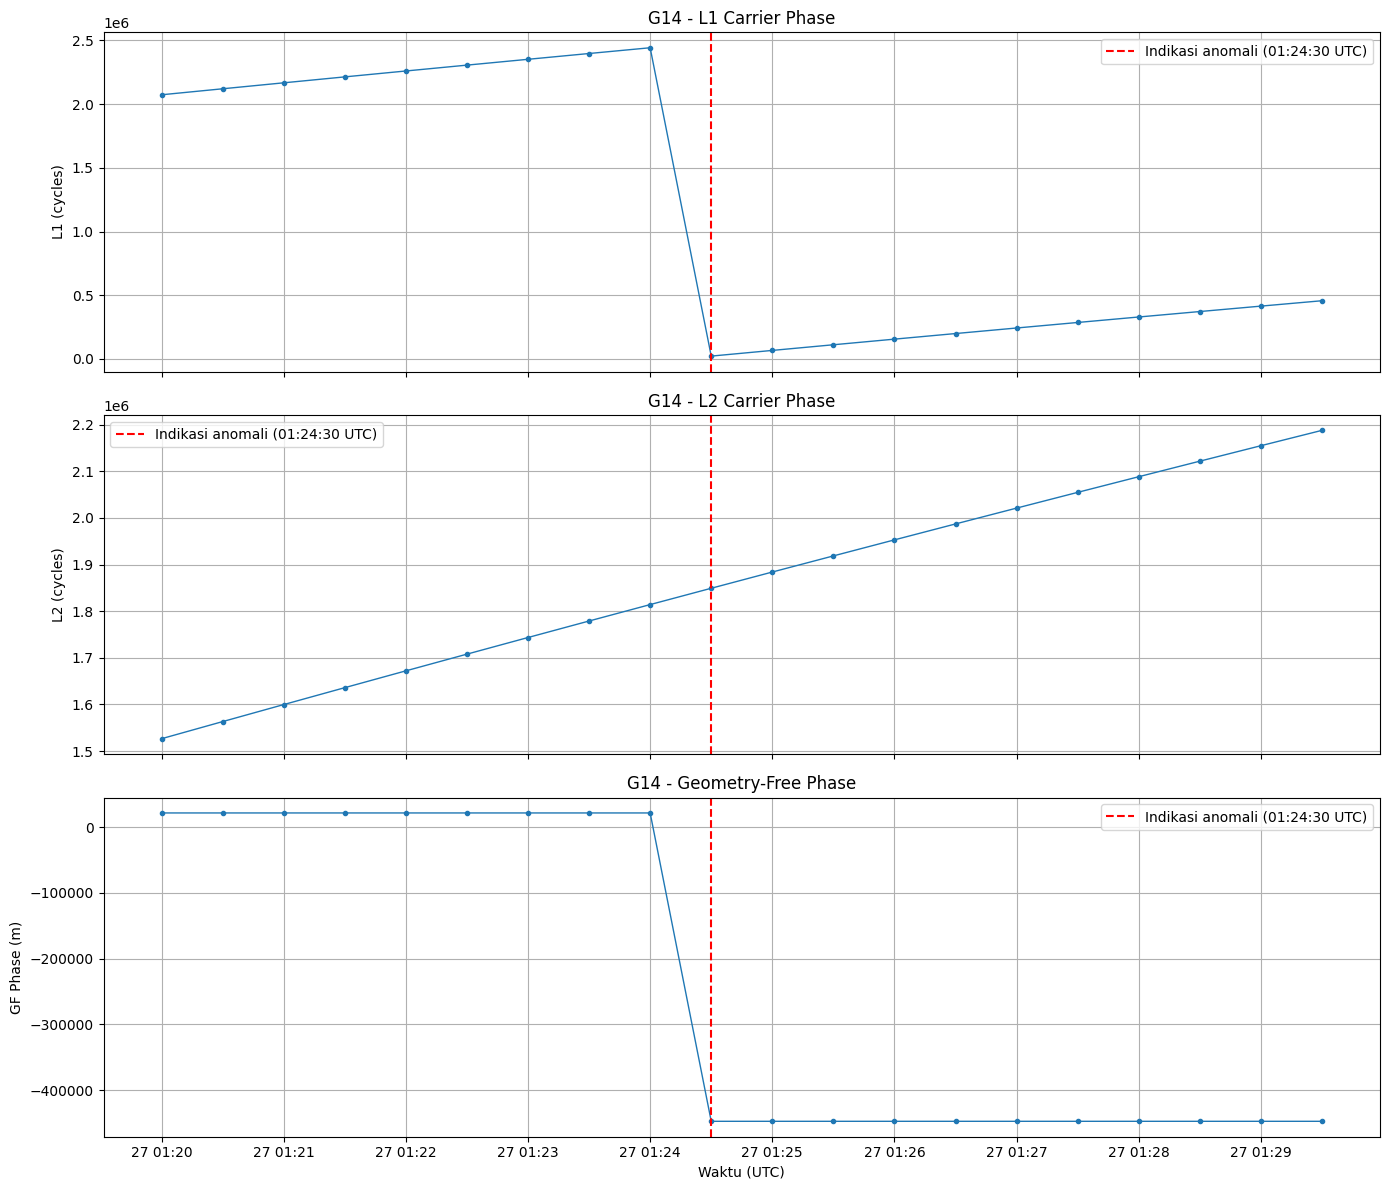

In [72]:
# Ambil data G14 pada rentang waktu anomali
awal_plot = pd.Timestamp("2003-10-27 01:20:00")
akhir_plot = pd.Timestamp("2003-10-27 01:30:00")

df_plot_g14 = df_g14_valid[
    (df_g14_valid["Waktu"] >= awal_plot) &
    (df_g14_valid["Waktu"] <= akhir_plot)
].copy()

# Buat grafik
fig, ax = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Grafik L1
ax[0].plot(
    df_plot_g14["Waktu"],
    df_plot_g14["L1"],
    marker=".",
    linewidth=1
)
ax[0].set_ylabel("L1 (cycles)")
ax[0].set_title("G14 - L1 Carrier Phase")
ax[0].grid(True)

# Grafik L2
ax[1].plot(
    df_plot_g14["Waktu"],
    df_plot_g14["L2"],
    marker=".",
    linewidth=1
)
ax[1].set_ylabel("L2 (cycles)")
ax[1].set_title("G14 - L2 Carrier Phase")
ax[1].grid(True)

# Grafik Geometry-Free Phase
ax[2].plot(
    df_plot_g14["Waktu"],
    df_plot_g14["GF_fase_m"],
    marker=".",
    linewidth=1
)
ax[2].set_ylabel("GF Phase (m)")
ax[2].set_xlabel("Waktu (UTC)")
ax[2].set_title("G14 - Geometry-Free Phase")
ax[2].grid(True)

# Tandai waktu anomali
waktu_anomali = pd.Timestamp("2003-10-27 01:24:30.007")

for a in ax:
    a.axvline(
        waktu_anomali,
        color="red",
        linestyle="--",
        label="Indikasi anomali (01:24:30 UTC)"
    )
    a.legend()

plt.tight_layout()
plt.show()

In [73]:
# Tampilkan data G14 di sekitar waktu anomali
kolom = [
    "Waktu",
    "L1",
    "L2",
    "GF_fase_m"
]

display(
    df_plot_g14[kolom]
    .round(4)
    .to_string(index=False)
)

C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\2954047397.py:11: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(4)


'                  Waktu          L1          L2    GF_fase_m\n2003-10-27 01:20:00.007 2072898.494 1526567.353   21656.1287\n2003-10-27 01:20:30.007 2119979.170 1563253.534   21656.1433\n2003-10-27 01:21:00.007 2166788.848 1599728.556   21656.1560\n2003-10-27 01:21:30.007 2213324.940 1635990.380   21656.1721\n2003-10-27 01:22:00.008 2259586.162 1672038.008   21656.1910\n2003-10-27 01:22:30.007 2305572.315 1707871.348   21656.1973\n2003-10-27 01:23:00.008 2351287.560 1743493.535   21656.2173\n2003-10-27 01:23:30.007 2396736.399 1778908.131   21656.2378\n2003-10-27 01:24:00.008 2441915.785 1814112.792   21656.2513\n2003-10-27 01:24:30.007   22419.717 1849109.804 -447305.1696\n2003-10-27 01:25:00.008   67063.087 1883896.761 -447305.1489\n2003-10-27 01:25:30.007  111438.628 1918475.056 -447305.1371\n2003-10-27 01:26:00.008  155549.076 1952846.809 -447305.1310\n2003-10-27 01:26:30.007  199391.544 1987009.690 -447305.1112\n2003-10-27 01:27:00.008  242969.239 2020966.260 -447305.0928\n2003-10

In [74]:
df_g14_increment = df_plot_g14.copy()

df_g14_increment["Delta_L1"] = (
    df_g14_increment["L1"].diff()
)

df_g14_increment["Delta_L2"] = (
    df_g14_increment["L2"].diff()
)

df_g14_increment["Delta_GF"] = (
    df_g14_increment["GF_fase_m"].diff()
)

display(
    df_g14_increment[
        [
            "Waktu",
            "Delta_L1",
            "Delta_L2",
            "Delta_GF"
        ]
    ].round(4).to_string(index=False)
)

C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\2142740812.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4).to_string(index=False)


'                  Waktu     Delta_L1  Delta_L2     Delta_GF\n2003-10-27 01:20:00.007          NaN       NaN          NaN\n2003-10-27 01:20:30.007    47080.676 36686.181       0.0147\n2003-10-27 01:21:00.007    46809.678 36475.022       0.0126\n2003-10-27 01:21:30.007    46536.092 36261.824       0.0161\n2003-10-27 01:22:00.008    46261.222 36047.628       0.0189\n2003-10-27 01:22:30.007    45986.153 35833.340       0.0063\n2003-10-27 01:23:00.008    45715.245 35622.187       0.0200\n2003-10-27 01:23:30.007    45448.839 35414.596       0.0205\n2003-10-27 01:24:00.008    45179.386 35204.661       0.0135\n2003-10-27 01:24:30.007 -2419496.068 34997.012 -468961.4209\n2003-10-27 01:25:00.008    44643.370 34786.957       0.0207\n2003-10-27 01:25:30.007    44375.541 34578.295       0.0119\n2003-10-27 01:26:00.008    44110.448 34371.753       0.0060\n2003-10-27 01:26:30.007    43842.468 34162.881       0.0198\n2003-10-27 01:27:00.008    43577.695 33956.570       0.0184\n2003-10-27 01:27:30.007

In [75]:
# Hitung perubahan pseudorange G14
df_g14_code = df_plot_g14.copy()

df_g14_code["Delta_C1"] = df_g14_code["C1"].diff()
df_g14_code["Delta_P2"] = df_g14_code["P2"].diff()

df_g14_code["GF_code_m"] = (
    df_g14_code["C1"] - df_g14_code["P2"]
)

df_g14_code["Delta_GF_code"] = (
    df_g14_code["GF_code_m"].diff()
)

display(
    df_g14_code[
        [
            "Waktu",
            "Delta_C1",
            "Delta_P2",
            "GF_code_m",
            "Delta_GF_code"
        ]
    ].round(4).to_string(index=False)
)

C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\1163805681.py:24: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4).to_string(index=False)


'                  Waktu  Delta_C1  Delta_P2  GF_code_m  Delta_GF_code\n2003-10-27 01:20:00.007       NaN       NaN     -6.809            NaN\n2003-10-27 01:20:30.007  8958.899  8960.133     -8.043         -1.234\n2003-10-27 01:21:00.007  8907.773  8907.258     -7.528          0.515\n2003-10-27 01:21:30.007  8855.508  8857.054     -9.074         -1.546\n2003-10-27 01:22:00.008  8804.622  8802.181     -6.633          2.441\n2003-10-27 01:22:30.007  8749.492  8750.586     -7.727         -1.094\n2003-10-27 01:23:00.008  8700.258  8698.484     -5.953          1.774\n2003-10-27 01:23:30.007  8647.172  8649.614     -8.395         -2.442\n2003-10-27 01:24:00.008  8598.102  8598.207     -8.500         -0.105\n2003-10-27 01:24:30.007  8546.890  8544.285     -5.895          2.605\n2003-10-27 01:25:00.008  8494.774  8498.222     -9.343         -3.448\n2003-10-27 01:25:30.007  8445.453  8444.305     -8.195          1.148\n2003-10-27 01:26:00.008  8392.969  8390.867     -6.093          2.102\n2003-

In [76]:
# ============================================================
# RINGKASAN QC G14 - 27 OKTOBER 2003
# ============================================================

# 1. Ambil seluruh observasi G14, termasuk epoch yang tidak lengkap
df_g14_obs_all = pd.DataFrame({
    "Waktu": pd.DatetimeIndex(obs.time.values),
    "L1": obs["L1"].sel(sv="G14").values,
    "L2": obs["L2"].sel(sv="G14").values,
    "C1": obs["C1"].sel(sv="G14").values,
    "P2": obs["P2"].sel(sv="G14").values
})

# 2. Ambil seluruh informasi LLI G14
df_g14_lli = df_lli_semua[
    df_lli_semua["SV"] == "G14"
].copy()

# 3. Gabungkan berdasarkan waktu
df_g14_qc = pd.merge(
    df_g14_obs_all,
    df_g14_lli[
        ["Waktu", "LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]
    ],
    on="Waktu",
    how="left"
)

# 4. Periksa keberhasilan penggabungan
print("Jumlah epoch observasi :", len(df_g14_obs_all))
print("Jumlah epoch data LLI  :", len(df_g14_lli))
print("LLI berhasil dipasangkan:", df_g14_qc["LLI_L1"].notna().sum())

# 5. Identifikasi flag loss-of-lock (bit 0)
df_g14_qc["Flag_L1"] = (
    (df_g14_qc["LLI_L1"].fillna(0).astype(int) & 1) != 0
)

df_g14_qc["Flag_L2"] = (
    (df_g14_qc["LLI_L2"].fillna(0).astype(int) & 1) != 0
)

df_g14_qc["Ada_Flag_LLI"] = (
    df_g14_qc["Flag_L1"] | df_g14_qc["Flag_L2"]
)

# 6. Hitung Geometry-Free Phase
df_g14_qc["GF_fase_m"] = (
    lambda1 * df_g14_qc["L1"]
    - lambda2 * df_g14_qc["L2"]
)

# 7. Hitung interval dan perubahan GF phase
df_g14_qc["Interval_detik"] = (
    df_g14_qc["Waktu"].diff().dt.total_seconds()
)

df_g14_qc["Delta_GF_m"] = (
    df_g14_qc["GF_fase_m"].diff()
)

# 8. Klasifikasikan interval pengamatan
df_g14_qc["Status_interval"] = np.select(
    [
        df_g14_qc["Interval_detik"].isna(),
        df_g14_qc["Interval_detik"].between(29.5, 30.5),
        df_g14_qc["Interval_detik"] > 30.5
    ],
    [
        "Epoch pertama",
        "Kontinu (sekitar 30 detik)",
        "Data gap"
    ],
    default="Interval tidak normal"
)

# 9. Ringkasan umum
print("\n===== RINGKASAN QC G14 =====")
print("Total epoch:", len(df_g14_qc))
print("Flag LLI L1:", df_g14_qc["Flag_L1"].sum())
print("Flag LLI L2:", df_g14_qc["Flag_L2"].sum())
print("Epoch dengan flag LLI:", df_g14_qc["Ada_Flag_LLI"].sum())

print("\nDistribusi interval:")
display(df_g14_qc["Status_interval"].value_counts())

# 10. Tampilkan seluruh epoch yang memiliki flag LLI
print("\n===== EPOCH DENGAN FLAG LLI =====")

display(
    df_g14_qc.loc[
        df_g14_qc["Ada_Flag_LLI"],
        [
            "Waktu",
            "LLI_L1",
            "LLI_L2",
            "Flag_L1",
            "Flag_L2",
            "Interval_detik",
            "Delta_GF_m",
            "Status_interval"
        ]
    ].round(4).to_string(index=False)
)

Jumlah epoch observasi : 2878
Jumlah epoch data LLI  : 1070
LLI berhasil dipasangkan: 774

===== RINGKASAN QC G14 =====
Total epoch: 2878
Flag LLI L1: 3
Flag LLI L2: 5
Epoch dengan flag LLI: 7

Distribusi interval:


Status_interval
Kontinu (sekitar 30 detik)    2877
Epoch pertama                    1
Name: count, dtype: int64


===== EPOCH DENGAN FLAG LLI =====


C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\1201589997.py:103: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4).to_string(index=False)


'                  Waktu  LLI_L1  LLI_L2  Flag_L1  Flag_L2  Interval_detik  Delta_GF_m            Status_interval\n2003-10-27 00:00:30.000     5.0     5.0     True     True             NaN         NaN              Epoch pertama\n2003-10-27 01:00:30.006     5.0     0.0     True    False          30.000         NaN Kontinu (sekitar 30 detik)\n2003-10-27 01:01:30.006     4.0     5.0    False     True          30.000         NaN Kontinu (sekitar 30 detik)\n2003-10-27 02:14:00.012     4.0     5.0    False     True          30.000         NaN Kontinu (sekitar 30 detik)\n2003-10-27 20:35:00.110     4.0     5.0    False     True          30.001         NaN Kontinu (sekitar 30 detik)\n2003-10-27 23:01:00.123     5.0     0.0     True    False          30.000         NaN Kontinu (sekitar 30 detik)\n2003-10-27 23:02:00.123     4.0     5.0    False     True          30.000         NaN Kontinu (sekitar 30 detik)'

In [77]:
# Samakan tipe data timestamp menjadi datetime64[ns]
df_obs_match["Waktu"] = pd.to_datetime(
    df_obs_match["Waktu"]
).astype("datetime64[ns]")

df_lli_match["Waktu"] = pd.to_datetime(
    df_lli_match["Waktu"]
).astype("datetime64[ns]")

# Pastikan kedua dataframe terurut berdasarkan waktu
df_obs_match = df_obs_match.sort_values("Waktu").reset_index(drop=True)
df_lli_match = df_lli_match.sort_values("Waktu").reset_index(drop=True)

# Periksa tipe data
print("Tipe waktu observasi:", df_obs_match["Waktu"].dtype)
print("Tipe waktu LLI:", df_lli_match["Waktu"].dtype)

NameError: name 'df_obs_match' is not defined

In [ ]:
df_g14_qc = pd.merge_asof(
    df_obs_match,
    df_lli_match,
    on="Waktu",
    direction="nearest",
    tolerance=pd.Timedelta(seconds=1)
)

print("Jumlah epoch observasi :", len(df_g14_qc))
print("Jumlah epoch LLI       :", len(df_lli_match))
print("Berhasil dipasangkan   :", df_g14_qc["LLI_L1"].notna().sum())
print("Tidak berhasil         :", df_g14_qc["LLI_L1"].isna().sum())

Jumlah epoch observasi : 2878
Jumlah epoch LLI       : 1070
Berhasil dipasangkan   : 1070
Tidak berhasil         : 1808


In [ ]:
# ============================================================
# ANALISIS ULANG LLI DAN GEOMETRY-FREE PHASE G14
# ============================================================

# 1. Konversi nilai LLI menjadi numerik
df_g14_qc["LLI_L1"] = pd.to_numeric(
    df_g14_qc["LLI_L1"], errors="coerce"
)

df_g14_qc["LLI_L2"] = pd.to_numeric(
    df_g14_qc["LLI_L2"], errors="coerce"
)

# 2. Identifikasi bit 0 (indikasi loss of lock)
df_g14_qc["Flag_L1"] = (
    (df_g14_qc["LLI_L1"].fillna(0).astype(int) & 1) != 0
)

df_g14_qc["Flag_L2"] = (
    (df_g14_qc["LLI_L2"].fillna(0).astype(int) & 1) != 0
)

df_g14_qc["Ada_Flag_LLI"] = (
    df_g14_qc["Flag_L1"] | df_g14_qc["Flag_L2"]
)

# 3. Hitung Geometry-Free Phase
df_g14_qc["GF_fase_m"] = (
    lambda1 * df_g14_qc["L1"]
    - lambda2 * df_g14_qc["L2"]
)

# 4. Hitung interval dan perubahan GF phase
df_g14_qc["Interval_detik"] = (
    df_g14_qc["Waktu"].diff().dt.total_seconds()
)

df_g14_qc["Delta_GF_m"] = (
    df_g14_qc["GF_fase_m"].diff()
)

# 5. Tandai apakah fase L1 dan L2 lengkap
df_g14_qc["Fase_lengkap"] = (
    df_g14_qc["L1"].notna() &
    df_g14_qc["L2"].notna()
)

# 6. Tampilkan ringkasan
print("===== RINGKASAN LLI G14 =====")
print("Jumlah data LLI:", df_g14_qc["LLI_L1"].notna().sum())
print("Flag L1:", df_g14_qc["Flag_L1"].sum())
print("Flag L2:", df_g14_qc["Flag_L2"].sum())
print("Epoch dengan flag LLI:", df_g14_qc["Ada_Flag_LLI"].sum())

# 7. Tampilkan semua epoch dengan indikasi LLI
print("\n===== DETAIL EPOCH DENGAN FLAG LLI =====")

display(
    df_g14_qc.loc[
        df_g14_qc["Ada_Flag_LLI"],
        [
            "Waktu",
            "LLI_L1",
            "LLI_L2",
            "Flag_L1",
            "Flag_L2",
            "L1",
            "L2",
            "Interval_detik",
            "Delta_GF_m",
            "Fase_lengkap"
        ]
    ].round(4).to_string(index=False)
)

===== RINGKASAN LLI G14 =====
Jumlah data LLI: 1070
Flag L1: 5
Flag L2: 6
Epoch dengan flag LLI: 10

===== DETAIL EPOCH DENGAN FLAG LLI =====


C:\Users\ACER\AppData\Local\Temp\ipykernel_23144\979249969.py:73: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4).to_string(index=False)


'                  Waktu  LLI_L1  LLI_L2  Flag_L1  Flag_L2           L1          L2  Interval_detik   Delta_GF_m  Fase_lengkap\n2003-10-27 00:00:30.000     5.0     5.0     True     True 10350212.869 3216363.323             NaN          NaN          True\n2003-10-27 01:00:30.006     5.0     0.0     True    False    21297.893         NaN          30.000          NaN         False\n2003-10-27 01:01:30.006     4.0     5.0    False     True   136809.278   17929.254          30.000          NaN          True\n2003-10-27 01:24:30.007     5.0     4.0     True    False    22419.717 1849109.804          29.999 -468961.4209          True\n2003-10-27 02:01:30.010     4.0     5.0    False     True    53952.982      -0.949          29.999          NaN          True\n2003-10-27 02:14:00.012     4.0     5.0    False     True   678372.738    9528.391          30.000          NaN          True\n2003-10-27 20:33:30.109     5.0     0.0     True    False      134.616         NaN          29.999          Na

In [ ]:
# ============================================================
# KLASIFIKASI 10 EPOCH DENGAN INDIKASI LLI G14
# ============================================================

df_g14_qc["Fase_sebelumnya_lengkap"] = (
    df_g14_qc["Fase_lengkap"].shift(1).fillna(False)
)

df_g14_qc["Interval_normal"] = (
    df_g14_qc["Interval_detik"].between(29.5, 30.5)
)

df_g14_qc["GF_dapat_dievaluasi"] = (
    df_g14_qc["Ada_Flag_LLI"] &
    df_g14_qc["Fase_lengkap"] &
    df_g14_qc["Fase_sebelumnya_lengkap"] &
    df_g14_qc["Interval_normal"]
)

# Ambil hanya epoch yang memiliki indikasi LLI
df_klasifikasi_g14 = df_g14_qc.loc[
    df_g14_qc["Ada_Flag_LLI"],
    [
        "Waktu",
        "LLI_L1",
        "LLI_L2",
        "L1",
        "L2",
        "Fase_sebelumnya_lengkap",
        "Fase_lengkap",
        "Interval_detik",
        "Delta_GF_m",
        "GF_dapat_dievaluasi"
    ]
].copy()

display(df_klasifikasi_g14.to_string(index=False))

print("\n===== RINGKASAN =====")
print(
    "GF dapat dievaluasi:",
    df_klasifikasi_g14["GF_dapat_dievaluasi"].sum()
)

print(
    "GF tidak dapat dievaluasi:",
    (~df_klasifikasi_g14["GF_dapat_dievaluasi"]).sum()
)

'                  Waktu  LLI_L1  LLI_L2           L1          L2 Fase_sebelumnya_lengkap  Fase_lengkap  Interval_detik     Delta_GF_m  GF_dapat_dievaluasi\n2003-10-27 00:00:30.000     5.0     5.0 10350212.869 3216363.323                   False          True             NaN            NaN                False\n2003-10-27 01:00:30.006     5.0     0.0    21297.893         NaN                   False         False          30.000            NaN                False\n2003-10-27 01:01:30.006     4.0     5.0   136809.278   17929.254                   False          True          30.000            NaN                False\n2003-10-27 01:24:30.007     5.0     4.0    22419.717 1849109.804                    True          True          29.999 -468961.420871                 True\n2003-10-27 02:01:30.010     4.0     5.0    53952.982      -0.949                   False          True          29.999            NaN                False\n2003-10-27 02:14:00.012     4.0     5.0   678372.738    9528.39


===== RINGKASAN =====
GF dapat dievaluasi: 1
GF tidak dapat dievaluasi: 9


In [ ]:
# ============================================================
# PENANDAAN ANOMALI DAN PEMBAGIAN PHASE ARC G14
# ============================================================

df_g14_clean = df_g14_qc.copy()

# Waktu anomali yang teridentifikasi
waktu_anomali = pd.Timestamp("2003-10-27 01:24:30.007")

# Tandai anomali
df_g14_clean["Anomali_GF"] = (
    df_g14_clean["Waktu"] == waktu_anomali
)

# Tandai epoch dengan fase lengkap
df_g14_clean["Fase_lengkap"] = (
    df_g14_clean["L1"].notna() &
    df_g14_clean["L2"].notna()
)

# Tandai batas arc akibat interval pengamatan
df_g14_clean["Gap"] = (
    df_g14_clean["Interval_detik"] > 30.5
)

# Tandai batas arc akibat anomali
df_g14_clean["Batas_arc"] = (
    df_g14_clean["Gap"] |
    df_g14_clean["Anomali_GF"]
)

# Bentuk ID arc baru setelah batas arc
df_g14_clean["Arc_ID"] = (
    df_g14_clean["Batas_arc"]
    .shift(1, fill_value=False)
    .cumsum() + 1
)

# Keluarkan epoch anomali dari pemrosesan fase
df_g14_clean.loc[
    df_g14_clean["Anomali_GF"],
    "Arc_ID"
] = pd.NA

# Tampilkan sekitar waktu anomali
display(
    df_g14_clean.loc[
        (df_g14_clean["Waktu"] >= "2003-10-27 01:20:00") &
        (df_g14_clean["Waktu"] <= "2003-10-27 01:30:00"),
        [
            "Waktu",
            "L1",
            "L2",
            "Anomali_GF",
            "Gap",
            "Arc_ID"
        ]
    ].to_string(index=False)
)

'                  Waktu          L1          L2  Anomali_GF   Gap  Arc_ID\n2003-10-27 01:20:00.007 2072898.494 1526567.353       False False     1.0\n2003-10-27 01:20:30.007 2119979.170 1563253.534       False False     1.0\n2003-10-27 01:21:00.007 2166788.848 1599728.556       False False     1.0\n2003-10-27 01:21:30.007 2213324.940 1635990.380       False False     1.0\n2003-10-27 01:22:00.008 2259586.162 1672038.008       False False     1.0\n2003-10-27 01:22:30.007 2305572.315 1707871.348       False False     1.0\n2003-10-27 01:23:00.008 2351287.560 1743493.535       False False     1.0\n2003-10-27 01:23:30.007 2396736.399 1778908.131       False False     1.0\n2003-10-27 01:24:00.008 2441915.785 1814112.792       False False     1.0\n2003-10-27 01:24:30.007   22419.717 1849109.804        True False     NaN\n2003-10-27 01:25:00.008   67063.087 1883896.761       False False     2.0\n2003-10-27 01:25:30.007  111438.628 1918475.056       False False     2.0\n2003-10-27 01:26:00.008 

In [ ]:
# ============================================================
# RINGKASAN PHASE ARC G14 SELAMA DOY300
# ============================================================

# Ambil data yang memiliki fase lengkap dan Arc_ID
df_arc_summary = df_g14_clean.dropna(
    subset=["Arc_ID", "L1", "L2"]
).copy()

# Ringkasan setiap arc
ringkasan_arc = (
    df_arc_summary
    .groupby("Arc_ID")
    .agg(
        Waktu_awal=("Waktu", "min"),
        Waktu_akhir=("Waktu", "max"),
        Jumlah_epoch=("Waktu", "count")
    )
    .reset_index()
)

ringkasan_arc["Durasi_menit"] = (
    ringkasan_arc["Waktu_akhir"] -
    ringkasan_arc["Waktu_awal"]
).dt.total_seconds() / 60

print("Jumlah phase arc:", len(ringkasan_arc))
print("Jumlah epoch fase lengkap:", len(df_arc_summary))

display(ringkasan_arc.round(2))

Jumlah phase arc: 2
Jumlah epoch fase lengkap: 1057


C:\Users\ACER\AppData\Local\Temp\ipykernel_23144\1532768435.py:30: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(ringkasan_arc.round(2))


,Arc_ID,Waktu_awal,Waktu_akhir,Jumlah_epoch,Durasi_menit
0,1.0,2003-10-27 00:00:30.000,2003-10-27 01:24:00.008,108,83.5
1,2.0,2003-10-27 01:25:00.008,2003-10-27 23:59:00.128,949,1354.0


In [ ]:
# ============================================================
# SEGMENTASI PHASE ARC G14 BERDASARKAN OBSERVASI VALID
# ============================================================

# 1. Gunakan data G14 dengan observasi lengkap
df_g14_arc_correct = df_g14_valid.copy()

df_g14_arc_correct = (
    df_g14_arc_correct
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# 2. Hitung interval antar-observasi G14
df_g14_arc_correct["Interval_detik"] = (
    df_g14_arc_correct["Waktu"]
    .diff()
    .dt.total_seconds()
)

# 3. Tandai gap pengamatan
df_g14_arc_correct["Gap"] = (
    df_g14_arc_correct["Interval_detik"] > 30.5
)

# 4. Tandai anomali fase G14
waktu_anomali = pd.Timestamp("2003-10-27 01:24:30.007")

df_g14_arc_correct["Anomali_GF"] = (
    df_g14_arc_correct["Waktu"] == waktu_anomali
)

# 5. Tentukan batas phase arc
df_g14_arc_correct["Batas_arc"] = (
    df_g14_arc_correct["Gap"] |
    df_g14_arc_correct["Anomali_GF"]
)

# 6. Buat ID phase arc
df_g14_arc_correct["Arc_ID"] = (
    df_g14_arc_correct["Batas_arc"].cumsum() + 1
)

# 7. Keluarkan epoch anomali dari pemrosesan fase
df_g14_arc_correct.loc[
    df_g14_arc_correct["Anomali_GF"],
    "Arc_ID"
] = pd.NA

# 8. Buat ringkasan setiap phase arc
df_arc_summary_correct = (
    df_g14_arc_correct
    .dropna(subset=["Arc_ID"])
    .groupby("Arc_ID")
    .agg(
        Waktu_awal=("Waktu", "min"),
        Waktu_akhir=("Waktu", "max"),
        Jumlah_epoch=("Waktu", "count")
    )
    .reset_index()
)

df_arc_summary_correct["Durasi_menit"] = (
    df_arc_summary_correct["Waktu_akhir"] -
    df_arc_summary_correct["Waktu_awal"]
).dt.total_seconds() / 60

print("Jumlah phase arc:", len(df_arc_summary_correct))
print(
    "Jumlah epoch fase yang digunakan:",
    df_g14_arc_correct["Arc_ID"].notna().sum()
)
print(
    "Jumlah epoch anomali yang dikeluarkan:",
    df_g14_arc_correct["Anomali_GF"].sum()
)

display(df_arc_summary_correct)

Jumlah phase arc: 7
Jumlah epoch fase yang digunakan: 1057
Jumlah epoch anomali yang dikeluarkan: 1


,Arc_ID,Waktu_awal,Waktu_akhir,Jumlah_epoch,Durasi_menit
0,1.0,2003-10-27 00:00:30.000,2003-10-27 00:31:00.003,62,30.500050
1,2.0,2003-10-27 01:01:30.006,2003-10-27 01:24:00.008,46,22.500033
2,3.0,2003-10-27 01:25:00.008,2003-10-27 01:38:00.009,27,13.000017
3,4.0,2003-10-27 02:01:30.010,2003-10-27 02:13:00.012,24,11.500033
4,5.0,2003-10-27 02:14:00.012,2003-10-27 06:24:00.034,501,250.000367
5,6.0,2003-10-27 20:35:00.110,2003-10-27 22:55:30.121,282,140.500183
6,7.0,2003-10-27 23:02:00.123,2003-10-27 23:59:00.128,115,57.000083


In [ ]:
# ============================================================
# VALIDASI KONTINUITAS SETIAP PHASE ARC G14
# ============================================================

df_cek_arc = df_g14_arc_correct.dropna(
    subset=["Arc_ID"]
).copy()

# Interval di dalam masing-masing arc
df_cek_arc["Interval_dalam_arc"] = (
    df_cek_arc.groupby("Arc_ID")["Waktu"]
    .diff()
    .dt.total_seconds()
)

# Ringkasan kontinuitas
validasi_arc = (
    df_cek_arc.groupby("Arc_ID")
    .agg(
        Jumlah_epoch=("Waktu", "count"),
        Interval_min=("Interval_dalam_arc", "min"),
        Interval_maks=("Interval_dalam_arc", "max"),
        Jumlah_gap_internal=(
            "Interval_dalam_arc",
            lambda x: (x > 30.5).sum()
        )
    )
    .reset_index()
)

print("===== VALIDASI KONTINUITAS PHASE ARC =====")
display(validasi_arc)

print(
    "\nTotal gap internal:",
    validasi_arc["Jumlah_gap_internal"].sum()
)

===== VALIDASI KONTINUITAS PHASE ARC =====


,Arc_ID,Jumlah_epoch,Interval_min,Interval_maks,Jumlah_gap_internal
0,1.0,62,29.999,30.002,0
1,2.0,46,29.999,30.001,0
2,3.0,27,29.999,30.001,0
3,4.0,24,29.999,30.001,0
4,5.0,501,29.999,30.002,0
5,6.0,282,29.999,30.002,0
6,7.0,115,29.999,30.002,0



Total gap internal: 0


In [ ]:
# ============================================================
# PEMERIKSAAN KUALITAS FASE G14 - ARC 5
# ============================================================

# 1. Ambil data Arc 5
df_arc5 = df_g14_arc_correct[
    df_g14_arc_correct["Arc_ID"] == 5
].copy()

df_arc5 = (
    df_arc5
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# 2. Hitung Geometry-Free phase
df_arc5["GF_fase_m"] = (
    lambda1 * df_arc5["L1"]
    - lambda2 * df_arc5["L2"]
)

# 3. Hitung interval dan perubahan GF phase
df_arc5["Interval_detik"] = (
    df_arc5["Waktu"].diff().dt.total_seconds()
)

df_arc5["Delta_GF_m"] = (
    df_arc5["GF_fase_m"].diff()
)

# 4. Ambil data LLI G14
df_lli_arc5 = df_g14_qc.loc[
    df_g14_qc["LLI_L1"].notna() |
    df_g14_qc["LLI_L2"].notna(),
    ["Waktu", "LLI_L1", "LLI_L2", "Flag_L1", "Flag_L2"]
].copy()

# Samakan tipe waktu
df_arc5["Waktu"] = pd.to_datetime(
    df_arc5["Waktu"]
).astype("datetime64[ns]")

df_lli_arc5["Waktu"] = pd.to_datetime(
    df_lli_arc5["Waktu"]
).astype("datetime64[ns]")

# 5. Cocokkan data LLI dengan observasi Arc 5
df_arc5 = pd.merge_asof(
    df_arc5.sort_values("Waktu"),
    df_lli_arc5.sort_values("Waktu"),
    on="Waktu",
    direction="nearest",
    tolerance=pd.Timedelta(seconds=1)
)

# 6. Identifikasi epoch dengan indikasi LLI
df_arc5["Ada_Flag_LLI"] = (
    df_arc5["Flag_L1"].fillna(False) |
    df_arc5["Flag_L2"].fillna(False)
)

print("===== RINGKASAN ARC 5 =====")
print("Jumlah epoch:", len(df_arc5))
print("Waktu awal:", df_arc5["Waktu"].min())
print("Waktu akhir:", df_arc5["Waktu"].max())
print("Epoch dengan flag LLI:", df_arc5["Ada_Flag_LLI"].sum())

print("\n===== EPOCH DENGAN FLAG LLI =====")

display(
    df_arc5.loc[
        df_arc5["Ada_Flag_LLI"],
        [
            "Waktu", "LLI_L1", "LLI_L2",
            "L1", "L2", "GF_fase_m",
            "Interval_detik", "Delta_GF_m"
        ]
    ].to_string(index=False)
)

print("\n===== 10 PERUBAHAN GF PHASE TERBESAR =====")

display(
    df_arc5.loc[
        df_arc5["Delta_GF_m"].notna()
    ]
    .assign(
        Abs_Delta_GF=lambda x: x["Delta_GF_m"].abs()
    )
    .nlargest(10, "Abs_Delta_GF")[
        [
            "Waktu", "Interval_detik",
            "Delta_GF_m", "LLI_L1", "LLI_L2"
        ]
    ].to_string(index=False)
)

===== RINGKASAN ARC 5 =====
Jumlah epoch: 501
Waktu awal: 2003-10-27 02:14:00.012000
Waktu akhir: 2003-10-27 06:24:00.034000
Epoch dengan flag LLI: 1

===== EPOCH DENGAN FLAG LLI =====


'                  Waktu  LLI_L1  LLI_L2         L1       L2     GF_fase_m  Interval_detik  Delta_GF_m\n2003-10-27 02:14:00.012     4.0     5.0 678372.738 9528.391 126763.109441             NaN         NaN'


===== 10 PERUBAHAN GF PHASE TERBESAR =====


'                  Waktu  Interval_detik  Delta_GF_m  LLI_L1  LLI_L2\n2003-10-27 05:36:00.030          30.000    0.032927     4.0     4.0\n2003-10-27 06:07:00.033          30.000    0.032493     4.0     4.0\n2003-10-27 06:05:00.033          30.001    0.031475     4.0     4.0\n2003-10-27 06:03:00.032          30.000    0.030828     4.0     4.0\n2003-10-27 06:03:30.032          30.000    0.029350     4.0     4.0\n2003-10-27 06:02:00.032          30.000    0.029061     4.0     4.0\n2003-10-27 05:47:30.030          29.999    0.028246     4.0     4.0\n2003-10-27 05:48:30.030          29.999    0.027840     4.0     4.0\n2003-10-27 05:35:00.030          30.000    0.027282     4.0     4.0\n2003-10-27 06:10:00.033          30.000    0.027111     4.0     4.0'

In [ ]:
# ============================================================
# PERHITUNGAN RELATIVE STEC G14 - ARC 5
# ============================================================

# 1. Konstanta frekuensi GPS
f1 = 1575.42e6
f2 = 1227.60e6

# 2. Faktor konversi GF phase ke TECU
konversi_gf_tecu = (
    40.3 * (1 / f2**2 - 1 / f1**2) * 1e16
)

print("Faktor konversi GF ke TECU:",
      konversi_gf_tecu, "m/TECU")

# 3. Salin data Arc 5
df_stec_arc5 = df_arc5.copy()

# 4. Hitung GF phase
df_stec_arc5["GF_fase_m"] = (
    lambda1 * df_stec_arc5["L1"]
    - lambda2 * df_stec_arc5["L2"]
)

# 5. Hitung perubahan GF phase
df_stec_arc5["Delta_GF_m"] = (
    df_stec_arc5["GF_fase_m"].diff()
)

# 6. Hitung perubahan STEC
df_stec_arc5["Delta_STEC_TECU"] = (
    df_stec_arc5["Delta_GF_m"] / konversi_gf_tecu
)

# 7. Hitung STEC relatif dengan titik awal = 0 TECU
df_stec_arc5["STEC_Relatif_TECU"] = (
    df_stec_arc5["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

# 8. Tampilkan hasil
print("\n===== HASIL PERHITUNGAN STEC ARC 5 =====")

display(
    df_stec_arc5[
        [
            "Waktu",
            "GF_fase_m",
            "Delta_GF_m",
            "Delta_STEC_TECU",
            "STEC_Relatif_TECU"
        ]
    ].head(10)
)

print("\n===== STATISTIK STEC RELATIF =====")
display(
    df_stec_arc5["STEC_Relatif_TECU"].describe()
)

Faktor konversi GF ke TECU: 0.10504595284873212 m/TECU

===== HASIL PERHITUNGAN STEC ARC 5 =====


,Waktu,GF_fase_m,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU
0,2003-10-27 02:14:00.012,126763.109441,NaN,NaN,0.000000
1,2003-10-27 02:14:30.012,126763.097604,-0.011836,-0.112677,-0.112677
2,2003-10-27 02:15:00.012,126763.087744,-0.009860,-0.093867,-0.206544
3,2003-10-27 02:15:30.012,126763.083358,-0.004386,-0.041756,-0.248300
4,2003-10-27 02:16:00.012,126763.075736,-0.007621,-0.072552,-0.320852
5,2003-10-27 02:16:30.012,126763.069038,-0.006698,-0.063766,-0.384618
6,2003-10-27 02:17:00.012,126763.061398,-0.007640,-0.072733,-0.457350
7,2003-10-27 02:17:30.012,126763.049320,-0.012077,-0.114972,-0.572322
8,2003-10-27 02:18:00.012,126763.044424,-0.004897,-0.046617,-0.618939
9,2003-10-27 02:18:30.012,126763.031810,-0.012613,-0.120074,-0.739013



===== STATISTIK STEC RELATIF =====


count    501.000000
mean       8.273518
std       12.639322
min       -3.438552
25%       -1.904852
50%        2.295115
75%       15.317857
max       38.129582
Name: STEC_Relatif_TECU, dtype: float64

In [ ]:
# ============================================================
# VALIDASI MATEMATIS STEC RELATIF ARC 5
# ============================================================

# Hitung ulang STEC relatif langsung dari GF phase
gf_awal = df_stec_arc5["GF_fase_m"].iloc[0]

df_stec_arc5["STEC_Relatif_Cek"] = (
    df_stec_arc5["GF_fase_m"] - gf_awal
) / konversi_gf_tecu

# Hitung selisih kedua metode
df_stec_arc5["Selisih_Validasi"] = (
    df_stec_arc5["STEC_Relatif_TECU"]
    - df_stec_arc5["STEC_Relatif_Cek"]
)

print("===== VALIDASI STEC RELATIF =====")

print(
    "Selisih maksimum:",
    df_stec_arc5["Selisih_Validasi"].abs().max(),
    "TECU"
)

print(
    "STEC relatif metode akumulasi:",
    df_stec_arc5["STEC_Relatif_TECU"].iloc[-1],
    "TECU"
)

print(
    "STEC relatif metode langsung:",
    df_stec_arc5["STEC_Relatif_Cek"].iloc[-1],
    "TECU"
)

display(
    df_stec_arc5[
        [
            "Waktu",
            "STEC_Relatif_TECU",
            "STEC_Relatif_Cek",
            "Selisih_Validasi"
        ]
    ].tail(5)
)

===== VALIDASI STEC RELATIF =====
Selisih maksimum: 1.4210854715202004e-14 TECU
STEC relatif metode akumulasi: 38.12958238679393 TECU
STEC relatif metode langsung: 38.129582386793935 TECU


,Waktu,STEC_Relatif_TECU,STEC_Relatif_Cek,Selisih_Validasi
496,2003-10-27 06:22:00.034,38.092476,38.092476,-7.105427e-15
497,2003-10-27 06:22:30.033,38.005855,38.005855,-7.105427e-15
498,2003-10-27 06:23:00.034,37.994654,37.994654,-7.105427e-15
499,2003-10-27 06:23:30.033,37.926299,37.926299,-7.105427e-15
500,2003-10-27 06:24:00.034,38.129582,38.129582,-7.105427e-15


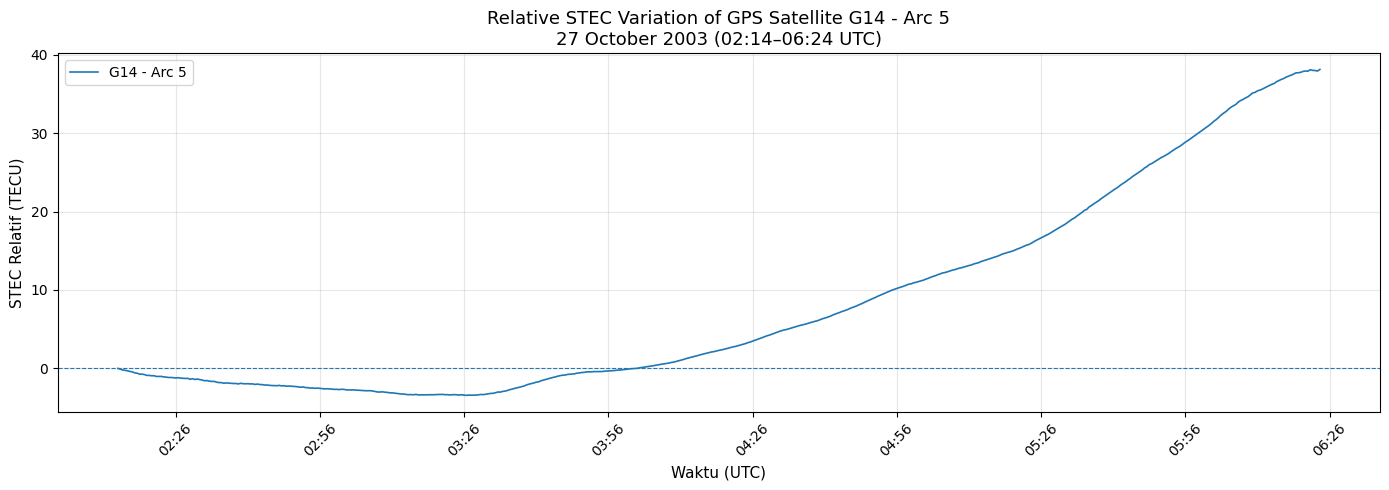

In [ ]:
# ============================================================
# GRAFIK STEC RELATIF G14 - ARC 5
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_stec_arc5["Waktu"],
    df_stec_arc5["STEC_Relatif_TECU"],
    linewidth=1.2,
    label="G14 - Arc 5"
)

# Garis referensi nol
ax.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8
)

# Label sumbu
ax.set_xlabel("Waktu (UTC)", fontsize=11)
ax.set_ylabel("STEC Relatif (TECU)", fontsize=11)

# Judul
ax.set_title(
    "Relative STEC Variation of GPS Satellite G14 - Arc 5\n"
    "27 October 2003 (02:14–06:24 UTC)",
    fontsize=13
)

# Format waktu
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M")
)

ax.xaxis.set_major_locator(
    mdates.MinuteLocator(interval=30)
)

plt.xticks(rotation=45)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# ANALISIS PERUBAHAN STEC RELATIF G14 - ARC 5
# ============================================================

df_analisis_stec = df_stec_arc5.copy()

# Perubahan STEC antar-epoch
df_analisis_stec["Delta_STEC_TECU"] = (
    df_analisis_stec["STEC_Relatif_TECU"].diff()
)

# Laju perubahan dalam TECU per menit
df_analisis_stec["Laju_STEC_TECU_per_menit"] = (
    df_analisis_stec["Delta_STEC_TECU"]
    / df_analisis_stec["Interval_detik"]
    * 60
)

# Statistik STEC relatif
print("===== STATISTIK STEC RELATIF ARC 5 =====")
print(
    df_analisis_stec["STEC_Relatif_TECU"].describe()
)

# Perubahan terbesar
print("\n===== PERUBAHAN STEC TERBESAR =====")

idx_max = df_analisis_stec["Delta_STEC_TECU"].idxmax()
idx_min = df_analisis_stec["Delta_STEC_TECU"].idxmin()

print("\nPerubahan positif terbesar:")
display(
    df_analisis_stec.loc[
        [idx_max],
        [
            "Waktu",
            "Interval_detik",
            "Delta_STEC_TECU",
            "Laju_STEC_TECU_per_menit"
        ]
    ]
)

print("\nPerubahan negatif terbesar:")
display(
    df_analisis_stec.loc[
        [idx_min],
        [
            "Waktu",
            "Interval_detik",
            "Delta_STEC_TECU",
            "Laju_STEC_TECU_per_menit"
        ]
    ]
)

# Sepuluh perubahan absolut terbesar
print("\n===== 10 PERUBAHAN STEC ABSOLUT TERBESAR =====")

df_perubahan_terbesar = (
    df_analisis_stec
    .dropna(subset=["Delta_STEC_TECU"])
    .assign(
        Abs_Delta_STEC=lambda x:
        x["Delta_STEC_TECU"].abs()
    )
    .nlargest(10, "Abs_Delta_STEC")
)

display(
    df_perubahan_terbesar[
        [
            "Waktu",
            "Interval_detik",
            "Delta_STEC_TECU",
            "Abs_Delta_STEC",
            "Laju_STEC_TECU_per_menit"
        ]
    ]
)

===== STATISTIK STEC RELATIF ARC 5 =====
count    501.000000
mean       8.273518
std       12.639322
min       -3.438552
25%       -1.904852
50%        2.295115
75%       15.317857
max       38.129582
Name: STEC_Relatif_TECU, dtype: float64

===== PERUBAHAN STEC TERBESAR =====

Perubahan positif terbesar:


,Waktu,Interval_detik,Delta_STEC_TECU,Laju_STEC_TECU_per_menit
404,2003-10-27 05:36:00.030,30.0,0.313455,0.626909



Perubahan negatif terbesar:


,Waktu,Interval_detik,Delta_STEC_TECU,Laju_STEC_TECU_per_menit
30,2003-10-27 02:29:00.013,30.0,-0.120799,-0.241597



===== 10 PERUBAHAN STEC ABSOLUT TERBESAR =====


,Waktu,Interval_detik,Delta_STEC_TECU,Abs_Delta_STEC,Laju_STEC_TECU_per_menit
404,2003-10-27 05:36:00.030,30.000,0.313455,0.313455,0.626909
466,2003-10-27 06:07:00.033,30.000,0.309318,0.309318,0.618637
462,2003-10-27 06:05:00.033,30.001,0.299627,0.299627,0.599233
458,2003-10-27 06:03:00.032,30.000,0.293468,0.293468,0.586935
459,2003-10-27 06:03:30.032,30.000,0.279398,0.279398,0.558796
456,2003-10-27 06:02:00.032,30.000,0.276651,0.276651,0.553301
427,2003-10-27 05:47:30.030,29.999,0.268891,0.268891,0.537800
429,2003-10-27 05:48:30.030,29.999,0.265027,0.265027,0.530071
402,2003-10-27 05:35:00.030,30.000,0.259713,0.259713,0.519425
472,2003-10-27 06:10:00.033,30.000,0.258082,0.258082,0.516165


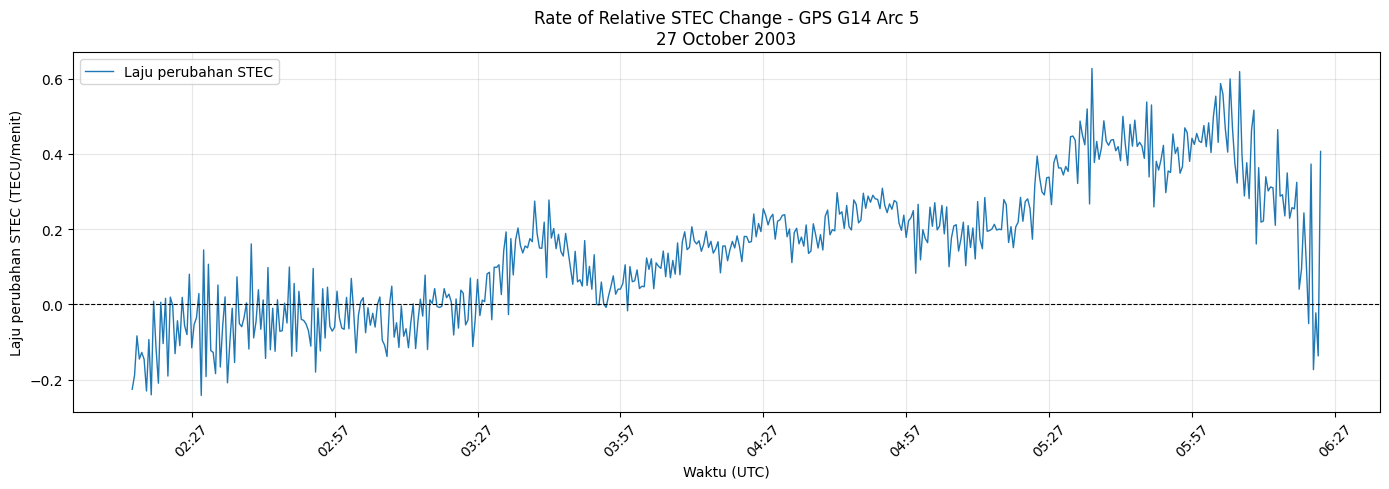

In [ ]:
# ============================================================
# GRAFIK LAJU PERUBAHAN STEC RELATIF - ARC 5
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_analisis_stec["Waktu"],
    df_analisis_stec["Laju_STEC_TECU_per_menit"],
    linewidth=1,
    label="Laju perubahan STEC"
)

ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

ax.set_xlabel("Waktu (UTC)")
ax.set_ylabel("Laju perubahan STEC (TECU/menit)")

ax.set_title(
    "Rate of Relative STEC Change - GPS G14 Arc 5\n"
    "27 October 2003"
)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=30))

ax.grid(True, alpha=0.3)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Laju_Perubahan_STEC_G14_Arc5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Jumlah epoch pada rentang pemeriksaan: 90

===== DATA STEC PADA RENTANG 05:30–06:15 UTC =====


C:\Users\ACER\AppData\Local\Temp\ipykernel_23144\1454016125.py:37: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(4)


,Waktu,STEC_Relatif_TECU,Delta_STEC_TECU,Laju_STEC_TECU_per_menit,Laju_STEC_MA5
392,2003-10-27 05:30:00.029,18.0198,0.1720,0.3439,0.3686
393,2003-10-27 05:30:30.028,18.2031,0.1833,0.3665,0.3666
394,2003-10-27 05:31:00.029,18.3798,0.1767,0.3534,0.3578
395,2003-10-27 05:31:30.030,18.6026,0.2228,0.4456,0.3744
396,2003-10-27 05:32:00.030,18.8263,0.2237,0.4474,0.3914
...,...,...,...,...,...
477,2003-10-27 06:12:30.033,35.7741,0.1696,0.3392,0.2608
478,2003-10-27 06:13:00.033,35.9249,0.1508,0.3016,0.2890
479,2003-10-27 06:13:30.033,36.0810,0.1561,0.3122,0.2787
480,2003-10-27 06:14:00.033,36.2359,0.1549,0.3098,0.2969


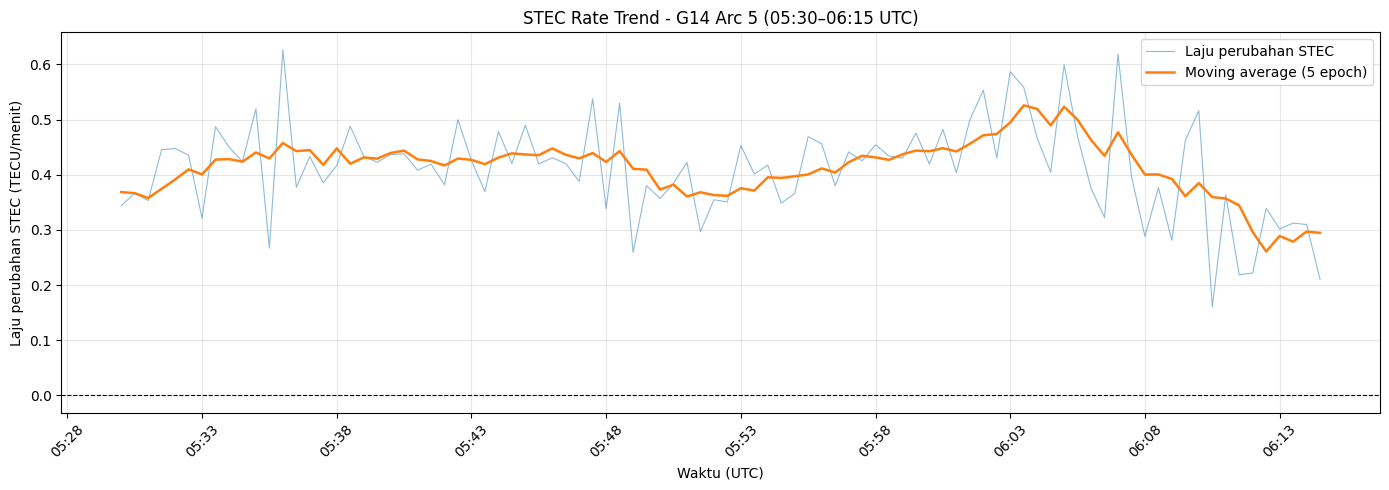

In [ ]:
# ============================================================
# PEMERIKSAAN TREN STEC G14 - ARC 5
# Moving average 5 epoch (~2,5 menit)
# ============================================================

df_tren_stec = df_analisis_stec.copy()

# Moving average laju perubahan STEC
df_tren_stec["Laju_STEC_MA5"] = (
    df_tren_stec["Laju_STEC_TECU_per_menit"]
    .rolling(window=5, min_periods=5)
    .mean()
)

# Fokus pada rentang 05:30–06:15 UTC
awal = pd.Timestamp("2003-10-27 05:30:00")
akhir = pd.Timestamp("2003-10-27 06:15:00")

df_fokus = df_tren_stec[
    (df_tren_stec["Waktu"] >= awal) &
    (df_tren_stec["Waktu"] <= akhir)
].copy()

print("Jumlah epoch pada rentang pemeriksaan:", len(df_fokus))

print("\n===== DATA STEC PADA RENTANG 05:30–06:15 UTC =====")

display(
    df_fokus[
        [
            "Waktu",
            "STEC_Relatif_TECU",
            "Delta_STEC_TECU",
            "Laju_STEC_TECU_per_menit",
            "Laju_STEC_MA5"
        ]
    ].round(4)
)

# Grafik
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    df_fokus["Waktu"],
    df_fokus["Laju_STEC_TECU_per_menit"],
    linewidth=0.8,
    alpha=0.5,
    label="Laju perubahan STEC"
)

ax.plot(
    df_fokus["Waktu"],
    df_fokus["Laju_STEC_MA5"],
    linewidth=1.8,
    label="Moving average (5 epoch)"
)

ax.axhline(0, linestyle="--", linewidth=0.8, color="black")

ax.set_xlabel("Waktu (UTC)")
ax.set_ylabel("Laju perubahan STEC (TECU/menit)")
ax.set_title("STEC Rate Trend - G14 Arc 5 (05:30–06:15 UTC)")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=5))

ax.grid(True, alpha=0.3)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Tren_STEC_G14_Arc5_0530_0615.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

===== HASIL REGRESI LINEAR STEC =====
Slope       : 0.422045 TECU/menit
Intercept   : 18.027264 TECU
R-squared   : 0.999295
P-value     : 1.815508e-140
Standard error: 0.001195


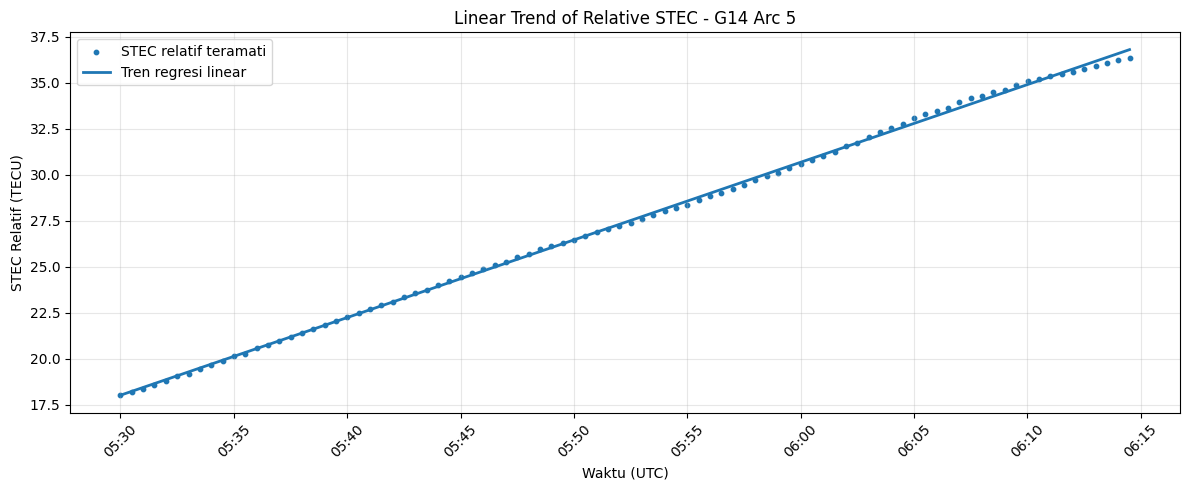

In [ ]:
# ============================================================
# REGRESI LINEAR TREN STEC RELATIF - ARC 5
# ============================================================

from scipy.stats import linregress
import numpy as np

# Waktu dalam menit sejak pengamatan pertama
waktu_menit = (
    (df_fokus["Waktu"] - df_fokus["Waktu"].iloc[0])
    .dt.total_seconds()
    / 60
)

nilai_stec = df_fokus["STEC_Relatif_TECU"]

# Regresi linear
hasil_regresi = linregress(waktu_menit, nilai_stec)

print("===== HASIL REGRESI LINEAR STEC =====")
print(f"Slope       : {hasil_regresi.slope:.6f} TECU/menit")
print(f"Intercept   : {hasil_regresi.intercept:.6f} TECU")
print(f"R-squared   : {hasil_regresi.rvalue**2:.6f}")
print(f"P-value     : {hasil_regresi.pvalue:.6e}")
print(f"Standard error: {hasil_regresi.stderr:.6f}")

# Grafik regresi
nilai_prediksi = (
    hasil_regresi.intercept
    + hasil_regresi.slope * waktu_menit
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    df_fokus["Waktu"],
    nilai_stec,
    s=10,
    label="STEC relatif teramati"
)

ax.plot(
    df_fokus["Waktu"],
    nilai_prediksi,
    linewidth=2,
    label="Tren regresi linear"
)

ax.set_xlabel("Waktu (UTC)")
ax.set_ylabel("STEC Relatif (TECU)")
ax.set_title("Linear Trend of Relative STEC - G14 Arc 5")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.grid(True, alpha=0.3)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "Regresi_Linear_STEC_G14_Arc5.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# ============================================================
# REKONSTRUKSI SEGMENTASI ARC G14
# ============================================================

df_g14_arc = (
    df_g14_valid.copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# 1. Hitung interval antar-pengamatan
df_g14_arc["Interval_detik"] = (
    df_g14_arc["Waktu"]
    .diff()
    .dt.total_seconds()
)

# 2. Tandai anomali fase yang telah diidentifikasi
waktu_anomali = pd.Timestamp("2003-10-27 01:24:30.007")

df_g14_arc["Anomali_fase"] = (
    df_g14_arc["Waktu"] == waktu_anomali
)

# 3. Identifikasi gap pengamatan
df_g14_arc["Gap"] = (
    df_g14_arc["Interval_detik"] > 30.5
)

# 4. Awal arc baru:
#    - Ketika terdapat gap
#    - Setelah epoch anomali fase

df_g14_arc["Batas_arc"] = (
    df_g14_arc["Gap"] |
    df_g14_arc["Anomali_fase"].shift(
        1, fill_value=False
    )
)

# 5. Berikan ID arc
df_g14_arc["Arc_ID"] = (
    df_g14_arc["Batas_arc"].cumsum() + 1
)

# 6. Keluarkan epoch anomali
df_g14_arc["Exclude"] = df_g14_arc["Anomali_fase"]

df_g14_arc.loc[
    df_g14_arc["Exclude"],
    "Arc_ID"
] = pd.NA

# 7. Buat ringkasan setiap arc
ringkasan_arc = (
    df_g14_arc
    .dropna(subset=["Arc_ID"])
    .groupby("Arc_ID")
    .agg(
        Waktu_Mulai=("Waktu", "min"),
        Waktu_Akhir=("Waktu", "max"),
        Jumlah_Epoch=("Waktu", "count")
    )
    .reset_index()
)

ringkasan_arc["Durasi_menit"] = (
    ringkasan_arc["Waktu_Akhir"]
    - ringkasan_arc["Waktu_Mulai"]
).dt.total_seconds() / 60

print("===== RINGKASAN ARC G14 =====")
display(ringkasan_arc)

print("\nJumlah arc:", len(ringkasan_arc))
print(
    "Epoch dipertahankan:",
    df_g14_arc["Arc_ID"].notna().sum()
)
print(
    "Epoch anomali dikeluarkan:",
    df_g14_arc["Exclude"].sum()
)

===== RINGKASAN ARC G14 =====


,Arc_ID,Waktu_Mulai,Waktu_Akhir,Jumlah_Epoch,Durasi_menit
0,1.0,2003-10-27 00:00:30.000,2003-10-27 00:31:00.003,62,30.500050
1,2.0,2003-10-27 01:01:30.006,2003-10-27 01:24:00.008,46,22.500033
2,3.0,2003-10-27 01:25:00.008,2003-10-27 01:38:00.009,27,13.000017
3,4.0,2003-10-27 02:01:30.010,2003-10-27 02:13:00.012,24,11.500033
4,5.0,2003-10-27 02:14:00.012,2003-10-27 06:24:00.034,501,250.000367
5,6.0,2003-10-27 20:35:00.110,2003-10-27 22:55:30.121,282,140.500183
6,7.0,2003-10-27 23:02:00.123,2003-10-27 23:59:00.128,115,57.000083



Jumlah arc: 7
Epoch dipertahankan: 1057
Epoch anomali dikeluarkan: 1


In [ ]:
# ============================================================
# PEMETAAN LLI G14 TERHADAP SELURUH ARC
# ============================================================

# 1. Ambil kejadian LLI G14
df_event_g14 = df_lli_semua[
    (df_lli_semua["SV"] == "G14") &
    (
        df_lli_semua["Flag_L1"] |
        df_lli_semua["Flag_L2"]
    )
].copy()

df_event_g14 = (
    df_event_g14
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# 2. Petakan setiap kejadian ke arc
hasil_pemetaan = []

for _, event in df_event_g14.iterrows():

    waktu_event = event["Waktu"]
    arc_ditemukan = None
    status = None

    for _, arc in ringkasan_arc.iterrows():

        if (
            arc["Waktu_Mulai"]
            <= waktu_event
            <= arc["Waktu_Akhir"]
        ):
            arc_ditemukan = int(arc["Arc_ID"])

            if waktu_event == arc["Waktu_Mulai"]:
                status = "LLI pada awal arc"
            else:
                status = "LLI di dalam arc"

            break

    if arc_ditemukan is None:
        status = "Di luar arc / epoch anomali"

    hasil_pemetaan.append({
        "Waktu": waktu_event,
        "LLI_L1": event["LLI_L1"],
        "LLI_L2": event["LLI_L2"],
        "Flag_L1": event["Flag_L1"],
        "Flag_L2": event["Flag_L2"],
        "Arc_ID": arc_ditemukan,
        "Status": status
    })

df_pemetaan_lli = pd.DataFrame(hasil_pemetaan)

print("===== PEMETAAN LLI G14 =====")
display(df_pemetaan_lli)

print("\n===== RINGKASAN STATUS =====")
display(df_pemetaan_lli["Status"].value_counts())

===== PEMETAAN LLI G14 =====


,Waktu,LLI_L1,LLI_L2,Flag_L1,Flag_L2,Arc_ID,Status
0,2003-10-27 00:00:30.000,5,5,True,True,1.0,LLI pada awal arc
1,2003-10-27 01:00:30.006,5,0,True,False,NaN,Di luar arc / epoch anomali
2,2003-10-27 01:01:30.006,4,5,False,True,2.0,LLI pada awal arc
3,2003-10-27 01:24:30.008,5,4,True,False,NaN,Di luar arc / epoch anomali
4,2003-10-27 02:01:30.011,4,5,False,True,4.0,LLI di dalam arc
5,2003-10-27 02:14:00.012,4,5,False,True,5.0,LLI pada awal arc
6,2003-10-27 20:33:30.110,5,0,True,False,NaN,Di luar arc / epoch anomali
7,2003-10-27 20:35:00.110,4,5,False,True,6.0,LLI pada awal arc
8,2003-10-27 23:01:00.123,5,0,True,False,NaN,Di luar arc / epoch anomali
9,2003-10-27 23:02:00.123,4,5,False,True,7.0,LLI pada awal arc



===== RINGKASAN STATUS =====


Status
LLI pada awal arc              5
Di luar arc / epoch anomali    4
LLI di dalam arc               1
Name: count, dtype: int64

In [ ]:
# PEMERIKSAAN VARIABEL UNTUK MELANJUTKAN STEC

variabel_dibutuhkan = [
    "obs",
    "df_g14_valid",
    "df_g14_arc",
    "df_lli_semua",
    "lambda1",
    "lambda2",
    "c",
    "f1",
    "f2"
]

for nama in variabel_dibutuhkan:
    if nama in globals():
        print(f"[TERSEDIA] {nama}")
    else:
        print(f"[BELUM ADA] {nama}")

[BELUM ADA] obs
[BELUM ADA] df_g14_valid
[BELUM ADA] df_g14_arc
[BELUM ADA] df_lli_semua
[BELUM ADA] lambda1
[BELUM ADA] lambda2
[BELUM ADA] c
[BELUM ADA] f1
[BELUM ADA] f2


In [ ]:
from pathlib import Path

DATA_DIR = Path.cwd()
rinex_path = DATA_DIR / "bako3000.03o"

print("Folder kerja:")
print(DATA_DIR)

print("\nFile RINEX ditemukan:", rinex_path.exists())

if rinex_path.exists():
    print("Ukuran file:", round(rinex_path.stat().st_size / 1024, 2), "KB")
else:
    print("File bako3000.03o tidak ditemukan di folder kerja.")

Folder kerja:
c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO

File RINEX ditemukan: True
Ukuran file: 2054.12 KB


In [ ]:
import georinex as gr
import pandas as pd
import numpy as np

obs = gr.load(rinex_path)

print("Data RINEX berhasil dimuat.")
print("\nDimensi data:")
print(obs.dims)

print("\nJenis observasi:")
print(list(obs.data_vars))

print("\nRentang waktu:")
print("Awal :", pd.Timestamp(obs.time.values[0]))
print("Akhir:", pd.Timestamp(obs.time.values[-1]))

print("\nDaftar satelit:")
print(obs.sv.values)

Data RINEX berhasil dimuat.

Dimensi data:
FrozenMappingWarningOnValuesAccess({'time': 2878, 'sv': 28})

Jenis observasi:
['L1', 'L2', 'C1', 'P2', 'P1', 'D1']

Rentang waktu:
Awal : 2003-10-27 00:00:30
Akhir: 2003-10-27 23:59:00.128000

Daftar satelit:
['G01' 'G02' 'G03' 'G04' 'G05' 'G06' 'G07' 'G08' 'G09' 'G10' 'G11' 'G13'
 'G14' 'G15' 'G16' 'G17' 'G18' 'G20' 'G21' 'G23' 'G24' 'G25' 'G26' 'G27'
 'G28' 'G29' 'G30' 'G31']


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [ ]:
# Mengambil observasi G14
df_g14 = pd.DataFrame({
    "Waktu": pd.to_datetime(obs.time.values),
    "L1": obs["L1"].sel(sv="G14").values,
    "L2": obs["L2"].sel(sv="G14").values,
    "C1": obs["C1"].sel(sv="G14").values,
    "P2": obs["P2"].sel(sv="G14").values,
})

# Mempertahankan epoch dengan empat observasi valid
df_g14_valid = (
    df_g14.dropna(subset=["L1", "L2", "C1", "P2"])
    .copy()
    .reset_index(drop=True)
)

print("Jumlah epoch G14 dengan observasi lengkap:", len(df_g14_valid))
print("\nRentang waktu:")
print("Awal :", df_g14_valid["Waktu"].min())
print("Akhir:", df_g14_valid["Waktu"].max())

display(df_g14_valid.head())

Jumlah epoch G14 dengan observasi lengkap: 1058

Rentang waktu:
Awal : 2003-10-27 00:00:30
Akhir: 2003-10-27 23:59:00.128000


,Waktu,L1,L2,C1,P2
0,2003-10-27 00:00:30.000,1.035021e+07,3216363.323,2.462857e+07,2.462858e+07
1,2003-10-27 00:01:00.000,1.043695e+07,3283949.353,2.464508e+07,2.464508e+07
2,2003-10-27 00:01:30.000,1.052351e+07,3351402.291,2.466155e+07,2.466156e+07
3,2003-10-27 00:02:00.001,1.060991e+07,3418722.344,2.467799e+07,2.467800e+07
4,2003-10-27 00:02:30.001,1.069612e+07,3485903.374,2.469440e+07,2.469440e+07


In [ ]:
# Konstanta GPS
c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

# Salin dan urutkan data G14
df_g14_arc = (
    df_g14_valid.copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# Hitung interval antar-epoch
df_g14_arc["Interval_detik"] = (
    df_g14_arc["Waktu"].diff().dt.total_seconds()
)

# Tandai anomali fase yang telah diidentifikasi
waktu_anomali = pd.Timestamp("2003-10-27 01:24:30.007")

df_g14_arc["Anomali_fase"] = (
    df_g14_arc["Waktu"] == waktu_anomali
)

# Identifikasi jeda pengamatan
df_g14_arc["Gap"] = (
    df_g14_arc["Interval_detik"] > 30.5
)

# Tentukan batas setiap arc
df_g14_arc["Batas_arc"] = (
    df_g14_arc["Gap"] |
    df_g14_arc["Anomali_fase"].shift(1, fill_value=False)
)

df_g14_arc["Arc_ID"] = (
    df_g14_arc["Batas_arc"].cumsum() + 1
)

# Keluarkan epoch anomali dari arc
df_g14_arc["Exclude"] = df_g14_arc["Anomali_fase"]

df_g14_arc.loc[
    df_g14_arc["Exclude"], "Arc_ID"
] = pd.NA

# Ringkasan setiap arc
ringkasan_arc = (
    df_g14_arc.dropna(subset=["Arc_ID"])
    .groupby("Arc_ID")
    .agg(
        Jumlah_epoch=("Waktu", "count"),
        Waktu_awal=("Waktu", "min"),
        Waktu_akhir=("Waktu", "max")
    )
    .reset_index()
)

print("Jumlah epoch awal:", len(df_g14_valid))
print("Epoch anomali dikeluarkan:", df_g14_arc["Exclude"].sum())
print("Jumlah epoch setelah eksklusi:", df_g14_arc["Arc_ID"].notna().sum())

display(ringkasan_arc)

Jumlah epoch awal: 1058
Epoch anomali dikeluarkan: 1
Jumlah epoch setelah eksklusi: 1057


,Arc_ID,Jumlah_epoch,Waktu_awal,Waktu_akhir
0,1.0,62,2003-10-27 00:00:30.000,2003-10-27 00:31:00.003
1,2.0,46,2003-10-27 01:01:30.006,2003-10-27 01:24:00.008
2,3.0,27,2003-10-27 01:25:00.008,2003-10-27 01:38:00.009
3,4.0,24,2003-10-27 02:01:30.010,2003-10-27 02:13:00.012
4,5.0,501,2003-10-27 02:14:00.012,2003-10-27 06:24:00.034
5,6.0,282,2003-10-27 20:35:00.110,2003-10-27 22:55:30.121
6,7.0,115,2003-10-27 23:02:00.123,2003-10-27 23:59:00.128


In [ ]:
# EKSTRAKSI DATA G14 ARC 1

df_arc1 = (
    df_g14_arc[df_g14_arc["Arc_ID"] == 1]
    .copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

print("Jumlah epoch Arc 1:", len(df_arc1))
print("Waktu awal:", df_arc1["Waktu"].min())
print("Waktu akhir:", df_arc1["Waktu"].max())

print("\nStatistik interval pengamatan:")
display(df_arc1["Waktu"].diff().dt.total_seconds().describe())

display(
    df_arc1[
        ["Waktu", "L1", "L2", "C1", "P2", "Interval_detik"]
    ].head(10)
)

Jumlah epoch Arc 1: 62
Waktu awal: 2003-10-27 00:00:30
Waktu akhir: 2003-10-27 00:31:00.003000

Statistik interval pengamatan:


count    61.000000
mean     30.000049
std       0.000669
min      29.999000
25%      30.000000
50%      30.000000
75%      30.000000
max      30.002000
Name: Waktu, dtype: float64

,Waktu,L1,L2,C1,P2,Interval_detik
0,2003-10-27 00:00:30.000,1.035021e+07,3216363.323,2.462857e+07,2.462858e+07,NaN
1,2003-10-27 00:01:00.000,1.043695e+07,3283949.353,2.464508e+07,2.464508e+07,30.000
2,2003-10-27 00:01:30.000,1.052351e+07,3351402.291,2.466155e+07,2.466156e+07,30.000
3,2003-10-27 00:02:00.001,1.060991e+07,3418722.344,2.467799e+07,2.467800e+07,30.001
4,2003-10-27 00:02:30.001,1.069612e+07,3485903.374,2.469440e+07,2.469440e+07,30.000
5,2003-10-27 00:03:00.001,1.078216e+07,3552947.823,2.471077e+07,2.471078e+07,30.000
6,2003-10-27 00:03:30.001,1.086802e+07,3619852.153,2.472711e+07,2.472712e+07,30.000
7,2003-10-27 00:04:00.001,1.095370e+07,3686614.592,2.474342e+07,2.474342e+07,30.000
8,2003-10-27 00:04:30.001,1.103920e+07,3753232.369,2.475969e+07,2.475969e+07,30.000
9,2003-10-27 00:05:00.001,1.112450e+07,3819705.416,2.477592e+07,2.477593e+07,30.000


In [ ]:
# PEMERIKSAAN KONTINUITAS FASE GEOMETRY-FREE ARC 1

df_arc1["GF_fase_m"] = (
    lambda1 * df_arc1["L1"]
    - lambda2 * df_arc1["L2"]
)

df_arc1["Delta_GF_m"] = (
    df_arc1["GF_fase_m"].diff()
)

df_arc1["Abs_Delta_GF_m"] = (
    df_arc1["Delta_GF_m"].abs()
)

print("Statistik perubahan Geometry-Free Arc 1:")
display(df_arc1["Delta_GF_m"].describe())

print("\n10 perubahan GF terbesar:")
display(
    df_arc1.nlargest(10, "Abs_Delta_GF_m")[
        ["Waktu", "Interval_detik", "Delta_GF_m", "Abs_Delta_GF_m"]
    ]
)

Statistik perubahan Geometry-Free Arc 1:


count    61.000000
mean      0.030671
std       0.008491
min       0.000498
25%       0.025109
50%       0.030063
75%       0.037374
max       0.054468
Name: Delta_GF_m, dtype: float64


10 perubahan GF terbesar:


,Waktu,Interval_detik,Delta_GF_m,Abs_Delta_GF_m
36,2003-10-27 00:18:30.001,29.999,0.054468,0.054468
17,2003-10-27 00:09:00.001,30.000,0.046108,0.046108
1,2003-10-27 00:01:00.000,30.000,0.042213,0.042213
27,2003-10-27 00:14:00.002,30.001,0.041360,0.041360
15,2003-10-27 00:08:00.001,30.000,0.040428,0.040428
5,2003-10-27 00:03:00.001,30.000,0.040111,0.040111
38,2003-10-27 00:19:30.001,29.999,0.040073,0.040073
29,2003-10-27 00:15:00.002,30.001,0.039381,0.039381
12,2003-10-27 00:06:30.001,30.000,0.039375,0.039375
23,2003-10-27 00:12:00.001,30.000,0.038414,0.038414


In [ ]:
# PERHITUNGAN STEC RELATIF G14 ARC 1

# Faktor konversi Geometry-Free ke TECU
faktor_stec = (
    40.3 * (1 / f2**2 - 1 / f1**2) * 1e16
)

# Salin data Arc 1
df_stec_arc1 = df_arc1.copy()

# Hitung perubahan STEC setiap 30 detik
df_stec_arc1["Delta_STEC_TECU"] = (
    df_stec_arc1["Delta_GF_m"] / faktor_stec
)

# Akumulasi perubahan STEC relatif
df_stec_arc1["STEC_Relatif_TECU"] = (
    df_stec_arc1["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

print("Faktor konversi:", faktor_stec, "m/TECU")

print("\n10 data pertama:")
display(
    df_stec_arc1[
        ["Waktu", "GF_fase_m", "Delta_GF_m",
         "Delta_STEC_TECU", "STEC_Relatif_TECU"]
    ].head(10)
)

print("\nStatistik STEC relatif Arc 1:")
display(
    df_stec_arc1["STEC_Relatif_TECU"].describe()
)

Faktor konversi: 0.10504595284873212 m/TECU

10 data pertama:


,Waktu,GF_fase_m,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU
0,2003-10-27 00:00:30.000,1.184111e+06,NaN,NaN,0.000000
1,2003-10-27 00:01:00.000,1.184111e+06,0.042213,0.401857,0.401857
2,2003-10-27 00:01:30.000,1.184111e+06,0.029540,0.281210,0.683067
3,2003-10-27 00:02:00.001,1.184111e+06,0.037675,0.358652,1.041719
4,2003-10-27 00:02:30.001,1.184111e+06,0.037646,0.358381,1.400100
5,2003-10-27 00:03:00.001,1.184111e+06,0.040111,0.381840,1.781940
6,2003-10-27 00:03:30.001,1.184111e+06,0.029527,0.281089,2.063028
7,2003-10-27 00:04:00.001,1.184111e+06,0.029042,0.276469,2.339498
8,2003-10-27 00:04:30.001,1.184112e+06,0.031243,0.297423,2.636920
9,2003-10-27 00:05:00.001,1.184112e+06,0.023409,0.222848,2.859768



Statistik STEC relatif Arc 1:


count    62.000000
mean      9.416514
std       5.298042
min       0.000000
25%       4.897934
50%       9.768830
75%      13.914451
max      17.810640
Name: STEC_Relatif_TECU, dtype: float64

In [ ]:
# VALIDASI KONSISTENSI STEC RELATIF ARC 1

df_stec_arc1["STEC_Langsung_TECU"] = (
    (df_stec_arc1["GF_fase_m"] - df_stec_arc1["GF_fase_m"].iloc[0])
    / faktor_stec
)

selisih_maksimum = (
    df_stec_arc1["STEC_Relatif_TECU"]
    - df_stec_arc1["STEC_Langsung_TECU"]
).abs().max()

print("STEC relatif metode akumulasi (akhir):",
      df_stec_arc1["STEC_Relatif_TECU"].iloc[-1], "TECU")

print("STEC relatif metode langsung (akhir):",
      df_stec_arc1["STEC_Langsung_TECU"].iloc[-1], "TECU")

print("Selisih maksimum kedua metode:",
      selisih_maksimum, "TECU")

if selisih_maksimum < 1e-10:
    print("\nVALIDASI BERHASIL: kedua metode konsisten.")
else:
    print("\nPERIKSA KEMBALI: terdapat perbedaan perhitungan.")

STEC relatif metode akumulasi (akhir): 17.810640245697375 TECU
STEC relatif metode langsung (akhir): 17.810640245697375 TECU
Selisih maksimum kedua metode: 3.552713678800501e-15 TECU

VALIDASI BERHASIL: kedua metode konsisten.


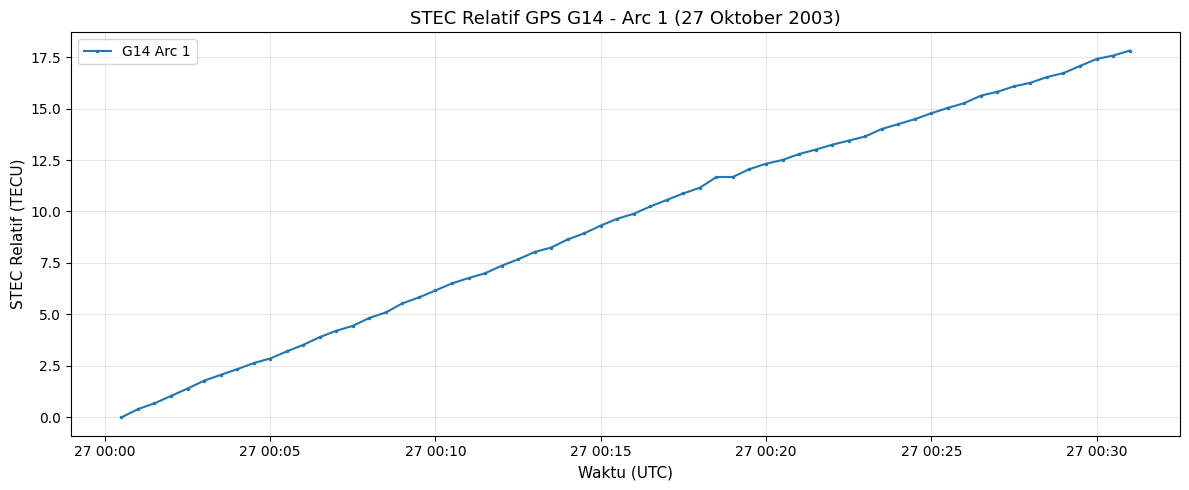

Grafik berhasil disimpan sebagai STEC_Relatif_G14_Arc1.png


In [ ]:
import matplotlib.pyplot as plt

# Membuat grafik STEC relatif Arc 1
plt.figure(figsize=(12, 5))

plt.plot(
    df_stec_arc1["Waktu"],
    df_stec_arc1["STEC_Relatif_TECU"],
    linewidth=1.5,
    marker=".",
    markersize=3,
    label="G14 Arc 1"
)

plt.title(
    "STEC Relatif GPS G14 - Arc 1 (27 Oktober 2003)",
    fontsize=13
)

plt.xlabel("Waktu (UTC)", fontsize=11)
plt.ylabel("STEC Relatif (TECU)", fontsize=11)

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Simpan grafik
plt.savefig(
    "STEC_Relatif_G14_Arc1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Grafik berhasil disimpan sebagai STEC_Relatif_G14_Arc1.png")

In [ ]:
# MENYIMPAN HASIL STEC RELATIF ARC 1

kolom_simpan = [
    "Waktu",
    "L1",
    "L2",
    "C1",
    "P2",
    "GF_fase_m",
    "Delta_GF_m",
    "Delta_STEC_TECU",
    "STEC_Relatif_TECU",
    "STEC_Langsung_TECU"
]

df_stec_arc1[kolom_simpan].to_csv(
    "Hasil_STEC_Relatif_G14_Arc1.csv",
    index=False
)

print("File CSV berhasil disimpan.")
print("Nama: Hasil_STEC_Relatif_G14_Arc1.csv")
print("Jumlah baris:", len(df_stec_arc1))

File CSV berhasil disimpan.
Nama: Hasil_STEC_Relatif_G14_Arc1.csv
Jumlah baris: 62


In [ ]:
# EKSTRAKSI DATA G14 ARC 2

df_arc2 = (
    df_g14_arc[df_g14_arc["Arc_ID"] == 2]
    .copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

print("Jumlah epoch Arc 2:", len(df_arc2))
print("Waktu awal:", df_arc2["Waktu"].min())
print("Waktu akhir:", df_arc2["Waktu"].max())

print("\nStatistik interval pengamatan:")
display(df_arc2["Waktu"].diff().dt.total_seconds().describe())

display(
    df_arc2[
        ["Waktu", "L1", "L2", "C1", "P2", "Interval_detik"]
    ].head(10)
)

Jumlah epoch Arc 2: 46
Waktu awal: 2003-10-27 01:01:30.006000
Waktu akhir: 2003-10-27 01:24:00.008000

Statistik interval pengamatan:


count    45.000000
mean     30.000044
std       0.000367
min      29.999000
25%      30.000000
50%      30.000000
75%      30.000000
max      30.001000
Name: Waktu, dtype: float64

,Waktu,L1,L2,C1,P2,Interval_detik
0,2003-10-27 01:01:30.006,136809.278,17929.254,2.632932e+07,2.632933e+07,1830.003
1,2003-10-27 01:02:00.006,194145.027,62606.414,2.634023e+07,2.634024e+07,30.000
2,2003-10-27 01:02:30.006,251206.255,107069.605,2.635109e+07,2.635109e+07,30.000
3,2003-10-27 01:03:00.006,307985.740,151313.292,2.636189e+07,2.636190e+07,30.000
4,2003-10-27 01:03:30.006,364485.470,195338.942,2.637264e+07,2.637265e+07,30.000
5,2003-10-27 01:04:00.006,420705.281,239146.502,2.638334e+07,2.638335e+07,30.000
6,2003-10-27 01:04:30.006,476649.998,282739.685,2.639399e+07,2.639399e+07,30.000
7,2003-10-27 01:05:00.006,532313.672,326113.854,2.640458e+07,2.640459e+07,30.000
8,2003-10-27 01:05:30.006,587697.750,369270.170,2.641512e+07,2.641513e+07,30.000
9,2003-10-27 01:06:00.006,642802.191,412208.652,2.642560e+07,2.642561e+07,30.000


In [ ]:
# PEMERIKSAAN GEOMETRY-FREE FASE ARC 2

df_arc2["GF_fase_m"] = (
    lambda1 * df_arc2["L1"]
    - lambda2 * df_arc2["L2"]
)

df_arc2["Delta_GF_m"] = df_arc2["GF_fase_m"].diff()

df_arc2["Abs_Delta_GF_m"] = df_arc2["Delta_GF_m"].abs()

print("Statistik perubahan Geometry-Free Arc 2:")
display(df_arc2["Delta_GF_m"].describe())

print("\n10 perubahan GF terbesar:")
display(
    df_arc2.nlargest(10, "Abs_Delta_GF_m")[
        ["Waktu", "Interval_detik", "Delta_GF_m", "Abs_Delta_GF_m"]
    ]
)

Statistik perubahan Geometry-Free Arc 2:


count    45.000000
mean      0.018183
std       0.006613
min       0.002585
25%       0.013723
50%       0.017989
75%       0.023473
max       0.029898
Name: Delta_GF_m, dtype: float64


10 perubahan GF terbesar:


,Waktu,Interval_detik,Delta_GF_m,Abs_Delta_GF_m
7,2003-10-27 01:05:00.006,30.0,0.029898,0.029898
25,2003-10-27 01:14:00.007,30.0,0.029134,0.029134
4,2003-10-27 01:03:30.006,30.0,0.027751,0.027751
23,2003-10-27 01:13:00.007,30.0,0.027386,0.027386
33,2003-10-27 01:18:00.007,30.0,0.027168,0.027168
8,2003-10-27 01:05:30.006,30.0,0.026476,0.026476
37,2003-10-27 01:20:00.007,30.0,0.026045,0.026045
2,2003-10-27 01:02:30.006,30.0,0.025287,0.025287
6,2003-10-27 01:04:30.006,30.0,0.025147,0.025147
26,2003-10-27 01:14:30.007,30.0,0.024789,0.024789


In [ ]:
# PERHITUNGAN STEC RELATIF G14 ARC 2

df_stec_arc2 = df_arc2.copy()

# Perubahan STEC
df_stec_arc2["Delta_STEC_TECU"] = (
    df_stec_arc2["Delta_GF_m"] / faktor_stec
)

# Akumulasi perubahan STEC
df_stec_arc2["STEC_Relatif_TECU"] = (
    df_stec_arc2["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

# Validasi dengan perhitungan langsung terhadap epoch pertama
df_stec_arc2["STEC_Langsung_TECU"] = (
    (df_stec_arc2["GF_fase_m"] - df_stec_arc2["GF_fase_m"].iloc[0])
    / faktor_stec
)

print("10 data pertama STEC relatif Arc 2:")
display(
    df_stec_arc2[
        ["Waktu", "Delta_GF_m", "Delta_STEC_TECU",
         "STEC_Relatif_TECU", "STEC_Langsung_TECU"]
    ].head(10)
)

print("\nStatistik STEC relatif Arc 2:")
display(df_stec_arc2["STEC_Relatif_TECU"].describe())

print(
    "\nSelisih maksimum validasi:",
    (
        df_stec_arc2["STEC_Relatif_TECU"]
        - df_stec_arc2["STEC_Langsung_TECU"]
    ).abs().max(),
    "TECU"
)

10 data pertama STEC relatif Arc 2:


,Waktu,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU,STEC_Langsung_TECU
0,2003-10-27 01:01:30.006,NaN,NaN,0.000000,0.000000
1,2003-10-27 01:02:00.006,0.011481,0.109296,0.109296,0.109296
2,2003-10-27 01:02:30.006,0.025287,0.240722,0.350017,0.350017
3,2003-10-27 01:03:00.006,0.016495,0.157029,0.507047,0.507047
4,2003-10-27 01:03:30.006,0.027751,0.264181,0.771228,0.771228
5,2003-10-27 01:04:00.006,0.020742,0.197457,0.968684,0.968684
6,2003-10-27 01:04:30.006,0.025147,0.239393,1.208078,1.208078
7,2003-10-27 01:05:00.006,0.029898,0.284621,1.492699,1.492699
8,2003-10-27 01:05:30.006,0.026476,0.252044,1.744743,1.744743
9,2003-10-27 01:06:00.006,0.010612,0.101023,1.845766,1.845766



Statistik STEC relatif Arc 2:


count    46.000000
mean      4.090773
std       2.307680
min       0.000000
25%       2.277634
50%       4.124200
75%       6.106962
max       7.789389
Name: STEC_Relatif_TECU, dtype: float64


Selisih maksimum validasi: 8.881784197001252e-16 TECU


In [ ]:
# SIMPAN HASIL STEC RELATIF G14 ARC 2

kolom_simpan = [
    "Waktu",
    "L1",
    "L2",
    "C1",
    "P2",
    "GF_fase_m",
    "Delta_GF_m",
    "Delta_STEC_TECU",
    "STEC_Relatif_TECU",
    "STEC_Langsung_TECU"
]

df_stec_arc2[kolom_simpan].to_csv(
    "Hasil_STEC_Relatif_G14_Arc2.csv",
    index=False
)

print("File CSV berhasil disimpan.")
print("Nama: Hasil_STEC_Relatif_G14_Arc2.csv")
print("Jumlah baris:", len(df_stec_arc2))

File CSV berhasil disimpan.
Nama: Hasil_STEC_Relatif_G14_Arc2.csv
Jumlah baris: 46


In [ ]:
# EKSTRAKSI DATA G14 ARC 3

df_arc3 = (
    df_g14_arc[df_g14_arc["Arc_ID"] == 3]
    .copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

print("Jumlah epoch Arc 3:", len(df_arc3))
print("Waktu awal:", df_arc3["Waktu"].min())
print("Waktu akhir:", df_arc3["Waktu"].max())

print("\nStatistik interval pengamatan:")
display(df_arc3["Waktu"].diff().dt.total_seconds().describe())

display(
    df_arc3[
        ["Waktu", "L1", "L2", "C1", "P2", "Interval_detik"]
    ].head(10)
)

Jumlah epoch Arc 3: 27
Waktu awal: 2003-10-27 01:25:00.008000
Waktu akhir: 2003-10-27 01:38:00.009000

Statistik interval pengamatan:


count    26.000000
mean     30.000038
std       0.000824
min      29.999000
25%      29.999000
50%      30.000000
75%      30.001000
max      30.001000
Name: Waktu, dtype: float64

,Waktu,L1,L2,C1,P2,Interval_detik
0,2003-10-27 01:25:00.008,67063.087,1883896.761,2.678501e+07,2.678502e+07,30.001
1,2003-10-27 01:25:30.007,111438.628,1918475.056,2.679345e+07,2.679346e+07,29.999
2,2003-10-27 01:26:00.008,155549.076,1952846.809,2.680185e+07,2.680185e+07,30.001
3,2003-10-27 01:26:30.007,199391.544,1987009.690,2.681019e+07,2.681020e+07,29.999
4,2003-10-27 01:27:00.008,242969.239,2020966.260,2.681848e+07,2.681849e+07,30.001
5,2003-10-27 01:27:30.007,286280.829,2054715.558,2.682673e+07,2.682673e+07,29.999
6,2003-10-27 01:28:00.008,329329.048,2088259.549,2.683492e+07,2.683492e+07,30.001
7,2003-10-27 01:28:30.007,372110.246,2121595.522,2.684306e+07,2.684307e+07,29.999
8,2003-10-27 01:29:00.008,414628.723,2154726.713,2.685115e+07,2.685116e+07,30.001
9,2003-10-27 01:29:30.007,456885.226,2187653.839,2.685919e+07,2.685920e+07,29.999


In [ ]:
# PEMERIKSAAN GEOMETRY-FREE FASE ARC 3

df_arc3["GF_fase_m"] = (
    lambda1 * df_arc3["L1"]
    - lambda2 * df_arc3["L2"]
)

df_arc3["Delta_GF_m"] = df_arc3["GF_fase_m"].diff()

df_arc3["Abs_Delta_GF_m"] = df_arc3["Delta_GF_m"].abs()

print("Statistik perubahan Geometry-Free Arc 3:")
display(df_arc3["Delta_GF_m"].describe())

print("\n10 perubahan GF terbesar:")
display(
    df_arc3.nlargest(10, "Abs_Delta_GF_m")[
        ["Waktu", "Interval_detik", "Delta_GF_m", "Abs_Delta_GF_m"]
    ]
)

Statistik perubahan Geometry-Free Arc 3:


count    26.000000
mean      0.010068
std       0.011101
min      -0.013241
25%       0.004057
50%       0.010214
75%       0.018481
max       0.036888
Name: Delta_GF_m, dtype: float64


10 perubahan GF terbesar:


,Waktu,Interval_detik,Delta_GF_m,Abs_Delta_GF_m
22,2003-10-27 01:36:00.009,30.000,0.036888,0.036888
8,2003-10-27 01:29:00.008,30.001,0.021925,0.021925
15,2003-10-27 01:32:30.007,29.999,0.021116,0.021116
19,2003-10-27 01:34:30.009,30.000,0.020054,0.020054
3,2003-10-27 01:26:30.007,29.999,0.019800,0.019800
12,2003-10-27 01:31:00.008,30.001,0.018684,0.018684
6,2003-10-27 01:28:00.008,30.001,0.018500,0.018500
4,2003-10-27 01:27:00.008,30.001,0.018427,0.018427
10,2003-10-27 01:30:00.008,30.001,0.016654,0.016654
17,2003-10-27 01:33:30.009,30.001,0.014066,0.014066


In [ ]:
# PERHITUNGAN STEC RELATIF G14 ARC 3

df_stec_arc3 = df_arc3.copy()

# Perubahan STEC
df_stec_arc3["Delta_STEC_TECU"] = (
    df_stec_arc3["Delta_GF_m"] / faktor_stec
)

# Akumulasi perubahan STEC relatif
df_stec_arc3["STEC_Relatif_TECU"] = (
    df_stec_arc3["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

# Validasi dengan perhitungan langsung terhadap epoch pertama
df_stec_arc3["STEC_Langsung_TECU"] = (
    (df_stec_arc3["GF_fase_m"] - df_stec_arc3["GF_fase_m"].iloc[0])
    / faktor_stec
)

print("10 data pertama STEC relatif Arc 3:")
display(
    df_stec_arc3[
        ["Waktu", "Delta_GF_m", "Delta_STEC_TECU",
         "STEC_Relatif_TECU", "STEC_Langsung_TECU"]
    ].head(10)
)

print("\nStatistik STEC relatif Arc 3:")
display(df_stec_arc3["STEC_Relatif_TECU"].describe())

print(
    "\nSelisih maksimum validasi:",
    (
        df_stec_arc3["STEC_Relatif_TECU"]
        - df_stec_arc3["STEC_Langsung_TECU"]
    ).abs().max(),
    "TECU"
)

10 data pertama STEC relatif Arc 3:


,Waktu,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU,STEC_Langsung_TECU
0,2003-10-27 01:25:00.008,NaN,NaN,0.000000,0.000000
1,2003-10-27 01:25:30.007,0.011877,0.113070,0.113070,0.113070
2,2003-10-27 01:26:00.008,0.006023,0.057335,0.170404,0.170404
3,2003-10-27 01:26:30.007,0.019800,0.188489,0.358894,0.358894
4,2003-10-27 01:27:00.008,0.018427,0.175416,0.534310,0.534310
5,2003-10-27 01:27:30.007,-0.001732,-0.016485,0.517825,0.517825
6,2003-10-27 01:28:00.008,0.018500,0.176111,0.693936,0.693936
7,2003-10-27 01:28:30.007,0.006213,0.059146,0.753082,0.753082
8,2003-10-27 01:29:00.008,0.021925,0.208718,0.961801,0.961801
9,2003-10-27 01:29:30.007,0.004688,0.044624,1.006425,1.006425



Statistik STEC relatif Arc 3:


count    27.000000
mean      1.343066
std       0.769287
min       0.000000
25%       0.723509
50%       1.411512
75%       1.948917
max       2.491817
Name: STEC_Relatif_TECU, dtype: float64


Selisih maksimum validasi: 4.440892098500626e-16 TECU


In [ ]:
# PERHITUNGAN STEC RELATIF G14 ARC 3

df_stec_arc3 = df_arc3.copy()

# Perubahan STEC
df_stec_arc3["Delta_STEC_TECU"] = (
    df_stec_arc3["Delta_GF_m"] / faktor_stec
)

# Akumulasi perubahan STEC relatif
df_stec_arc3["STEC_Relatif_TECU"] = (
    df_stec_arc3["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

# Validasi dengan perhitungan langsung terhadap epoch pertama
df_stec_arc3["STEC_Langsung_TECU"] = (
    (df_stec_arc3["GF_fase_m"] - df_stec_arc3["GF_fase_m"].iloc[0])
    / faktor_stec
)

print("10 data pertama STEC relatif Arc 3:")
display(
    df_stec_arc3[
        ["Waktu", "Delta_GF_m", "Delta_STEC_TECU",
         "STEC_Relatif_TECU", "STEC_Langsung_TECU"]
    ].head(10)
)

print("\nStatistik STEC relatif Arc 3:")
display(df_stec_arc3["STEC_Relatif_TECU"].describe())

print(
    "\nSelisih maksimum validasi:",
    (
        df_stec_arc3["STEC_Relatif_TECU"]
        - df_stec_arc3["STEC_Langsung_TECU"]
    ).abs().max(),
    "TECU"
)

10 data pertama STEC relatif Arc 3:


,Waktu,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU,STEC_Langsung_TECU
0,2003-10-27 01:25:00.008,NaN,NaN,0.000000,0.000000
1,2003-10-27 01:25:30.007,0.011877,0.113070,0.113070,0.113070
2,2003-10-27 01:26:00.008,0.006023,0.057335,0.170404,0.170404
3,2003-10-27 01:26:30.007,0.019800,0.188489,0.358894,0.358894
4,2003-10-27 01:27:00.008,0.018427,0.175416,0.534310,0.534310
5,2003-10-27 01:27:30.007,-0.001732,-0.016485,0.517825,0.517825
6,2003-10-27 01:28:00.008,0.018500,0.176111,0.693936,0.693936
7,2003-10-27 01:28:30.007,0.006213,0.059146,0.753082,0.753082
8,2003-10-27 01:29:00.008,0.021925,0.208718,0.961801,0.961801
9,2003-10-27 01:29:30.007,0.004688,0.044624,1.006425,1.006425



Statistik STEC relatif Arc 3:


count    27.000000
mean      1.343066
std       0.769287
min       0.000000
25%       0.723509
50%       1.411512
75%       1.948917
max       2.491817
Name: STEC_Relatif_TECU, dtype: float64


Selisih maksimum validasi: 4.440892098500626e-16 TECU


In [ ]:
# MENYIMPAN HASIL STEC RELATIF G14 ARC 3

kolom_simpan = [
    "Waktu",
    "L1",
    "L2",
    "C1",
    "P2",
    "GF_fase_m",
    "Delta_GF_m",
    "Delta_STEC_TECU",
    "STEC_Relatif_TECU",
    "STEC_Langsung_TECU"
]

df_stec_arc3[kolom_simpan].to_csv(
    "Hasil_STEC_Relatif_G14_Arc3.csv",
    index=False
)

print("File CSV berhasil disimpan.")
print("Nama: Hasil_STEC_Relatif_G14_Arc3.csv")
print("Jumlah baris:", len(df_stec_arc3))

File CSV berhasil disimpan.
Nama: Hasil_STEC_Relatif_G14_Arc3.csv
Jumlah baris: 27


In [ ]:
# EKSTRAKSI DATA G14 ARC 4

df_arc4 = (
    df_g14_arc[df_g14_arc["Arc_ID"] == 4]
    .copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

print("Jumlah epoch Arc 4:", len(df_arc4))
print("Waktu awal:", df_arc4["Waktu"].min())
print("Waktu akhir:", df_arc4["Waktu"].max())

print("\nStatistik interval pengamatan:")
display(df_arc4["Waktu"].diff().dt.total_seconds().describe())

display(
    df_arc4[
        ["Waktu", "L1", "L2", "C1", "P2", "Interval_detik"]
    ].head(10)
)

Jumlah epoch Arc 4: 24
Waktu awal: 2003-10-27 02:01:30.010000
Waktu akhir: 2003-10-27 02:13:00.012000

Statistik interval pengamatan:


count    23.000000
mean     30.000087
std       0.000733
min      29.999000
25%      30.000000
50%      30.000000
75%      30.001000
max      30.001000
Name: Waktu, dtype: float64

,Waktu,L1,L2,C1,P2,Interval_detik
0,2003-10-27 02:01:30.010,53952.982,-0.949,2.727697e+07,2.727699e+07,1410.001
1,2003-10-27 02:02:00.011,81097.398,21150.593,2.728214e+07,2.728215e+07,30.001
2,2003-10-27 02:02:30.010,108049.845,42152.528,2.728727e+07,2.728728e+07,29.999
3,2003-10-27 02:03:00.011,134811.415,63005.712,2.729236e+07,2.729237e+07,30.001
4,2003-10-27 02:03:30.010,161385.729,83712.993,2.729742e+07,2.729743e+07,29.999
5,2003-10-27 02:04:00.011,187768.683,104271.137,2.730244e+07,2.730245e+07,30.001
6,2003-10-27 02:04:30.010,213963.370,124682.565,2.730742e+07,2.730743e+07,29.999
7,2003-10-27 02:05:00.011,239973.433,144950.199,2.731237e+07,2.731238e+07,30.001
8,2003-10-27 02:05:30.010,265799.810,165074.637,2.731729e+07,2.731730e+07,29.999
9,2003-10-27 02:06:00.011,291444.601,185057.603,2.732217e+07,2.732218e+07,30.001


In [ ]:
# PEMERIKSAAN GEOMETRY-FREE PHASE ARC 4

df_arc4["GF_fase_m"] = (
    lambda1 * df_arc4["L1"]
    - lambda2 * df_arc4["L2"]
)

df_arc4["Delta_GF_m"] = df_arc4["GF_fase_m"].diff()

df_arc4["Abs_Delta_GF_m"] = df_arc4["Delta_GF_m"].abs()

print("Statistik perubahan Geometry-Free Phase Arc 4:")
display(df_arc4["Delta_GF_m"].describe())

print("\n10 perubahan GF terbesar:")
display(
    df_arc4.nlargest(10, "Abs_Delta_GF_m")[
        ["Waktu", "Interval_detik", "Delta_GF_m", "Abs_Delta_GF_m"]
    ]
)

Statistik perubahan Geometry-Free Phase Arc 4:


count    23.000000
mean     -0.004442
std       0.005506
min      -0.013397
25%      -0.006719
50%      -0.004621
75%      -0.001795
max       0.005750
Name: Delta_GF_m, dtype: float64


10 perubahan GF terbesar:


,Waktu,Interval_detik,Delta_GF_m,Abs_Delta_GF_m
22,2003-10-27 02:12:30.012,30.000,-0.013397,0.013397
7,2003-10-27 02:05:00.011,30.001,-0.012807,0.012807
12,2003-10-27 02:07:30.012,30.001,-0.012090,0.012090
1,2003-10-27 02:02:00.011,30.001,-0.011969,0.011969
17,2003-10-27 02:10:00.012,30.000,-0.011643,0.011643
2,2003-10-27 02:02:30.010,29.999,-0.006898,0.006898
20,2003-10-27 02:11:30.012,30.000,-0.006540,0.006540
18,2003-10-27 02:10:30.012,30.000,-0.005883,0.005883
15,2003-10-27 02:09:00.012,30.000,0.005750,0.005750
4,2003-10-27 02:03:30.010,29.999,-0.005699,0.005699


In [ ]:
# PERHITUNGAN STEC RELATIF ARC 4

df_stec_arc4 = df_arc4.copy()

# Perubahan STEC dari perubahan Geometry-Free Phase
df_stec_arc4["Delta_STEC_TECU"] = (
    df_stec_arc4["Delta_GF_m"] / faktor_stec
)

# Akumulasi perubahan STEC relatif
df_stec_arc4["STEC_Relatif_TECU"] = (
    df_stec_arc4["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

# Perhitungan langsung sebagai validasi
df_stec_arc4["STEC_Langsung_TECU"] = (
    (df_stec_arc4["GF_fase_m"] - df_stec_arc4["GF_fase_m"].iloc[0])
    / faktor_stec
)

print("10 data pertama STEC relatif Arc 4:")
display(
    df_stec_arc4[
        ["Waktu", "Delta_GF_m", "Delta_STEC_TECU", "STEC_Relatif_TECU"]
    ].head(10)
)

print("\nStatistik STEC relatif Arc 4:")
display(df_stec_arc4["STEC_Relatif_TECU"].describe())

print(
    "\nSelisih maksimum akumulasi dan perhitungan langsung:",
    (
        df_stec_arc4["STEC_Relatif_TECU"]
        - df_stec_arc4["STEC_Langsung_TECU"]
    ).abs().max(),
)

10 data pertama STEC relatif Arc 4:


,Waktu,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU
0,2003-10-27 02:01:30.010,NaN,NaN,0.000000
1,2003-10-27 02:02:00.011,-0.011969,-0.113945,-0.113945
2,2003-10-27 02:02:30.010,-0.006898,-0.065668,-0.179613
3,2003-10-27 02:03:00.011,-0.003070,-0.029226,-0.208839
4,2003-10-27 02:03:30.010,-0.005699,-0.054255,-0.263094
5,2003-10-27 02:04:00.011,0.000482,0.004589,-0.258505
6,2003-10-27 02:04:30.010,0.004009,0.038163,-0.220342
7,2003-10-27 02:05:00.011,-0.012807,-0.121916,-0.342258
8,2003-10-27 02:05:30.010,0.002835,0.026992,-0.315266
9,2003-10-27 02:06:00.011,-0.002924,-0.027837,-0.343103



Statistik STEC relatif Arc 4:


count    24.000000
mean     -0.454867
std       0.259988
min      -0.972519
25%      -0.649667
50%      -0.407775
75%      -0.261947
max       0.000000
Name: STEC_Relatif_TECU, dtype: float64


Selisih maksimum akumulasi dan perhitungan langsung: 2.220446049250313e-16


In [ ]:
# SIMPAN HASIL STEC RELATIF ARC 4

kolom_simpan = [
    "Waktu",
    "L1",
    "L2",
    "C1",
    "P2",
    "GF_fase_m",
    "Delta_GF_m",
    "Delta_STEC_TECU",
    "STEC_Relatif_TECU",
    "STEC_Langsung_TECU"
]

df_stec_arc4[kolom_simpan].to_csv(
    "Hasil_STEC_Relatif_G14_Arc4.csv",
    index=False
)

print("File berhasil disimpan: Hasil_STEC_Relatif_G14_Arc4.csv")
print("Jumlah baris:", len(df_stec_arc4))

File berhasil disimpan: Hasil_STEC_Relatif_G14_Arc4.csv
Jumlah baris: 24


In [ ]:
# REKONSTRUKSI DAN SIMPAN STEC RELATIF G14 ARC 5

# 1. Ekstraksi data Arc 5
df_arc5 = (
    df_g14_arc[df_g14_arc["Arc_ID"] == 5]
    .copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

print("Jumlah epoch Arc 5:", len(df_arc5))
print("Waktu awal:", df_arc5["Waktu"].min())
print("Waktu akhir:", df_arc5["Waktu"].max())

# 2. Hitung Geometry-Free Phase
df_arc5["GF_fase_m"] = (
    lambda1 * df_arc5["L1"]
    - lambda2 * df_arc5["L2"]
)

df_arc5["Delta_GF_m"] = df_arc5["GF_fase_m"].diff()

# 3. Hitung perubahan STEC
df_stec_arc5 = df_arc5.copy()

df_stec_arc5["Delta_STEC_TECU"] = (
    df_stec_arc5["Delta_GF_m"] / faktor_stec
)

# 4. Akumulasi STEC relatif
df_stec_arc5["STEC_Relatif_TECU"] = (
    df_stec_arc5["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

# 5. Validasi dengan perhitungan langsung
df_stec_arc5["STEC_Langsung_TECU"] = (
    (
        df_stec_arc5["GF_fase_m"]
        - df_stec_arc5["GF_fase_m"].iloc[0]
    ) / faktor_stec
)

selisih_validasi = (
    df_stec_arc5["STEC_Relatif_TECU"]
    - df_stec_arc5["STEC_Langsung_TECU"]
).abs().max()

# 6. Simpan CSV
kolom_simpan = [
    "Waktu",
    "L1",
    "L2",
    "C1",
    "P2",
    "GF_fase_m",
    "Delta_GF_m",
    "Delta_STEC_TECU",
    "STEC_Relatif_TECU",
    "STEC_Langsung_TECU"
]

nama_file = "Hasil_STEC_Relatif_G14_Arc5.csv"

df_stec_arc5[kolom_simpan].to_csv(
    nama_file,
    index=False
)

print("\nVALIDASI DAN PENYIMPANAN")
print("Jumlah baris:", len(df_stec_arc5))
print("Selisih maksimum validasi:", selisih_validasi)
print("File tersimpan:", nama_file)

Jumlah epoch Arc 5: 501
Waktu awal: 2003-10-27 02:14:00.012000
Waktu akhir: 2003-10-27 06:24:00.034000

VALIDASI DAN PENYIMPANAN
Jumlah baris: 501
Selisih maksimum validasi: 1.4210854715202004e-14
File tersimpan: Hasil_STEC_Relatif_G14_Arc5.csv


In [ ]:
# EKSTRAKSI DATA G14 ARC 6

df_arc6 = (
    df_g14_arc[df_g14_arc["Arc_ID"] == 6]
    .copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

print("Jumlah epoch Arc 6:", len(df_arc6))
print("Waktu awal:", df_arc6["Waktu"].min())
print("Waktu akhir:", df_arc6["Waktu"].max())

print("\nStatistik interval pengamatan:")
display(df_arc6["Waktu"].diff().dt.total_seconds().describe())

display(
    df_arc6[
        ["Waktu", "L1", "L2", "C1", "P2", "Interval_detik"]
    ].head(10)
)

Jumlah epoch Arc 6: 282
Waktu awal: 2003-10-27 20:35:00.110000
Waktu akhir: 2003-10-27 22:55:30.121000

Statistik interval pengamatan:


count    281.000000
mean      30.000039
std        0.000851
min       29.999000
25%       29.999000
50%       30.000000
75%       30.001000
max       30.002000
Name: Waktu, dtype: float64

,Waktu,L1,L2,C1,P2,Interval_detik
0,2003-10-27 20:35:00.110,4895.687,946.543,5.771755e+07,5.771755e+07,51060.076
1,2003-10-27 20:35:30.109,7216.413,2754.898,5.771800e+07,5.771800e+07,29.999
2,2003-10-27 20:36:00.110,9909.256,4853.249,5.771851e+07,5.771851e+07,30.001
3,2003-10-27 20:36:30.109,12968.349,7236.960,5.771909e+07,5.771909e+07,29.999
4,2003-10-27 20:37:00.110,16392.569,9905.210,5.771974e+07,5.771974e+07,30.001
5,2003-10-27 20:37:30.109,20184.114,12859.690,5.772046e+07,5.772046e+07,29.999
6,2003-10-27 20:38:00.110,24346.005,16102.787,5.772125e+07,5.772126e+07,30.001
7,2003-10-27 20:38:30.109,28877.966,19634.254,5.772212e+07,5.772212e+07,29.999
8,2003-10-27 20:39:00.110,33777.866,23452.415,5.772305e+07,5.772305e+07,30.001
9,2003-10-27 20:39:30.109,39046.523,27557.923,5.772405e+07,5.772406e+07,29.999


In [ ]:
# PEMERIKSAAN GEOMETRY-FREE PHASE ARC 6

df_arc6["GF_fase_m"] = (
    lambda1 * df_arc6["L1"]
    - lambda2 * df_arc6["L2"]
)

df_arc6["Delta_GF_m"] = df_arc6["GF_fase_m"].diff()

df_arc6["Abs_Delta_GF_m"] = (
    df_arc6["Delta_GF_m"].abs()
)

print("Statistik perubahan Geometry-Free Phase Arc 6:")
display(df_arc6["Delta_GF_m"].describe())

print("\n10 perubahan GF terbesar:")
display(
    df_arc6.nlargest(10, "Abs_Delta_GF_m")[
        [
            "Waktu",
            "Interval_detik",
            "Delta_GF_m",
            "Abs_Delta_GF_m"
        ]
    ]
)

Statistik perubahan Geometry-Free Phase Arc 6:


count    281.000000
mean      -0.003161
std        0.011679
min       -0.033939
25%       -0.011386
50%       -0.003530
75%        0.004542
max        0.030117
Name: Delta_GF_m, dtype: float64


10 perubahan GF terbesar:


,Waktu,Interval_detik,Delta_GF_m,Abs_Delta_GF_m
49,2003-10-27 20:59:30.111,29.999,-0.033939,0.033939
15,2003-10-27 20:42:30.111,30.000,-0.030897,0.030897
42,2003-10-27 20:56:00.112,30.001,-0.030174,0.030174
14,2003-10-27 20:42:00.111,30.002,0.030117,0.030117
30,2003-10-27 20:50:00.111,30.000,-0.028979,0.028979
44,2003-10-27 20:57:00.112,30.001,-0.028049,0.028049
38,2003-10-27 20:54:00.112,30.001,-0.027393,0.027393
33,2003-10-27 20:51:30.111,30.000,-0.026651,0.026651
47,2003-10-27 20:58:30.111,29.999,-0.026118,0.026118
257,2003-10-27 22:43:30.120,29.999,0.025093,0.025093


In [ ]:
# PERHITUNGAN STEC RELATIF ARC 6

df_stec_arc6 = df_arc6.copy()

# Perubahan STEC
df_stec_arc6["Delta_STEC_TECU"] = (
    df_stec_arc6["Delta_GF_m"] / faktor_stec
)

# Akumulasi STEC relatif
df_stec_arc6["STEC_Relatif_TECU"] = (
    df_stec_arc6["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

# Validasi dengan perhitungan langsung
df_stec_arc6["STEC_Langsung_TECU"] = (
    (
        df_stec_arc6["GF_fase_m"]
        - df_stec_arc6["GF_fase_m"].iloc[0]
    ) / faktor_stec
)

print("10 data pertama STEC relatif Arc 6:")
display(
    df_stec_arc6[
        [
            "Waktu",
            "Delta_GF_m",
            "Delta_STEC_TECU",
            "STEC_Relatif_TECU"
        ]
    ].head(10)
)

print("\nStatistik STEC relatif Arc 6:")
display(df_stec_arc6["STEC_Relatif_TECU"].describe())

print(
    "\nSelisih maksimum validasi:",
    (
        df_stec_arc6["STEC_Relatif_TECU"]
        - df_stec_arc6["STEC_Langsung_TECU"]
    ).abs().max()
)

10 data pertama STEC relatif Arc 6:


,Waktu,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU
0,2003-10-27 20:35:00.110,NaN,NaN,0.000000
1,2003-10-27 20:35:30.109,0.000714,0.006793,0.006793
2,2003-10-27 20:36:00.110,-0.007761,-0.073880,-0.067087
3,2003-10-27 20:36:30.109,-0.000530,-0.005042,-0.072129
4,2003-10-27 20:37:00.110,-0.006502,-0.061894,-0.134023
5,2003-10-27 20:37:30.109,-0.007168,-0.068234,-0.202257
6,2003-10-27 20:38:00.110,-0.015886,-0.151232,-0.353489
7,2003-10-27 20:38:30.109,-0.016806,-0.159988,-0.513478
8,2003-10-27 20:39:00.110,-0.013945,-0.132755,-0.646232
9,2003-10-27 20:39:30.109,-0.014894,-0.141782,-0.788015



Statistik STEC relatif Arc 6:


count    282.000000
mean     -10.551614
std        4.545491
min      -14.996975
25%      -14.252347
50%      -12.341834
75%       -8.200100
max        0.006793
Name: STEC_Relatif_TECU, dtype: float64


Selisih maksimum validasi: 8.881784197001252e-15


In [ ]:
# SIMPAN HASIL STEC RELATIF ARC 6

kolom_simpan = [
    "Waktu",
    "L1",
    "L2",
    "C1",
    "P2",
    "GF_fase_m",
    "Delta_GF_m",
    "Delta_STEC_TECU",
    "STEC_Relatif_TECU",
    "STEC_Langsung_TECU"
]

df_stec_arc6[kolom_simpan].to_csv(
    "Hasil_STEC_Relatif_G14_Arc6.csv",
    index=False
)

print("File berhasil disimpan: Hasil_STEC_Relatif_G14_Arc6.csv")
print("Jumlah baris:", len(df_stec_arc6))

File berhasil disimpan: Hasil_STEC_Relatif_G14_Arc6.csv
Jumlah baris: 282


In [ ]:
# EKSTRAKSI DATA G14 ARC 7

df_arc7 = (
    df_g14_arc[df_g14_arc["Arc_ID"] == 7]
    .copy()
    .sort_values("Waktu")
    .reset_index(drop=True)
)

print("Jumlah epoch Arc 7:", len(df_arc7))
print("Waktu awal:", df_arc7["Waktu"].min())
print("Waktu akhir:", df_arc7["Waktu"].max())

print("\nStatistik interval pengamatan:")
display(df_arc7["Waktu"].diff().dt.total_seconds().describe())

display(
    df_arc7[
        ["Waktu", "L1", "L2", "C1", "P2", "Interval_detik"]
    ].head(10)
)

Jumlah epoch Arc 7: 115
Waktu awal: 2003-10-27 23:02:00.123000
Waktu akhir: 2003-10-27 23:59:00.128000

Statistik interval pengamatan:


count    114.000000
mean      30.000044
std        0.000683
min       29.999000
25%       30.000000
50%       30.000000
75%       30.000000
max       30.002000
Name: Waktu, dtype: float64

,Waktu,L1,L2,C1,P2,Interval_detik
0,2003-10-27 23:02:00.123,240927.471,43910.968,6.087114e+07,6.087114e+07,390.002
1,2003-10-27 23:02:30.123,334898.985,117135.440,6.088902e+07,6.088901e+07,30.000
2,2003-10-27 23:03:00.123,428924.259,190401.789,6.090691e+07,6.090691e+07,30.000
3,2003-10-27 23:03:30.123,523002.187,263709.179,6.092481e+07,6.092481e+07,30.000
4,2003-10-27 23:04:00.123,617129.407,337055.015,6.094272e+07,6.094272e+07,30.000
5,2003-10-27 23:04:30.123,711303.396,410437.214,6.096064e+07,6.096065e+07,30.000
6,2003-10-27 23:05:00.123,805523.067,483855.007,6.097857e+07,6.097858e+07,30.000
7,2003-10-27 23:05:30.123,899784.564,557305.441,6.099651e+07,6.099651e+07,30.000
8,2003-10-27 23:06:00.123,994084.316,630785.695,6.101446e+07,6.101446e+07,30.000
9,2003-10-27 23:06:30.123,1088423.238,704296.415,6.103241e+07,6.103241e+07,30.000


In [ ]:
# PEMERIKSAAN GEOMETRY-FREE PHASE ARC 7

df_arc7["GF_fase_m"] = (
    lambda1 * df_arc7["L1"]
    - lambda2 * df_arc7["L2"]
)

df_arc7["Delta_GF_m"] = df_arc7["GF_fase_m"].diff()

df_arc7["Abs_Delta_GF_m"] = (
    df_arc7["Delta_GF_m"].abs()
)

print("Statistik perubahan Geometry-Free Phase Arc 7:")
display(df_arc7["Delta_GF_m"].describe())

print("\n10 perubahan GF terbesar:")
display(
    df_arc7.nlargest(10, "Abs_Delta_GF_m")[
        [
            "Waktu",
            "Interval_detik",
            "Delta_GF_m",
            "Abs_Delta_GF_m"
        ]
    ]
)

Statistik perubahan Geometry-Free Phase Arc 7:


count    114.000000
mean       0.032546
std        0.008051
min        0.012141
25%        0.027859
50%        0.031674
75%        0.037401
max        0.061960
Name: Delta_GF_m, dtype: float64


10 perubahan GF terbesar:


,Waktu,Interval_detik,Delta_GF_m,Abs_Delta_GF_m
62,2003-10-27 23:33:00.126,30.000,0.061960,0.061960
105,2003-10-27 23:54:30.126,29.999,0.052477,0.052477
110,2003-10-27 23:57:00.128,30.000,0.048867,0.048867
102,2003-10-27 23:53:00.127,30.001,0.047751,0.047751
74,2003-10-27 23:39:00.126,30.000,0.047364,0.047364
94,2003-10-27 23:49:00.127,30.001,0.045030,0.045030
93,2003-10-27 23:48:30.126,29.999,0.044560,0.044560
112,2003-10-27 23:58:00.128,30.000,0.043634,0.043634
88,2003-10-27 23:46:00.127,30.001,0.043527,0.043527
45,2003-10-27 23:24:30.125,30.000,0.043412,0.043412


In [ ]:
# PERHITUNGAN STEC RELATIF ARC 7

df_stec_arc7 = df_arc7.copy()

# Perubahan STEC
df_stec_arc7["Delta_STEC_TECU"] = (
    df_stec_arc7["Delta_GF_m"] / faktor_stec
)

# STEC relatif dengan referensi epoch pertama
df_stec_arc7["STEC_Relatif_TECU"] = (
    df_stec_arc7["Delta_STEC_TECU"]
    .fillna(0)
    .cumsum()
)

# Validasi menggunakan metode langsung
df_stec_arc7["STEC_Langsung_TECU"] = (
    df_stec_arc7["GF_fase_m"]
    - df_stec_arc7["GF_fase_m"].iloc[0]
) / faktor_stec

print("Statistik STEC Relatif Arc 7:")
display(
    df_stec_arc7["STEC_Relatif_TECU"].describe()
)

print("\n10 data pertama:")
display(
    df_stec_arc7[
        [
            "Waktu",
            "Delta_GF_m",
            "Delta_STEC_TECU",
            "STEC_Relatif_TECU",
            "STEC_Langsung_TECU"
        ]
    ].head(10)
)

print(
    "\nSelisih maksimum metode akumulasi dan langsung:",
    (
        df_stec_arc7["STEC_Relatif_TECU"]
        - df_stec_arc7["STEC_Langsung_TECU"]
    ).abs().max(),
    "TECU"
)

Statistik STEC Relatif Arc 7:


count    115.000000
mean      16.394353
std       10.432318
min        0.000000
25%        7.296442
50%       15.790273
75%       25.170863
max       35.319812
Name: STEC_Relatif_TECU, dtype: float64


10 data pertama:


,Waktu,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU,STEC_Langsung_TECU
0,2003-10-27 23:02:00.123,NaN,NaN,0.000000,0.000000
1,2003-10-27 23:02:30.123,0.020602,0.196128,0.196128,0.196128
2,2003-10-27 23:03:00.123,0.023999,0.228464,0.424592,0.424592
3,2003-10-27 23:03:30.123,0.021091,0.200778,0.625370,0.625370
4,2003-10-27 23:04:00.123,0.012141,0.115575,0.740945,0.740945
5,2003-10-27 23:04:30.123,0.031770,0.302435,1.043380,1.043380
6,2003-10-27 23:05:00.123,0.032347,0.307930,1.351309,1.351309
7,2003-10-27 23:05:30.123,0.020304,0.193290,1.544599,1.544599
8,2003-10-27 23:06:00.123,0.017640,0.167929,1.712528,1.712528
9,2003-10-27 23:06:30.123,0.031335,0.298298,2.010826,2.010826



Selisih maksimum metode akumulasi dan langsung: 1.4210854715202004e-14 TECU


In [ ]:
# MENYIMPAN HASIL STEC RELATIF ARC 7

kolom_simpan = [
    "Waktu",
    "L1",
    "L2",
    "C1",
    "P2",
    "GF_fase_m",
    "Delta_GF_m",
    "Delta_STEC_TECU",
    "STEC_Relatif_TECU",
    "STEC_Langsung_TECU"
]

df_stec_arc7[kolom_simpan].to_csv(
    "Hasil_STEC_Relatif_G14_Arc7.csv",
    index=False
)

print("File berhasil disimpan:")
print("Hasil_STEC_Relatif_G14_Arc7.csv")
print("Jumlah baris:", len(df_stec_arc7))

File berhasil disimpan:
Hasil_STEC_Relatif_G14_Arc7.csv
Jumlah baris: 115


In [ ]:
from pathlib import Path
import pandas as pd

# Folder kerja notebook saat ini
folder_kerja = Path.cwd()

# Nama file yang diharapkan
daftar_file = [
    f"Hasil_STEC_Relatif_G14_Arc{i}.csv"
    for i in range(1, 8)
]

# Periksa keberadaan dan ukuran file
hasil_inventaris = []

for nama_file in daftar_file:
    path_file = folder_kerja / nama_file

    hasil_inventaris.append({
        "File": nama_file,
        "Tersedia": path_file.exists(),
        "Ukuran_KB": (
            round(path_file.stat().st_size / 1024, 2)
            if path_file.exists()
            else None
        )
    })

df_inventaris = pd.DataFrame(hasil_inventaris)

print("Folder kerja:", folder_kerja)
display(df_inventaris)

print(
    "\nJumlah file tersedia:",
    df_inventaris["Tersedia"].sum(),
    "dari",
    len(daftar_file)
)

Folder kerja: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO


,File,Tersedia,Ukuran_KB
0,Hasil_STEC_Relatif_G14_Arc1.csv,True,10.40
1,Hasil_STEC_Relatif_G14_Arc2.csv,True,7.62
2,Hasil_STEC_Relatif_G14_Arc3.csv,True,4.55
3,Hasil_STEC_Relatif_G14_Arc4.csv,True,4.11
4,Hasil_STEC_Relatif_G14_Arc5.csv,True,84.97
5,Hasil_STEC_Relatif_G14_Arc6.csv,True,47.85
6,Hasil_STEC_Relatif_G14_Arc7.csv,True,19.05



Jumlah file tersedia: 7 dari 7


In [ ]:
# VALIDASI ISI CSV STEC RELATIF G14 DOY300

from pathlib import Path
import pandas as pd

hasil_validasi = []

for arc_id in range(1, 8):

    nama_file = f"Hasil_STEC_Relatif_G14_Arc{arc_id}.csv"
    path_file = Path.cwd() / nama_file

    df = pd.read_csv(path_file)
    df["Waktu"] = pd.to_datetime(df["Waktu"])

    hasil_validasi.append({
        "Arc_ID": arc_id,
        "Jumlah_Epoch": len(df),
        "Waktu_Awal": df["Waktu"].min(),
        "Waktu_Akhir": df["Waktu"].max(),
        "Duplikat_Waktu": df["Waktu"].duplicated().sum(),
        "STEC_NaN": df["STEC_Relatif_TECU"].isna().sum(),
        "Kolom_Lengkap": all(
            kolom in df.columns
            for kolom in [
                "Waktu", "L1", "L2", "C1", "P2",
                "GF_fase_m", "Delta_GF_m",
                "Delta_STEC_TECU",
                "STEC_Relatif_TECU",
                "STEC_Langsung_TECU"
            ]
        )
    })

df_validasi_arc = pd.DataFrame(hasil_validasi)

display(df_validasi_arc)

print(
    "\nTotal epoch seluruh arc:",
    df_validasi_arc["Jumlah_Epoch"].sum()
)

print(
    "Total waktu duplikat:",
    df_validasi_arc["Duplikat_Waktu"].sum()
)

,Arc_ID,Jumlah_Epoch,Waktu_Awal,Waktu_Akhir,Duplikat_Waktu,STEC_NaN,Kolom_Lengkap
0,1,62,2003-10-27 00:00:30.000,2003-10-27 00:31:00.003,0,0,True
1,2,46,2003-10-27 01:01:30.006,2003-10-27 01:24:00.008,0,0,True
2,3,27,2003-10-27 01:25:00.008,2003-10-27 01:38:00.009,0,0,True
3,4,24,2003-10-27 02:01:30.010,2003-10-27 02:13:00.012,0,0,True
4,5,501,2003-10-27 02:14:00.012,2003-10-27 06:24:00.034,0,0,True
5,6,282,2003-10-27 20:35:00.110,2003-10-27 22:55:30.121,0,0,True
6,7,115,2003-10-27 23:02:00.123,2003-10-27 23:59:00.128,0,0,True



Total epoch seluruh arc: 1057
Total waktu duplikat: 0


In [ ]:
# MENGGABUNGKAN STEC RELATIF G14 DOY300

daftar_df = []

for arc_id in range(1, 8):

    nama_file = f"Hasil_STEC_Relatif_G14_Arc{arc_id}.csv"

    df = pd.read_csv(nama_file)
    df["Waktu"] = pd.to_datetime(df["Waktu"])

    # Menambahkan identitas arc
    df["Arc_ID"] = arc_id

    daftar_df.append(df)

# Menggabungkan seluruh arc
df_stec_g14_doy300 = (
    pd.concat(daftar_df, ignore_index=True)
    .sort_values("Waktu")
    .reset_index(drop=True)
)

print("DATASET GABUNGAN STEC RELATIF G14 — DOY300")
print("Jumlah baris:", len(df_stec_g14_doy300))
print("Jumlah kolom:", len(df_stec_g14_doy300.columns))
print("Waktu awal:", df_stec_g14_doy300["Waktu"].min())
print("Waktu akhir:", df_stec_g14_doy300["Waktu"].max())

print("\nJumlah data per arc:")
display(
    df_stec_g14_doy300.groupby("Arc_ID").size()
)

print("\nLima baris pertama:")
display(df_stec_g14_doy300.head())

DATASET GABUNGAN STEC RELATIF G14 — DOY300
Jumlah baris: 1057
Jumlah kolom: 11
Waktu awal: 2003-10-27 00:00:30
Waktu akhir: 2003-10-27 23:59:00.128000

Jumlah data per arc:


Arc_ID
1     62
2     46
3     27
4     24
5    501
6    282
7    115
dtype: int64


Lima baris pertama:


,Waktu,L1,L2,C1,P2,GF_fase_m,Delta_GF_m,Delta_STEC_TECU,STEC_Relatif_TECU,STEC_Langsung_TECU,Arc_ID
0,2003-10-27 00:00:30.000,1.035021e+07,3216363.323,2.462857e+07,2.462858e+07,1.184111e+06,NaN,NaN,0.000000,0.000000,1
1,2003-10-27 00:01:00.000,1.043695e+07,3283949.353,2.464508e+07,2.464508e+07,1.184111e+06,0.042213,0.401857,0.401857,0.401857,1
2,2003-10-27 00:01:30.000,1.052351e+07,3351402.291,2.466155e+07,2.466156e+07,1.184111e+06,0.029540,0.281210,0.683067,0.683067,1
3,2003-10-27 00:02:00.001,1.060991e+07,3418722.344,2.467799e+07,2.467800e+07,1.184111e+06,0.037675,0.358652,1.041719,1.041719,1
4,2003-10-27 00:02:30.001,1.069612e+07,3485903.374,2.469440e+07,2.469440e+07,1.184111e+06,0.037646,0.358381,1.400100,1.400100,1


In [ ]:
# MENYIMPAN DATASET GABUNGAN STEC RELATIF G14 DOY300

nama_output = "Dataset_Gabungan_STEC_Relatif_G14_DOY300.csv"

path_output = Path.cwd() / nama_output

df_stec_g14_doy300.to_csv(
    path_output,
    index=False
)

print("Dataset berhasil disimpan.")
print("Nama file:", nama_output)
print("Lokasi:", path_output)
print("Ukuran file:", round(path_output.stat().st_size / 1024, 2), "KB")
print("Jumlah baris:", len(df_stec_g14_doy300))

Dataset berhasil disimpan.
Nama file: Dataset_Gabungan_STEC_Relatif_G14_DOY300.csv
Lokasi: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\Dataset_Gabungan_STEC_Relatif_G14_DOY300.csv
Ukuran file: 176.55 KB
Jumlah baris: 1057


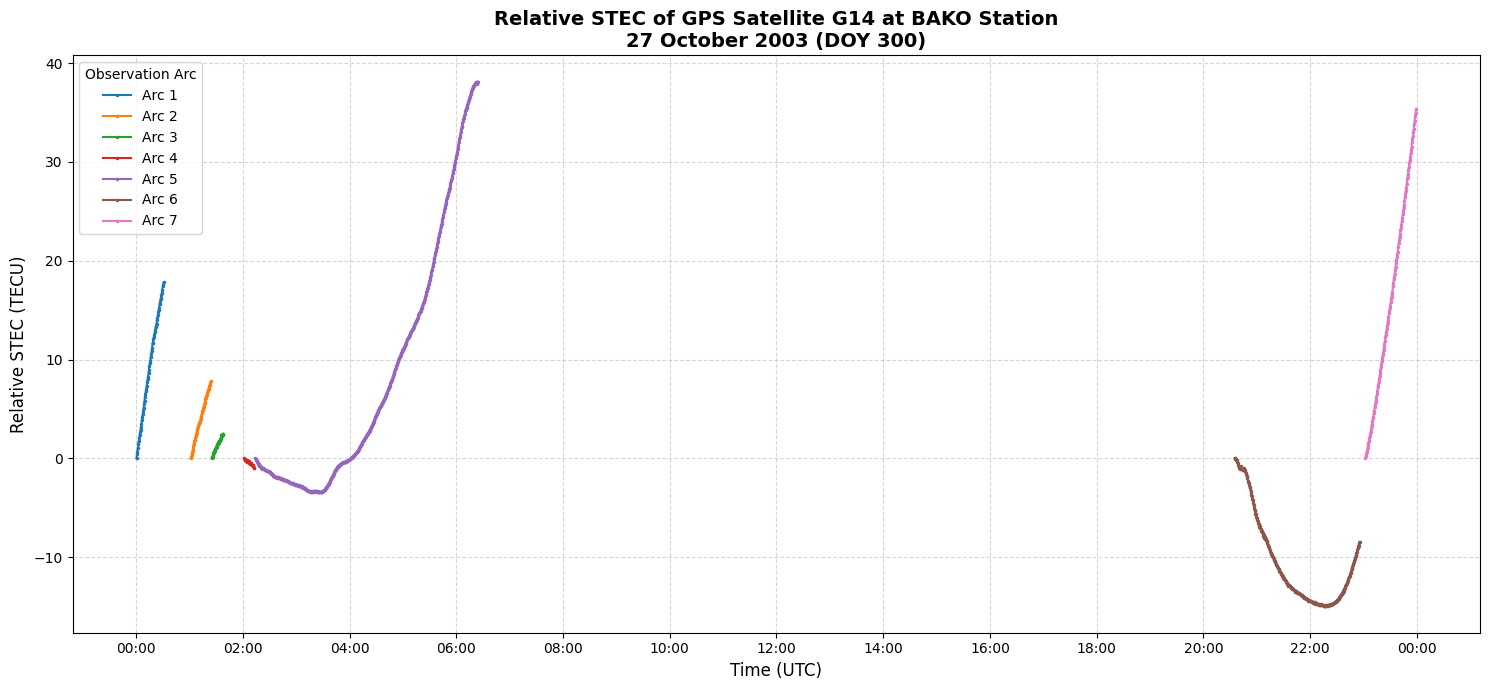

In [ ]:
# VISUALISASI STEC RELATIF G14 — DOY300

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(15, 7))

for arc_id in range(1, 8):

    df_plot = df_stec_g14_doy300[
        df_stec_g14_doy300["Arc_ID"] == arc_id
    ]

    plt.plot(
        df_plot["Waktu"],
        df_plot["STEC_Relatif_TECU"],
        marker=".",
        markersize=3,
        linewidth=1.5,
        label=f"Arc {arc_id}"
    )

plt.title(
    "Relative STEC of GPS Satellite G14 at BAKO Station\n"
    "27 October 2003 (DOY 300)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Time (UTC)", fontsize=12)
plt.ylabel("Relative STEC (TECU)", fontsize=12)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M")
)

plt.gca().xaxis.set_major_locator(
    mdates.HourLocator(interval=2)
)

plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Observation Arc")
plt.tight_layout()

# Simpan grafik
plt.savefig(
    "Grafik_STEC_Relatif_G14_DOY300.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# RINGKASAN STATISTIK STEC RELATIF SETIAP ARC

ringkasan_stec = (
    df_stec_g14_doy300
    .groupby("Arc_ID")
    .agg(
        Jumlah_Epoch=("STEC_Relatif_TECU", "count"),
        STEC_Min=("STEC_Relatif_TECU", "min"),
        STEC_Maks=("STEC_Relatif_TECU", "max"),
        STEC_Mean=("STEC_Relatif_TECU", "mean"),
        STEC_Median=("STEC_Relatif_TECU", "median"),
        STEC_Std=("STEC_Relatif_TECU", "std")
    )
    .round(4)
)

display(ringkasan_stec)

,Jumlah_Epoch,STEC_Min,STEC_Maks,STEC_Mean,STEC_Median,STEC_Std
Arc_ID,,,,,,
1,62,0.0000,17.8106,9.4165,9.7688,5.2980
2,46,0.0000,7.7894,4.0908,4.1242,2.3077
3,27,0.0000,2.4918,1.3431,1.4115,0.7693
4,24,-0.9725,0.0000,-0.4549,-0.4078,0.2600
5,501,-3.4386,38.1296,8.2735,2.2951,12.6393
6,282,-14.9970,0.0068,-10.5516,-12.3418,4.5455
7,115,0.0000,35.3198,16.3944,15.7903,10.4323


In [ ]:
# EVALUASI PERUBAHAN STEC RELATIF PADA SETIAP ARC

hasil_tren = []

for arc_id, df_arc in df_stec_g14_doy300.groupby("Arc_ID"):

    df_arc = df_arc.sort_values("Waktu")

    stec_awal = df_arc["STEC_Relatif_TECU"].iloc[0]
    stec_akhir = df_arc["STEC_Relatif_TECU"].iloc[-1]

    hasil_tren.append({
        "Arc_ID": arc_id,
        "Waktu_Awal": df_arc["Waktu"].iloc[0],
        "Waktu_Akhir": df_arc["Waktu"].iloc[-1],
        "STEC_Awal_TECU": stec_awal,
        "STEC_Akhir_TECU": stec_akhir,
        "Perubahan_Net_TECU": stec_akhir - stec_awal
    })

df_tren_stec = pd.DataFrame(hasil_tren)

display(df_tren_stec.round(4))

C:\Users\ACER\AppData\Local\Temp\ipykernel_4172\474322651.py:23: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_tren_stec.round(4))


,Arc_ID,Waktu_Awal,Waktu_Akhir,STEC_Awal_TECU,STEC_Akhir_TECU,Perubahan_Net_TECU
0,1,2003-10-27 00:00:30.000,2003-10-27 00:31:00.003,0.0,17.8106,17.8106
1,2,2003-10-27 01:01:30.006,2003-10-27 01:24:00.008,0.0,7.7894,7.7894
2,3,2003-10-27 01:25:00.008,2003-10-27 01:38:00.009,0.0,2.4918,2.4918
3,4,2003-10-27 02:01:30.010,2003-10-27 02:13:00.012,0.0,-0.9725,-0.9725
4,5,2003-10-27 02:14:00.012,2003-10-27 06:24:00.034,0.0,38.1296,38.1296
5,6,2003-10-27 20:35:00.110,2003-10-27 22:55:30.121,0.0,-8.4558,-8.4558
6,7,2003-10-27 23:02:00.123,2003-10-27 23:59:00.128,0.0,35.3198,35.3198


In [ ]:
# MENGGABUNGKAN STATISTIK DAN PERUBAHAN NETO STEC

df_evaluasi_stec = ringkasan_stec.reset_index().merge(
    df_tren_stec[
        ["Arc_ID", "Perubahan_Net_TECU"]
    ],
    on="Arc_ID",
    how="left"
)

df_evaluasi_stec.to_csv(
    "Evaluasi_STEC_Relatif_G14_DOY300.csv",
    index=False
)

print("Tabel evaluasi berhasil disimpan.")
display(df_evaluasi_stec.round(4))

Tabel evaluasi berhasil disimpan.


,Arc_ID,Jumlah_Epoch,STEC_Min,STEC_Maks,STEC_Mean,STEC_Median,STEC_Std,Perubahan_Net_TECU
0,1,62,0.0000,17.8106,9.4165,9.7688,5.2980,17.8106
1,2,46,0.0000,7.7894,4.0908,4.1242,2.3077,7.7894
2,3,27,0.0000,2.4918,1.3431,1.4115,0.7693,2.4918
3,4,24,-0.9725,0.0000,-0.4549,-0.4078,0.2600,-0.9725
4,5,501,-3.4386,38.1296,8.2735,2.2951,12.6393,38.1296
5,6,282,-14.9970,0.0068,-10.5516,-12.3418,4.5455,-8.4558
6,7,115,0.0000,35.3198,16.3944,15.7903,10.4323,35.3198


In [ ]:
# MEMBUAT ULANG INDEX WAKTU DARI DATA OBSERVASI

import numpy as np
import pandas as pd

waktu = pd.DatetimeIndex(obs.time.values)

print("Jumlah epoch:", len(waktu))
print("Waktu awal:", waktu.min())
print("Waktu akhir:", waktu.max())

Jumlah epoch: 2878
Waktu awal: 2003-10-27 00:00:30
Waktu akhir: 2003-10-27 23:59:00.128000


In [ ]:
hasil_inventarisasi = []

for j, sv in enumerate(obs.sv.values):
    l1_sat = obs["L1"].values[:, j]
    l2_sat = obs["L2"].values[:, j]

    valid_l1 = np.isfinite(l1_sat)
    valid_l2 = np.isfinite(l2_sat)
    pasangan_valid = valid_l1 & valid_l2

    waktu_valid = waktu[pasangan_valid]

    hasil_inventarisasi.append({
        "Satelit": str(sv),
        "Jumlah_L1": int(valid_l1.sum()),
        "Jumlah_L2": int(valid_l2.sum()),
        "Jumlah_Pasangan_L1_L2": int(pasangan_valid.sum()),
        "Jumlah_L1_Tanpa_L2": int((valid_l1 & ~valid_l2).sum()),
        "Jumlah_L2_Tanpa_L1": int((valid_l2 & ~valid_l1).sum()),
        "Waktu_Pertama": waktu_valid.min() if len(waktu_valid) > 0 else pd.NaT,
        "Waktu_Terakhir": waktu_valid.max() if len(waktu_valid) > 0 else pd.NaT
    })

df_inventarisasi_sat = (
    pd.DataFrame(hasil_inventarisasi)
    .sort_values("Satelit")
    .reset_index(drop=True)
)

display(df_inventarisasi_sat)

,Satelit,Jumlah_L1,Jumlah_L2,Jumlah_Pasangan_L1_L2,Jumlah_L1_Tanpa_L2,Jumlah_L2_Tanpa_L1,Waktu_Pertama,Waktu_Terakhir
0,G01,702,691,691,11,0,2003-10-27 05:35:30.030,2003-10-27 11:21:00.061
1,G02,1083,1068,1068,15,0,2003-10-27 01:39:30.009,2003-10-27 10:56:00.058
2,G03,726,724,724,2,0,2003-10-27 02:22:00.013,2003-10-27 08:23:30.045
3,G04,1001,939,939,62,0,2003-10-27 09:57:00.053,2003-10-27 19:39:00.105
4,G05,1084,1064,1064,20,0,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128
5,G06,1029,998,998,31,0,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128
6,G07,1173,1161,1161,12,0,2003-10-27 08:31:30.045,2003-10-27 18:14:30.097
7,G08,725,715,715,10,0,2003-10-27 09:34:00.051,2003-10-27 15:34:00.083
8,G09,836,827,827,9,0,2003-10-27 16:04:00.086,2003-10-27 23:00:30.123
9,G10,662,660,660,2,0,2003-10-27 13:12:30.071,2003-10-27 18:42:00.100


In [ ]:
# Simpan hasil inventarisasi seluruh satelit
file_inventarisasi = "Inventarisasi_Pasangan_L1_L2_DOY300.csv"

df_inventarisasi_sat.to_csv(
    file_inventarisasi,
    index=False
)

print("Inventarisasi berhasil disimpan.")
print("Nama file:", file_inventarisasi)
print("Jumlah satelit:", len(df_inventarisasi_sat))
print(
    "Total pasangan L1-L2:",
    df_inventarisasi_sat["Jumlah_Pasangan_L1_L2"].sum()
)
print(
    "Total L1 tanpa L2:",
    df_inventarisasi_sat["Jumlah_L1_Tanpa_L2"].sum()
)

Inventarisasi berhasil disimpan.
Nama file: Inventarisasi_Pasangan_L1_L2_DOY300.csv
Jumlah satelit: 28
Total pasangan L1-L2: 23880
Total L1 tanpa L2: 357


In [ ]:
# PEMERIKSAAN GEOMETRY-FREE PHASE SELURUH SATELIT DOY300

c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

data_l1 = obs["L1"].values
data_l2 = obs["L2"].values

hasil_gf_semua = []

for j, sv in enumerate(obs.sv.values):

    l1_sat = data_l1[:, j]
    l2_sat = data_l2[:, j]

    valid = np.isfinite(l1_sat) & np.isfinite(l2_sat)

    gf_sat = lambda1 * l1_sat - lambda2 * l2_sat

    df_sat = pd.DataFrame({
        "Waktu": waktu,
        "GF_fase_m": gf_sat,
        "Valid": valid
    })

    df_sat["Interval_detik"] = (
        df_sat["Waktu"].diff().dt.total_seconds()
    )

    df_sat["Delta_GF_m"] = df_sat["GF_fase_m"].diff()

    # Hanya pasangan epoch berurutan dengan interval sekitar 30 detik
    valid_berurutan = (
        df_sat["Valid"]
        & df_sat["Valid"].shift(1, fill_value=False)
        & df_sat["Interval_detik"].between(29.5, 30.5)
    )

    df_sat.loc[~valid_berurutan, "Delta_GF_m"] = np.nan

    df_hasil = df_sat.loc[
        valid_berurutan,
        ["Waktu", "Interval_detik", "GF_fase_m", "Delta_GF_m"]
    ].copy()

    df_hasil["Satelit"] = str(sv)

    hasil_gf_semua.append(df_hasil)

df_gf_semua = pd.concat(
    hasil_gf_semua,
    ignore_index=True
)

df_gf_semua["Abs_Delta_GF_m"] = (
    df_gf_semua["Delta_GF_m"].abs()
)

print("Jumlah perubahan GF:", len(df_gf_semua))
print("Jumlah satelit:", df_gf_semua["Satelit"].nunique())

display(df_gf_semua.head(10))

Jumlah perubahan GF: 23772
Jumlah satelit: 28


,Waktu,Interval_detik,GF_fase_m,Delta_GF_m,Satelit,Abs_Delta_GF_m
0,2003-10-27 05:36:00.030,30.0,-13395.123735,-0.038018,G01,0.038018
1,2003-10-27 05:36:30.030,30.0,-13395.148147,-0.024412,G01,0.024412
2,2003-10-27 05:37:00.030,30.0,-13395.178162,-0.030016,G01,0.030016
3,2003-10-27 05:37:30.030,30.0,-13395.213376,-0.035214,G01,0.035214
4,2003-10-27 05:38:00.030,30.0,-13395.253550,-0.040174,G01,0.040174
5,2003-10-27 05:38:30.030,30.0,-13395.282735,-0.029185,G01,0.029185
6,2003-10-27 05:39:00.030,30.0,-13395.327178,-0.044443,G01,0.044443
7,2003-10-27 05:39:30.030,30.0,-13395.351596,-0.024418,G01,0.024418
8,2003-10-27 05:40:00.030,30.0,-13395.390552,-0.038956,G01,0.038956
9,2003-10-27 05:40:30.030,30.0,-13395.424675,-0.034123,G01,0.034123


In [ ]:
# RINGKASAN STATISTIK GEOMETRY-FREE PHASE PER SATELIT

ringkasan_gf = (
    df_gf_semua
    .groupby("Satelit")
    .agg(
        Jumlah_Perubahan=("Delta_GF_m", "count"),
        Mean_Delta_GF_m=("Delta_GF_m", "mean"),
        Median_Delta_GF_m=("Delta_GF_m", "median"),
        Std_Delta_GF_m=("Delta_GF_m", "std"),
        Maks_Delta_GF_m=("Delta_GF_m", "max"),
        Min_Delta_GF_m=("Delta_GF_m", "min"),
        Maks_Absolut_GF_m=("Abs_Delta_GF_m", "max")
    )
)

# Persentil ke-99 perubahan absolut GF
persentil_99 = (
    df_gf_semua
    .groupby("Satelit")["Abs_Delta_GF_m"]
    .quantile(0.99)
    .rename("P99_Absolut_GF_m")
)

ringkasan_gf = (
    ringkasan_gf
    .join(persentil_99)
    .sort_values("Maks_Absolut_GF_m", ascending=False)
    .reset_index()
)

display(ringkasan_gf)

,Satelit,Jumlah_Perubahan,Mean_Delta_GF_m,Median_Delta_GF_m,Std_Delta_GF_m,Maks_Delta_GF_m,Min_Delta_GF_m,Maks_Absolut_GF_m,P99_Absolut_GF_m
0,G14,1052,-445.771601,0.008232,14458.700294,0.061960,-468961.420871,468961.420871,0.043579
1,G05,1056,0.000535,-0.001040,0.031661,0.099831,-0.133028,0.133028,0.113850
2,G30,1022,0.009223,0.005408,0.024977,0.113983,-0.045112,0.113983,0.100677
3,G28,668,-0.016858,-0.017724,0.017407,0.040564,-0.110326,0.110326,0.075380
4,G02,1064,0.006326,0.012805,0.027360,0.051861,-0.105518,0.105518,0.084672
5,G06,989,0.011061,0.009182,0.023712,0.098058,-0.062426,0.098058,0.088421
6,G15,782,0.015868,0.011303,0.016104,0.092933,-0.025100,0.092933,0.066053
7,G17,810,0.002372,-0.001976,0.017709,0.082029,-0.043964,0.082029,0.043591
8,G08,713,-0.020869,-0.018195,0.018831,0.028373,-0.076660,0.076660,0.066605
9,G21,670,0.005267,0.007812,0.016356,0.072289,-0.053301,0.072289,0.042343


In [ ]:
# 30 PERUBAHAN GEOMETRY-FREE PHASE TERBESAR

df_top_gf = (
    df_gf_semua
    .sort_values(
        "Abs_Delta_GF_m",
        ascending=False
    )
    .head(30)
    .reset_index(drop=True)
)

display(
    df_top_gf[
        [
            "Satelit",
            "Waktu",
            "Interval_detik",
            "Delta_GF_m",
            "Abs_Delta_GF_m"
        ]
    ]
)

,Satelit,Waktu,Interval_detik,Delta_GF_m,Abs_Delta_GF_m
0,G14,2003-10-27 01:24:30.007,29.999,-468961.420871,468961.420871
1,G05,2003-10-27 16:00:30.085,29.999,-0.133028,0.133028
2,G05,2003-10-27 16:03:00.086,30.001,-0.131350,0.131350
3,G05,2003-10-27 16:01:30.085,29.999,-0.126482,0.126482
4,G05,2003-10-27 16:04:30.085,29.999,-0.122673,0.122673
5,G05,2003-10-27 15:59:00.085,30.000,-0.121106,0.121106
6,G05,2003-10-27 16:02:00.086,30.001,-0.120827,0.120827
7,G05,2003-10-27 16:04:00.086,30.001,-0.120136,0.120136
8,G05,2003-10-27 16:07:30.085,29.999,-0.118772,0.118772
9,G05,2003-10-27 16:00:00.086,30.001,-0.116346,0.116346


In [ ]:
# PEMERIKSAAN DETAIL KANDIDAT ANOMALI GF DOY300

kandidat = {
    "G14": ("2003-10-27 01:23:00", "2003-10-27 01:26:00"),
    "G30": ("2003-10-27 02:08:00", "2003-10-27 02:21:00"),
    "G28": ("2003-10-27 11:08:00", "2003-10-27 11:13:00"),
    "G05": ("2003-10-27 15:58:00", "2003-10-27 16:12:00")
}

hasil_detail = []

for sv, (awal, akhir) in kandidat.items():

    # Cari kolom satelit
    posisi = list(map(str, obs.sv.values)).index(sv)

    df = pd.DataFrame({
        "Waktu": waktu,
        "L1": obs["L1"].values[:, posisi],
        "L2": obs["L2"].values[:, posisi],
        "C1": obs["C1"].values[:, posisi],
        "P2": obs["P2"].values[:, posisi]
    })

    df = df[
        (df["Waktu"] >= pd.Timestamp(awal)) &
        (df["Waktu"] <= pd.Timestamp(akhir))
    ].copy()

    # Geometry-free phase
    df["GF_fase_m"] = (
        lambda1 * df["L1"] -
        lambda2 * df["L2"]
    )

    # Geometry-free pseudorange
    df["C1_minus_P2_m"] = df["C1"] - df["P2"]

    # Perubahan antar-epoch
    df["Interval_detik"] = (
        df["Waktu"].diff().dt.total_seconds()
    )

    df["Delta_L1_cycle"] = df["L1"].diff()
    df["Delta_L2_cycle"] = df["L2"].diff()
    df["Delta_GF_fase_m"] = df["GF_fase_m"].diff()
    df["Delta_GF_kode_m"] = df["C1_minus_P2_m"].diff()

    df["Satelit"] = sv

    hasil_detail.append(df)

df_detail_kandidat = pd.concat(
    hasil_detail,
    ignore_index=True
)

kolom_tampil = [
    "Satelit",
    "Waktu",
    "Interval_detik",
    "Delta_L1_cycle",
    "Delta_L2_cycle",
    "Delta_GF_fase_m",
    "C1_minus_P2_m",
    "Delta_GF_kode_m"
]

display(
    df_detail_kandidat[kolom_tampil].round(4)
)

C:\Users\ACER\AppData\Local\Temp\ipykernel_4172\1851110779.py:70: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  df_detail_kandidat[kolom_tampil].round(4)


,Satelit,Waktu,Interval_detik,Delta_L1_cycle,Delta_L2_cycle,Delta_GF_fase_m,C1_minus_P2_m,Delta_GF_kode_m
0,G14,2003-10-27 01:23:00.008,NaN,NaN,NaN,NaN,-5.953,NaN
1,G14,2003-10-27 01:23:30.007,29.999,45448.839,35414.596,0.0205,-8.395,-2.442
2,G14,2003-10-27 01:24:00.008,30.001,45179.386,35204.661,0.0135,-8.500,-0.105
3,G14,2003-10-27 01:24:30.007,29.999,-2419496.068,34997.012,-468961.4209,-5.895,2.605
4,G14,2003-10-27 01:25:00.008,30.001,44643.370,34786.957,0.0207,-9.343,-3.448
...,...,...,...,...,...,...,...,...
65,G05,2003-10-27 16:09:30.085,29.999,-4471.849,-3484.104,-0.1108,-8.066,2.907
66,G05,2003-10-27 16:10:00.086,30.001,-4179.504,-3256.374,-0.0934,-6.106,1.960
67,G05,2003-10-27 16:10:30.085,29.999,-3887.740,-3028.945,-0.1130,-6.468,-0.362
68,G05,2003-10-27 16:11:00.087,30.002,-3597.496,-2802.874,-0.0903,-5.695,0.773


In [ ]:
# PEMERIKSAAN DETAIL G30 DAN G28

for sv in ["G30", "G28"]:
    print(f"\n========== SATELIT {sv} ==========")

    df_tampil = df_detail_kandidat[
        df_detail_kandidat["Satelit"] == sv
    ][
        [
            "Waktu",
            "Interval_detik",
            "Delta_L1_cycle",
            "Delta_L2_cycle",
            "Delta_GF_fase_m",
            "C1_minus_P2_m",
            "Delta_GF_kode_m"
        ]
    ]

    display(df_tampil.round(4))


========== SATELIT G30 ==========


C:\Users\ACER\AppData\Local\Temp\ipykernel_4172\3055352481.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_tampil.round(4))


,Waktu,Interval_detik,Delta_L1_cycle,Delta_L2_cycle,Delta_GF_fase_m,C1_minus_P2_m,Delta_GF_kode_m
6,2003-10-27 02:08:00.012,NaN,NaN,NaN,NaN,-8.758,NaN
7,2003-10-27 02:08:30.012,30.000,167470.554,130496.142,0.0961,-9.496,-0.738
8,2003-10-27 02:09:00.012,30.000,167679.091,130658.633,0.0974,-10.445,-0.949
9,2003-10-27 02:09:30.012,30.000,167882.068,130816.760,0.1064,-10.996,-0.551
10,2003-10-27 02:10:00.012,30.000,168091.602,130980.066,0.0984,-9.438,1.558
11,2003-10-27 02:10:30.012,30.000,168297.824,131140.749,0.1008,-10.445,-1.007
12,2003-10-27 02:11:00.012,30.000,168505.747,131302.753,0.1042,-11.852,-1.407
13,2003-10-27 02:11:30.012,30.000,168704.501,131457.657,0.0966,-11.347,0.505
14,2003-10-27 02:12:00.012,30.000,168903.660,131612.820,0.1029,-10.410,0.937
15,2003-10-27 02:12:30.012,30.000,169095.129,131762.050,0.0948,-11.067,-0.657



========== SATELIT G28 ==========


C:\Users\ACER\AppData\Local\Temp\ipykernel_4172\3055352481.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_tampil.round(4))


,Waktu,Interval_detik,Delta_L1_cycle,Delta_L2_cycle,Delta_GF_fase_m,C1_minus_P2_m,Delta_GF_kode_m
32,2003-10-27 11:08:00.059,NaN,NaN,NaN,NaN,-12.461,NaN
33,2003-10-27 11:08:30.059,30.000,-1728.894,-1346.881,-0.0755,-11.324,1.137
34,2003-10-27 11:09:00.060,30.001,-1974.996,-1538.625,-0.0813,-12.707,-1.383
35,2003-10-27 11:09:30.059,29.999,-2223.568,-1732.343,-0.0751,-13.422,-0.715
36,2003-10-27 11:10:00.060,30.001,-2472.017,-1926.033,-0.0523,-13.199,0.223
37,2003-10-27 11:10:30.059,29.999,-2714.088,-2114.422,-0.1103,-12.098,1.101
38,2003-10-27 11:11:00.060,30.001,-2957.643,-2304.369,-0.0703,-13.727,-1.629
39,2003-10-27 11:11:30.059,29.999,-3198.359,-2491.911,-0.0774,-11.195,2.532
40,2003-10-27 11:12:00.060,30.001,-3437.148,-2678.040,-0.0628,-7.012,4.183
41,2003-10-27 11:12:30.059,29.999,-3679.055,-2866.475,-0.0784,-13.011,-5.999


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# 1. MEMBACA FILE RINEX
# ============================================================

rinex_path = Path.cwd() / "bako3000.03o"

if not rinex_path.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {rinex_path}\n"
        "Pastikan notebook berada di folder yang sama dengan bako3000.03o."
    )

with open(rinex_path, "r", encoding="ascii", errors="replace") as f:
    lines = f.readlines()

print("File RINEX berhasil dibaca.")
print("Nama file:", rinex_path.name)
print("Jumlah baris:", len(lines))


# ============================================================
# 2. RENTANG WAKTU KANDIDAT ANOMALI
# ============================================================

rentang_kandidat = {
    "G30": (
        pd.Timestamp("2003-10-27 02:08:00"),
        pd.Timestamp("2003-10-27 02:21:00")
    ),
    "G28": (
        pd.Timestamp("2003-10-27 11:08:00"),
        pd.Timestamp("2003-10-27 11:13:00")
    ),
    "G05": (
        pd.Timestamp("2003-10-27 15:58:00"),
        pd.Timestamp("2003-10-27 16:12:00")
    )
}


# ============================================================
# 3. EKSTRAKSI LLI DAN SSI
# ============================================================

hasil_lli_kandidat = []

for i, line in enumerate(lines):

    if len(line) < 68:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

        waktu_epoch = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            )
            + pd.Timedelta(seconds=second)
        )

        flag_epoch = int(line[28:29])
        jumlah_sv = int(line[29:32])

    except (ValueError, TypeError):
        continue

    # Hanya memproses epoch observasi normal
    if flag_epoch != 0:
        continue

    # Daftar satelit pada epoch
    sat_text = line[32:68]

    satelit = [
        sat_text[j:j+3].strip().replace(" ", "0")
        for j in range(0, len(sat_text), 3)
        if sat_text[j:j+3].strip()
    ]

    # Pemeriksaan setiap satelit kandidat
    for sv, (awal, akhir) in rentang_kandidat.items():

        if not (awal <= waktu_epoch <= akhir):
            continue

        if sv not in satelit:
            continue

        posisi = satelit.index(sv)

        # RINEX 2.10: enam observasi per satelit,
        # menggunakan dua baris observasi.
        indeks_obs = i + 1 + posisi * 2

        if indeks_obs + 1 >= len(lines):
            continue

        baris_obs_1 = lines[indeks_obs].rstrip("\r\n").ljust(80)

        # Field observasi pertama dan kedua: L1 dan L2
        field_l1 = baris_obs_1[0:16]
        field_l2 = baris_obs_1[16:32]

        hasil_lli_kandidat.append({
            "Satelit": sv,
            "Waktu": waktu_epoch,
            "LLI_L1": field_l1[14],
            "SSI_L1": field_l1[15],
            "LLI_L2": field_l2[14],
            "SSI_L2": field_l2[15]
        })


# ============================================================
# 4. MENYUSUN DAN MENAMPILKAN HASIL
# ============================================================

df_lli_kandidat = pd.DataFrame(hasil_lli_kandidat)

if df_lli_kandidat.empty:

    print("Tidak ditemukan data pada rentang waktu kandidat.")

else:

    kolom_flag = ["LLI_L1", "SSI_L1", "LLI_L2", "SSI_L2"]

    for kolom in kolom_flag:
        df_lli_kandidat[kolom] = (
            df_lli_kandidat[kolom]
            .replace(" ", "-")
        )

    df_lli_kandidat = (
        df_lli_kandidat
        .sort_values(["Satelit", "Waktu"])
        .reset_index(drop=True)
    )

    print("\nHASIL PEMERIKSAAN LLI DAN SSI")
    display(df_lli_kandidat)

    print("\nJUMLAH EPOCH PER SATELIT")
    display(
        df_lli_kandidat
        .groupby("Satelit")
        .size()
        .rename("Jumlah_Epoch")
        .to_frame()
    )

    # Simpan hasil pemeriksaan
    output_path = Path.cwd() / "Pemeriksaan_LLI_SSI_Kandidat_DOY300.csv"
    df_lli_kandidat.to_csv(output_path, index=False)

    print("\nHasil disimpan:", output_path)


File RINEX berhasil dibaca.
Nama file: bako3000.03o
Jumlah baris: 51404
Tidak ditemukan data pada rentang waktu kandidat.


In [ ]:

# ============================================================
# DIAGNOSTIK FORMAT BARIS EPOCH RINEX
# ============================================================

print("MENCARI BARIS EPOCH TANGGAL 27 OKTOBER 2003\n")

jumlah_ditemukan = 0

for i, line in enumerate(lines):

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])

        if yy == 3 and month == 10 and day == 27:

            print(f"Indeks baris: {i}")
            print("Baris asli:")
            print(repr(line[:80]))

            print("\nHasil pembacaan kolom:")
            print("Year       :", repr(line[1:3]))
            print("Month      :", repr(line[4:6]))
            print("Day        :", repr(line[7:9]))
            print("Hour       :", repr(line[10:12]))
            print("Minute     :", repr(line[13:15]))
            print("Second     :", repr(line[15:26]))
            print("Epoch flag :", repr(line[28:29]))
            print("Jumlah SV  :", repr(line[29:32]))
            print("Daftar SV  :", repr(line[32:68]))

            jumlah_ditemukan += 1

            if jumlah_ditemukan == 3:
                break

    except (ValueError, IndexError):
        continue

print("\nJumlah baris epoch yang ditemukan:", jumlah_ditemukan)


MENCARI BARIS EPOCH TANGGAL 27 OKTOBER 2003

Indeks baris: 18
Baris asli:
' 03 10 27  0  0 30.0000000  0  9G21G 6G 5G25G15G18G30G14G23\n'

Hasil pembacaan kolom:
Year       : '03'
Month      : '10'
Day        : '27'
Hour       : ' 0'
Minute     : ' 0'
Second     : ' 30.0000000'
Epoch flag : '0'
Jumlah SV  : '  9'
Daftar SV  : 'G21G 6G 5G25G15G18G30G14G23\n'
Indeks baris: 37
Baris asli:
' 03 10 27  0  1  0.0000000  0  9G21G 6G 5G25G15G18G30G14G23\n'

Hasil pembacaan kolom:
Year       : '03'
Month      : '10'
Day        : '27'
Hour       : ' 0'
Minute     : ' 1'
Second     : '  0.0000000'
Epoch flag : '0'
Jumlah SV  : '  9'
Daftar SV  : 'G21G 6G 5G25G15G18G30G14G23\n'
Indeks baris: 56
Baris asli:
' 03 10 27  0  1 30.0000000  0  9G21G 6G 5G25G15G18G30G14G23\n'

Hasil pembacaan kolom:
Year       : '03'
Month      : '10'
Day        : '27'
Hour       : ' 0'
Minute     : ' 1'
Second     : ' 30.0000000'
Epoch flag : '0'
Jumlah SV  : '  9'
Daftar SV  : 'G21G 6G 5G25G15G18G30G14G23\n'

Jumlah ba

In [ ]:

import pandas as pd

# ============================================================
# DIAGNOSTIK IDENTITAS SATELIT PADA EPOCH RINEX
# ============================================================

hasil_diagnostik = []

for i, line in enumerate(lines):

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])
        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

        waktu_epoch = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            )
            + pd.Timedelta(seconds=second)
        )

    except (ValueError, TypeError, IndexError):
        continue

    if flag != 0:
        continue

    # Mengambil identitas satelit sesuai jumlah pada epoch
    sat_text = line[32:68]

    satelit = [
        sat_text[j:j+3].replace(" ", "0")
        for j in range(0, min(len(sat_text), jumlah_sv * 3), 3)
    ]

    hasil_diagnostik.append({
        "Indeks_Baris": i,
        "Waktu": waktu_epoch,
        "Jumlah_SV_Header": jumlah_sv,
        "Jumlah_SV_Terbaca": len(satelit),
        "Daftar_SV": satelit
    })

df_diagnostik = pd.DataFrame(hasil_diagnostik)

# Periksa keberadaan satelit kandidat
for sv in ["G05", "G28", "G30"]:
    df_diagnostik[sv] = df_diagnostik["Daftar_SV"].apply(
        lambda x: sv in x
    )

print("Jumlah epoch:", len(df_diagnostik))

print("\nJUMLAH KEMUNCULAN SATELIT")
display(
    df_diagnostik[["G05", "G28", "G30"]].sum().to_frame(
        name="Jumlah_Epoch"
    )
)

print("\nCONTOH EPOCH DI SEKITAR WAKTU KANDIDAT")

rentang_tampil = (
    (df_diagnostik["Waktu"] >= "2003-10-27 02:08:00") &
    (df_diagnostik["Waktu"] <= "2003-10-27 02:10:00")
)

display(
    df_diagnostik.loc[
        rentang_tampil,
        ["Indeks_Baris", "Waktu", "Jumlah_SV_Header",
         "Jumlah_SV_Terbaca", "Daftar_SV", "G05", "G28", "G30"]
    ]
)


Jumlah epoch: 2878

JUMLAH KEMUNCULAN SATELIT


,Jumlah_Epoch
G05,1084
G28,673
G30,1042



CONTOH EPOCH DI SEKITAR WAKTU KANDIDAT


,Indeks_Baris,Waktu,Jumlah_SV_Header,Jumlah_SV_Terbaca,Daftar_SV,G05,G28,G30
255,4863,2003-10-27 02:08:00.012,9,9,"[G14, G06, G02, G25, G15, G18, G30, G16, G23]",False,False,True
256,4882,2003-10-27 02:08:30.012,9,9,"[G14, G06, G02, G25, G15, G18, G30, G16, G23]",False,False,True
257,4901,2003-10-27 02:09:00.012,9,9,"[G14, G06, G02, G25, G15, G18, G30, G16, G23]",False,False,True
258,4920,2003-10-27 02:09:30.012,9,9,"[G14, G06, G02, G25, G15, G18, G30, G16, G23]",False,False,True


In [ ]:

import pandas as pd
from pathlib import Path

# ============================================================
# 1. MEMBACA FILE RINEX
# ============================================================

rinex_path = Path.cwd() / "bako3000.03o"

with open(rinex_path, "r", encoding="ascii", errors="replace") as f:
    lines = f.readlines()

print("File:", rinex_path.name)
print("Jumlah baris:", len(lines))


# ============================================================
# 2. RENTANG WAKTU KANDIDAT
# ============================================================

rentang_kandidat = {
    "G30": (
        pd.Timestamp("2003-10-27 02:08:00"),
        pd.Timestamp("2003-10-27 02:21:00")
    ),
    "G28": (
        pd.Timestamp("2003-10-27 11:08:00"),
        pd.Timestamp("2003-10-27 11:13:00")
    ),
    "G05": (
        pd.Timestamp("2003-10-27 15:58:00"),
        pd.Timestamp("2003-10-27 16:12:00")
    )
}


# ============================================================
# 3. EKSTRAKSI LLI DAN SSI
# ============================================================

hasil_lli_kandidat = []

for i, line in enumerate(lines):

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])
        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

        waktu_epoch = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            )
            + pd.Timedelta(seconds=second)
        )

    except (ValueError, TypeError, IndexError):
        continue

    if flag != 0:
        continue

    # Daftar satelit pada baris epoch
    sat_text = line[32:32 + jumlah_sv * 3]

    satelit = [
        sat_text[j:j+3].replace(" ", "0")
        for j in range(0, len(sat_text), 3)
        if sat_text[j:j+3].strip()
    ]

    # Memeriksa satelit kandidat
    for sv, (awal, akhir) in rentang_kandidat.items():

        if not (awal <= waktu_epoch <= akhir):
            continue

        if sv not in satelit:
            continue

        posisi = satelit.index(sv)

        # Enam observasi per satelit:
        # L1, L2, C1, P2, P1, D1
        # Dua baris observasi per satelit.
        indeks_obs = i + 1 + posisi * 2

        if indeks_obs >= len(lines):
            continue

        baris_obs = lines[indeks_obs].rstrip("\r\n").ljust(80)

        field_l1 = baris_obs[0:16]
        field_l2 = baris_obs[16:32]

        hasil_lli_kandidat.append({
            "Satelit": sv,
            "Waktu": waktu_epoch,
            "LLI_L1": field_l1[14],
            "SSI_L1": field_l1[15],
            "LLI_L2": field_l2[14],
            "SSI_L2": field_l2[15]
        })


# ============================================================
# 4. MENYUSUN HASIL
# ============================================================

df_lli_kandidat = pd.DataFrame(hasil_lli_kandidat)

if df_lli_kandidat.empty:

    print("Tidak ditemukan data pada rentang waktu kandidat.")

else:

    kolom_flag = ["LLI_L1", "SSI_L1", "LLI_L2", "SSI_L2"]

    for kolom in kolom_flag:
        df_lli_kandidat[kolom] = (
            df_lli_kandidat[kolom]
            .replace(" ", "-")
        )

    df_lli_kandidat = (
        df_lli_kandidat
        .sort_values(["Satelit", "Waktu"])
        .reset_index(drop=True)
    )

    print("\nHASIL PEMERIKSAAN LLI DAN SSI")
    display(df_lli_kandidat)

    print("\nJUMLAH EPOCH PER SATELIT")
    display(
        df_lli_kandidat.groupby("Satelit")
        .size()
        .rename("Jumlah_Epoch")
        .to_frame()
    )

    # Simpan hasil
    output_path = (
        Path.cwd() / "Pemeriksaan_LLI_SSI_Kandidat_DOY300.csv"
    )

    df_lli_kandidat.to_csv(output_path, index=False)

    print("\nFile tersimpan:", output_path)


File: bako3000.03o
Jumlah baris: 51404

HASIL PEMERIKSAAN LLI DAN SSI


,Satelit,Waktu,LLI_L1,SSI_L1,LLI_L2,SSI_L2
0,G05,2003-10-27 15:58:00.085,4,3,-,-
1,G05,2003-10-27 15:58:30.085,4,4,5,2
2,G05,2003-10-27 15:59:00.085,4,4,4,3
3,G05,2003-10-27 15:59:30.086,4,3,4,2
4,G05,2003-10-27 16:00:00.086,4,3,4,2
...,...,...,...,...,...,...
59,G30,2003-10-27 02:18:30.012,4,4,4,3
60,G30,2003-10-27 02:19:00.013,4,4,4,4
61,G30,2003-10-27 02:19:30.013,4,4,4,4
62,G30,2003-10-27 02:20:00.013,4,4,4,3



JUMLAH EPOCH PER SATELIT


,Jumlah_Epoch
Satelit,
G05,28
G28,10
G30,26



File tersimpan: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\Pemeriksaan_LLI_SSI_Kandidat_DOY300.csv


In [ ]:

# MENAMPILKAN SELURUH HASIL LLI DAN SSI

for sv in ["G05", "G28", "G30"]:

    print(f"\n{'='*65}")
    print(f"PEMERIKSAAN SATELIT {sv}")
    print(f"{'='*65}")

    df_tampil = (
        df_lli_kandidat[
            df_lli_kandidat["Satelit"] == sv
        ]
        .sort_values("Waktu")
    )

    print(df_tampil.to_string(index=False))



PEMERIKSAAN SATELIT G05
Satelit                   Waktu LLI_L1 SSI_L1 LLI_L2 SSI_L2
    G05 2003-10-27 15:58:00.085      4      3      -      -
    G05 2003-10-27 15:58:30.085      4      4      5      2
    G05 2003-10-27 15:59:00.085      4      4      4      3
    G05 2003-10-27 15:59:30.086      4      3      4      2
    G05 2003-10-27 16:00:00.086      4      3      4      2
    G05 2003-10-27 16:00:30.086      4      3      4      2
    G05 2003-10-27 16:01:00.086      4      3      4      2
    G05 2003-10-27 16:01:30.086      4      2      4      2
    G05 2003-10-27 16:02:00.086      4      4      4      3
    G05 2003-10-27 16:02:30.086      4      4      4      3
    G05 2003-10-27 16:03:00.086      4      4      4      3
    G05 2003-10-27 16:03:30.086      4      4      4      3
    G05 2003-10-27 16:04:00.086      4      5      4      4
    G05 2003-10-27 16:04:30.086      4      5      4      3
    G05 2003-10-27 16:05:00.086      4      4      4      4
    G05 2003-10

In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# PEMERIKSAAN DETAIL G05: FASE, KODE, LLI, DAN SSI
# ============================================================

rinex_path = Path.cwd() / "bako3000.03o"

with open(rinex_path, "r", encoding="ascii", errors="replace") as f:
    lines = f.readlines()

awal = pd.Timestamp("2003-10-27 15:57:00")
akhir = pd.Timestamp("2003-10-27 16:12:00")

c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6
lambda1 = c / f1
lambda2 = c / f2

def baca_nilai(field):
    nilai = field[:14].strip()
    try:
        return float(nilai) if nilai else np.nan
    except ValueError:
        return np.nan

hasil = []

for i, line in enumerate(lines):

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])
        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

        waktu = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            )
            + pd.Timedelta(seconds=second)
        )
    except (ValueError, TypeError, IndexError):
        continue

    if flag != 0 or not (awal <= waktu <= akhir):
        continue

    sat_text = line[32:32 + jumlah_sv * 3]

    satelit = [
        sat_text[j:j+3].replace(" ", "0")
        for j in range(0, len(sat_text), 3)
        if sat_text[j:j+3].strip()
    ]

    if "G05" not in satelit:
        continue

    posisi = satelit.index("G05")
    indeks_obs = i + 1 + posisi * 2

    if indeks_obs + 1 >= len(lines):
        continue

    baris1 = lines[indeks_obs].rstrip("\r\n").ljust(80)
    baris2 = lines[indeks_obs + 1].rstrip("\r\n").ljust(80)

    field_l1 = baris1[0:16]
    field_l2 = baris1[16:32]
    field_c1 = baris2[0:16]
    field_p2 = baris2[16:32]

    L1 = baca_nilai(field_l1)
    L2 = baca_nilai(field_l2)
    C1 = baca_nilai(field_c1)
    P2 = baca_nilai(field_p2)

    gf_fase = (
        lambda1 * L1 - lambda2 * L2
        if np.isfinite(L1) and np.isfinite(L2)
        else np.nan
    )

    gf_kode = (
        C1 - P2
        if np.isfinite(C1) and np.isfinite(P2)
        else np.nan
    )

    hasil.append({
        "Waktu": waktu,
        "L1_cycles": L1,
        "L2_cycles": L2,
        "C1_m": C1,
        "P2_m": P2,
        "GF_fase_m": gf_fase,
        "GF_kode_m": gf_kode,
        "LLI_L1": field_l1[14],
        "SSI_L1": field_l1[15],
        "LLI_L2": field_l2[14],
        "SSI_L2": field_l2[15]
    })

df_g05_detail = pd.DataFrame(hasil).sort_values("Waktu").reset_index(drop=True)

# Perubahan antar-epoch
df_g05_detail["Interval_detik"] = (
    df_g05_detail["Waktu"].diff().dt.total_seconds()
)

df_g05_detail["Delta_GF_fase_m"] = (
    df_g05_detail["GF_fase_m"].diff()
)

df_g05_detail["Delta_GF_kode_m"] = (
    df_g05_detail["GF_kode_m"].diff()
)

# Abaikan perubahan yang melintasi gap
valid_interval = df_g05_detail["Interval_detik"].between(29.5, 30.5)

df_g05_detail.loc[
    ~valid_interval,
    ["Delta_GF_fase_m", "Delta_GF_kode_m"]
] = np.nan

print("Jumlah epoch G05:", len(df_g05_detail))
display(df_g05_detail.round(6))

# Simpan hasil
output_path = Path.cwd() / "Detail_G05_Fase_Kode_LLI_SSI_DOY300.csv"
df_g05_detail.to_csv(output_path, index=False)

print("File tersimpan:", output_path)


Jumlah epoch G05: 29


C:\Users\ACER\AppData\Local\Temp\ipykernel_16284\316785691.py:140: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_g05_detail.round(6))


,Waktu,L1_cycles,L2_cycles,C1_m,P2_m,GF_fase_m,GF_kode_m,LLI_L1,SSI_L1,LLI_L2,SSI_L2,Interval_detik,Delta_GF_fase_m,Delta_GF_kode_m
0,2003-10-27 15:57:30.085,-6228.897,NaN,363.938,NaN,NaN,NaN,5,2,,,NaN,NaN,NaN
1,2003-10-27 15:58:00.085,-17018.164,NaN,355.328,NaN,NaN,NaN,4,3,,,30.000,NaN,NaN
2,2003-10-27 15:58:30.085,-27546.543,-0.329,346.578,NaN,-5241.852495,NaN,4,4,5,2,30.000,NaN,NaN
3,2003-10-27 15:59:00.085,-37813.814,-8000.304,337.859,NaN,-5241.973601,NaN,4,4,4,3,30.000,-0.121106,NaN
4,2003-10-27 15:59:30.086,-47817.828,-15795.168,329.219,NaN,-5242.088767,NaN,4,3,4,2,30.001,-0.115166,NaN
5,2003-10-27 16:00:00.086,-57558.385,-23384.736,320.344,NaN,-5242.205113,NaN,4,3,4,2,30.000,-0.116346,NaN
6,2003-10-27 16:00:30.086,-67039.129,-30771.784,311.625,NaN,-5242.338141,NaN,4,3,4,2,30.000,-0.133028,NaN
7,2003-10-27 16:01:00.086,-76252.420,-37950.519,302.828,NaN,-5242.448717,NaN,4,3,4,2,30.000,-0.110576,NaN
8,2003-10-27 16:01:30.086,-85200.844,-44922.799,293.547,NaN,-5242.575199,NaN,4,2,4,2,30.000,-0.126482,NaN
9,2003-10-27 16:02:00.086,-93878.351,-51683.998,284.766,NaN,-5242.696026,NaN,4,4,4,3,30.000,-0.120827,NaN


File tersimpan: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\Detail_G05_Fase_Kode_LLI_SSI_DOY300.csv


In [ ]:

import pandas as pd
import numpy as np
from pathlib import Path

# ============================================================
# PEMERIKSAAN G05: L1, L2, C1, P2, GF FASE, DAN GF KODE
# ============================================================

rinex_path = Path.cwd() / "bako3000.03o"

with open(rinex_path, "r", encoding="ascii", errors="replace") as f:
    lines = f.readlines()

awal = pd.Timestamp("2003-10-27 15:57:00")
akhir = pd.Timestamp("2003-10-27 16:12:00")

c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

def baca_field(field):
    nilai = field[:14].strip()
    try:
        return float(nilai) if nilai else np.nan
    except ValueError:
        return np.nan

hasil = []

for i, line in enumerate(lines):

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])
        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

        waktu = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            )
            + pd.Timedelta(seconds=second)
        )

    except (ValueError, TypeError, IndexError):
        continue

    if flag != 0 or not (awal <= waktu <= akhir):
        continue

    sat_text = line[32:32 + jumlah_sv * 3]

    satelit = [
        sat_text[j:j+3].replace(" ", "0")
        for j in range(0, len(sat_text), 3)
        if sat_text[j:j+3].strip()
    ]

    if "G05" not in satelit:
        continue

    posisi = satelit.index("G05")
    indeks_obs = i + 1 + posisi * 2

    if indeks_obs >= len(lines):
        continue

    baris1 = lines[indeks_obs].rstrip("\r\n").ljust(80)

    # Urutan observasi RINEX:
    # L1, L2, C1, P2, P1 pada baris pertama
    field_L1 = baris1[0:16]
    field_L2 = baris1[16:32]
    field_C1 = baris1[32:48]
    field_P2 = baris1[48:64]
    field_P1 = baris1[64:80]

    L1 = baca_field(field_L1)
    L2 = baca_field(field_L2)
    C1 = baca_field(field_C1)
    P2 = baca_field(field_P2)
    P1 = baca_field(field_P1)

    GF_fase = (
        lambda1 * L1 - lambda2 * L2
        if np.isfinite(L1) and np.isfinite(L2)
        else np.nan
    )

    GF_kode = (
        C1 - P2
        if np.isfinite(C1) and np.isfinite(P2)
        else np.nan
    )

    hasil.append({
        "Waktu": waktu,
        "L1_cycles": L1,
        "L2_cycles": L2,
        "C1_m": C1,
        "P2_m": P2,
        "P1_m": P1,
        "GF_fase_m": GF_fase,
        "GF_kode_m": GF_kode,
        "LLI_L1": field_L1[14],
        "SSI_L1": field_L1[15],
        "LLI_L2": field_L2[14],
        "SSI_L2": field_L2[15]
    })

df_g05_koreksi = (
    pd.DataFrame(hasil)
    .sort_values("Waktu")
    .reset_index(drop=True)
)

# Menghitung perubahan antar-epoch
df_g05_koreksi["Interval_detik"] = (
    df_g05_koreksi["Waktu"].diff().dt.total_seconds()
)

df_g05_koreksi["Delta_GF_fase_m"] = (
    df_g05_koreksi["GF_fase_m"].diff()
)

df_g05_koreksi["Delta_GF_kode_m"] = (
    df_g05_koreksi["GF_kode_m"].diff()
)

valid_interval = df_g05_koreksi["Interval_detik"].between(29.5, 30.5)

df_g05_koreksi.loc[
    ~valid_interval,
    ["Delta_GF_fase_m", "Delta_GF_kode_m"]
] = np.nan

print("JUMLAH EPOCH:", len(df_g05_koreksi))
display(df_g05_koreksi.round(6))

# Simpan hasil koreksi
output_path = Path.cwd() / "Detail_G05_Koreksi_GF_DOY300.csv"

df_g05_koreksi.to_csv(output_path, index=False)

print("Hasil disimpan:", output_path)


JUMLAH EPOCH: 29


C:\Users\ACER\AppData\Local\Temp\ipykernel_16284\281457599.py:149: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(df_g05_koreksi.round(6))


,Waktu,L1_cycles,L2_cycles,C1_m,P2_m,P1_m,GF_fase_m,GF_kode_m,LLI_L1,SSI_L1,LLI_L2,SSI_L2,Interval_detik,Delta_GF_fase_m,Delta_GF_kode_m
0,2003-10-27 15:57:30.085,-6228.897,NaN,5.029701e+07,NaN,NaN,NaN,NaN,5,2,,,NaN,NaN,NaN
1,2003-10-27 15:58:00.085,-17018.164,NaN,5.029496e+07,NaN,NaN,NaN,NaN,4,3,,,30.000,NaN,NaN
2,2003-10-27 15:58:30.085,-27546.543,-0.329,5.029295e+07,5.029297e+07,NaN,-5241.852495,-11.628,4,4,5,2,30.000,NaN,NaN
3,2003-10-27 15:59:00.085,-37813.814,-8000.304,5.029100e+07,5.029101e+07,NaN,-5241.973601,-10.656,4,4,4,3,30.000,-0.121106,0.972
4,2003-10-27 15:59:30.086,-47817.828,-15795.168,5.028909e+07,5.028911e+07,NaN,-5242.088767,-10.926,4,3,4,2,30.001,-0.115166,-0.270
5,2003-10-27 16:00:00.086,-57558.385,-23384.736,5.028724e+07,5.028725e+07,NaN,-5242.205113,-9.121,4,3,4,2,30.000,-0.116346,1.805
6,2003-10-27 16:00:30.086,-67039.129,-30771.784,5.028544e+07,5.028545e+07,NaN,-5242.338141,-11.266,4,3,4,2,30.000,-0.133028,-2.145
7,2003-10-27 16:01:00.086,-76252.420,-37950.519,5.028368e+07,5.028370e+07,NaN,-5242.448717,-12.250,4,3,4,2,30.000,-0.110576,-0.984
8,2003-10-27 16:01:30.086,-85200.844,-44922.799,5.028198e+07,5.028199e+07,NaN,-5242.575199,-9.942,4,2,4,2,30.000,-0.126482,2.308
9,2003-10-27 16:02:00.086,-93878.351,-51683.998,5.028033e+07,5.028034e+07,NaN,-5242.696026,-9.519,4,4,4,3,30.000,-0.120827,0.423


Hasil disimpan: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\Detail_G05_Koreksi_GF_DOY300.csv


Jumlah data: 29
Kolom: ['Waktu', 'L1_cycles', 'L2_cycles', 'C1_m', 'P2_m', 'P1_m', 'GF_fase_m', 'GF_kode_m', 'LLI_L1', 'SSI_L1', 'LLI_L2', 'SSI_L2', 'Interval_detik', 'Delta_GF_fase_m', 'Delta_GF_kode_m']


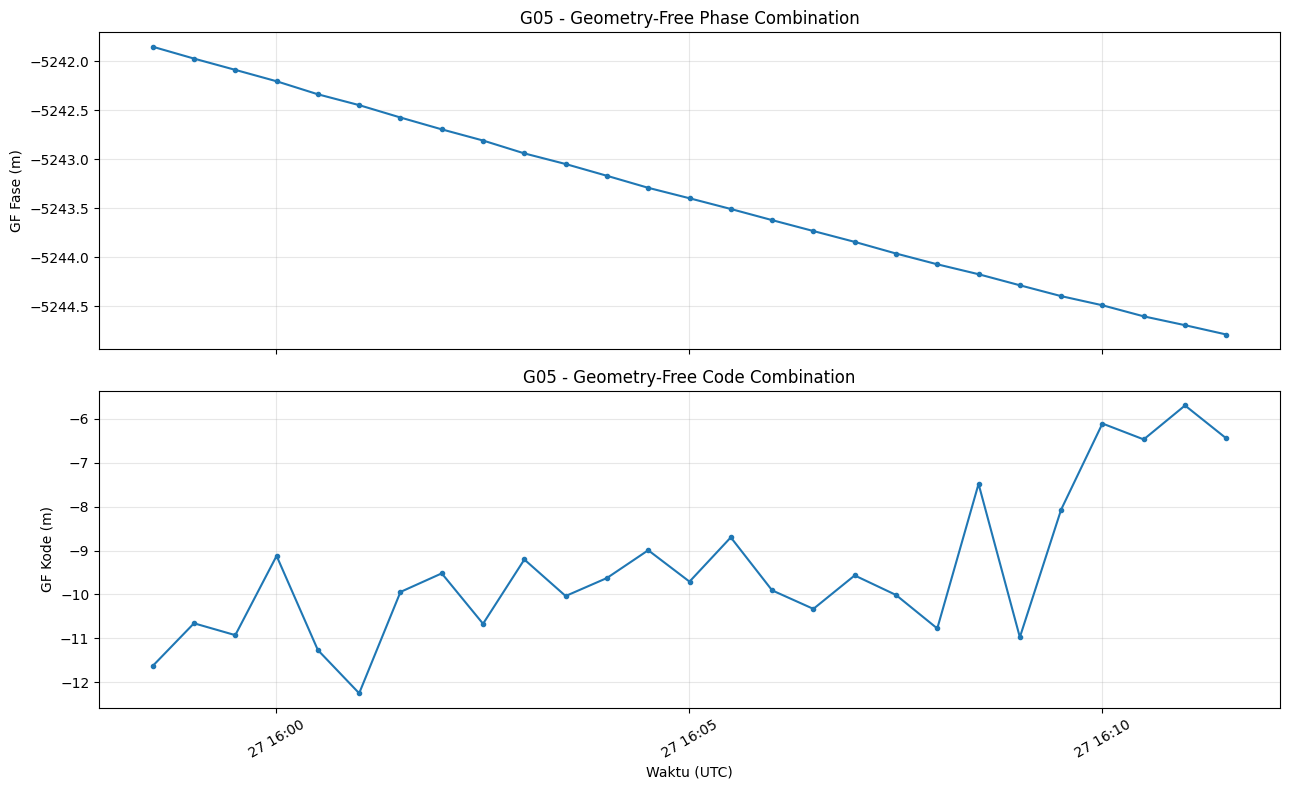

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Membaca hasil ekstraksi G05 yang sudah disimpan
file_path = Path.cwd() / "Detail_G05_Koreksi_GF_DOY300.csv"

df_g05_koreksi = pd.read_csv(file_path, parse_dates=["Waktu"])

print("Jumlah data:", len(df_g05_koreksi))
print("Kolom:", df_g05_koreksi.columns.tolist())

# Membuat grafik
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

axes[0].plot(
    df_g05_koreksi["Waktu"],
    df_g05_koreksi["GF_fase_m"],
    marker="o",
    markersize=3
)
axes[0].set_title("G05 - Geometry-Free Phase Combination")
axes[0].set_ylabel("GF Fase (m)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    df_g05_koreksi["Waktu"],
    df_g05_koreksi["GF_kode_m"],
    marker="o",
    markersize=3
)
axes[1].set_title("G05 - Geometry-Free Code Combination")
axes[1].set_ylabel("GF Kode (m)")
axes[1].set_xlabel("Waktu (UTC)")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Jumlah data: 29
Waktu awal: 2003-10-27 15:57:30.085000
Waktu akhir: 2003-10-27 16:11:30.087000

Kolom dataset:
['Waktu', 'L1_cycles', 'L2_cycles', 'C1_m', 'P2_m', 'P1_m', 'GF_fase_m', 'GF_kode_m', 'LLI_L1', 'SSI_L1', 'LLI_L2', 'SSI_L2', 'Interval_detik', 'Delta_GF_fase_m', 'Delta_GF_kode_m']


,Waktu,L1_cycles,L2_cycles,C1_m,P2_m,P1_m,GF_fase_m,GF_kode_m,LLI_L1,SSI_L1,LLI_L2,SSI_L2,Interval_detik,Delta_GF_fase_m,Delta_GF_kode_m
0,2003-10-27 15:57:30.085,-6228.897,NaN,5.029701e+07,NaN,NaN,NaN,NaN,5,2,,,NaN,NaN,NaN
1,2003-10-27 15:58:00.085,-17018.164,NaN,5.029496e+07,NaN,NaN,NaN,NaN,4,3,,,30.000,NaN,NaN
2,2003-10-27 15:58:30.085,-27546.543,-0.329,5.029295e+07,5.029297e+07,NaN,-5241.852495,-11.628,4,4,5,2,30.000,NaN,NaN
3,2003-10-27 15:59:00.085,-37813.814,-8000.304,5.029100e+07,5.029101e+07,NaN,-5241.973601,-10.656,4,4,4,3,30.000,-0.121106,0.972
4,2003-10-27 15:59:30.086,-47817.828,-15795.168,5.028909e+07,5.028911e+07,NaN,-5242.088767,-10.926,4,3,4,2,30.001,-0.115166,-0.270


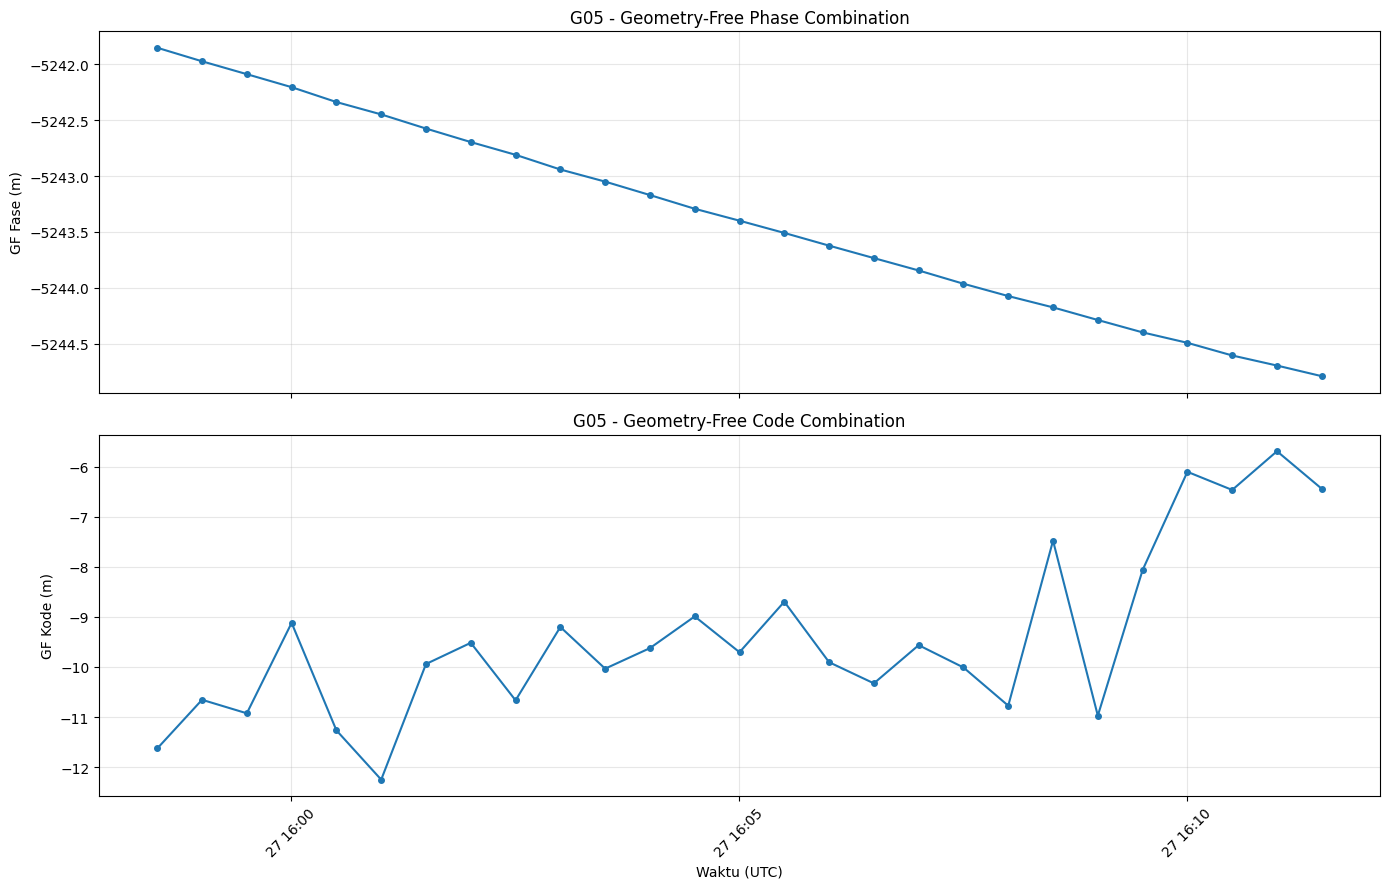

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Membaca hasil pemeriksaan G05
file_path = Path.cwd() / "Detail_G05_Koreksi_GF_DOY300.csv"

df_g05_koreksi = pd.read_csv(
    file_path,
    parse_dates=["Waktu"]
)

# Mengurutkan berdasarkan waktu
df_g05_koreksi = df_g05_koreksi.sort_values("Waktu").reset_index(drop=True)

# Menampilkan informasi awal
print("Jumlah data:", len(df_g05_koreksi))
print("Waktu awal:", df_g05_koreksi["Waktu"].min())
print("Waktu akhir:", df_g05_koreksi["Waktu"].max())

print("\nKolom dataset:")
print(df_g05_koreksi.columns.tolist())

display(df_g05_koreksi.head())

# Membuat grafik GF fase dan GF kode
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True
)

# Grafik GF fase
axes[0].plot(
    df_g05_koreksi["Waktu"],
    df_g05_koreksi["GF_fase_m"],
    marker="o",
    markersize=4
)

axes[0].set_title("G05 - Geometry-Free Phase Combination")
axes[0].set_ylabel("GF Fase (m)")
axes[0].grid(True, alpha=0.3)

# Grafik GF kode
axes[1].plot(
    df_g05_koreksi["Waktu"],
    df_g05_koreksi["GF_kode_m"],
    marker="o",
    markersize=4
)

axes[1].set_title("G05 - Geometry-Free Code Combination")
axes[1].set_xlabel("Waktu (UTC)")
axes[1].set_ylabel("GF Kode (m)")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Memeriksa perubahan GF fase G05 antarepoch

df_g05_valid = df_g05_koreksi.dropna(
    subset=["GF_fase_m"]
).copy()

df_g05_valid = df_g05_valid.sort_values("Waktu").reset_index(drop=True)

df_g05_valid["Delta_GF_fase_m"] = (
    df_g05_valid["GF_fase_m"].diff()
)

delta = df_g05_valid["Delta_GF_fase_m"].dropna()

print("JUMLAH EPOCH GF FASE:", len(df_g05_valid))
print("JUMLAH PERUBAHAN ANTAREPOCH:", len(delta))

print("\nSTATISTIK DELTA GF FASE")
display(delta.describe().to_frame("Delta_GF_fase_m"))

print("\nPERUBAHAN GF FASE TERBESAR")
idx_max = delta.abs().idxmax()
display(
    df_g05_valid.loc[
        [idx_max - 1, idx_max],
        ["Waktu", "GF_fase_m", "Delta_GF_fase_m",
         "LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]
    ]
)

print("\nEPOCH DENGAN INDIKASI LLI BIT 0")
mask_lli = (
    df_g05_valid["LLI_L1"].astype(str).str.strip().isin(["1", "3", "5", "7"])
    | df_g05_valid["LLI_L2"].astype(str).str.strip().isin(["1", "3", "5", "7"])
)

display(
    df_g05_valid.loc[
        mask_lli,
        ["Waktu", "LLI_L1", "LLI_L2", "GF_fase_m"]
    ]
)

JUMLAH EPOCH GF FASE: 27
JUMLAH PERUBAHAN ANTAREPOCH: 26

STATISTIK DELTA GF FASE


,Delta_GF_fase_m
count,26.000000
mean,-0.112986
std,0.010400
min,-0.133028
25%,-0.119795
50%,-0.112955
75%,-0.109644
max,-0.090269



PERUBAHAN GF FASE TERBESAR


,Waktu,GF_fase_m,Delta_GF_fase_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2
3,2003-10-27 16:00:00.086,-5242.205113,-0.116346,4,4,3,2
4,2003-10-27 16:00:30.086,-5242.338141,-0.133028,4,4,3,2



EPOCH DENGAN INDIKASI LLI BIT 0


,Waktu,LLI_L1,LLI_L2,GF_fase_m
0,2003-10-27 15:58:30.085,4,5,-5241.852495


In [ ]:
import georinex as gr
import pandas as pd
import numpy as np
from pathlib import Path

# Memastikan file RINEX tersedia
rinex_path = Path.cwd() / "bako3000.03o"

print("Lokasi file:", rinex_path)
print("File ditemukan:", rinex_path.exists())

# Memuat data RINEX
obs = gr.load(str(rinex_path))

print("\nData RINEX berhasil dimuat.")
print(obs)

Lokasi file: c:\SKRIPSI AKHIR\ALL DATA\GNSS\CDDIS_GNSS Data Daily\HALLOWEEN STORM 2003\DOY 300_27 OCT 2003\BAKO\bako3000.03o
File ditemukan: True

Data RINEX berhasil dimuat.
<xarray.Dataset> Size: 4MB
Dimensions:  (time: 2878, sv: 28)
Coordinates:
  * time     (time) datetime64[ns] 23kB 2003-10-27T00:00:30 ... 2003-10-27T23...
  * sv       (sv) <U3 336B 'G01' 'G02' 'G03' 'G04' ... 'G28' 'G29' 'G30' 'G31'
Data variables:
    L1       (time, sv) float64 645kB nan nan nan nan ... nan nan 3.487e+07 nan
    L2       (time, sv) float64 645kB nan nan nan nan ... nan nan 1.001e+07 nan
    C1       (time, sv) float64 645kB nan nan nan nan ... nan nan 5.949e+07 nan
    P2       (time, sv) float64 645kB nan nan nan nan ... nan nan 5.949e+07 nan
    P1       (time, sv) float64 645kB nan nan nan nan nan ... nan nan nan nan
    D1       (time, sv) float64 645kB nan nan nan nan ... nan nan -2.228e+03 nan
Attributes:
    version:          2.1
    interval:         30.0
    rinextype:        obs
    f

c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [ ]:
import pandas as pd
import numpy as np

data_l1 = obs["L1"].values
data_l2 = obs["L2"].values
daftar_sv = obs.sv.values
waktu = pd.DatetimeIndex(obs.time.values)

ringkasan_sat = []

for i, sv in enumerate(daftar_sv):

    l1 = data_l1[:, i]
    l2 = data_l2[:, i]

    valid_l1 = np.isfinite(l1)
    valid_l2 = np.isfinite(l2)
    valid_pair = valid_l1 & valid_l2

    waktu_pair = waktu[valid_pair]

    if len(waktu_pair) > 0:
        interval = (
            pd.Series(waktu_pair)
            .diff()
            .dt.total_seconds()
            .dropna()
        )

        jumlah_gap = int((interval > 30.5).sum())
        gap_maks = interval.max() if len(interval) > 0 else np.nan

        waktu_awal = waktu_pair.min()
        waktu_akhir = waktu_pair.max()

    else:
        jumlah_gap = np.nan
        gap_maks = np.nan
        waktu_awal = pd.NaT
        waktu_akhir = pd.NaT

    ringkasan_sat.append({
        "Satelit": str(sv),
        "Jumlah_L1": int(valid_l1.sum()),
        "Jumlah_L2": int(valid_l2.sum()),
        "Jumlah_Pasangan_L1_L2": int(valid_pair.sum()),
        "Epoch_Pertama": waktu_awal,
        "Epoch_Terakhir": waktu_akhir,
        "Jumlah_Gap_lebih_30.5s": jumlah_gap,
        "Interval_Maksimum_detik": gap_maks
    })

df_ringkasan_sat = pd.DataFrame(ringkasan_sat)

display(
    df_ringkasan_sat.sort_values(
        "Jumlah_Pasangan_L1_L2",
        ascending=False
    ).reset_index(drop=True)
)

,Satelit,Jumlah_L1,Jumlah_L2,Jumlah_Pasangan_L1_L2,Epoch_Pertama,Epoch_Terakhir,Jumlah_Gap_lebih_30.5s,Interval_Maksimum_detik
0,G24,1186,1168,1168,2003-10-27 11:43:00.063,2003-10-27 21:30:30.114,3,149.999
1,G07,1173,1161,1161,2003-10-27 08:31:30.045,2003-10-27 18:14:30.097,2,120.000
2,G25,1133,1124,1124,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128,3,52560.077
3,G20,1101,1094,1094,2003-10-27 04:01:00.022,2003-10-27 13:10:00.070,4,90.000
4,G02,1083,1068,1068,2003-10-27 01:39:30.009,2003-10-27 10:56:00.058,3,1260.003
5,G05,1084,1064,1064,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128,7,53910.079
6,G14,1069,1058,1058,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128,5,51060.076
7,G30,1042,1029,1029,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128,6,55140.081
8,G13,1047,1006,1006,2003-10-27 06:40:00.036,2003-10-27 15:17:30.082,6,390.001
9,G06,1029,998,998,2003-10-27 00:00:30.000,2003-10-27 23:59:00.128,8,55890.084


In [ ]:
# Mengidentifikasi seluruh gap pasangan L1-L2 pada setiap satelit

daftar_gap = []

for i, sv in enumerate(daftar_sv):

    valid_pair = (
        np.isfinite(data_l1[:, i]) &
        np.isfinite(data_l2[:, i])
    )

    waktu_pair = waktu[valid_pair]

    if len(waktu_pair) < 2:
        continue

    # Menghitung interval dalam detik
    interval = (
        np.diff(waktu_pair.values)
        / np.timedelta64(1, "s")
    )

    indeks_gap = np.where(interval > 30.5)[0]

    for j in indeks_gap:
        durasi = float(interval[j])

        daftar_gap.append({
            "Satelit": str(sv),
            "Waktu_Sebelum_Gap": waktu_pair[j],
            "Waktu_Sesudah_Gap": waktu_pair[j + 1],
            "Durasi_Gap_detik": round(durasi, 3),
            "Perkiraan_Epoch_Hilang": max(
                0, round(durasi / 30) - 1
            )
        })

df_gap_sat = pd.DataFrame(daftar_gap)

if not df_gap_sat.empty:
    df_gap_sat = df_gap_sat.sort_values(
        ["Durasi_Gap_detik", "Satelit"],
        ascending=[False, True]
    ).reset_index(drop=True)

    print("Jumlah seluruh gap:", len(df_gap_sat))
    display(df_gap_sat)
else:
    print("Tidak ditemukan gap.")

Jumlah seluruh gap: 80


,Satelit,Waktu_Sebelum_Gap,Waktu_Sesudah_Gap,Durasi_Gap_detik,Perkiraan_Epoch_Hilang
0,G23,2003-10-27 05:13:30.027,2003-10-27 23:49:30.126,66960.099,2231
1,G21,2003-10-27 02:00:00.011,2003-10-27 20:23:30.109,66210.098,2206
2,G18,2003-10-27 03:29:00.019,2003-10-27 21:44:30.115,65730.096,2190
3,G15,2003-10-27 05:34:00.030,2003-10-27 22:11:00.118,59820.088,1993
4,G06,2003-10-27 03:12:30.016,2003-10-27 18:44:00.100,55890.084,1862
...,...,...,...,...,...
75,G20,2003-10-27 07:00:00.037,2003-10-27 07:01:00.037,60.000,1
76,G20,2003-10-27 08:16:00.044,2003-10-27 08:17:00.044,60.000,1
77,G20,2003-10-27 08:49:30.047,2003-10-27 08:50:30.047,60.000,1
78,G25,2003-10-27 01:16:00.007,2003-10-27 01:17:00.007,60.000,1


In [ ]:
# Ringkasan gap untuk setiap satelit

ringkasan_gap = []

for sv in daftar_sv:

    df_sv = df_gap_sat[
        df_gap_sat["Satelit"] == str(sv)
    ]

    if len(df_sv) == 0:
        continue

    ringkasan_gap.append({
        "Satelit": str(sv),
        "Jumlah_Gap": len(df_sv),
        "Gap_60_150_detik": int(
            df_sv["Durasi_Gap_detik"].between(30.5, 150).sum()
        ),
        "Gap_lebih_150_detik": int(
            (df_sv["Durasi_Gap_detik"] > 150).sum()
        ),
        "Gap_Maksimum_detik": df_sv["Durasi_Gap_detik"].max(),
        "Jumlah_Arc_Sementara": len(df_sv) + 1
    })

df_ringkasan_gap = pd.DataFrame(ringkasan_gap)

display(
    df_ringkasan_gap.sort_values(
        "Jumlah_Gap",
        ascending=False
    ).reset_index(drop=True)
)

,Satelit,Jumlah_Gap,Gap_60_150_detik,Gap_lebih_150_detik,Gap_Maksimum_detik,Jumlah_Arc_Sementara
0,G04,13,7,6,4110.005,14
1,G06,8,7,1,55890.084,9
2,G05,7,5,2,53910.079,8
3,G13,6,3,3,390.001,7
4,G30,6,5,1,55140.081,7
5,G14,5,1,4,51060.076,6
6,G15,5,1,4,59820.088,6
7,G18,4,3,1,65730.096,5
8,G20,4,4,0,90.000,5
9,G02,3,1,2,1260.003,4


In [ ]:
# MEMBENTUK INVENTARISASI ARC SELURUH SATELIT

daftar_arc = []

for i, sv in enumerate(daftar_sv):

    valid_pair = (
        np.isfinite(data_l1[:, i]) &
        np.isfinite(data_l2[:, i])
    )

    indeks_valid = np.where(valid_pair)[0]

    if len(indeks_valid) == 0:
        continue

    # Memisahkan kelompok pengamatan berdasarkan gap > 30,5 detik
    waktu_valid = waktu[indeks_valid]

    interval = (
        np.diff(waktu_valid.values)
        / np.timedelta64(1, "s")
    )

    batas_arc = np.where(interval > 30.5)[0] + 1

    kelompok_arc = np.split(indeks_valid, batas_arc)

    for nomor_arc, indeks_arc in enumerate(kelompok_arc, start=1):

        waktu_awal = waktu[indeks_arc[0]]
        waktu_akhir = waktu[indeks_arc[-1]]

        jumlah_epoch = len(indeks_arc)

        durasi_menit = (
            (waktu_akhir - waktu_awal).total_seconds() / 60
        )

        daftar_arc.append({
            "Satelit": str(sv),
            "Arc_ID": nomor_arc,
            "Waktu_Awal": waktu_awal,
            "Waktu_Akhir": waktu_akhir,
            "Jumlah_Epoch": jumlah_epoch,
            "Durasi_Menit": round(durasi_menit, 2)
        })

df_arc = pd.DataFrame(daftar_arc)

# Ringkasan jumlah arc setiap satelit
df_ringkasan_arc = (
    df_arc.groupby("Satelit")
    .agg(
        Jumlah_Arc=("Arc_ID", "count"),
        Total_Epoch=("Jumlah_Epoch", "sum"),
        Arc_Terpendek_Epoch=("Jumlah_Epoch", "min"),
        Arc_Terpanjang_Epoch=("Jumlah_Epoch", "max")
    )
    .reset_index()
)

print("JUMLAH SELURUH ARC:", len(df_arc))
print("JUMLAH SATELIT:", df_arc["Satelit"].nunique())

print("\nRINGKASAN ARC SETIAP SATELIT")
display(
    df_ringkasan_arc.sort_values(
        "Satelit"
    ).reset_index(drop=True)
)

print("\nDAFTAR ARC")
display(df_arc)

JUMLAH SELURUH ARC: 108
JUMLAH SATELIT: 28

RINGKASAN ARC SETIAP SATELIT


,Satelit,Jumlah_Arc,Total_Epoch,Arc_Terpendek_Epoch,Arc_Terpanjang_Epoch
0,G01,2,691,162,529
1,G02,4,1068,2,840
2,G03,1,724,724,724
3,G04,14,939,1,731
4,G05,8,1064,1,371
5,G06,9,998,2,577
6,G07,3,1161,91,703
7,G08,2,715,5,710
8,G09,4,827,12,620
9,G10,1,660,660,660



DAFTAR ARC


,Satelit,Arc_ID,Waktu_Awal,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit
0,G01,1,2003-10-27 05:35:30.030,2003-10-27 09:59:30.053,529,264.0
1,G01,2,2003-10-27 10:00:30.053,2003-10-27 11:21:00.061,162,80.5
2,G02,1,2003-10-27 01:39:30.009,2003-10-27 08:39:00.046,840,419.5
3,G02,2,2003-10-27 08:40:00.046,2003-10-27 10:07:30.053,176,87.5
4,G02,3,2003-10-27 10:10:00.054,2003-10-27 10:10:30.053,2,0.5
...,...,...,...,...,...,...
103,G30,4,2003-10-27 18:03:00.096,2003-10-27 20:37:30.109,310,154.5
104,G30,5,2003-10-27 20:39:30.109,2003-10-27 20:46:30.111,15,7.0
105,G30,6,2003-10-27 20:48:00.111,2003-10-27 21:06:30.112,38,18.5
106,G30,7,2003-10-27 21:07:30.112,2003-10-27 23:59:00.128,344,171.5


In [ ]:
# KLASIFIKASI AWAL KELAYAKAN ARC

def klasifikasi_arc(jumlah_epoch):
    if jumlah_epoch == 1:
        return "Tidak memadai"
    elif jumlah_epoch <= 9:
        return "Sangat pendek"
    elif jumlah_epoch <= 29:
        return "Pendek"
    else:
        return "Kandidat analisis"

df_arc["Kategori_Awal"] = df_arc["Jumlah_Epoch"].apply(
    klasifikasi_arc
)

# Ringkasan jumlah arc setiap kategori
df_kategori_arc = (
    df_arc.groupby("Kategori_Awal")
    .agg(
        Jumlah_Arc=("Arc_ID", "count"),
        Total_Epoch=("Jumlah_Epoch", "sum"),
        Rata_rata_Epoch=("Jumlah_Epoch", "mean"),
        Minimum_Epoch=("Jumlah_Epoch", "min"),
        Maksimum_Epoch=("Jumlah_Epoch", "max")
    )
    .reset_index()
)

urutan_kategori = [
    "Tidak memadai",
    "Sangat pendek",
    "Pendek",
    "Kandidat analisis"
]

df_kategori_arc["Kategori_Awal"] = pd.Categorical(
    df_kategori_arc["Kategori_Awal"],
    categories=urutan_kategori,
    ordered=True
)

df_kategori_arc = df_kategori_arc.sort_values(
    "Kategori_Awal"
).reset_index(drop=True)

print("RINGKASAN KATEGORI ARC")
display(df_kategori_arc)

# Tampilkan seluruh arc yang belum masuk kandidat analisis
df_arc_perlu_ditinjau = df_arc[
    df_arc["Jumlah_Epoch"] < 30
].sort_values(
    ["Satelit", "Arc_ID"]
).reset_index(drop=True)

print("ARC YANG PERLU DITINJAU")
display(df_arc_perlu_ditinjau)

RINGKASAN KATEGORI ARC


,Kategori_Awal,Jumlah_Arc,Total_Epoch,Rata_rata_Epoch,Minimum_Epoch,Maksimum_Epoch
0,Tidak memadai,5,5,1.000000,1,1
1,Sangat pendek,16,73,4.562500,2,9
2,Pendek,11,219,19.909091,12,28
3,Kandidat analisis,76,23583,310.302632,32,840


ARC YANG PERLU DITINJAU


,Satelit,Arc_ID,Waktu_Awal,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit,Kategori_Awal
0,G02,3,2003-10-27 10:10:00.054,2003-10-27 10:10:30.053,2,0.5,Sangat pendek
1,G04,2,2003-10-27 17:10:30.091,2003-10-27 17:12:30.091,5,2.0,Sangat pendek
2,G04,3,2003-10-27 17:16:00.092,2003-10-27 17:16:30.091,2,0.5,Sangat pendek
3,G04,4,2003-10-27 17:20:00.093,2003-10-27 17:21:00.093,3,1.0,Sangat pendek
4,G04,5,2003-10-27 17:22:30.092,2003-10-27 17:23:30.092,3,1.0,Sangat pendek
5,G04,6,2003-10-27 17:25:30.092,2003-10-27 17:35:00.094,20,9.5,Pendek
6,G04,7,2003-10-27 17:36:30.094,2003-10-27 17:39:00.094,6,2.5,Sangat pendek
7,G04,8,2003-10-27 17:41:00.095,2003-10-27 17:44:00.095,7,3.0,Sangat pendek
8,G04,9,2003-10-27 17:49:30.094,2003-10-27 17:51:00.095,4,1.5,Sangat pendek
9,G04,11,2003-10-27 18:22:30.097,2003-10-27 18:32:00.099,20,9.5,Pendek


In [ ]:
# VALIDASI RINGKASAN KLASIFIKASI ARC

print("Jumlah seluruh arc:", len(df_arc))
print("Jumlah satelit:", df_arc["Satelit"].nunique())

print("\nDistribusi kategori:")
display(
    df_arc["Kategori_Awal"]
    .value_counts()
    .reindex([
        "Tidak memadai",
        "Sangat pendek",
        "Pendek",
        "Kandidat analisis"
    ])
    .rename_axis("Kategori")
    .reset_index(name="Jumlah_Arc")
)

# Ambil kandidat awal untuk pemeriksaan fase berikutnya
df_arc_kandidat = df_arc[
    df_arc["Jumlah_Epoch"] >= 30
].copy().reset_index(drop=True)

print("\nJumlah arc kandidat pemeriksaan fase:", len(df_arc_kandidat))
display(df_arc_kandidat.head(10))

Jumlah seluruh arc: 108
Jumlah satelit: 28

Distribusi kategori:


,Kategori,Jumlah_Arc
0,Tidak memadai,5
1,Sangat pendek,16
2,Pendek,11
3,Kandidat analisis,76



Jumlah arc kandidat pemeriksaan fase: 76


,Satelit,Arc_ID,Waktu_Awal,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit,Kategori_Awal
0,G01,1,2003-10-27 05:35:30.030,2003-10-27 09:59:30.053,529,264.0,Kandidat analisis
1,G01,2,2003-10-27 10:00:30.053,2003-10-27 11:21:00.061,162,80.5,Kandidat analisis
2,G02,1,2003-10-27 01:39:30.009,2003-10-27 08:39:00.046,840,419.5,Kandidat analisis
3,G02,2,2003-10-27 08:40:00.046,2003-10-27 10:07:30.053,176,87.5,Kandidat analisis
4,G02,4,2003-10-27 10:31:30.056,2003-10-27 10:56:00.058,50,24.5,Kandidat analisis
5,G03,1,2003-10-27 02:22:00.013,2003-10-27 08:23:30.045,724,361.5,Kandidat analisis
6,G04,1,2003-10-27 09:57:00.053,2003-10-27 16:02:00.086,731,365.0,Kandidat analisis
7,G04,10,2003-10-27 17:54:00.096,2003-10-27 18:20:30.097,54,26.5,Kandidat analisis
8,G04,14,2003-10-27 19:01:00.102,2003-10-27 19:39:00.105,77,38.0,Kandidat analisis
9,G05,1,2003-10-27 00:00:30.000,2003-10-27 01:00:00.006,120,59.5,Kandidat analisis


In [ ]:
# PEMERIKSAAN VARIABEL OBSERVASI DAN METADATA

print("Variabel dalam dataset:")
print(list(obs.data_vars))

print("\nDimensi dataset:")
print(obs.dims)

print("\nAtribut dataset:")
print(obs.attrs)

print("\nAtribut setiap variabel:")
for nama_var in obs.data_vars:
    print(f"\n{nama_var}:")
    print(obs[nama_var].attrs)

Variabel dalam dataset:
['L1', 'L2', 'C1', 'P2', 'P1', 'D1']

Dimensi dataset:
FrozenMappingWarningOnValuesAccess({'time': 2878, 'sv': 28})

Atribut dataset:
{'version': 2.1, 'interval': np.float64(30.0), 'rinextype': 'obs', 'fast_processing': 0, 'time_system': 'GPS', 'filename': 'bako3000.03o', 'rxmodel': 'TRIMBLE 4000SSE NP 7.19 / SP', 'position': [-1836967.8873, 6065615.4384, -716260.3127]}

Atribut setiap variabel:

L1:
{}

L2:
{}

C1:
{}

P2:
{}

P1:
{}

D1:
{}


In [ ]:
# MENGHITUNG GF PHASE UNTUK SELURUH 76 ARC KANDIDAT

c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

daftar_hasil_gf = []

for _, arc in df_arc_kandidat.iterrows():

    sv = arc["Satelit"]
    arc_id = arc["Arc_ID"]

    indeks_sv = list(daftar_sv).index(sv)

    # Ambil pasangan L1 dan L2 yang valid
    valid_pair = (
        np.isfinite(data_l1[:, indeks_sv]) &
        np.isfinite(data_l2[:, indeks_sv])
    )

    indeks_valid = np.where(valid_pair)[0]

    waktu_valid = waktu[indeks_valid]

    # Pilih epoch yang termasuk arc
    mask_arc = (
        (waktu_valid >= arc["Waktu_Awal"]) &
        (waktu_valid <= arc["Waktu_Akhir"])
    )

    indeks_arc = indeks_valid[mask_arc]

    L1_arc = data_l1[indeks_arc, indeks_sv]
    L2_arc = data_l2[indeks_arc, indeks_sv]
    waktu_arc = waktu[indeks_arc]

    GF_phase = lambda1 * L1_arc - lambda2 * L2_arc

    delta_GF = np.insert(np.diff(GF_phase), 0, np.nan)

    for i in range(len(indeks_arc)):
        daftar_hasil_gf.append({
            "Satelit": sv,
            "Arc_ID": arc_id,
            "Waktu": waktu_arc[i],
            "L1": L1_arc[i],
            "L2": L2_arc[i],
            "GF_Phase_m": GF_phase[i],
            "Delta_GF_m": delta_GF[i]
        })

df_gf_arc = pd.DataFrame(daftar_hasil_gf)

print("Jumlah baris GF phase:", len(df_gf_arc))
print("Jumlah arc:", df_gf_arc.groupby(
    ["Satelit", "Arc_ID"]
).ngroups)

print("\nContoh hasil:")
display(df_gf_arc.head(10))

Jumlah baris GF phase: 23583
Jumlah arc: 76

Contoh hasil:


,Satelit,Arc_ID,Waktu,L1,L2,GF_Phase_m,Delta_GF_m
0,G01,1,2003-10-27 05:35:30.030,-70391.485,0.129,-13395.085717,NaN
1,G01,1,2003-10-27 05:36:00.030,-106229.678,-27925.580,-13395.123735,-0.038018
2,G01,1,2003-10-27 05:36:30.030,-142095.558,-55872.919,-13395.148147,-0.024412
3,G01,1,2003-10-27 05:37:00.030,-177986.581,-83839.827,-13395.178162,-0.030016
4,G01,1,2003-10-27 05:37:30.030,-213896.205,-111821.208,-13395.213376,-0.035214
5,G01,1,2003-10-27 05:38:00.030,-249821.753,-139814.977,-13395.253550,-0.040174
6,G01,1,2003-10-27 05:38:30.030,-285762.932,-167820.971,-13395.282735,-0.029185
7,G01,1,2003-10-27 05:39:00.030,-321719.613,-195838.982,-13395.327178,-0.044443
8,G01,1,2003-10-27 05:39:30.030,-357685.996,-223864.635,-13395.351596,-0.024418
9,G01,1,2003-10-27 05:40:00.030,-393662.527,-251898.136,-13395.390552,-0.038956


In [ ]:
# STATISTIK DAN PENYARINGAN AWAL DELTA GF PHASE

df_delta_valid = df_gf_arc.dropna(
    subset=["Delta_GF_m"]
).copy()

# Statistik global
print("STATISTIK GLOBAL DELTA GF PHASE")
display(
    df_delta_valid["Delta_GF_m"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    ).to_frame()
)

# Urutkan perubahan GF berdasarkan nilai absolut
df_delta_valid["Abs_Delta_GF_m"] = (
    df_delta_valid["Delta_GF_m"].abs()
)

df_delta_terbesar = df_delta_valid.sort_values(
    "Abs_Delta_GF_m",
    ascending=False
).reset_index(drop=True)

print("\n20 PERUBAHAN DELTA GF TERBESAR")
display(
    df_delta_terbesar[
        [
            "Satelit",
            "Arc_ID",
            "Waktu",
            "Delta_GF_m",
            "Abs_Delta_GF_m"
        ]
    ].head(20)
)

# Penanda awal untuk investigasi
ambang_awal = 0.5

df_kandidat_anomali = df_delta_valid[
    df_delta_valid["Abs_Delta_GF_m"] > ambang_awal
].copy()

print(
    f"\nJumlah perubahan GF > {ambang_awal} m:",
    len(df_kandidat_anomali)
)

print("\nDAFTAR KANDIDAT ANOMALI AWAL")
display(
    df_kandidat_anomali[
        [
            "Satelit",
            "Arc_ID",
            "Waktu",
            "Delta_GF_m",
            "Abs_Delta_GF_m"
        ]
    ].sort_values(
        "Abs_Delta_GF_m",
        ascending=False
    ).reset_index(drop=True)
)

STATISTIK GLOBAL DELTA GF PHASE


,Delta_GF_m
count,23507.000000
mean,-19.948821
std,3058.711488
min,-468961.420871
50%,-0.000181
90%,0.026359
95%,0.035915
99%,0.056086
99.9%,0.097384
max,0.113983



20 PERUBAHAN DELTA GF TERBESAR


,Satelit,Arc_ID,Waktu,Delta_GF_m,Abs_Delta_GF_m
0,G14,2,2003-10-27 01:24:30.007,-468961.420871,468961.420871
1,G05,2,2003-10-27 16:00:30.085,-0.133028,0.133028
2,G05,2,2003-10-27 16:03:00.086,-0.131350,0.131350
3,G05,2,2003-10-27 16:01:30.085,-0.126482,0.126482
4,G05,2,2003-10-27 16:04:30.085,-0.122673,0.122673
5,G05,2,2003-10-27 15:59:00.085,-0.121106,0.121106
6,G05,2,2003-10-27 16:02:00.086,-0.120827,0.120827
7,G05,2,2003-10-27 16:04:00.086,-0.120136,0.120136
8,G05,2,2003-10-27 16:07:30.085,-0.118772,0.118772
9,G05,2,2003-10-27 16:00:00.086,-0.116346,0.116346



Jumlah perubahan GF > 0.5 m: 1

DAFTAR KANDIDAT ANOMALI AWAL


,Satelit,Arc_ID,Waktu,Delta_GF_m,Abs_Delta_GF_m
0,G14,2,2003-10-27 01:24:30.007,-468961.420871,468961.420871


In [ ]:
# Mengecualikan G14 dari evaluasi statistik
df_gf_tanpa_g14 = df_delta_valid[
    df_delta_valid["Satelit"] != "G14"
].copy()

df_gf_tanpa_g14["Abs_Delta_GF_m"] = (
    df_gf_tanpa_g14["Delta_GF_m"].abs()
)

print("STATISTIK DELTA GF TANPA G14")
display(
    df_gf_tanpa_g14["Delta_GF_m"].describe(
        percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
    ).to_frame()
)

print("\n10 PERUBAHAN DELTA GF TERBESAR TANPA G14")
display(
    df_gf_tanpa_g14
    .sort_values("Abs_Delta_GF_m", ascending=False)
    [[
        "Satelit",
        "Arc_ID",
        "Waktu",
        "Delta_GF_m",
        "Abs_Delta_GF_m"
    ]]
    .head(10)
    .reset_index(drop=True)
)

print("\nJUMLAH PERUBAHAN BERDASARKAN RENTANG MAGNITUDO")
for ambang in [0.1, 0.2, 0.5, 1.0]:
    jumlah = (
        df_gf_tanpa_g14["Abs_Delta_GF_m"] > ambang
    ).sum()
    print(f"|Delta GF| > {ambang} m: {jumlah} data")

STATISTIK DELTA GF TANPA G14


,Delta_GF_m
count,22478.000000
mean,0.000653
std,0.021514
min,-0.133028
50%,-0.000541
90%,0.026033
95%,0.035831
99%,0.056599
99.9%,0.097452
max,0.113983



10 PERUBAHAN DELTA GF TERBESAR TANPA G14


,Satelit,Arc_ID,Waktu,Delta_GF_m,Abs_Delta_GF_m
0,G05,2,2003-10-27 16:00:30.085,-0.133028,0.133028
1,G05,2,2003-10-27 16:03:00.086,-0.131350,0.131350
2,G05,2,2003-10-27 16:01:30.085,-0.126482,0.126482
3,G05,2,2003-10-27 16:04:30.085,-0.122673,0.122673
4,G05,2,2003-10-27 15:59:00.085,-0.121106,0.121106
5,G05,2,2003-10-27 16:02:00.086,-0.120827,0.120827
6,G05,2,2003-10-27 16:04:00.086,-0.120136,0.120136
7,G05,2,2003-10-27 16:07:30.085,-0.118772,0.118772
8,G05,2,2003-10-27 16:00:00.086,-0.116346,0.116346
9,G05,2,2003-10-27 15:59:30.085,-0.115166,0.115166



JUMLAH PERUBAHAN BERDASARKAN RENTANG MAGNITUDO
|Delta GF| > 0.1 m: 38 data
|Delta GF| > 0.2 m: 0 data
|Delta GF| > 0.5 m: 0 data
|Delta GF| > 1.0 m: 0 data


In [ ]:
# Mengelompokkan 38 perubahan GF yang melebihi 0,1 m
df_kandidat_01 = df_gf_tanpa_g14[
    df_gf_tanpa_g14["Abs_Delta_GF_m"] > 0.1
].copy()

# Ringkasan jumlah kandidat berdasarkan satelit
ringkasan_sat = (
    df_kandidat_01
    .groupby("Satelit")
    .agg(
        Jumlah_Kandidat=("Delta_GF_m", "count"),
        Delta_GF_Min=("Delta_GF_m", "min"),
        Delta_GF_Maks=("Delta_GF_m", "max"),
        Magnitudo_Maks=("Abs_Delta_GF_m", "max")
    )
    .sort_values("Jumlah_Kandidat", ascending=False)
    .reset_index()
)

print("DISTRIBUSI KANDIDAT |DELTA GF| > 0,1 m PER SATELIT")
display(ringkasan_sat)

print("\nDAFTAR SELURUH KANDIDAT")
display(
    df_kandidat_01[
        ["Satelit", "Arc_ID", "Waktu", "Delta_GF_m", "Abs_Delta_GF_m"]
    ].sort_values("Abs_Delta_GF_m", ascending=False)
    .reset_index(drop=True)
)

DISTRIBUSI KANDIDAT |DELTA GF| > 0,1 m PER SATELIT


,Satelit,Jumlah_Kandidat,Delta_GF_Min,Delta_GF_Maks,Magnitudo_Maks
0,G05,23,-0.133028,-0.101208,0.133028
1,G30,12,0.100399,0.113983,0.113983
2,G02,2,-0.105518,-0.101912,0.105518
3,G28,1,-0.110326,-0.110326,0.110326



DAFTAR SELURUH KANDIDAT


,Satelit,Arc_ID,Waktu,Delta_GF_m,Abs_Delta_GF_m
0,G05,2,2003-10-27 16:00:30.085,-0.133028,0.133028
1,G05,2,2003-10-27 16:03:00.086,-0.131350,0.131350
2,G05,2,2003-10-27 16:01:30.085,-0.126482,0.126482
3,G05,2,2003-10-27 16:04:30.085,-0.122673,0.122673
4,G05,2,2003-10-27 15:59:00.085,-0.121106,0.121106
5,G05,2,2003-10-27 16:02:00.086,-0.120827,0.120827
6,G05,2,2003-10-27 16:04:00.086,-0.120136,0.120136
7,G05,2,2003-10-27 16:07:30.085,-0.118772,0.118772
8,G05,2,2003-10-27 16:00:00.086,-0.116346,0.116346
9,G05,2,2003-10-27 15:59:30.085,-0.115166,0.115166


In [ ]:
# Menghitung perubahan fase mentah L1 dan L2
df_gf_detail = df_gf_arc.copy()

df_gf_detail = df_gf_detail.sort_values(
    ["Satelit", "Arc_ID", "Waktu"]
).reset_index(drop=True)

df_gf_detail["Delta_L1_cycle"] = (
    df_gf_detail.groupby(["Satelit", "Arc_ID"])["L1"].diff()
)

df_gf_detail["Delta_L2_cycle"] = (
    df_gf_detail.groupby(["Satelit", "Arc_ID"])["L2"].diff()
)

# Mengambil baris yang termasuk 38 kandidat
df_pemeriksaan = df_gf_detail.merge(
    df_kandidat_01[["Satelit", "Arc_ID", "Waktu"]],
    on=["Satelit", "Arc_ID", "Waktu"],
    how="inner"
)

print("PEMERIKSAAN PERUBAHAN FASE MENTAH PADA 38 KANDIDAT")
display(
    df_pemeriksaan[
        [
            "Satelit",
            "Arc_ID",
            "Waktu",
            "Delta_GF_m",
            "Delta_L1_cycle",
            "Delta_L2_cycle"
        ]
    ].sort_values(
        ["Satelit", "Waktu"]
    ).reset_index(drop=True)
)

PEMERIKSAAN PERUBAHAN FASE MENTAH PADA 38 KANDIDAT


,Satelit,Arc_ID,Waktu,Delta_GF_m,Delta_L1_cycle,Delta_L2_cycle
0,G02,2,2003-10-27 10:02:00.054,-0.101912,54990.489,42850.149
1,G02,4,2003-10-27 10:34:30.056,-0.105518,74545.802,58088.070
2,G05,2,2003-10-27 15:59:00.085,-0.121106,-10267.271,-7999.975
3,G05,2,2003-10-27 15:59:30.085,-0.115166,-10004.014,-7794.864
4,G05,2,2003-10-27 16:00:00.086,-0.116346,-9740.557,-7589.568
5,G05,2,2003-10-27 16:00:30.085,-0.133028,-9480.744,-7387.048
6,G05,2,2003-10-27 16:01:00.086,-0.110576,-9213.291,-7178.735
7,G05,2,2003-10-27 16:01:30.085,-0.126482,-8948.424,-6972.280
8,G05,2,2003-10-27 16:02:00.086,-0.120827,-8677.507,-6761.199
9,G05,2,2003-10-27 16:02:30.085,-0.114024,-8409.107,-6552.084


In [ ]:
# Menampilkan urutan fase mentah di sekitar setiap kandidat
daftar_detail = []

for _, kandidat in df_kandidat_01.iterrows():
    sv = kandidat["Satelit"]
    arc_id = kandidat["Arc_ID"]
    waktu_kandidat = kandidat["Waktu"]

    df_lokal = df_gf_detail[
        (df_gf_detail["Satelit"] == sv) &
        (df_gf_detail["Arc_ID"] == arc_id)
    ].sort_values("Waktu").reset_index(drop=True)

    posisi = df_lokal.index[
        df_lokal["Waktu"] == waktu_kandidat
    ].tolist()

    if not posisi:
        continue

    i = posisi[0]

    # Mengambil dua epoch sebelum sampai dua epoch sesudah
    awal = max(0, i - 2)
    akhir = min(len(df_lokal), i + 3)

    bagian = df_lokal.iloc[awal:akhir].copy()
    bagian["Waktu_Kandidat"] = waktu_kandidat

    daftar_detail.append(bagian)

df_detail_sekitar = pd.concat(
    daftar_detail,
    ignore_index=True
)

display(
    df_detail_sekitar[
        [
            "Satelit",
            "Arc_ID",
            "Waktu",
            "Waktu_Kandidat",
            "L1",
            "L2",
            "GF_Phase_m",
            "Delta_L1_cycle",
            "Delta_L2_cycle",
            "Delta_GF_m"
        ]
    ].sort_values(
        ["Satelit", "Waktu_Kandidat", "Waktu"]
    ).reset_index(drop=True)
)

,Satelit,Arc_ID,Waktu,Waktu_Kandidat,L1,L2,GF_Phase_m,Delta_L1_cycle,Delta_L2_cycle,Delta_GF_m
0,G02,2,2003-10-27 10:01:00.053,2003-10-27 10:02:00.054,7.394611e+07,5.911692e+06,1.262778e+07,54546.171,42503.808,-0.072806
1,G02,2,2003-10-27 10:01:30.053,2003-10-27 10:02:00.054,7.400088e+07,5.954372e+06,1.262778e+07,54772.198,42679.652,-0.004199
2,G02,2,2003-10-27 10:02:00.054,2003-10-27 10:02:00.054,7.405587e+07,5.997222e+06,1.262778e+07,54990.489,42850.149,-0.101912
3,G02,2,2003-10-27 10:02:30.053,2003-10-27 10:02:00.054,7.411109e+07,6.040251e+06,1.262778e+07,55220.190,43028.879,-0.038956
4,G02,2,2003-10-27 10:03:00.054,2003-10-27 10:02:00.054,7.416654e+07,6.083456e+06,1.262778e+07,55446.396,43205.250,-0.064985
...,...,...,...,...,...,...,...,...,...,...
183,G30,1,2003-10-27 02:20:30.013,2003-10-27 02:19:30.013,6.935603e+07,3.229923e+07,5.310212e+06,171849.748,133908.490,0.098794
184,G30,1,2003-10-27 02:19:00.013,2003-10-27 02:20:00.013,6.884094e+07,3.189786e+07,5.310212e+06,171383.827,133545.461,0.092365
185,G30,1,2003-10-27 02:19:30.013,2003-10-27 02:20:00.013,6.901248e+07,3.203153e+07,5.310212e+06,171538.840,133666.184,0.108569
186,G30,1,2003-10-27 02:20:00.013,2003-10-27 02:20:00.013,6.918418e+07,3.216532e+07,5.310212e+06,171694.642,133787.605,0.104455


In [ ]:
# PEMERIKSAAN LLI DAN SSI PADA 4 SATELIT KANDIDAT

from pathlib import Path
import pandas as pd

# Membaca ulang RINEX agar indikator LLI dan SSI tersedia
lines = rinex_path.read_text(errors="replace").splitlines()

rentang_pemeriksaan = {
    "G02": (
        pd.Timestamp("2003-10-27 10:00:00"),
        pd.Timestamp("2003-10-27 10:36:00")
    ),
    "G05": (
        pd.Timestamp("2003-10-27 15:57:00"),
        pd.Timestamp("2003-10-27 16:12:00")
    ),
    "G28": (
        pd.Timestamp("2003-10-27 11:07:00"),
        pd.Timestamp("2003-10-27 11:13:00")
    ),
    "G30": (
        pd.Timestamp("2003-10-27 02:07:00"),
        pd.Timestamp("2003-10-27 02:22:00")
    )
}

hasil_lli = []

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

        waktu_epoch = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            ) + pd.Timedelta(seconds=second)
        )

        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

    except (ValueError, TypeError):
        continue

    # Hanya epoch observasi normal
    if flag != 0:
        continue

    # Daftar satelit pada header epoch
    sat_text = line[32:32 + jumlah_sv * 3]

    satelit_epoch = [
        sat_text[j:j+3].replace(" ", "0")
        for j in range(0, len(sat_text), 3)
    ]

    for sv, (waktu_awal, waktu_akhir) in rentang_pemeriksaan.items():

        if not (waktu_awal <= waktu_epoch <= waktu_akhir):
            continue

        if sv not in satelit_epoch:
            continue

        posisi = satelit_epoch.index(sv)
        indeks_baris = i + 1 + posisi * 2

        if indeks_baris >= len(lines):
            continue

        obs_line = lines[indeks_baris].ljust(80)

        field_l1 = obs_line[0:16]
        field_l2 = obs_line[16:32]

        hasil_lli.append({
            "Satelit": sv,
            "Waktu": waktu_epoch,
            "L1": field_l1[0:14].strip(),
            "LLI_L1": field_l1[14],
            "SSI_L1": field_l1[15],
            "L2": field_l2[0:14].strip(),
            "LLI_L2": field_l2[14],
            "SSI_L2": field_l2[15]
        })

df_lli_kandidat = pd.DataFrame(hasil_lli)

if not df_lli_kandidat.empty:
    df_lli_kandidat = df_lli_kandidat.sort_values(
        ["Satelit", "Waktu"]
    ).reset_index(drop=True)

display(df_lli_kandidat)

,Satelit,Waktu,L1,LLI_L1,SSI_L1,L2,LLI_L2,SSI_L2
0,G02,2003-10-27 10:00:00.053,73837233.175,4,5,5826853.514,4,3
1,G02,2003-10-27 10:00:30.053,73891562.715,4,5,5869188.415,4,3
2,G02,2003-10-27 10:01:00.053,73946108.886,4,5,5911692.223,4,2
3,G02,2003-10-27 10:01:30.054,74000881.084,4,4,5954371.875,4,1
4,G02,2003-10-27 10:02:00.054,74055871.573,4,4,5997222.024,4,2
...,...,...,...,...,...,...,...,...
104,G30,2003-10-27 02:18:30.012,68669559.703,4,4,31764319.032,4,3
105,G30,2003-10-27 02:19:00.013,68840943.530,4,4,31897864.493,4,4
106,G30,2003-10-27 02:19:30.013,69012482.370,4,4,32031530.677,4,4
107,G30,2003-10-27 02:20:00.013,69184177.012,4,4,32165318.282,4,3


In [ ]:
# RINGKASAN LLI DAN SSI UNTUK SETIAP SATELIT

df_lli_ringkasan = df_lli_kandidat.copy()

# Konversi indikator ke numerik
for kolom in ["LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]:
    df_lli_ringkasan[kolom] = pd.to_numeric(
        df_lli_ringkasan[kolom],
        errors="coerce"
    )

ringkasan_lli = (
    df_lli_ringkasan
    .groupby("Satelit")
    .agg(
        Jumlah_Epoch=("Waktu", "count"),
        LLI_L1_Unik=("LLI_L1", lambda x: sorted(x.dropna().unique())),
        LLI_L2_Unik=("LLI_L2", lambda x: sorted(x.dropna().unique())),
        Jumlah_LLI_L1_Bit0=("LLI_L1", lambda x: ((x.fillna(0).astype(int) & 1) != 0).sum()),
        Jumlah_LLI_L2_Bit0=("LLI_L2", lambda x: ((x.fillna(0).astype(int) & 1) != 0).sum()),
        SSI_L1_Min=("SSI_L1", "min"),
        SSI_L1_Maks=("SSI_L1", "max"),
        SSI_L2_Min=("SSI_L2", "min"),
        SSI_L2_Maks=("SSI_L2", "max")
    )
    .reset_index()
)

display(ringkasan_lli)

print("\nEPOCH DENGAN INDIKASI BIT 0 LLI AKTIF")
df_bit0 = df_lli_ringkasan[
    (
        (df_lli_ringkasan["LLI_L1"].fillna(0).astype(int) & 1) != 0
    ) |
    (
        (df_lli_ringkasan["LLI_L2"].fillna(0).astype(int) & 1) != 0
    )
]

display(df_bit0)

,Satelit,Jumlah_Epoch,LLI_L1_Unik,LLI_L2_Unik,Jumlah_LLI_L1_Bit0,Jumlah_LLI_L2_Bit0,SSI_L1_Min,SSI_L1_Maks,SSI_L2_Min,SSI_L2_Maks
0,G02,40,"[4, 5]","[4.0, 5.0]",3,2,1,5,1.0,3.0
1,G05,29,"[4, 5]","[4.0, 5.0]",1,1,2,5,2.0,5.0
2,G28,12,[4],[4.0],0,0,3,4,2.0,3.0
3,G30,28,[4],[4.0],0,0,4,5,3.0,5.0



EPOCH DENGAN INDIKASI BIT 0 LLI AKTIF


,Satelit,Waktu,L1,LLI_L1,SSI_L1,L2,LLI_L2,SSI_L2
20,G02,2003-10-27 10:10:00.054,74968488.635,4,2,9204.225,5.0,1.0
24,G02,2003-10-27 10:18:30.055,2130.512,5,1,,NaN,NaN
25,G02,2003-10-27 10:23:30.056,24597.967,5,1,,NaN,NaN
26,G02,2003-10-27 10:29:00.056,40078.405,5,1,,NaN,NaN
31,G02,2003-10-27 10:31:30.056,398568.643,4,1,16951.056,5.0,1.0
40,G05,2003-10-27 15:57:30.085,-6228.897,5,2,,NaN,NaN
42,G05,2003-10-27 15:58:30.085,-27546.543,4,4,-.329,5.0,2.0


In [ ]:
# PEMERIKSAAN KONTINUITAS FASE G02

df_g02_detail = df_gf_arc[
    (df_gf_arc["Satelit"] == "G02") &
    (df_gf_arc["Waktu"] >= pd.Timestamp("2003-10-27 09:58:00")) &
    (df_gf_arc["Waktu"] <= pd.Timestamp("2003-10-27 10:36:00"))
].copy()

# Ambil informasi LLI dan SSI G02
df_g02_lli = df_lli_kandidat[
    (df_lli_kandidat["Satelit"] == "G02")
].copy()

# Gabungkan berdasarkan waktu
df_g02_detail = df_g02_detail.merge(
    df_g02_lli[
        ["Waktu", "LLI_L1", "SSI_L1", "LLI_L2", "SSI_L2"]
    ],
    on="Waktu",
    how="left"
)

# Hitung perubahan fase pembawa dalam siklus
df_g02_detail["Delta_L1_cycle"] = (
    df_g02_detail["L1"].diff()
)

df_g02_detail["Delta_L2_cycle"] = (
    df_g02_detail["L2"].diff()
)

display(df_g02_detail[
    [
        "Waktu",
        "L1",
        "L2",
        "Delta_L1_cycle",
        "Delta_L2_cycle",
        "GF_Phase_m",
        "Delta_GF_m",
        "LLI_L1",
        "LLI_L2",
        "SSI_L1",
        "SSI_L2"
    ]
].to_string(index=False))

'                  Waktu           L1          L2  Delta_L1_cycle  Delta_L2_cycle   GF_Phase_m  Delta_GF_m LLI_L1 LLI_L2 SSI_L1 SSI_L2\n2003-10-27 09:58:00.053 73622071.422 5659194.106             NaN             NaN 1.262778e+07   -0.049153    NaN    NaN    NaN    NaN\n2003-10-27 09:58:30.053 73675543.174 5700860.643    5.347175e+04       41666.537 1.262778e+07   -0.057814    NaN    NaN    NaN    NaN\n2003-10-27 09:59:00.053 73729225.861 5742691.467    5.368269e+04       41830.824 1.262778e+07   -0.038782    NaN    NaN    NaN    NaN\n2003-10-27 09:59:30.053 73783121.471 5784688.305    5.389561e+04       41996.838 1.262778e+07   -0.063197    NaN    NaN    NaN    NaN\n2003-10-27 10:00:00.053 73837233.175 5826853.514    5.411170e+04       42165.209 1.262778e+07   -0.059793      4      4      5      3\n2003-10-27 10:00:30.053 73891562.715 5869188.415    5.432954e+04       42334.901 1.262778e+07   -0.047500      4      4      5      3\n2003-10-27 10:01:00.053 73946108.886 5911692.223    5.

In [ ]:
# SAMAKAN TIPE DATETIME SEBELUM MERGE_ASOF

df_g02_fase["Waktu"] = pd.to_datetime(
    df_g02_fase["Waktu"]
).astype("datetime64[ns]")

df_g02_lli["Waktu"] = pd.to_datetime(
    df_g02_lli["Waktu"]
).astype("datetime64[ns]")

df_g02_fase = df_g02_fase.sort_values("Waktu")
df_g02_lli = df_g02_lli.sort_values("Waktu")

df_g02_detail_koreksi = pd.merge_asof(
    df_g02_fase,
    df_g02_lli[
        ["Waktu", "LLI_L1", "SSI_L1", "LLI_L2", "SSI_L2"]
    ],
    on="Waktu",
    direction="nearest",
    tolerance=pd.Timedelta(seconds=0.01)
)

df_g02_detail_koreksi["Delta_L1_cycle"] = (
    df_g02_detail_koreksi["L1"].diff()
)

df_g02_detail_koreksi["Delta_L2_cycle"] = (
    df_g02_detail_koreksi["L2"].diff()
)

display(df_g02_detail_koreksi[
    [
        "Waktu",
        "L1",
        "L2",
        "Delta_L1_cycle",
        "Delta_L2_cycle",
        "GF_Phase_m",
        "Delta_GF_m",
        "LLI_L1",
        "LLI_L2",
        "SSI_L1",
        "SSI_L2"
    ]
].to_string(index=False))

'                  Waktu           L1          L2  Delta_L1_cycle  Delta_L2_cycle   GF_Phase_m  Delta_GF_m LLI_L1 LLI_L2 SSI_L1 SSI_L2\n2003-10-27 09:58:00.053 73622071.422 5659194.106             NaN             NaN 1.262778e+07   -0.049153    NaN    NaN    NaN    NaN\n2003-10-27 09:58:30.053 73675543.174 5700860.643    5.347175e+04       41666.537 1.262778e+07   -0.057814    NaN    NaN    NaN    NaN\n2003-10-27 09:59:00.053 73729225.861 5742691.467    5.368269e+04       41830.824 1.262778e+07   -0.038782    NaN    NaN    NaN    NaN\n2003-10-27 09:59:30.053 73783121.471 5784688.305    5.389561e+04       41996.838 1.262778e+07   -0.063197    NaN    NaN    NaN    NaN\n2003-10-27 10:00:00.053 73837233.175 5826853.514    5.411170e+04       42165.209 1.262778e+07   -0.059793      4      4      5      3\n2003-10-27 10:00:30.053 73891562.715 5869188.415    5.432954e+04       42334.901 1.262778e+07   -0.047500      4      4      5      3\n2003-10-27 10:01:00.053 73946108.886 5911692.223    5.

In [ ]:
# INVENTARISASI ARC G02 BERDASARKAN KONTINUITAS WAKTU

df_g02_arc = df_arc[
    df_arc["Satelit"] == "G02"
].copy()

display(
    df_g02_arc[
        [
            "Satelit",
            "Arc_ID",
            "Waktu_Awal",
            "Waktu_Akhir",
            "Jumlah_Epoch",
            "Durasi_Menit"
        ]
    ].to_string(index=False)
)

print("Jumlah arc G02:", len(df_g02_arc))
print("Total epoch G02:", df_g02_arc["Jumlah_Epoch"].sum())

'Satelit  Arc_ID              Waktu_Awal             Waktu_Akhir  Jumlah_Epoch  Durasi_Menit\n    G02       1 2003-10-27 01:39:30.009 2003-10-27 08:39:00.046           840         419.5\n    G02       2 2003-10-27 08:40:00.046 2003-10-27 10:07:30.053           176          87.5\n    G02       3 2003-10-27 10:10:00.054 2003-10-27 10:10:30.053             2           0.5\n    G02       4 2003-10-27 10:31:30.056 2003-10-27 10:56:00.058            50          24.5'

Jumlah arc G02: 4
Total epoch G02: 1068


In [ ]:
# PEMERIKSAAN LLI BIT 0 PADA SELURUH ARC G02

df_g02_semua_lli = df_lli_kandidat[
    df_lli_kandidat["Satelit"] == "G02"
].copy()

df_g02_semua_lli["LLI_L1"] = pd.to_numeric(
    df_g02_semua_lli["LLI_L1"], errors="coerce"
)

df_g02_semua_lli["LLI_L2"] = pd.to_numeric(
    df_g02_semua_lli["LLI_L2"], errors="coerce"
)

hasil_g02 = []

for _, arc in df_g02_arc.iterrows():
    awal = arc["Waktu_Awal"]
    akhir = arc["Waktu_Akhir"]

    data_arc = df_g02_semua_lli[
        (df_g02_semua_lli["Waktu"] >= awal) &
        (df_g02_semua_lli["Waktu"] <= akhir)
    ].copy()

    bit0_l1 = (
        data_arc["LLI_L1"].fillna(0).astype(int) & 1
    ) != 0

    bit0_l2 = (
        data_arc["LLI_L2"].fillna(0).astype(int) & 1
    ) != 0

    kejadian = data_arc[bit0_l1 | bit0_l2]

    hasil_g02.append({
        "Arc_ID": arc["Arc_ID"],
        "Waktu_Awal": awal,
        "Waktu_Akhir": akhir,
        "Jumlah_Epoch_Terendeksi": len(data_arc),
        "Jumlah_LLI_Bit0": len(kejadian),
        "Waktu_LLI_Bit0": kejadian["Waktu"].tolist()
    })

df_evaluasi_lli_g02 = pd.DataFrame(hasil_g02)

display(df_evaluasi_lli_g02.to_string(index=False))

' Arc_ID              Waktu_Awal             Waktu_Akhir  Jumlah_Epoch_Terendeksi  Jumlah_LLI_Bit0               Waktu_LLI_Bit0\n      1 2003-10-27 01:39:30.009 2003-10-27 08:39:00.046                        0                0                           []\n      2 2003-10-27 08:40:00.046 2003-10-27 10:07:30.053                       15                0                           []\n      3 2003-10-27 10:10:00.054 2003-10-27 10:10:30.053                        1                1 [2003-10-27 10:10:00.054000]\n      4 2003-10-27 10:31:30.056 2003-10-27 10:56:00.058                        9                1 [2003-10-27 10:31:30.056000]'

In [ ]:
# EKSTRAKSI LLI/SSI G02 DARI SELURUH FILE RINEX

lines = rinex_path.read_text(errors="replace").splitlines()

hasil_g02_full = []

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

        waktu_epoch = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            )
            + pd.Timedelta(seconds=second)
        )

        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

    except (ValueError, TypeError):
        continue

    if flag != 0:
        continue

    sat_text = line[32:32 + jumlah_sv * 3]

    satelit_epoch = [
        sat_text[j:j+3].replace(" ", "0")
        for j in range(0, len(sat_text), 3)
    ]

    if "G02" not in satelit_epoch:
        continue

    posisi = satelit_epoch.index("G02")
    indeks_baris = i + 1 + posisi * 2

    if indeks_baris >= len(lines):
        continue

    obs_line = lines[indeks_baris].ljust(80)

    field_l1 = obs_line[0:16]
    field_l2 = obs_line[16:32]

    hasil_g02_full.append({
        "Waktu": waktu_epoch,
        "L1": field_l1[0:14].strip(),
        "LLI_L1": field_l1[14],
        "SSI_L1": field_l1[15],
        "L2": field_l2[0:14].strip(),
        "LLI_L2": field_l2[14],
        "SSI_L2": field_l2[15]
    })

df_g02_lli_full = pd.DataFrame(hasil_g02_full)

# Konversi kolom LLI dan SSI
for kolom in ["LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]:
    df_g02_lli_full[kolom] = pd.to_numeric(
        df_g02_lli_full[kolom],
        errors="coerce"
    )

# Identifikasi bit 0
bit0_l1 = (
    df_g02_lli_full["LLI_L1"].fillna(0).astype(int) & 1
) != 0

bit0_l2 = (
    df_g02_lli_full["LLI_L2"].fillna(0).astype(int) & 1
) != 0

df_g02_lli_full["Indikasi_Bit0"] = bit0_l1 | bit0_l2

# Hubungkan setiap epoch dengan Arc_ID berdasarkan inventaris arc
df_g02_lli_full["Arc_ID"] = pd.NA

for _, arc in df_g02_arc.iterrows():
    mask = (
        (df_g02_lli_full["Waktu"] >= arc["Waktu_Awal"]) &
        (df_g02_lli_full["Waktu"] <= arc["Waktu_Akhir"])
    )
    df_g02_lli_full.loc[mask, "Arc_ID"] = int(arc["Arc_ID"])

# Ringkasan per arc
ringkasan_g02_full = (
    df_g02_lli_full
    .groupby("Arc_ID", dropna=False)
    .agg(
        Jumlah_Epoch=("Waktu", "count"),
        Jumlah_LLI_L1_Bit0=(
            "LLI_L1",
            lambda x: ((x.fillna(0).astype(int) & 1) != 0).sum()
        ),
        Jumlah_LLI_L2_Bit0=(
            "LLI_L2",
            lambda x: ((x.fillna(0).astype(int) & 1) != 0).sum()
        )
    )
    .reset_index()
)

print("Total epoch G02 yang diekstrak:", len(df_g02_lli_full))

print("\nRINGKASAN LLI PER ARC")
display(ringkasan_g02_full)

print("\nSELURUH EPOCH DENGAN INDIKASI BIT 0")
display(
    df_g02_lli_full[
        df_g02_lli_full["Indikasi_Bit0"]
    ][
        [
            "Arc_ID", "Waktu",
            "L1", "LLI_L1", "SSI_L1",
            "L2", "LLI_L2", "SSI_L2"
        ]
    ].to_string(index=False)
)

Total epoch G02 yang diekstrak: 1084

RINGKASAN LLI PER ARC


,Arc_ID,Jumlah_Epoch,Jumlah_LLI_L1_Bit0,Jumlah_LLI_L2_Bit0
0,NaN,18,3,0
1,1.0,840,0,1
2,2.0,175,0,1
3,3.0,1,0,1
4,4.0,50,0,1



SELURUH EPOCH DENGAN INDIKASI BIT 0


'Arc_ID                   Waktu           L1  LLI_L1  SSI_L1        L2  LLI_L2  SSI_L2\n     1 2003-10-27 01:39:30.009   -56865.120     4.0     4.0      .603     5.0     3.0\n     2 2003-10-27 08:40:00.046 66362726.634     4.0     3.0  2555.909     5.0     2.0\n     3 2003-10-27 10:10:00.054 74968488.635     4.0     2.0  9204.225     5.0     1.0\n  <NA> 2003-10-27 10:18:30.055     2130.512     5.0     1.0               NaN     NaN\n  <NA> 2003-10-27 10:23:30.056    24597.967     5.0     1.0               NaN     NaN\n  <NA> 2003-10-27 10:29:00.056    40078.405     5.0     1.0               NaN     NaN\n     4 2003-10-27 10:31:30.056   398568.643     4.0     1.0 16951.056     5.0     1.0'

In [ ]:
# MEMBANDINGKAN EPOCH PASANGAN L1-L2 DENGAN EPOCH EKSTRAKSI LLI

indeks_g02 = list(daftar_sv).index("G02")

valid_g02 = (
    np.isfinite(data_l1[:, indeks_g02]) &
    np.isfinite(data_l2[:, indeks_g02])
)

df_waktu_pasangan_g02 = pd.DataFrame({
    "Waktu": waktu[valid_g02]
})

df_waktu_lli_g02 = df_g02_lli_full[["Waktu"]].copy()

df_waktu_pasangan_g02["Waktu"] = pd.to_datetime(
    df_waktu_pasangan_g02["Waktu"]
).astype("datetime64[ns]")

df_waktu_lli_g02["Waktu"] = pd.to_datetime(
    df_waktu_lli_g02["Waktu"]
).astype("datetime64[ns]")

# Cocokkan waktu
perbandingan = df_waktu_pasangan_g02.merge(
    df_waktu_lli_g02,
    on="Waktu",
    how="left",
    indicator=True
)

waktu_tidak_ditemukan = perbandingan[
    perbandingan["_merge"] == "left_only"
]

print("Jumlah epoch pasangan L1-L2:", len(df_waktu_pasangan_g02))
print("Jumlah epoch hasil ekstraksi LLI:", len(df_waktu_lli_g02))
print("Epoch pasangan yang tidak ditemukan di ekstraksi LLI:",
      len(waktu_tidak_ditemukan))

display(waktu_tidak_ditemukan)

Jumlah epoch pasangan L1-L2: 1068
Jumlah epoch hasil ekstraksi LLI: 1084
Epoch pasangan yang tidak ditemukan di ekstraksi LLI: 274


,Waktu,_merge
34,2003-10-27 01:56:30.010,left_only
36,2003-10-27 01:57:30.010,left_only
38,2003-10-27 01:58:30.010,left_only
40,2003-10-27 01:59:30.010,left_only
42,2003-10-27 02:00:30.010,left_only
...,...,...
1058,2003-10-27 10:51:30.057,left_only
1060,2003-10-27 10:52:30.057,left_only
1062,2003-10-27 10:53:30.057,left_only
1064,2003-10-27 10:54:30.057,left_only


In [ ]:
import pandas as pd
import numpy as np

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Pandas version: 3.0.2
NumPy version: 2.4.4


In [ ]:
# MEMBANGUN ULANG DATA LLI G02 DARI FILE RINEX

import pandas as pd
import numpy as np
from pathlib import Path

# Membaca ulang file RINEX
rinex_path = Path.cwd() / "bako3000.03o"
lines = rinex_path.read_text(errors="replace").splitlines()

hasil_g02_full = []

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

        waktu_epoch = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            ) + pd.Timedelta(seconds=second)
        )

        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

    except (ValueError, TypeError):
        continue

    if flag != 0:
        continue

    sat_text = line[32:32 + jumlah_sv * 3]

    satelit_epoch = [
        sat_text[j:j+3].replace(" ", "0")
        for j in range(0, len(sat_text), 3)
    ]

    if "G02" not in satelit_epoch:
        continue

    posisi = satelit_epoch.index("G02")
    indeks_baris = i + 1 + posisi * 2

    if indeks_baris >= len(lines):
        continue

    obs_line = lines[indeks_baris].ljust(80)

    field_l1 = obs_line[0:16]
    field_l2 = obs_line[16:32]

    hasil_g02_full.append({
        "Waktu": waktu_epoch,
        "L1": field_l1[0:14].strip(),
        "LLI_L1": field_l1[14],
        "SSI_L1": field_l1[15],
        "L2": field_l2[0:14].strip(),
        "LLI_L2": field_l2[14],
        "SSI_L2": field_l2[15]
    })

df_g02_lli_full = pd.DataFrame(hasil_g02_full)

for kolom in ["LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]:
    df_g02_lli_full[kolom] = pd.to_numeric(
        df_g02_lli_full[kolom],
        errors="coerce"
    )

# Membuat ulang tabel waktu pasangan L1-L2
indeks_g02 = list(daftar_sv).index("G02")

valid_g02 = (
    np.isfinite(data_l1[:, indeks_g02]) &
    np.isfinite(data_l2[:, indeks_g02])
)

df_waktu_pasangan_g02 = pd.DataFrame({
    "Waktu": waktu[valid_g02]
})

df_waktu_lli_g02 = df_g02_lli_full[["Waktu"]].copy()

print("Jumlah epoch pasangan L1-L2:", len(df_waktu_pasangan_g02))
print("Jumlah epoch hasil ekstraksi LLI:", len(df_waktu_lli_g02))

print("\nContoh data LLI G02:")
display(df_g02_lli_full.head())

print("\nContoh timestamp pasangan L1-L2:")
display(df_waktu_pasangan_g02.head())

Jumlah epoch pasangan L1-L2: 1068
Jumlah epoch hasil ekstraksi LLI: 1084

Contoh data LLI G02:


,Waktu,L1,LLI_L1,SSI_L1,L2,LLI_L2,SSI_L2
0,2003-10-27 01:38:30.009,,NaN,NaN,,NaN,NaN
1,2003-10-27 01:39:00.009,-28044.082,4.0,4.0,,NaN,NaN
2,2003-10-27 01:39:30.009,-56865.120,4.0,4.0,.603,5.0,3.0
3,2003-10-27 01:40:00.009,-85485.670,4.0,4.0,-22301.052,4.0,3.0
4,2003-10-27 01:40:30.009,-113906.558,4.0,5.0,-44447.094,4.0,4.0



Contoh timestamp pasangan L1-L2:


,Waktu
0,2003-10-27 01:39:30.009
1,2003-10-27 01:40:00.009
2,2003-10-27 01:40:30.009
3,2003-10-27 01:41:00.009
4,2003-10-27 01:41:30.009


In [79]:
# MEMERIKSA KETERSEDIAAN DATA DASAR

variabel_diperlukan = [
    "pd",
    "np",
    "obs",
    "daftar_sv",
    "data_l1",
    "data_l2",
    "waktu",
    "df_g02_lli_full"
]

for nama in variabel_diperlukan:
    print(f"{nama}: {'Tersedia' if nama in globals() else 'Belum tersedia'}")

pd: Tersedia
np: Tersedia
obs: Tersedia
daftar_sv: Tersedia
data_l1: Tersedia
data_l2: Tersedia
waktu: Tersedia
df_g02_lli_full: Belum tersedia


In [80]:
# MEMBANGUN ULANG DATA LLI G02

from pathlib import Path

# Membaca file RINEX
rinex_path = Path.cwd() / "bako3000.03o"
lines = rinex_path.read_text(errors="replace").splitlines()

hasil_g02_full = []

for i, line in enumerate(lines):

    if len(line) < 32:
        continue

    try:
        yy = int(line[1:3])
        month = int(line[4:6])
        day = int(line[7:9])
        hour = int(line[10:12])
        minute = int(line[13:15])
        second = float(line[15:26])

        waktu_epoch = (
            pd.Timestamp(
                year=2000 + yy,
                month=month,
                day=day,
                hour=hour,
                minute=minute
            ) + pd.Timedelta(seconds=second)
        )

        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

    except (ValueError, TypeError):
        continue

    if flag != 0:
        continue

    sat_text = line[32:32 + jumlah_sv * 3]

    satelit_epoch = [
        sat_text[j:j+3].replace(" ", "0")
        for j in range(0, len(sat_text), 3)
    ]

    if "G02" not in satelit_epoch:
        continue

    posisi = satelit_epoch.index("G02")
    indeks_baris = i + 1 + posisi * 2

    if indeks_baris >= len(lines):
        continue

    obs_line = lines[indeks_baris].ljust(80)

    field_l1 = obs_line[0:16]
    field_l2 = obs_line[16:32]

    hasil_g02_full.append({
        "Waktu": waktu_epoch,
        "L1": field_l1[0:14].strip(),
        "LLI_L1": field_l1[14],
        "SSI_L1": field_l1[15],
        "L2": field_l2[0:14].strip(),
        "LLI_L2": field_l2[14],
        "SSI_L2": field_l2[15]
    })

df_g02_lli_full = pd.DataFrame(hasil_g02_full)

for kolom in ["LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]:
    df_g02_lli_full[kolom] = pd.to_numeric(
        df_g02_lli_full[kolom],
        errors="coerce"
    )

print("Jumlah epoch G02:", len(df_g02_lli_full))
print("Jumlah timestamp unik:", df_g02_lli_full["Waktu"].nunique())

display(df_g02_lli_full.head(10))

Jumlah epoch G02: 1084
Jumlah timestamp unik: 1084


,Waktu,L1,LLI_L1,SSI_L1,L2,LLI_L2,SSI_L2
0,2003-10-27 01:38:30.009,,NaN,NaN,,NaN,NaN
1,2003-10-27 01:39:00.009,-28044.082,4.0,4.0,,NaN,NaN
2,2003-10-27 01:39:30.009,-56865.120,4.0,4.0,.603,5.0,3.0
3,2003-10-27 01:40:00.009,-85485.670,4.0,4.0,-22301.052,4.0,3.0
4,2003-10-27 01:40:30.009,-113906.558,4.0,5.0,-44447.094,4.0,4.0
5,2003-10-27 01:41:00.009,-142121.075,4.0,5.0,-66432.365,4.0,4.0
6,2003-10-27 01:41:30.009,-170131.485,4.0,5.0,-88258.544,4.0,5.0
7,2003-10-27 01:42:00.009,-197931.820,4.0,5.0,-109921.066,4.0,5.0
8,2003-10-27 01:42:30.009,-225521.107,4.0,5.0,-131419.110,4.0,5.0
9,2003-10-27 01:43:00.009,-252900.628,4.0,5.0,-152753.709,4.0,5.0


In [82]:
# NEAREST MATCHING TIMESTAMP G02
# Menyamakan presisi waktu terlebih dahulu

# 1. Menyalin kedua tabel agar data asli tidak berubah
df_pair = df_waktu_pasangan_g02.copy()
df_lli = df_waktu_lli_g02.copy()

# 2. Menyamakan tipe waktu menjadi datetime64[ns]
df_pair["Waktu"] = pd.to_datetime(
    df_pair["Waktu"]
).astype("datetime64[ns]")

df_lli["Waktu"] = pd.to_datetime(
    df_lli["Waktu"]
).astype("datetime64[ns]")

# 3. Mengurutkan waktu
df_pair = df_pair.sort_values("Waktu").reset_index(drop=True)
df_lli = df_lli.sort_values("Waktu").reset_index(drop=True)

# 4. Mencocokkan waktu terdekat
df_diagnostik = pd.merge_asof(
    df_pair.rename(columns={"Waktu": "Waktu_Pasangan"}),
    df_lli.rename(columns={"Waktu": "Waktu_LLI"}),
    left_on="Waktu_Pasangan",
    right_on="Waktu_LLI",
    direction="nearest"
)

# 5. Menghitung selisih waktu dalam detik
df_diagnostik["Selisih_detik"] = (
    df_diagnostik["Waktu_Pasangan"] -
    df_diagnostik["Waktu_LLI"]
).dt.total_seconds().abs()

# 6. Menampilkan hasil diagnostik
print("Jumlah pasangan yang diperiksa:", len(df_diagnostik))

print("\nStatistik selisih waktu:")
display(df_diagnostik["Selisih_detik"].describe())

print("\nDistribusi selisih waktu:")
display(
    df_diagnostik["Selisih_detik"]
    .value_counts()
    .sort_index()
    .head(20)
)

print("\nContoh 20 hasil pencocokan:")
display(df_diagnostik.head(20))

Jumlah pasangan yang diperiksa: 1068

Statistik selisih waktu:


count    1068.000000
mean        0.000257
std         0.000437
min         0.000000
25%         0.000000
50%         0.000000
75%         0.001000
max         0.001000
Name: Selisih_detik, dtype: float64


Distribusi selisih waktu:


Selisih_detik
0.000    794
0.001    274
Name: count, dtype: int64


Contoh 20 hasil pencocokan:


,Waktu_Pasangan,Waktu_LLI,Selisih_detik
0,2003-10-27 01:39:30.009,2003-10-27 01:39:30.009,0.0
1,2003-10-27 01:40:00.009,2003-10-27 01:40:00.009,0.0
2,2003-10-27 01:40:30.009,2003-10-27 01:40:30.009,0.0
3,2003-10-27 01:41:00.009,2003-10-27 01:41:00.009,0.0
4,2003-10-27 01:41:30.009,2003-10-27 01:41:30.009,0.0
5,2003-10-27 01:42:00.009,2003-10-27 01:42:00.009,0.0
6,2003-10-27 01:42:30.009,2003-10-27 01:42:30.009,0.0
7,2003-10-27 01:43:00.009,2003-10-27 01:43:00.009,0.0
8,2003-10-27 01:43:30.009,2003-10-27 01:43:30.009,0.0
9,2003-10-27 01:44:00.009,2003-10-27 01:44:00.009,0.0


In [86]:
print("Tipe waktu tabel pasangan:")
print(df_waktu_pasangan_g02["Waktu"].dtype)

print("\nTipe waktu tabel LLI:")
print(df_g02_lli_full["Waktu"].dtype)

print("\nSetelah konversi:")

waktu_pair_test = pd.to_datetime(
    df_waktu_pasangan_g02["Waktu"]
).astype("datetime64[ns]")

waktu_lli_test = pd.to_datetime(
    df_g02_lli_full["Waktu"]
).astype("datetime64[ns]")

print("Pasangan:", waktu_pair_test.dtype)
print("LLI:", waktu_lli_test.dtype)

print("\nApakah tipe keduanya sama?")
print(waktu_pair_test.dtype == waktu_lli_test.dtype)

Tipe waktu tabel pasangan:
datetime64[ns]

Tipe waktu tabel LLI:
datetime64[us]

Setelah konversi:
Pasangan: datetime64[ns]
LLI: datetime64[ns]

Apakah tipe keduanya sama?
True


In [87]:
# 1. Membuat salinan tabel pasangan L1-L2
df_pair_g02 = df_waktu_pasangan_g02.copy()

# 2. Membuat salinan tabel LLI
df_lli_g02 = df_g02_lli_full[
    ["Waktu", "LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]
].copy()

# 3. Menyeragamkan tipe waktu
df_pair_g02["Waktu"] = pd.to_datetime(
    df_pair_g02["Waktu"]
).astype("datetime64[ns]")

df_lli_g02["Waktu"] = pd.to_datetime(
    df_lli_g02["Waktu"]
).astype("datetime64[ns]")

# 4. Memastikan nilai LLI dan SSI berupa angka
for kolom in ["LLI_L1", "LLI_L2", "SSI_L1", "SSI_L2"]:
    df_lli_g02[kolom] = pd.to_numeric(
        df_lli_g02[kolom], errors="coerce"
    )

# 5. Mengurutkan kedua tabel berdasarkan waktu
df_pair_g02 = df_pair_g02.sort_values("Waktu")
df_lli_g02 = df_lli_g02.sort_values("Waktu")

# 6. Menggabungkan berdasarkan waktu terdekat
df_g02_pair_lli = pd.merge_asof(
    df_pair_g02,
    df_lli_g02,
    on="Waktu",
    direction="nearest",
    tolerance=pd.Timedelta(milliseconds=10)
)

# 7. Menghitung indikasi LLI bit 0
bit0_l1 = (
    df_g02_pair_lli["LLI_L1"].fillna(0).astype(int) & 1
) != 0

bit0_l2 = (
    df_g02_pair_lli["LLI_L2"].fillna(0).astype(int) & 1
) != 0

df_g02_pair_lli["Indikasi_Bit0"] = bit0_l1 | bit0_l2

# 8. Menampilkan ringkasan
print("Jumlah epoch pasangan:", len(df_g02_pair_lli))

print(
    "Epoch berhasil memperoleh LLI:",
    df_g02_pair_lli["LLI_L1"].notna().sum()
)

print(
    "Jumlah indikasi bit 0:",
    df_g02_pair_lli["Indikasi_Bit0"].sum()
)

print("\nDistribusi LLI L1:")
display(df_g02_pair_lli["LLI_L1"].value_counts(dropna=False).sort_index())

print("\nDistribusi LLI L2:")
display(df_g02_pair_lli["LLI_L2"].value_counts(dropna=False).sort_index())

print("\nEpoch dengan indikasi bit 0:")
display(
    df_g02_pair_lli[
        df_g02_pair_lli["Indikasi_Bit0"]
    ]
)

print("\nLima baris pertama:")
display(df_g02_pair_lli.head())

Jumlah epoch pasangan: 1068
Epoch berhasil memperoleh LLI: 1068
Jumlah indikasi bit 0: 4

Distribusi LLI L1:


LLI_L1
4.0    1068
Name: count, dtype: int64


Distribusi LLI L2:


LLI_L2
4.0    1064
5.0       4
Name: count, dtype: int64


Epoch dengan indikasi bit 0:


,Waktu,LLI_L1,LLI_L2,SSI_L1,SSI_L2,Indikasi_Bit0
0,2003-10-27 01:39:30.009,4.0,5.0,4.0,3.0,True
840,2003-10-27 08:40:00.046,4.0,5.0,3.0,2.0,True
1016,2003-10-27 10:10:00.054,4.0,5.0,2.0,1.0,True
1018,2003-10-27 10:31:30.056,4.0,5.0,1.0,1.0,True



Lima baris pertama:


,Waktu,LLI_L1,LLI_L2,SSI_L1,SSI_L2,Indikasi_Bit0
0,2003-10-27 01:39:30.009,4.0,5.0,4.0,3.0,True
1,2003-10-27 01:40:00.009,4.0,4.0,4.0,3.0,False
2,2003-10-27 01:40:30.009,4.0,4.0,5.0,4.0,False
3,2003-10-27 01:41:00.009,4.0,4.0,5.0,4.0,False
4,2003-10-27 01:41:30.009,4.0,4.0,5.0,5.0,False


In [88]:
# 1. Mengambil indeks satelit G02
indeks_g02 = list(daftar_sv).index("G02")

# 2. Mengambil hanya pengamatan yang memiliki L1 dan L2
valid_g02 = (
    np.isfinite(data_l1[:, indeks_g02]) &
    np.isfinite(data_l2[:, indeks_g02])
)

# 3. Membuat tabel fase pembawa
df_g02_fase = pd.DataFrame({
    "Waktu": pd.to_datetime(waktu[valid_g02]),
    "L1_cycles": data_l1[valid_g02, indeks_g02],
    "L2_cycles": data_l2[valid_g02, indeks_g02]
})

# 4. Menyeragamkan tipe waktu
df_g02_fase["Waktu"] = (
    df_g02_fase["Waktu"].astype("datetime64[ns]")
)

df_lli_g02["Waktu"] = (
    df_lli_g02["Waktu"].astype("datetime64[ns]")
)

# 5. Menggabungkan fase dengan informasi LLI
df_g02_qc = pd.merge_asof(
    df_g02_fase.sort_values("Waktu"),
    df_lli_g02.sort_values("Waktu"),
    on="Waktu",
    direction="nearest",
    tolerance=pd.Timedelta(milliseconds=10)
)

# 6. Menghitung panjang gelombang
c = 299792458
f1 = 1575.42e6
f2 = 1227.60e6

lambda1 = c / f1
lambda2 = c / f2

# 7. Menghitung kombinasi Geometry-Free
df_g02_qc["GF_m"] = (
    lambda1 * df_g02_qc["L1_cycles"] -
    lambda2 * df_g02_qc["L2_cycles"]
)

# 8. Mengidentifikasi batas arc berdasarkan jeda waktu
df_g02_qc = df_g02_qc.sort_values("Waktu").reset_index(drop=True)

interval = df_g02_qc["Waktu"].diff().dt.total_seconds()

df_g02_qc["Arc_ID"] = (
    (interval > 30.5).cumsum() + 1
)

# 9. Menghitung perubahan GF dalam setiap arc
df_g02_qc["Delta_GF_m"] = (
    df_g02_qc.groupby("Arc_ID")["GF_m"].diff()
)

# 10. Mengidentifikasi indikasi bit 0
bit0_l1 = (
    df_g02_qc["LLI_L1"].fillna(0).astype(int) & 1
) != 0

bit0_l2 = (
    df_g02_qc["LLI_L2"].fillna(0).astype(int) & 1
) != 0

df_g02_qc["Indikasi_Bit0"] = bit0_l1 | bit0_l2

# 11. Menampilkan lima epoch pertama pada arc
# yang memiliki indikasi bit 0
daftar_arc_bit0 = (
    df_g02_qc.loc[
        df_g02_qc["Indikasi_Bit0"], "Arc_ID"
    ].unique()
)

for arc_id in daftar_arc_bit0:
    print(f"\n========== ARC {arc_id} ==========")

    display(
        df_g02_qc[
            df_g02_qc["Arc_ID"] == arc_id
        ][[
            "Waktu",
            "L1_cycles",
            "L2_cycles",
            "GF_m",
            "Delta_GF_m",
            "LLI_L1",
            "LLI_L2",
            "SSI_L1",
            "SSI_L2",
            "Indikasi_Bit0"
        ]].head(5)
    )


========== ARC 1 ==========


,Waktu,L1_cycles,L2_cycles,GF_m,Delta_GF_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2,Indikasi_Bit0
0,2003-10-27 01:39:30.009,-56865.120,0.603,-10821.219798,NaN,4.0,5.0,4.0,3.0,True
1,2003-10-27 01:40:00.009,-85485.670,-22301.052,-10821.237447,-0.017650,4.0,4.0,4.0,3.0,False
2,2003-10-27 01:40:30.009,-113906.558,-44447.094,-10821.262966,-0.025518,4.0,4.0,5.0,4.0,False
3,2003-10-27 01:41:00.009,-142121.075,-66432.365,-10821.279309,-0.016343,4.0,4.0,5.0,4.0,False
4,2003-10-27 01:41:30.009,-170131.485,-88258.544,-10821.307273,-0.027964,4.0,4.0,5.0,5.0,False



========== ARC 2 ==========


,Waktu,L1_cycles,L2_cycles,GF_m,Delta_GF_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2,Indikasi_Bit0
840,2003-10-27 08:40:00.046,6.636273e+07,2555.909,1.262778e+07,NaN,4.0,5.0,3.0,2.0,True
841,2003-10-27 08:40:30.045,6.641189e+07,40866.442,1.262778e+07,-0.002477,4.0,4.0,2.0,2.0,False
842,2003-10-27 08:41:00.046,6.646091e+07,79064.346,1.262778e+07,0.013041,4.0,4.0,2.0,2.0,False
843,2003-10-27 08:41:30.045,6.650979e+07,117153.305,1.262778e+07,-0.013076,4.0,4.0,3.0,2.0,False
844,2003-10-27 08:42:00.046,6.655854e+07,155136.279,1.262778e+07,0.006349,4.0,4.0,3.0,2.0,False



========== ARC 3 ==========


,Waktu,L1_cycles,L2_cycles,GF_m,Delta_GF_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2,Indikasi_Bit0
1016,2003-10-27 10:10:00.054,7.496849e+07,9204.225,1.426378e+07,NaN,4.0,5.0,2.0,1.0,True
1017,2003-10-27 10:10:30.053,7.502772e+07,55358.962,1.426378e+07,-0.058512,4.0,4.0,2.0,1.0,False



========== ARC 4 ==========


,Waktu,L1_cycles,L2_cycles,GF_m,Delta_GF_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2,Indikasi_Bit0
1018,2003-10-27 10:31:30.056,398568.643,16951.056,71705.469935,NaN,4.0,5.0,1.0,1.0,True
1019,2003-10-27 10:32:00.056,471320.237,73640.965,71705.383183,-0.086752,4.0,4.0,1.0,1.0,False
1020,2003-10-27 10:32:30.056,544429.304,130609.394,71705.303853,-0.079330,4.0,4.0,2.0,2.0,False
1021,2003-10-27 10:33:00.056,617892.983,187854.085,71705.238941,-0.064912,4.0,4.0,2.0,1.0,False
1022,2003-10-27 10:33:30.056,691716.599,245379.342,71705.150680,-0.088261,4.0,4.0,1.0,1.0,False


In [89]:
# 1. Menghitung statistik perubahan GF setiap arc
df_ringkasan_g02 = (
    df_g02_qc
    .groupby("Arc_ID")
    .agg(
        Jumlah_Epoch=("Waktu", "count"),
        Waktu_Awal=("Waktu", "min"),
        Waktu_Akhir=("Waktu", "max"),
        Rata_rata_Delta_GF=("Delta_GF_m", "mean"),
        Median_Delta_GF=("Delta_GF_m", "median"),
        Std_Delta_GF=("Delta_GF_m", "std"),
        Minimum_Delta_GF=("Delta_GF_m", "min"),
        Maksimum_Delta_GF=("Delta_GF_m", "max")
    )
    .reset_index()
)

print("RINGKASAN PERUBAHAN GF SETIAP ARC G02")
display(df_ringkasan_g02)

# 2. Mencari perubahan GF dengan nilai absolut terbesar
df_perubahan_g02 = df_g02_qc.dropna(
    subset=["Delta_GF_m"]
).copy()

df_perubahan_g02["Abs_Delta_GF_m"] = (
    df_perubahan_g02["Delta_GF_m"].abs()
)

df_perubahan_terbesar = (
    df_perubahan_g02
    .sort_values("Abs_Delta_GF_m", ascending=False)
    .head(15)
)

print("\n15 PERUBAHAN GF TERBESAR")
display(
    df_perubahan_terbesar[[
        "Arc_ID",
        "Waktu",
        "Delta_GF_m",
        "Abs_Delta_GF_m",
        "LLI_L1",
        "LLI_L2"
    ]]
)

RINGKASAN PERUBAHAN GF SETIAP ARC G02


,Arc_ID,Jumlah_Epoch,Waktu_Awal,Waktu_Akhir,Rata_rata_Delta_GF,Median_Delta_GF,Std_Delta_GF,Minimum_Delta_GF,Maksimum_Delta_GF
0,1,840,2003-10-27 01:39:30.009,2003-10-27 08:39:00.046,0.015349,0.017092,0.017338,-0.040108,0.051861
1,2,176,2003-10-27 08:40:00.046,2003-10-27 10:07:30.053,-0.014386,-0.010552,0.021423,-0.101912,0.049311
2,3,2,2003-10-27 10:10:00.054,2003-10-27 10:10:30.053,-0.058512,-0.058512,NaN,-0.058512,-0.058512
3,4,50,2003-10-27 10:31:30.056,2003-10-27 10:56:00.058,-0.072881,-0.070640,0.013689,-0.105518,-0.050777



15 PERUBAHAN GF TERBESAR


,Arc_ID,Waktu,Delta_GF_m,Abs_Delta_GF_m,LLI_L1,LLI_L2
1024,4,2003-10-27 10:34:30.056,-0.105518,0.105518,4.0,4.0
1004,2,2003-10-27 10:02:00.054,-0.101912,0.101912,4.0,4.0
1040,4,2003-10-27 10:42:30.056,-0.099314,0.099314,4.0,4.0
1038,4,2003-10-27 10:41:30.056,-0.098670,0.098670,4.0,4.0
1030,4,2003-10-27 10:37:30.056,-0.097893,0.097893,4.0,4.0
1028,4,2003-10-27 10:36:30.056,-0.092692,0.092692,4.0,4.0
1032,4,2003-10-27 10:38:30.056,-0.091284,0.091284,4.0,4.0
1022,4,2003-10-27 10:33:30.056,-0.088261,0.088261,4.0,4.0
1050,4,2003-10-27 10:47:30.057,-0.087779,0.087779,4.0,4.0
1019,4,2003-10-27 10:32:00.056,-0.086752,0.086752,4.0,4.0


In [90]:
# 1. Menentukan dua waktu perubahan GF terbesar
waktu_periksa = [
    pd.Timestamp("2003-10-27 10:02:00.054"),
    pd.Timestamp("2003-10-27 10:34:30.056")
]

# 2. Memeriksa lima epoch sebelum dan sesudah setiap waktu
for waktu_target in waktu_periksa:

    print("\n====================================")
    print("WAKTU YANG DIPERIKSA:", waktu_target)
    print("====================================")

    # Mencari posisi epoch yang paling dekat
    selisih_waktu = (
        df_g02_qc["Waktu"] - waktu_target
    ).abs()

    indeks_target = selisih_waktu.idxmin()

    # Mengambil lima baris sebelum dan sesudah
    awal = max(0, indeks_target - 5)
    akhir = min(len(df_g02_qc), indeks_target + 6)

    # Menampilkan data di sekitar kejadian
    display(
        df_g02_qc.iloc[awal:akhir][[
            "Waktu",
            "L1_cycles",
            "L2_cycles",
            "GF_m",
            "Delta_GF_m",
            "LLI_L1",
            "LLI_L2",
            "SSI_L1",
            "SSI_L2"
        ]]
    )


WAKTU YANG DIPERIKSA: 2003-10-27 10:02:00.054000


,Waktu,L1_cycles,L2_cycles,GF_m,Delta_GF_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2
999,2003-10-27 09:59:30.053,7.378312e+07,5784688.305,1.262778e+07,-0.063197,4.0,4.0,5.0,4.0
1000,2003-10-27 10:00:00.053,7.383723e+07,5826853.514,1.262778e+07,-0.059793,4.0,4.0,5.0,3.0
1001,2003-10-27 10:00:30.053,7.389156e+07,5869188.415,1.262778e+07,-0.047500,4.0,4.0,5.0,3.0
1002,2003-10-27 10:01:00.053,7.394611e+07,5911692.223,1.262778e+07,-0.072806,4.0,4.0,5.0,2.0
1003,2003-10-27 10:01:30.053,7.400088e+07,5954371.875,1.262778e+07,-0.004199,4.0,4.0,4.0,1.0
1004,2003-10-27 10:02:00.054,7.405587e+07,5997222.024,1.262778e+07,-0.101912,4.0,4.0,4.0,2.0
1005,2003-10-27 10:02:30.053,7.411109e+07,6040250.903,1.262778e+07,-0.038956,4.0,4.0,3.0,2.0
1006,2003-10-27 10:03:00.054,7.416654e+07,6083456.153,1.262778e+07,-0.064985,4.0,4.0,4.0,3.0
1007,2003-10-27 10:03:30.053,7.422222e+07,6126841.500,1.262778e+07,-0.034250,4.0,4.0,3.0,2.0
1008,2003-10-27 10:04:00.054,7.427813e+07,6170411.016,1.262778e+07,-0.069876,4.0,4.0,2.0,2.0



WAKTU YANG DIPERIKSA: 2003-10-27 10:34:30.056000


,Waktu,L1_cycles,L2_cycles,GF_m,Delta_GF_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2
1019,2003-10-27 10:32:00.056,471320.237,73640.965,71705.383183,-0.086752,4.0,4.0,1.0,1.0
1020,2003-10-27 10:32:30.056,544429.304,130609.394,71705.303853,-0.079330,4.0,4.0,2.0,2.0
1021,2003-10-27 10:33:00.056,617892.983,187854.085,71705.238941,-0.064912,4.0,4.0,2.0,1.0
1022,2003-10-27 10:33:30.056,691716.599,245379.342,71705.150680,-0.088261,4.0,4.0,1.0,1.0
1023,2003-10-27 10:34:00.056,765899.954,303184.830,71705.083201,-0.067478,4.0,4.0,2.0,2.0
1024,2003-10-27 10:34:30.056,840445.756,361272.900,71704.977684,-0.105518,4.0,4.0,1.0,2.0
1025,2003-10-27 10:35:00.057,915358.425,419646.636,71704.922080,-0.055604,4.0,4.0,1.0,2.0
1026,2003-10-27 10:35:30.056,990631.821,478301.575,71704.837897,-0.084183,4.0,4.0,2.0,2.0
1027,2003-10-27 10:36:00.057,1066272.296,537242.555,71704.752392,-0.085505,4.0,4.0,1.0,1.0
1028,2003-10-27 10:36:30.056,1142282.690,596471.813,71704.659700,-0.092692,4.0,4.0,3.0,2.0


In [91]:
# Mengambil indeks satelit G02
indeks_g02 = list(daftar_sv).index("G02")

# Mengambil pengamatan pseudorange
data_c1 = obs["C1"].values[:, indeks_g02]
data_p2 = obs["P2"].values[:, indeks_g02]

# Membuat tabel pengamatan pseudorange yang valid
valid_code = np.isfinite(data_c1) & np.isfinite(data_p2)

df_g02_code = pd.DataFrame({
    "Waktu": pd.to_datetime(waktu[valid_code]),
    "C1_m": data_c1[valid_code],
    "P2_m": data_p2[valid_code]
})

# Menghitung geometry-free pseudorange
df_g02_code["GF_Code_m"] = (
    df_g02_code["C1_m"] - df_g02_code["P2_m"]
)

# Menyamakan presisi waktu sebelum pencocokan
df_g02_code["Waktu"] = df_g02_code["Waktu"].astype("datetime64[ns]")

# Menggabungkan pengamatan kode dengan tabel fase G02
df_g02_code = df_g02_code.sort_values("Waktu")

df_g02_phase_code = pd.merge_asof(
    df_g02_qc.sort_values("Waktu"),
    df_g02_code,
    on="Waktu",
    direction="nearest",
    tolerance=pd.Timedelta("10ms")
)

# Menghitung perubahan GF pseudorange dalam setiap arc
df_g02_phase_code["Delta_GF_Code_m"] = (
    df_g02_phase_code.groupby("Arc_ID")["GF_Code_m"].diff()
)

# Menampilkan data di sekitar dua waktu pemeriksaan
for waktu_target in waktu_periksa:

    print("\nWAKTU PEMERIKSAAN:", waktu_target)

    selisih = (
        df_g02_phase_code["Waktu"] - waktu_target
    ).abs()

    indeks = selisih.idxmin()

    display(
        df_g02_phase_code.loc[
            max(0, indeks - 5):min(len(df_g02_phase_code), indeks + 6),
            [
                "Waktu",
                "GF_m",
                "Delta_GF_m",
                "GF_Code_m",
                "Delta_GF_Code_m",
                "LLI_L1",
                "LLI_L2"
            ]
        ]
    )


WAKTU PEMERIKSAAN: 2003-10-27 10:02:00.054000


,Waktu,GF_m,Delta_GF_m,GF_Code_m,Delta_GF_Code_m,LLI_L1,LLI_L2
999,2003-10-27 09:59:30.053,1.262778e+07,-0.063197,-18.097,-0.046,4.0,4.0
1000,2003-10-27 10:00:00.053,1.262778e+07,-0.059793,-17.394,0.703,4.0,4.0
1001,2003-10-27 10:00:30.053,1.262778e+07,-0.047500,-17.770,-0.376,4.0,4.0
1002,2003-10-27 10:01:00.053,1.262778e+07,-0.072806,-21.512,-3.742,4.0,4.0
1003,2003-10-27 10:01:30.053,1.262778e+07,-0.004199,-33.476,-11.964,4.0,4.0
1004,2003-10-27 10:02:00.054,1.262778e+07,-0.101912,-17.945,15.531,4.0,4.0
1005,2003-10-27 10:02:30.053,1.262778e+07,-0.038956,-18.602,-0.657,4.0,4.0
1006,2003-10-27 10:03:00.054,1.262778e+07,-0.064985,-19.106,-0.504,4.0,4.0
1007,2003-10-27 10:03:30.053,1.262778e+07,-0.034250,-18.250,0.856,4.0,4.0
1008,2003-10-27 10:04:00.054,1.262778e+07,-0.069876,-16.961,1.289,4.0,4.0



WAKTU PEMERIKSAAN: 2003-10-27 10:34:30.056000


,Waktu,GF_m,Delta_GF_m,GF_Code_m,Delta_GF_Code_m,LLI_L1,LLI_L2
1019,2003-10-27 10:32:00.056,71705.383183,-0.086752,-20.726,-5.277,4.0,4.0
1020,2003-10-27 10:32:30.056,71705.303853,-0.079330,-9.860,10.866,4.0,4.0
1021,2003-10-27 10:33:00.056,71705.238941,-0.064912,-14.921,-5.061,4.0,4.0
1022,2003-10-27 10:33:30.056,71705.150680,-0.088261,-12.192,2.729,4.0,4.0
1023,2003-10-27 10:34:00.056,71705.083201,-0.067478,-14.769,-2.577,4.0,4.0
1024,2003-10-27 10:34:30.056,71704.977684,-0.105518,-13.879,0.890,4.0,4.0
1025,2003-10-27 10:35:00.057,71704.922080,-0.055604,-17.500,-3.621,4.0,4.0
1026,2003-10-27 10:35:30.056,71704.837897,-0.084183,-12.531,4.969,4.0,4.0
1027,2003-10-27 10:36:00.057,71704.752392,-0.085505,-15.063,-2.532,4.0,4.0
1028,2003-10-27 10:36:30.056,71704.659700,-0.092692,-11.500,3.563,4.0,4.0


In [92]:
# Menghitung statistik perubahan GF pseudorange setiap arc
df_ringkasan_code_g02 = (
    df_g02_phase_code.groupby("Arc_ID")
    .agg(
        Jumlah_Epoch=("GF_Code_m", "count"),
        Rata_rata_Delta_Code=("Delta_GF_Code_m", "mean"),
        Median_Delta_Code=("Delta_GF_Code_m", "median"),
        Std_Delta_Code=("Delta_GF_Code_m", "std"),
        Minimum_Delta_Code=("Delta_GF_Code_m", "min"),
        Maksimum_Delta_Code=("Delta_GF_Code_m", "max")
    )
    .reset_index()
)

display(df_ringkasan_code_g02)

# Mengambil 15 perubahan GF pseudorange terbesar
df_code_terbesar = (
    df_g02_phase_code
    .dropna(subset=["Delta_GF_Code_m"])
    .copy()
)

df_code_terbesar["Abs_Delta_Code"] = (
    df_code_terbesar["Delta_GF_Code_m"].abs()
)

df_code_terbesar = df_code_terbesar.sort_values(
    "Abs_Delta_Code",
    ascending=False
).head(15)

display(
    df_code_terbesar[[
        "Arc_ID",
        "Waktu",
        "Delta_GF_Code_m",
        "Abs_Delta_Code",
        "Delta_GF_m",
        "LLI_L1",
        "LLI_L2"
    ]]
)

,Arc_ID,Jumlah_Epoch,Rata_rata_Delta_Code,Median_Delta_Code,Std_Delta_Code,Minimum_Delta_Code,Maksimum_Delta_Code
0,1,840,-0.021491,-0.023,0.995064,-5.641,5.265
1,2,176,0.024777,-0.035,2.111024,-11.964,15.531
2,3,2,2.731000,2.731,NaN,2.731,2.731
3,4,50,0.103061,0.457,3.159135,-6.492,10.866


,Arc_ID,Waktu,Delta_GF_Code_m,Abs_Delta_Code,Delta_GF_m,LLI_L1,LLI_L2
1004,2,2003-10-27 10:02:00.054,15.531,15.531,-0.101912,4.0,4.0
1003,2,2003-10-27 10:01:30.053,-11.964,11.964,-0.004199,4.0,4.0
1020,4,2003-10-27 10:32:30.056,10.866,10.866,-0.079330,4.0,4.0
1029,4,2003-10-27 10:37:00.057,-6.492,6.492,-0.058940,4.0,4.0
776,1,2003-10-27 08:07:30.042,-5.641,5.641,-0.003216,4.0,4.0
839,1,2003-10-27 08:39:00.046,-5.371,5.371,0.030777,4.0,4.0
1015,2,2003-10-27 10:07:30.053,5.332,5.332,-0.056949,4.0,4.0
1019,4,2003-10-27 10:32:00.056,-5.277,5.277,-0.086752,4.0,4.0
789,1,2003-10-27 08:14:00.044,5.265,5.265,0.015049,4.0,4.0
1012,2,2003-10-27 10:06:00.054,5.262,5.262,-0.048011,4.0,4.0


In [93]:
# Memeriksa pseudorange G02 di sekitar anomali GF kode

waktu_target = pd.Timestamp("2003-10-27 10:01:30.053")

selisih = (
    df_g02_phase_code["Waktu"] - waktu_target
).abs()

indeks_target = selisih.idxmin()

awal = max(0, indeks_target - 4)
akhir = min(len(df_g02_phase_code), indeks_target + 6)

display(
    df_g02_phase_code.iloc[awal:akhir][[
        "Waktu",
        "C1_m",
        "P2_m",
        "GF_Code_m",
        "Delta_GF_Code_m",
        "GF_m",
        "Delta_GF_m",
        "LLI_L1",
        "LLI_L2",
        "SSI_L1",
        "SSI_L2"
    ]]
)

,Waktu,C1_m,P2_m,GF_Code_m,Delta_GF_Code_m,GF_m,Delta_GF_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2
999,2003-10-27 09:59:30.053,4.038147e+07,4.038149e+07,-18.097,-0.046,1.262778e+07,-0.063197,4.0,4.0,5.0,4.0
1000,2003-10-27 10:00:00.053,4.039177e+07,4.039179e+07,-17.394,0.703,1.262778e+07,-0.059793,4.0,4.0,5.0,3.0
1001,2003-10-27 10:00:30.053,4.040211e+07,4.040212e+07,-17.770,-0.376,1.262778e+07,-0.047500,4.0,4.0,5.0,3.0
1002,2003-10-27 10:01:00.053,4.041249e+07,4.041251e+07,-21.512,-3.742,1.262778e+07,-0.072806,4.0,4.0,5.0,2.0
1003,2003-10-27 10:01:30.053,4.042291e+07,4.042294e+07,-33.476,-11.964,1.262778e+07,-0.004199,4.0,4.0,4.0,1.0
1004,2003-10-27 10:02:00.054,4.043337e+07,4.043339e+07,-17.945,15.531,1.262778e+07,-0.101912,4.0,4.0,4.0,2.0
1005,2003-10-27 10:02:30.053,4.044388e+07,4.044390e+07,-18.602,-0.657,1.262778e+07,-0.038956,4.0,4.0,3.0,2.0
1006,2003-10-27 10:03:00.054,4.045443e+07,4.045445e+07,-19.106,-0.504,1.262778e+07,-0.064985,4.0,4.0,4.0,3.0
1007,2003-10-27 10:03:30.053,4.046503e+07,4.046505e+07,-18.250,0.856,1.262778e+07,-0.034250,4.0,4.0,3.0,2.0
1008,2003-10-27 10:04:00.054,4.047567e+07,4.047568e+07,-16.961,1.289,1.262778e+07,-0.069876,4.0,4.0,2.0,2.0


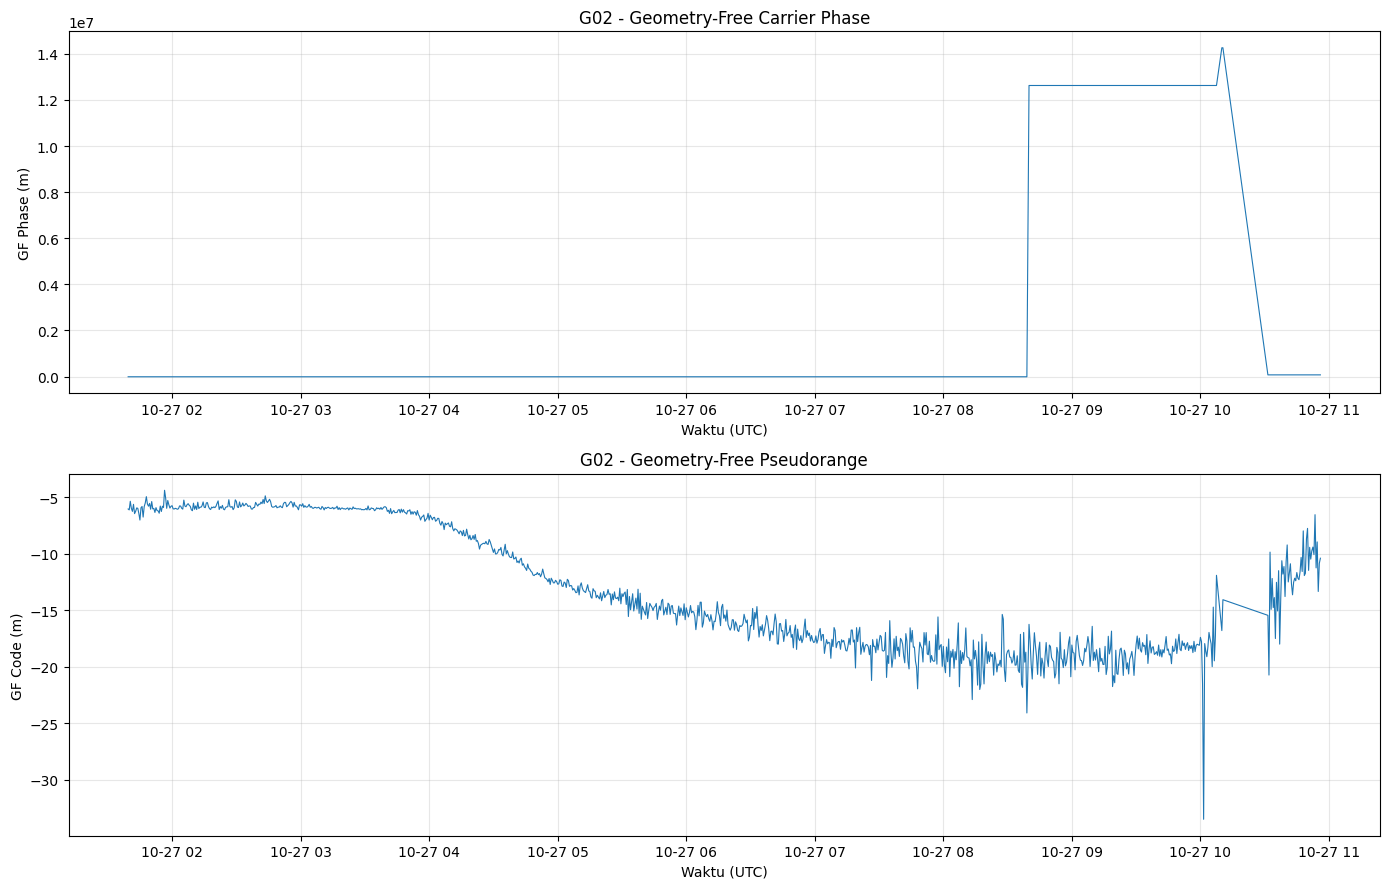

In [94]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Grafik pertama: GF fase
axes[0].plot(
    df_g02_qc["Waktu"],
    df_g02_qc["GF_m"],
    linewidth=0.8
)

axes[0].set_title("G02 - Geometry-Free Carrier Phase")
axes[0].set_ylabel("GF Phase (m)")
axes[0].set_xlabel("Waktu (UTC)")
axes[0].grid(True, alpha=0.3)

# Grafik kedua: GF pseudorange
axes[1].plot(
    df_g02_phase_code["Waktu"],
    df_g02_phase_code["GF_Code_m"],
    linewidth=0.8
)

axes[1].set_title("G02 - Geometry-Free Pseudorange")
axes[1].set_ylabel("GF Code (m)")
axes[1].set_xlabel("Waktu (UTC)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [95]:
# Hitung ulang Geometry-Free Carrier Phase
df_cek_g02 = df_g02_qc.copy()

df_cek_g02["GF_hitung_ulang_m"] = (
    lambda1 * df_cek_g02["L1_cycles"]
    - lambda2 * df_cek_g02["L2_cycles"]
)

df_cek_g02["Selisih_perhitungan_m"] = (
    df_cek_g02["GF_m"]
    - df_cek_g02["GF_hitung_ulang_m"]
)

print("Statistik GF_m yang tersimpan:")
display(df_cek_g02["GF_m"].describe())

print("\nStatistik GF hasil perhitungan ulang:")
display(df_cek_g02["GF_hitung_ulang_m"].describe())

print("\nPerbandingan beberapa baris data:")
display(
    df_cek_g02[
        [
            "Waktu",
            "L1_cycles",
            "L2_cycles",
            "GF_m",
            "GF_hitung_ulang_m",
            "Selisih_perhitungan_m",
            "Arc_ID"
        ]
    ].head(10)
)

Statistik GF_m yang tersimpan:


count    1.068000e+03
mean     2.102544e+06
std      4.718017e+06
min     -1.082297e+04
25%     -1.082097e+04
50%     -1.081310e+04
75%     -1.080865e+04
max      1.426378e+07
Name: GF_m, dtype: float64


Statistik GF hasil perhitungan ulang:


count    1.068000e+03
mean     2.102544e+06
std      4.718017e+06
min     -1.082297e+04
25%     -1.082097e+04
50%     -1.081310e+04
75%     -1.080865e+04
max      1.426378e+07
Name: GF_hitung_ulang_m, dtype: float64


Perbandingan beberapa baris data:


,Waktu,L1_cycles,L2_cycles,GF_m,GF_hitung_ulang_m,Selisih_perhitungan_m,Arc_ID
0,2003-10-27 01:39:30.009,-56865.120,0.603,-10821.219798,-10821.219798,0.0,1
1,2003-10-27 01:40:00.009,-85485.670,-22301.052,-10821.237447,-10821.237447,0.0,1
2,2003-10-27 01:40:30.009,-113906.558,-44447.094,-10821.262966,-10821.262966,0.0,1
3,2003-10-27 01:41:00.009,-142121.075,-66432.365,-10821.279309,-10821.279309,0.0,1
4,2003-10-27 01:41:30.009,-170131.485,-88258.544,-10821.307273,-10821.307273,0.0,1
5,2003-10-27 01:42:00.009,-197931.820,-109921.066,-10821.326004,-10821.326004,0.0,1
6,2003-10-27 01:42:30.009,-225521.107,-131419.110,-10821.350843,-10821.350843,0.0,1
7,2003-10-27 01:43:00.009,-252900.628,-152753.709,-10821.373479,-10821.373479,0.0,1
8,2003-10-27 01:43:30.009,-280063.066,-173919.138,-10821.399635,-10821.399635,0.0,1
9,2003-10-27 01:44:00.009,-307005.735,-194913.335,-10821.421744,-10821.421744,0.0,1


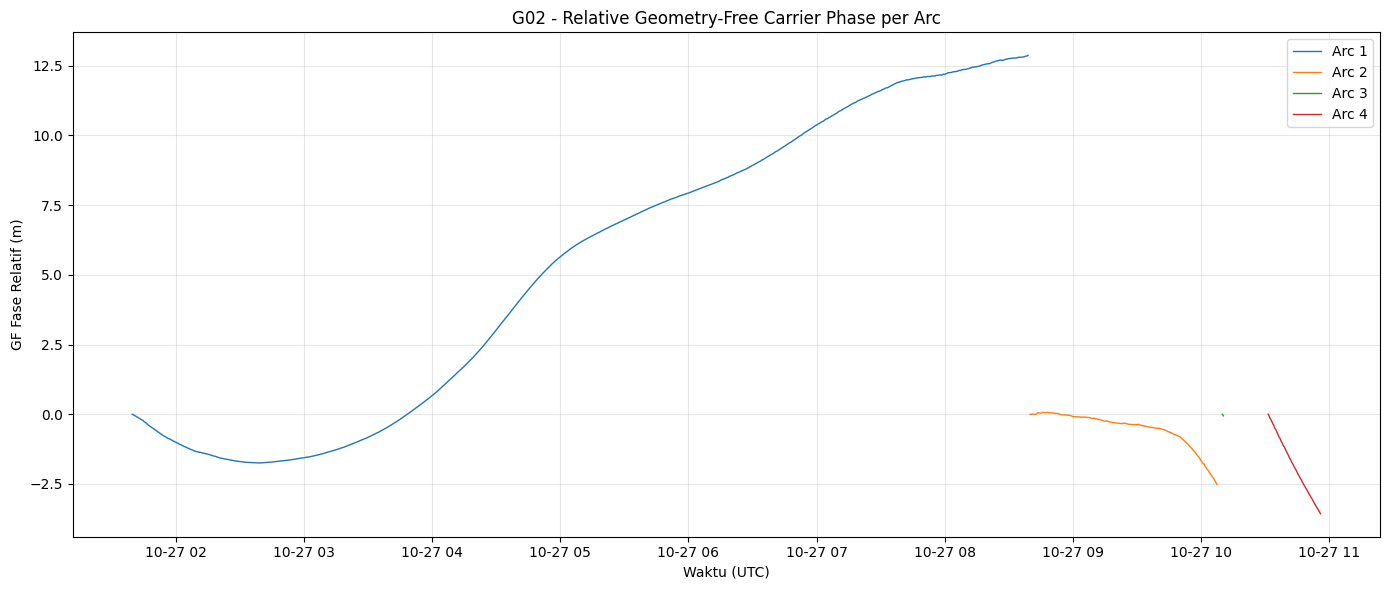

In [96]:
import matplotlib.pyplot as plt

df_g02_relatif = df_cek_g02.copy()

# Hitung GF fase relatif terhadap epoch pertama setiap arc
df_g02_relatif["GF_Relatif_m"] = (
    df_g02_relatif["GF_m"]
    - df_g02_relatif.groupby("Arc_ID")["GF_m"].transform("first")
)

# Plot setiap arc secara terpisah
plt.figure(figsize=(14, 6))

for arc_id, data in df_g02_relatif.groupby("Arc_ID"):
    plt.plot(
        data["Waktu"],
        data["GF_Relatif_m"],
        label=f"Arc {arc_id}",
        linewidth=1
    )

plt.title("G02 - Relative Geometry-Free Carrier Phase per Arc")
plt.xlabel("Waktu (UTC)")
plt.ylabel("GF Fase Relatif (m)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [97]:
# Statistik perubahan GF fase untuk setiap arc
df_g02_delta_stats = (
    df_g02_qc
    .groupby("Arc_ID")["Delta_GF_m"]
    .agg(
        Jumlah_Data="count",
        Rata_rata="mean",
        Median="median",
        Standar_Deviasi="std",
        Minimum="min",
        Maksimum="max"
    )
)

df_g02_delta_stats["Maksimum_Absolut"] = (
    df_g02_qc
    .groupby("Arc_ID")["Delta_GF_m"]
    .apply(lambda x: x.abs().max())
)

display(df_g02_delta_stats.round(6))

,Jumlah_Data,Rata_rata,Median,Standar_Deviasi,Minimum,Maksimum,Maksimum_Absolut
Arc_ID,,,,,,,
1,839,0.015349,0.017092,0.017338,-0.040108,0.051861,0.051861
2,175,-0.014386,-0.010552,0.021423,-0.101912,0.049311,0.101912
3,1,-0.058512,-0.058512,NaN,-0.058512,-0.058512,0.058512
4,49,-0.072881,-0.070640,0.013689,-0.105518,-0.050777,0.105518


In [98]:
# Mengambil 5 perubahan GF fase terbesar pada setiap arc
df_g02_outlier = df_g02_qc.copy()

df_g02_outlier["Abs_Delta_GF_m"] = (
    df_g02_outlier["Delta_GF_m"].abs()
)

df_g02_top5 = (
    df_g02_outlier
    .dropna(subset=["Delta_GF_m"])
    .sort_values(
        ["Arc_ID", "Abs_Delta_GF_m"],
        ascending=[True, False]
    )
    .groupby("Arc_ID")
    .head(5)
    .sort_values(["Arc_ID", "Waktu"])
)

display(
    df_g02_top5[
        [
            "Arc_ID",
            "Waktu",
            "Delta_GF_m",
            "Abs_Delta_GF_m",
            "LLI_L1",
            "LLI_L2",
            "SSI_L1",
            "SSI_L2"
        ]
    ].round(6)
)

C:\Users\ACER\AppData\Local\Temp\ipykernel_15144\2499589243.py:32: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(6)


,Arc_ID,Waktu,Delta_GF_m,Abs_Delta_GF_m,LLI_L1,LLI_L2,SSI_L1,SSI_L2
340,1,2003-10-27 04:29:30.024,0.050412,0.050412,4.0,4.0,6.0,6.0
342,1,2003-10-27 04:30:30.024,0.051306,0.051306,4.0,4.0,6.0,6.0
355,1,2003-10-27 04:37:00.025,0.050634,0.050634,4.0,4.0,6.0,6.0
358,1,2003-10-27 04:38:30.024,0.051861,0.051861,4.0,4.0,6.0,6.0
360,1,2003-10-27 04:39:30.024,0.051363,0.051363,4.0,4.0,6.0,6.0
1002,2,2003-10-27 10:01:00.053,-0.072806,0.072806,4.0,4.0,5.0,2.0
1004,2,2003-10-27 10:02:00.054,-0.101912,0.101912,4.0,4.0,4.0,2.0
1008,2,2003-10-27 10:04:00.054,-0.069876,0.069876,4.0,4.0,2.0,2.0
1013,2,2003-10-27 10:06:30.053,-0.071550,0.071550,4.0,4.0,2.0,1.0
1014,2,2003-10-27 10:07:00.054,-0.078296,0.078296,4.0,4.0,2.0,1.0


In [2]:
# MEMUAT ULANG DATA RINEX DOY300

import georinex as gr
import pandas as pd
import numpy as np
from pathlib import Path

# Lokasi file RINEX
rinex_path = Path.cwd() / "bako3000.03o"

# Membaca data observasi
obs = gr.load(str(rinex_path))

# Mengambil data observasi L1 dan L2
data_l1 = obs["L1"].values
data_l2 = obs["L2"].values

# Mengambil daftar satelit dan waktu observasi
daftar_sv = obs.sv.values
waktu = pd.DatetimeIndex(obs.time.values)

print("Data berhasil dimuat.")
print("Jumlah epoch:", len(waktu))
print("Jumlah satelit:", len(daftar_sv))
print("Satelit tersedia:", daftar_sv)

Data berhasil dimuat.
Jumlah epoch: 2878
Jumlah satelit: 28
Satelit tersedia: ['G01' 'G02' 'G03' 'G04' 'G05' 'G06' 'G07' 'G08' 'G09' 'G10' 'G11' 'G13'
 'G14' 'G15' 'G16' 'G17' 'G18' 'G20' 'G21' 'G23' 'G24' 'G25' 'G26' 'G27'
 'G28' 'G29' 'G30' 'G31']


c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'time' ('time',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))
c:\Users\ACER\AppData\Local\Programs\Python\Python313\Lib\site-packages\georinex\obs2.py:58: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'sv' ('sv',) The recommendation is to set join explicitly for this case.
  obs = xarray.merge((obs, o))


In [3]:
# INVENTARISASI OBSERVASI G04

# Mencari indeks satelit G04
indeks_g04 = [
    i for i, sv in enumerate(daftar_sv)
    if str(sv).strip() == "G04"
][0]

# Mengambil data L1 dan L2
l1_g04 = data_l1[:, indeks_g04]
l2_g04 = data_l2[:, indeks_g04]

# Menentukan epoch dengan pasangan observasi L1 dan L2 valid
valid_pair_g04 = (
    np.isfinite(l1_g04) &
    np.isfinite(l2_g04)
)

# Membuat DataFrame observasi G04
df_g04 = pd.DataFrame({
    "Waktu": waktu[valid_pair_g04],
    "L1_cycles": l1_g04[valid_pair_g04],
    "L2_cycles": l2_g04[valid_pair_g04]
})

df_g04 = df_g04.sort_values("Waktu").reset_index(drop=True)

# Menghitung interval antarobservasi
df_g04["Interval_detik"] = (
    df_g04["Waktu"].diff().dt.total_seconds()
)

# Menandai gap dengan interval lebih dari 30,5 detik
df_g04["Gap"] = df_g04["Interval_detik"] > 30.5

print("Jumlah pasangan L1-L2 valid:", len(df_g04))
print("Jumlah gap:", df_g04["Gap"].sum())
print("Waktu observasi pertama:", df_g04["Waktu"].min())
print("Waktu observasi terakhir:", df_g04["Waktu"].max())

display(df_g04["Interval_detik"].describe())

display(
    df_g04.loc[
        df_g04["Gap"],
        ["Waktu", "Interval_detik"]
    ]
)

Jumlah pasangan L1-L2 valid: 939
Jumlah gap: 13
Waktu observasi pertama: 2003-10-27 09:57:00.053000
Waktu observasi terakhir: 2003-10-27 19:39:00.105000


count     938.00000
mean       37.22820
std       141.04518
min        29.99900
25%        30.00000
50%        30.00000
75%        30.00100
max      4110.00500
Name: Interval_detik, dtype: float64

,Waktu,Interval_detik
731,2003-10-27 17:10:30.091,4110.005
736,2003-10-27 17:16:00.092,210.001
738,2003-10-27 17:20:00.093,210.002
741,2003-10-27 17:22:30.092,89.999
744,2003-10-27 17:25:30.092,120.000
764,2003-10-27 17:36:30.094,90.000
770,2003-10-27 17:41:00.095,120.001
777,2003-10-27 17:49:30.094,329.999
781,2003-10-27 17:54:00.096,180.001
835,2003-10-27 18:22:30.097,120.000


In [4]:
# PEMBENTUKAN ARC SEMENTARA G04

# Setiap gap menjadi batas arc baru
df_g04["Arc_ID"] = df_g04["Gap"].cumsum() + 1

# Membuat ringkasan setiap arc
ringkasan_arc_g04 = []

for arc_id, grup in df_g04.groupby("Arc_ID"):

    waktu_awal = grup["Waktu"].iloc[0]
    waktu_akhir = grup["Waktu"].iloc[-1]

    jumlah_epoch = len(grup)

    durasi_menit = (
        waktu_akhir - waktu_awal
    ).total_seconds() / 60

    ringkasan_arc_g04.append({
        "Arc_ID": arc_id,
        "Waktu_Awal": waktu_awal,
        "Waktu_Akhir": waktu_akhir,
        "Jumlah_Epoch": jumlah_epoch,
        "Durasi_Menit": round(durasi_menit, 2)
    })

df_arc_g04 = pd.DataFrame(ringkasan_arc_g04)

print("Jumlah arc sementara:", len(df_arc_g04))
print("Total epoch:", df_arc_g04["Jumlah_Epoch"].sum())

display(df_arc_g04)

Jumlah arc sementara: 14
Total epoch: 939


,Arc_ID,Waktu_Awal,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit
0,1,2003-10-27 09:57:00.053,2003-10-27 16:02:00.086,731,365.0
1,2,2003-10-27 17:10:30.091,2003-10-27 17:12:30.091,5,2.0
2,3,2003-10-27 17:16:00.092,2003-10-27 17:16:30.091,2,0.5
3,4,2003-10-27 17:20:00.093,2003-10-27 17:21:00.093,3,1.0
4,5,2003-10-27 17:22:30.092,2003-10-27 17:23:30.092,3,1.0
5,6,2003-10-27 17:25:30.092,2003-10-27 17:35:00.094,20,9.5
6,7,2003-10-27 17:36:30.094,2003-10-27 17:39:00.094,6,2.5
7,8,2003-10-27 17:41:00.095,2003-10-27 17:44:00.095,7,3.0
8,9,2003-10-27 17:49:30.094,2003-10-27 17:51:00.095,4,1.5
9,10,2003-10-27 17:54:00.096,2003-10-27 18:20:30.097,54,26.5


In [5]:
# SCREENING PANJANG ARC G04

def klasifikasi_arc(jumlah_epoch):
    if jumlah_epoch == 1:
        return "Tidak memadai"
    elif jumlah_epoch <= 9:
        return "Sangat pendek"
    elif jumlah_epoch <= 29:
        return "Pendek"
    else:
        return "Kandidat analisis"

df_arc_g04["Kategori"] = (
    df_arc_g04["Jumlah_Epoch"].apply(klasifikasi_arc)
)

print("Distribusi kategori arc G04:")
display(
    df_arc_g04["Kategori"]
    .value_counts()
    .rename_axis("Kategori")
    .reset_index(name="Jumlah_Arc")
)

print("Tabel klasifikasi lengkap:")
display(df_arc_g04)

Distribusi kategori arc G04:


,Kategori,Jumlah_Arc
0,Sangat pendek,8
1,Kandidat analisis,3
2,Pendek,2
3,Tidak memadai,1


Tabel klasifikasi lengkap:


,Arc_ID,Waktu_Awal,Waktu_Akhir,Jumlah_Epoch,Durasi_Menit,Kategori
0,1,2003-10-27 09:57:00.053,2003-10-27 16:02:00.086,731,365.0,Kandidat analisis
1,2,2003-10-27 17:10:30.091,2003-10-27 17:12:30.091,5,2.0,Sangat pendek
2,3,2003-10-27 17:16:00.092,2003-10-27 17:16:30.091,2,0.5,Sangat pendek
3,4,2003-10-27 17:20:00.093,2003-10-27 17:21:00.093,3,1.0,Sangat pendek
4,5,2003-10-27 17:22:30.092,2003-10-27 17:23:30.092,3,1.0,Sangat pendek
5,6,2003-10-27 17:25:30.092,2003-10-27 17:35:00.094,20,9.5,Pendek
6,7,2003-10-27 17:36:30.094,2003-10-27 17:39:00.094,6,2.5,Sangat pendek
7,8,2003-10-27 17:41:00.095,2003-10-27 17:44:00.095,7,3.0,Sangat pendek
8,9,2003-10-27 17:49:30.094,2003-10-27 17:51:00.095,4,1.5,Sangat pendek
9,10,2003-10-27 17:54:00.096,2003-10-27 18:20:30.097,54,26.5,Kandidat analisis


In [6]:
# EKSTRAKSI LLI DAN SSI G04 DARI RINEX

with open(rinex_path, "r", errors="ignore") as f:
    baris_rinex = f.readlines()

data_lli_g04 = []
i = 0

while i < len(baris_rinex):

    line = baris_rinex[i]

    try:
        # Membaca informasi epoch
        yy = int(line[1:3])
        bulan = int(line[4:6])
        hari = int(line[7:9])
        jam = int(line[10:12])
        menit = int(line[13:15])
        detik = float(line[15:26])

        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

    except (ValueError, IndexError):
        i += 1
        continue

    # Konversi tahun dua digit menjadi tahun empat digit
    tahun = 2000 + yy if yy < 80 else 1900 + yy

    waktu_epoch = (
        pd.Timestamp(
            year=tahun,
            month=bulan,
            day=hari,
            hour=jam,
            minute=menit
        )
        + pd.to_timedelta(detik, unit="s")
    )

    # Membaca daftar satelit pada header epoch
    daftar_sat_epoch = [
        line[pos:pos+3].strip()
        for pos in range(32, 32 + jumlah_sv * 3, 3)
    ]

    # Epoch observasi normal atau power failure
    if flag in [0, 1]:

        for sat in daftar_sat_epoch:

            # Setiap satelit memiliki 2 baris observasi
            baris_obs = baris_rinex[i + 1:i + 3]

            if sat == "G04" and len(baris_obs) >= 1:

                baris_l1_l2 = baris_obs[0]

                # Field observasi L1 dan L2
                field_l1 = baris_l1_l2[0:16]
                field_l2 = baris_l1_l2[16:32]

                # Mengambil karakter LLI dan SSI
                lli_l1 = field_l1[14].strip() if len(field_l1) > 14 else ""
                ssi_l1 = field_l1[15].strip() if len(field_l1) > 15 else ""

                lli_l2 = field_l2[14].strip() if len(field_l2) > 14 else ""
                ssi_l2 = field_l2[15].strip() if len(field_l2) > 15 else ""

                data_lli_g04.append({
                    "Waktu": waktu_epoch,
                    "LLI_L1": lli_l1,
                    "SSI_L1": ssi_l1,
                    "LLI_L2": lli_l2,
                    "SSI_L2": ssi_l2
                })

            # Lewati dua baris observasi setiap satelit
            i += 2

    else:
        # Epoch khusus: lewati sejumlah baris sesuai jumlah record
        i += jumlah_sv

    i += 1


# Membuat DataFrame LLI
df_lli_g04 = pd.DataFrame(data_lli_g04)

print("Jumlah record LLI G04:", len(df_lli_g04))

display(df_lli_g04.head())
display(df_lli_g04.tail())

Jumlah record LLI G04: 0


""


""


In [7]:
# PEMERIKSAAN STRUKTUR RINEX 2.10

# Mencari akhir header
indeks_header = next(
    i for i, line in enumerate(baris_rinex)
    if "END OF HEADER" in line
)

print("Indeks akhir header:", indeks_header)
print("\nBaris pertama setelah header:")

for j in range(indeks_header + 1, indeks_header + 9):
    print(f"Baris {j}: {repr(baris_rinex[j])}")

Indeks akhir header: 17

Baris pertama setelah header:
Baris 18: ' 03 10 27  0  0 30.0000000  0  9G21G 6G 5G25G15G18G30G14G23\n'
Baris 19: '   7272414.07557   5719375.47357  20659955.1484   20659955.7704\n'
Baris 20: '     -3921.0944\n'
Baris 21: '  35449963.44555   2632699.29255  23215464.2584   23215469.9774\n'
Baris 22: '     -3146.2974\n'
Baris 23: '  56683781.12656  17932985.92856  22960277.9694   22960283.2304\n'
Baris 24: '     -3966.5624\n'
Baris 25: '   1091063.23856    872713.18356  22358403.5784   22358406.5554\n'


In [8]:
# DIAGNOSTIK FORMAT EPOCH YANG MEMUAT G04

baris_epoch_g04 = []

for nomor, line in enumerate(baris_rinex):
    if "G04" in line or "G 4" in line:
        baris_epoch_g04.append((nomor, line))

print("Jumlah baris yang memuat identitas G04:", len(baris_epoch_g04))

for nomor, line in baris_epoch_g04[:5]:
    print("\nNomor baris:", nomor)
    print("Isi:", repr(line))
    print("Tahun:", repr(line[1:3]))
    print("Bulan:", repr(line[4:6]))
    print("Hari:", repr(line[7:9]))
    print("Jam:", repr(line[10:12]))
    print("Menit:", repr(line[13:15]))
    print("Detik:", repr(line[15:26]))
    print("Flag:", repr(line[28:29]))
    print("Jumlah SV:", repr(line[29:32]))
    print("Daftar SV:", repr(line[32:]))

Jumlah baris yang memuat identitas G04: 1004

Nomor baris: 21415
Isi: ' 03 10 27  9 56  0.0530000  0  9G27G 4G 2G 8G11G20G 7G13G 1\n'
Tahun: '03'
Bulan: '10'
Hari: '27'
Jam: ' 9'
Menit: '56'
Detik: '  0.0530000'
Flag: '0'
Jumlah SV: '  9'
Daftar SV: 'G27G 4G 2G 8G11G20G 7G13G 1\n'

Nomor baris: 21434
Isi: ' 03 10 27  9 56 30.0530000  0  9G27G 4G 2G 8G11G20G 7G13G 1\n'
Tahun: '03'
Bulan: '10'
Hari: '27'
Jam: ' 9'
Menit: '56'
Detik: ' 30.0530000'
Flag: '0'
Jumlah SV: '  9'
Daftar SV: 'G27G 4G 2G 8G11G20G 7G13G 1\n'

Nomor baris: 21453
Isi: ' 03 10 27  9 57  0.0530000  0  9G27G 4G 2G 8G11G20G 7G13G 1\n'
Tahun: '03'
Bulan: '10'
Hari: '27'
Jam: ' 9'
Menit: '57'
Detik: '  0.0530000'
Flag: '0'
Jumlah SV: '  9'
Daftar SV: 'G27G 4G 2G 8G11G20G 7G13G 1\n'

Nomor baris: 21472
Isi: ' 03 10 27  9 57 30.0530000  0  9G27G 4G 2G 8G11G20G 7G13G 1\n'
Tahun: '03'
Bulan: '10'
Hari: '27'
Jam: ' 9'
Menit: '57'
Detik: ' 30.0530000'
Flag: '0'
Jumlah SV: '  9'
Daftar SV: 'G27G 4G 2G 8G11G20G 7G13G 1\n'

Nomor 

In [9]:
# EKSTRAKSI LLI DAN SSI G04 - PARSER RINEX 2

def normalisasi_sat(sat):
    sat = sat.strip()
    if len(sat) == 3 and sat[0] == "G":
        return "G" + sat[1:].strip().zfill(2)
    return sat


def ambil_daftar_sat(line):
    bagian = line[32:68]
    return [
        bagian[pos:pos+3]
        for pos in range(0, len(bagian), 3)
        if bagian[pos:pos+3].strip()
    ]


data_lli_g04 = []

i = indeks_header + 1

while i < len(baris_rinex):

    line = baris_rinex[i]

    try:
        yy = int(line[1:3])
        bulan = int(line[4:6])
        hari = int(line[7:9])
        jam = int(line[10:12])
        menit = int(line[13:15])
        detik = float(line[15:26])
        flag = int(line[28:29])
        jumlah_sv = int(line[29:32])

    except (ValueError, IndexError):
        i += 1
        continue

    tahun = 2000 + yy if yy < 80 else 1900 + yy

    waktu_epoch = (
        pd.Timestamp(
            year=tahun,
            month=bulan,
            day=hari,
            hour=jam,
            minute=menit
        )
        + pd.to_timedelta(detik, unit="s")
    )

    if flag in [0, 1]:

        daftar_sat = ambil_daftar_sat(line)
        posisi_obs = i + 1

        # Membaca baris lanjutan daftar satelit jika diperlukan
        while len(daftar_sat) < jumlah_sv:
            daftar_sat += ambil_daftar_sat(
                baris_rinex[posisi_obs]
            )
            posisi_obs += 1

        # Membaca dua baris observasi setiap satelit
        for nomor_sat, sat in enumerate(daftar_sat[:jumlah_sv]):

            baris_obs = posisi_obs + 2 * nomor_sat
            baris_l1_l2 = baris_rinex[baris_obs]

            if normalisasi_sat(sat) == "G04":

                field_l1 = baris_l1_l2[0:16]
                field_l2 = baris_l1_l2[16:32]

                lli_l1 = field_l1[14:15].strip()
                ssi_l1 = field_l1[15:16].strip()

                lli_l2 = field_l2[14:15].strip()
                ssi_l2 = field_l2[15:16].strip()

                data_lli_g04.append({
                    "Waktu": waktu_epoch,
                    "LLI_L1": lli_l1,
                    "SSI_L1": ssi_l1,
                    "LLI_L2": lli_l2,
                    "SSI_L2": ssi_l2
                })

        i = posisi_obs + 2 * jumlah_sv

    elif flag == 6:
        # Flag 6: catatan cycle slip
        i += 1 + 2 * jumlah_sv

    else:
        # Flag 2–5: catatan kejadian khusus
        i += 1 + jumlah_sv


# Membuat DataFrame
df_lli_g04 = pd.DataFrame(data_lli_g04)

print("Jumlah record LLI G04:", len(df_lli_g04))
print("Jumlah waktu unik:", df_lli_g04["Waktu"].nunique())

display(df_lli_g04.head(10))
display(df_lli_g04.tail(10))

Jumlah record LLI G04: 1004
Jumlah waktu unik: 1004


,Waktu,LLI_L1,SSI_L1,LLI_L2,SSI_L2
0,2003-10-27 09:56:00.053,5,2,,
1,2003-10-27 09:56:30.053,4,1,,
2,2003-10-27 09:57:00.053,4,2,5,2
3,2003-10-27 09:57:30.053,4,1,4,2
4,2003-10-27 09:58:00.053,4,3,4,2
5,2003-10-27 09:58:30.053,4,3,4,2
6,2003-10-27 09:59:00.053,4,4,4,3
7,2003-10-27 09:59:30.053,4,5,4,3
8,2003-10-27 10:00:00.053,4,3,4,2
9,2003-10-27 10:00:30.053,4,3,4,2


,Waktu,LLI_L1,SSI_L1,LLI_L2,SSI_L2
994,2003-10-27 19:34:30.105,4,3,4,3
995,2003-10-27 19:35:00.105,4,3,4,3
996,2003-10-27 19:35:30.105,4,3,4,2
997,2003-10-27 19:36:00.105,4,4,4,3
998,2003-10-27 19:36:30.105,4,4,4,3
999,2003-10-27 19:37:00.105,4,3,4,2
1000,2003-10-27 19:37:30.105,4,4,4,3
1001,2003-10-27 19:38:00.105,4,3,4,2
1002,2003-10-27 19:38:30.105,4,2,4,2
1003,2003-10-27 19:39:00.105,4,4,4,2


In [10]:
# PENGGABUNGAN DATA LLI DENGAN OBSERVASI FASE G04

# Mengurutkan kedua DataFrame berdasarkan waktu
df_g04_sorted = df_g04.sort_values("Waktu").copy()
df_lli_g04_sorted = df_lli_g04.sort_values("Waktu").copy()

# Mencocokkan waktu dengan toleransi 10 milidetik
df_g04_lli = pd.merge_asof(
    df_g04_sorted,
    df_lli_g04_sorted,
    on="Waktu",
    direction="nearest",
    tolerance=pd.Timedelta(milliseconds=10)
)

# Mengubah kolom LLI menjadi numerik
for kolom in ["LLI_L1", "LLI_L2"]:
    df_g04_lli[kolom] = pd.to_numeric(
        df_g04_lli[kolom],
        errors="coerce"
    )

# Memeriksa bit 0 pada LLI
df_g04_lli["Bit0_L1"] = (
    df_g04_lli["LLI_L1"].fillna(0).astype(int) & 1
)

df_g04_lli["Bit0_L2"] = (
    df_g04_lli["LLI_L2"].fillna(0).astype(int) & 1
)

# Ringkasan pencocokan
print("Jumlah pasangan L1-L2:", len(df_g04_lli))
print(
    "Jumlah LLI yang berhasil dicocokkan:",
    df_g04_lli["LLI_L1"].notna().sum()
)

print("\nDistribusi nilai LLI L1:")
display(df_g04_lli["LLI_L1"].value_counts(dropna=False).sort_index())

print("\nDistribusi nilai LLI L2:")
display(df_g04_lli["LLI_L2"].value_counts(dropna=False).sort_index())

# Menampilkan seluruh epoch dengan bit 0 aktif
df_bit0_g04 = df_g04_lli[
    (df_g04_lli["Bit0_L1"] == 1) |
    (df_g04_lli["Bit0_L2"] == 1)
].copy()

print("\nJumlah epoch dengan LLI bit 0 aktif:", len(df_bit0_g04))

display(
    df_bit0_g04[
        [
            "Waktu",
            "Arc_ID",
            "LLI_L1",
            "SSI_L1",
            "LLI_L2",
            "SSI_L2",
            "Bit0_L1",
            "Bit0_L2"
        ]
    ]
)

Jumlah pasangan L1-L2: 939
Jumlah LLI yang berhasil dicocokkan: 939

Distribusi nilai LLI L1:


LLI_L1
4    939
Name: count, dtype: int64


Distribusi nilai LLI L2:


LLI_L2
4    925
5     14
Name: count, dtype: int64


Jumlah epoch dengan LLI bit 0 aktif: 14


,Waktu,Arc_ID,LLI_L1,SSI_L1,LLI_L2,SSI_L2,Bit0_L1,Bit0_L2
0,2003-10-27 09:57:00.053,1,4,2,5,2,0,1
731,2003-10-27 17:10:30.091,2,4,2,5,1,0,1
736,2003-10-27 17:16:00.092,3,4,1,5,1,0,1
738,2003-10-27 17:20:00.093,4,4,2,5,1,0,1
741,2003-10-27 17:22:30.092,5,4,3,5,1,0,1
744,2003-10-27 17:25:30.092,6,4,1,5,1,0,1
764,2003-10-27 17:36:30.094,7,4,2,5,1,0,1
770,2003-10-27 17:41:00.095,8,4,2,5,1,0,1
777,2003-10-27 17:49:30.094,9,4,3,5,2,0,1
781,2003-10-27 17:54:00.096,10,4,3,5,1,0,1
